<a href="https://colab.research.google.com/github/ictnsofu/ICD_5211_Data_Privacy_kampamba_nsofu_202609988/blob/main/202609988_Kampamba_Nsofu_ICD_5211_CLEANED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# ICD 5211 – BIG DATA MANAGEMENT AND PROCESSING

## Individual Assessment: MosiPay's Cross-Border Analytics Challenge

### Q1: Architecting the Privacy-Preserving Host-Data Platform

**Student:** Kampamba Nsofu  
**Programme:** Master of Science in Data Science and Big Data  
**Institution:** Mulungushi University  
**Assessment Period:** 15–18 November 2026  
**Assessment:** Individual Case-Study-Based Google Colab Laboratory

---

# 01 – INTRODUCTION

## 1.1 Assessment Objectives

This laboratory investigates the design of a privacy-preserving data platform for MosiPay, a fictional regional payment-switch analytics provider. The assessment focuses on the responsible management, processing, analysis and controlled disclosure of transaction-host data.

The principal objective is to develop and evaluate an architecture that supports legitimate internal analytical reporting while minimising the exposure of sensitive transaction and account-related information.

The laboratory addresses the following objectives:

1. Profile the supplied transaction-host dataset to establish its structure, data quality, physical characteristics and potential privacy risks.
2. Design a purpose-limited data architecture covering ingestion, quarantine, Bronze, Silver and Gold processing layers, controlled statistical release and data deletion.
3. Develop an executable data contract specifying field-level classifications, validation requirements, permitted purposes, access roles and retention categories.
4. Demonstrate data validation, access restrictions, quarantine decisions and security controls through executable tests.
5. Examine the risks associated with direct identifiers, indirect identifiers, account-level linkage and external information.
6. Document architectural decisions, threats, residual risks and the trade-offs between analytical utility and privacy protection.

## 1.2 Case-Study Background

MosiPay is presented as a regional payment-switch analytics provider working with a South African card-transactions partner. Its Zambian analytics team has been tasked with developing merchant-channel service reports, historical transaction-quality indicators and privacy-preserving statistical summaries.

Management has proposed uploading all 149 fields from the supplied host-data extract into a common analytics lake and distributing filtered CSV files to partner institutions.

This proposal creates potential risks because the source data may contain direct identifiers, account references, transaction-level attributes and contextual information that could be linked with external observations.

The proposed solution therefore separates restricted source-data processing from ordinary analytical access and external statistical disclosure.

The architecture will preserve source-to-derived lineage, enforce role-based access, minimise data collection and exposure, and subject external outputs to privacy and disclosure-risk assessment.

## 1.3 Scope and Assumptions

The investigation uses the supplied synthetic transaction-host dataset, identified as:

`Synthetic_TymeBank_Host_Data_500_Rows.csv`

The assessment describes the dataset as containing 500 records and 149 fields. These dimensions will be independently verified during the data-profiling stage.

The following assumptions and limitations govern the investigation:

1. The dataset is synthetic and is used exclusively for academic experimentation.
2. Field names and observed values do not automatically establish authoritative business meanings.
3. Transaction references, masked card references and account-related fields are not assumed to identify distinct individuals.
4. Currency, amount units, timestamp conventions and status-code meanings will not be inferred without supporting documentation.
5. Security experiments will be conducted locally in the Colab environment using simulated identities and fictional data.
6. AWS and Azure services will be discussed as proposed architectural implementation options. Their inclusion does not imply that either platform has been deployed.
7. Privacy claims will be supported by explicit assumptions, executable tests and documented limitations.
8. The original source file will remain unchanged. All transformations and derived datasets will be stored separately.
9. Raw identifiers, account references and other restricted values will not be included in published evidence or external statistical outputs.

## 1.4 Methodological Approach

The laboratory follows a structured data-engineering and privacy-engineering approach.

The investigation proceeds through data profiling, architectural design, data-contract development, validation and quarantine testing, threat assessment, and the documentation of architectural decisions.

Each technically meaningful experiment will include positive tests demonstrating expected behaviour and negative or adversarial tests examining whether inappropriate behaviour is prevented.

The resulting notebook will provide reproducible evidence of the implemented experiments. Successful execution will not, by itself, be treated as proof of complete confidentiality, anonymity or differential privacy.

## 1.5 Notebook Execution Environment

Google Colab with Python will provide the computational environment. The notebook will be designed for execution from the first cell to the final cell without reliance on manually created variables or previous execution sessions.

The original dataset will be read without modification. Intermediate and derived outputs will be written to a separate working directory.

The notebook will document its software dependencies, input-file requirements and execution assumptions to support reproducibility.


## 1.6 Clean-Run Execution Contract

Run the notebook from the first cell in a fresh Google Colab runtime. At the single source-ingestion prompt, upload the supplied file using its exact filename: `Synthetic_TymeBank_Host_Data_500_Rows.csv`. The notebook creates all derived datasets and assessment evidence in `/content/mosipay_q1/output`. Do not upload previous output folders or restore old evidence archives during the main run. Optional download actions are documented separately and are not part of Run all.


In [1]:

# ============================================================
# 02 – ENVIRONMENT SETUP
# ICD 5211: MosiPay Privacy-Preserving Host-Data Platform
# ============================================================

import sys
import os
import json
import platform
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
import numpy as np

# Reproducibility settings
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Working directories
BASE_DIR = Path("/content/mosipay_q1")
INPUT_DIR = BASE_DIR / "input"
OUTPUT_DIR = BASE_DIR / "output"
QUARANTINE_DIR = OUTPUT_DIR / "quarantine"
EVIDENCE_DIR = OUTPUT_DIR / "evidence"

# Create working directories
for directory in [
    INPUT_DIR,
    OUTPUT_DIR,
    QUARANTINE_DIR,
    EVIDENCE_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

# Environment information
environment = {
    "python_version": sys.version,
    "platform": platform.platform(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "random_seed": RANDOM_SEED,
    "execution_time_utc": datetime.now(timezone.utc).isoformat()
}

print("MOSIPAY Q1 ENVIRONMENT INITIALISED")
print("=" * 55)
print(json.dumps(environment, indent=4))
print("\nWorking directory:", BASE_DIR)
print("Input directory:", INPUT_DIR)
print("Output directory:", OUTPUT_DIR)

MOSIPAY Q1 ENVIRONMENT INITIALISED
{
    "python_version": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
    "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
    "pandas_version": "2.2.3",
    "numpy_version": "2.4.6",
    "random_seed": 42,
    "execution_time_utc": "2026-11-23T14:04:59.121525+00:00"
}

Working directory: /content/mosipay_q1
Input directory: /content/mosipay_q1/input
Output directory: /content/mosipay_q1/output



# 03 – DATA INGESTION AND SOURCE INTEGRITY

## 3.1 Objective

This section establishes a controlled and reproducible process for loading the supplied transaction-host dataset.

The original CSV is treated as read-only source evidence. Its integrity is verified through a SHA-256 cryptographic hash, while all subsequent processing is performed using a separate in-memory DataFrame and derived output files.

The source file will not be overwritten, modified or silently cleaned during ingestion.

## 3.2 Source File Requirements

The expected source file is:

`Synthetic_TymeBank_Host_Data_500_Rows.csv`

The ingestion process will:

1. Confirm that the source file exists.
2. Calculate its SHA-256 fingerprint.
3. Load the dataset without modifying the source.
4. Record the actual number of records and columns.
5. Display the column names and physical data types.
6. Compare the observed dimensions with the assessment's stated dimensions.


In [2]:

# ============================================================
# 03 – DATA INGESTION AND SOURCE INTEGRITY
# ============================================================

from google.colab import files

# Upload the original CSV once. The filename is validated so that later
# questions can reload the same canonical source without another upload.
EXPECTED_SOURCE_NAME = "Synthetic_TymeBank_Host_Data_500_Rows.csv"
print(f"Please upload exactly: {EXPECTED_SOURCE_NAME}")

uploaded = files.upload()

csv_files = [
    filename for filename in uploaded.keys()
    if filename.lower().endswith(".csv")
]

if len(csv_files) != 1:
    raise ValueError(
        f"Expected exactly one CSV file, but received {len(csv_files)}."
    )

source_filename = csv_files[0]
if source_filename != EXPECTED_SOURCE_NAME:
    raise ValueError(
        f"Incorrect source filename: {source_filename!r}. "
        f"Please upload {EXPECTED_SOURCE_NAME!r}."
    )

source_path = INPUT_DIR / EXPECTED_SOURCE_NAME
source_path.write_bytes(uploaded[source_filename])

# Calculate SHA-256 fingerprint
def calculate_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

source_hash_before = calculate_sha256(source_path)

# Load source data as strings to preserve identifier formatting
df = pd.read_csv(
    source_path,
    dtype="string",
    keep_default_na=True,
    low_memory=False
)

# Record source metadata
source_metadata = {
    "filename": source_filename,
    "sha256": source_hash_before,
    "file_size_bytes": source_path.stat().st_size,
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),
    "loaded_at_utc": datetime.now(timezone.utc).isoformat()
}

print("\nSOURCE INGESTION REPORT")
print("=" * 55)
print(json.dumps(source_metadata, indent=4))

print("\nDIMENSION CHECK")
print("Expected dimensions: 500 rows × 149 columns")
print("Observed dimensions:", df.shape)

print("\nSOURCE COLUMN NAMES")
print(df.columns.tolist())

print("\nPHYSICAL DATA TYPES")
print(df.dtypes.to_string())

# Verify the original file has not changed
source_hash_after = calculate_sha256(source_path)

assert source_hash_before == source_hash_after, (
    "Source file integrity check failed."
)

print("\nSource integrity verification: PASSED")

Please upload exactly: Synthetic_TymeBank_Host_Data_500_Rows.csv


Saving Synthetic_TymeBank_Host_Data_500_Rows.csv to Synthetic_TymeBank_Host_Data_500_Rows.csv

SOURCE INGESTION REPORT
{
    "filename": "Synthetic_TymeBank_Host_Data_500_Rows.csv",
    "sha256": "3db5ef0eecb1a4d8cd163c47d7858815778a9d8c094ffffbf7bbe93984161ed3",
    "file_size_bytes": 307047,
    "rows": 500,
    "columns": 149,
    "loaded_at_utc": "2026-11-23T14:05:22.163857+00:00"
}

DIMENSION CHECK
Expected dimensions: 500 rows × 149 columns
Observed dimensions: (500, 149)

SOURCE COLUMN NAMES
['HPAN', 'ACCT1', 'ACCT1TP', 'ACCT2', 'ACCT2TP', 'ACCT2_CURRENCY', 'ACCTBAL', 'ACCTBAL2', 'ACQINSTCC', 'ACQINSTID', 'ACQ_INST', 'ACQ_SCHM', 'ACTAMT', 'ADDLAMT', 'ADDLDATA', 'ADDRESP', 'ADDRESS_CITY', 'ADDRESS_COUNTRY', 'ADDRESS_NAME', 'ADDRESS_POSTAL_CODE', 'ADDRESS_STATE', 'ADDRESS_STREET', 'ATMID', 'ATM_RPT_DATE', 'AUTHIDRESP', 'AUTH_END', 'AUTH_FLAGS', 'AUTH_START', 'BALANCES', 'BAL_CURRENCY', 'BANK_STTL_DATE', 'BILLS1', 'BILLS2', 'BILLS3', 'BILLS4', 'BITMAP', 'BPC_ADDLDATA', 'CAPTDATE', 


# 04 – DATA PROFILING AND QUALITY ASSESSMENT

## 4.1 Objective

This section examines the structure, completeness, consistency and potential linkability of the 500-record transaction-host dataset.

The profiling exercise establishes the observed physical characteristics of the source fields and identifies potential data-quality and privacy risks.

Particular attention is given to REFNUM, HPAN, ACCT1, ACCT2 and ACCT_NO. These fields will be examined for missingness, repetition and uniqueness without assuming that any of them represents a distinct natural person.

The investigation also examines transaction-level uniqueness and the distributions of transaction response and status fields.

## 4.2 Profiling Principles

The analysis distinguishes between:

- Physical characteristics observed in the CSV.
- Possible business meanings inferred from field names.
- Semantic meanings that remain unverified.
- Privacy conclusions that can and cannot be supported by the available data.

Direct identifier values will not be printed in the profiling evidence. Only statistical summaries and field-level observations will be retained.


In [3]:

# ============================================================
# 04 – DATA PROFILING AND QUALITY ASSESSMENT
# ============================================================

# Confirm that the source DataFrame exists
assert "df" in globals(), "Dataset has not been loaded."
assert df.shape == (500, 149), "Unexpected source dimensions."

print("DATA PROFILING STARTED")
print("=" * 65)

# ------------------------------------------------------------
# 1. GENERAL DATASET SUMMARY
# ------------------------------------------------------------

dataset_summary = pd.DataFrame({
    "Metric": [
        "Number of records",
        "Number of fields",
        "Total cells",
        "Completely duplicated rows",
        "Fields containing missing values",
        "Fields with no missing values"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df.size,
        int(df.duplicated().sum()),
        int(df.isna().any().sum()),
        int((~df.isna().any()).sum())
    ]
})

display(dataset_summary)

# ------------------------------------------------------------
# 2. FIELD-LEVEL PROFILE
# ------------------------------------------------------------

field_profile = pd.DataFrame({
    "field": df.columns,
    "physical_dtype": [str(df[c].dtype) for c in df.columns],
    "non_null_count": [int(df[c].notna().sum()) for c in df.columns],
    "null_count": [int(df[c].isna().sum()) for c in df.columns],
    "null_percentage": [
        round(df[c].isna().mean() * 100, 2)
        for c in df.columns
    ],
    "distinct_non_null": [
        int(df[c].nunique(dropna=True))
        for c in df.columns
    ]
})

field_profile["constant_non_null"] = (
    field_profile["distinct_non_null"] <= 1
)

field_profile["all_null"] = (
    field_profile["non_null_count"] == 0
)

print("\nFIELD-LEVEL PROFILE")
display(field_profile)

# ------------------------------------------------------------
# 3. CONSTANT AND ALL-NULL COLUMNS
# ------------------------------------------------------------

constant_columns = field_profile.loc[
    field_profile["constant_non_null"],
    ["field", "non_null_count", "distinct_non_null", "all_null"]
].copy()

print("\nCONSTANT OR ALL-NULL COLUMNS")
display(constant_columns)

# ------------------------------------------------------------
# 4. EXACTLY DUPLICATED COLUMNS
# ------------------------------------------------------------

duplicate_column_pairs = []

columns = list(df.columns)

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        if df[columns[i]].equals(df[columns[j]]):
            duplicate_column_pairs.append({
                "column_1": columns[i],
                "column_2": columns[j]
            })

duplicate_columns = pd.DataFrame(
    duplicate_column_pairs,
    columns=["column_1", "column_2"]
)

print("\nEXACTLY DUPLICATED COLUMN PAIRS")
display(duplicate_columns)

# ------------------------------------------------------------
# 5. IDENTIFIER LINKABILITY PROFILE
# ------------------------------------------------------------

candidate_identifiers = [
    "REFNUM",
    "HPAN",
    "ACCT1",
    "ACCT2",
    "ACCT_NO"
]

identifier_results = []

for column in candidate_identifiers:
    if column not in df.columns:
        continue

    non_null = df[column].dropna()
    distinct = non_null.nunique()
    total = len(non_null)

    frequencies = non_null.value_counts()

    identifier_results.append({
        "field": column,
        "non_null_records": total,
        "distinct_values": int(distinct),
        "repeated_value_excess": int(total - distinct),
        "values_repeated": int((frequencies > 1).sum()),
        "maximum_frequency": (
            int(frequencies.max()) if len(frequencies) else 0
        ),
        "uniqueness_percentage": (
            round(distinct / total * 100, 2) if total else 0
        )
    })

identifier_profile = pd.DataFrame(identifier_results)

print("\nIDENTIFIER LINKABILITY PROFILE")
print("No raw identifier values are displayed.")
display(identifier_profile)

# ------------------------------------------------------------
# 6. TRANSACTION-LEVEL UNIQUENESS
# ------------------------------------------------------------

transaction_tests = []

# Test complete-row duplication
transaction_tests.append({
    "test": "Complete row duplication",
    "duplicate_records": int(df.duplicated().sum()),
    "interpretation": (
        "Identical complete rows; requires investigation."
    )
})

# Test candidate reference uniqueness
for column in ["REFNUM", "TRACE", "UTRNNO", "SV_TRACE"]:
    if column in df.columns:
        non_null = df[column].dropna()

        transaction_tests.append({
            "test": f"{column} duplication",
            "duplicate_records": int(non_null.duplicated().sum()),
            "interpretation": (
                "Repeated values do not alone establish replay "
                "or duplicate transactions."
            )
        })

# Test a possible composite transaction reference
composite_fields = [
    "REFNUM",
    "SWITCH_DATE",
    "SWITCH_TIME",
    "TRACE",
    "UTRNNO"
]

available_composite_fields = [
    c for c in composite_fields if c in df.columns
]

if len(available_composite_fields) >= 2:
    complete_composite = df[available_composite_fields].dropna(
        how="any"
    )

    transaction_tests.append({
        "test": "Composite reference duplication",
        "duplicate_records": int(
            complete_composite.duplicated().sum()
        ),
        "interpretation": (
            "Exploratory combination only; not a verified "
            "business transaction key."
        )
    })

transaction_uniqueness = pd.DataFrame(transaction_tests)

print("\nTRANSACTION-LEVEL UNIQUENESS TESTS")
display(transaction_uniqueness)

# ------------------------------------------------------------
# 7. RESPONSE AND STATUS DISTRIBUTIONS
# ------------------------------------------------------------

status_fields = [
    "TRANS_STAT",
    "RESPCODE",
    "RESP",
    "FINAL_STAT",
    "REVERSAL"
]

status_distributions = {}

for column in status_fields:
    if column in df.columns:
        distribution = (
            df[column]
            .fillna("<MISSING>")
            .value_counts(dropna=False)
            .rename_axis("observed_value")
            .reset_index(name="record_count")
        )

        status_distributions[column] = distribution

        print(f"\nDISTRIBUTION: {column}")
        display(distribution)

# ------------------------------------------------------------
# 8. SAVE PROFILING EVIDENCE
# ------------------------------------------------------------

field_profile.to_csv(
    EVIDENCE_DIR / "Q1_Field_Profile.csv",
    index=False
)

dataset_summary.to_csv(
    EVIDENCE_DIR / "Q1_Dataset_Summary.csv",
    index=False
)

constant_columns.to_csv(
    EVIDENCE_DIR / "Q1_Constant_Columns.csv",
    index=False
)

duplicate_columns.to_csv(
    EVIDENCE_DIR / "Q1_Duplicate_Columns.csv",
    index=False
)

identifier_profile.to_csv(
    EVIDENCE_DIR / "Q1_Identifier_Profile.csv",
    index=False
)

transaction_uniqueness.to_csv(
    EVIDENCE_DIR / "Q1_Transaction_Uniqueness.csv",
    index=False
)

for field, distribution in status_distributions.items():
    distribution.to_csv(
        EVIDENCE_DIR / f"Q1_{field}_Distribution.csv",
        index=False
    )

print("\nPROFILING COMPLETE")
print("Evidence directory:", EVIDENCE_DIR)
print("Original source DataFrame was not modified.")

DATA PROFILING STARTED


,Metric,Value
0,Number of records,500
1,Number of fields,149
2,Total cells,74500
3,Completely duplicated rows,0
4,Fields containing missing values,34
5,Fields with no missing values,115



FIELD-LEVEL PROFILE


,field,physical_dtype,non_null_count,null_count,null_percentage,distinct_non_null,constant_non_null,all_null
0,HPAN,string,500,0,0.0,157,False,False
1,ACCT1,string,500,0,0.0,157,False,False
2,ACCT1TP,string,500,0,0.0,1,True,False
3,ACCT2,string,0,500,100.0,0,True,True
4,ACCT2TP,string,500,0,0.0,1,True,False
...,...,...,...,...,...,...,...,...
144,TRANS_TYPE,string,500,0,0.0,7,False,False
145,TTIME,string,500,0,0.0,497,False,False
146,UDATE,string,500,0,0.0,42,False,False
147,UTRNNO,string,500,0,0.0,500,False,False



CONSTANT OR ALL-NULL COLUMNS


,field,non_null_count,distinct_non_null,all_null
2,ACCT1TP,500,1,False
3,ACCT2,0,0,True
4,ACCT2TP,500,1,False
5,ACCT2_CURRENCY,500,1,False
7,ACCTBAL2,500,1,False
...,...,...,...,...
135,SYSRATE,500,1,False
136,SYS_CURRENCY,500,1,False
137,TDATE,500,1,False
141,TRACK1,0,0,True


... (13 outputs left out)

,observed_value,record_count
0,<MISSING>,500



DISTRIBUTION: REVERSAL


,observed_value,record_count
0,0,482
1,1,18



PROFILING COMPLETE
Evidence directory: /content/mosipay_q1/output/evidence
Original source DataFrame was not modified.


In [4]:

# ============================================================
# 04.1 – REFINED DATA QUALITY AND LINKAGE INVESTIGATION
# ============================================================

print("REFINED DATA QUALITY INVESTIGATION")
print("=" * 65)

# 1. Complete list of fields containing missing values
missing_fields = field_profile.loc[
    field_profile["null_count"] > 0,
    ["field", "null_count", "null_percentage"]
].sort_values(
    "null_percentage", ascending=False
).reset_index(drop=True)

print("\nA. ALL FIELDS CONTAINING MISSING VALUES")
display(missing_fields)

# 2. Separate all-null and partially missing fields
all_null_fields = field_profile.loc[
    field_profile["all_null"],
    ["field", "null_count"]
].reset_index(drop=True)

partially_missing_fields = field_profile.loc[
    (field_profile["null_count"] > 0) &
    (~field_profile["all_null"]),
    ["field", "null_count", "null_percentage"]
].sort_values(
    "null_percentage", ascending=False
).reset_index(drop=True)

print("\nB. ALL-NULL FIELDS")
display(all_null_fields)

print("\nC. PARTIALLY MISSING FIELDS")
display(partially_missing_fields)

# 3. Separate constant fields from all-null fields
non_null_constant_fields = field_profile.loc[
    (field_profile["constant_non_null"]) &
    (~field_profile["all_null"]),
    ["field", "non_null_count", "distinct_non_null"]
].reset_index(drop=True)

print("\nD. NON-NULL CONSTANT FIELDS")
display(non_null_constant_fields)

# 4. Find exact duplicate columns with meaningful variation
# Exclude all-null and constant columns from this comparison.
variable_columns = field_profile.loc[
    field_profile["distinct_non_null"] > 1,
    "field"
].tolist()

meaningful_duplicate_pairs = []

for i in range(len(variable_columns)):
    for j in range(i + 1, len(variable_columns)):
        col_a = variable_columns[i]
        col_b = variable_columns[j]

        if df[col_a].equals(df[col_b]):
            meaningful_duplicate_pairs.append({
                "column_1": col_a,
                "column_2": col_b
            })

meaningful_duplicates = pd.DataFrame(
    meaningful_duplicate_pairs,
    columns=["column_1", "column_2"]
)

print("\nE. EXACT DUPLICATES AMONG VARIABLE COLUMNS")
display(meaningful_duplicates)

# 5. Investigate identifier relationships without printing values
identifier_pairs = [
    ("HPAN", "ACCT1"),
    ("HPAN", "ACCT_NO"),
    ("ACCT1", "ACCT_NO")
]

identifier_relationships = []

for col_a, col_b in identifier_pairs:
    if col_a in df.columns and col_b in df.columns:
        identifier_relationships.append({
            "field_1": col_a,
            "field_2": col_b,
            "exactly_equal": bool(df[col_a].equals(df[col_b])),
            "same_null_pattern": bool(
                df[col_a].isna().equals(df[col_b].isna())
            ),
            "matching_records": int(
                (df[col_a] == df[col_b]).fillna(False).sum()
            ),
            "distinct_values_field_1": int(df[col_a].nunique()),
            "distinct_values_field_2": int(df[col_b].nunique())
        })

identifier_relationships = pd.DataFrame(identifier_relationships)

print("\nF. IDENTIFIER FIELD RELATIONSHIPS")
display(identifier_relationships)

# 6. Account-reference frequency summary
# Do not display actual account or card references.
for col in ["HPAN", "ACCT1", "ACCT_NO"]:
    if col in df.columns:
        frequencies = df[col].value_counts(dropna=True)

        print(f"\nG. FREQUENCY SUMMARY: {col}")
        print({
            "distinct_references": int(len(frequencies)),
            "references_appearing_once": int((frequencies == 1).sum()),
            "references_appearing_more_than_once": int((frequencies > 1).sum()),
            "maximum_transactions_per_reference": (
                int(frequencies.max()) if len(frequencies) else 0
            ),
            "median_transactions_per_reference": (
                float(frequencies.median()) if len(frequencies) else 0
            )
        })

# 7. Save refined evidence
missing_fields.to_csv(
    EVIDENCE_DIR / "Q1_Missing_Fields.csv", index=False
)

all_null_fields.to_csv(
    EVIDENCE_DIR / "Q1_All_Null_Fields.csv", index=False
)

partially_missing_fields.to_csv(
    EVIDENCE_DIR / "Q1_Partially_Missing_Fields.csv", index=False
)

non_null_constant_fields.to_csv(
    EVIDENCE_DIR / "Q1_Non_Null_Constant_Fields.csv", index=False
)

meaningful_duplicates.to_csv(
    EVIDENCE_DIR / "Q1_Meaningful_Duplicate_Columns.csv", index=False
)

identifier_relationships.to_csv(
    EVIDENCE_DIR / "Q1_Identifier_Relationships.csv", index=False
)

print("\nREFINED INVESTIGATION COMPLETED")
print("Evidence saved to:", EVIDENCE_DIR)

REFINED DATA QUALITY INVESTIGATION

A. ALL FIELDS CONTAINING MISSING VALUES


,field,null_count,null_percentage
0,ACCT2,500,100.0
1,ADDLAMT,500,100.0
2,ADDLDATA,500,100.0
3,ADDRESS_POSTAL_CODE,500,100.0
4,ADDRESS_STATE,500,100.0
5,ADDRESS_STREET,500,100.0
6,BITMAP,500,100.0
7,ATM_RPT_DATE,500,100.0
8,CARDACCIDC,500,100.0
9,BPC_ADDLDATA,500,100.0



B. ALL-NULL FIELDS


,field,null_count
0,ACCT2,500
1,ADDLAMT,500
2,ADDLDATA,500
3,ADDRESS_POSTAL_CODE,500
4,ADDRESS_STATE,500
5,ADDRESS_STREET,500
6,ATM_RPT_DATE,500
7,BITMAP,500
8,BPC_ADDLDATA,500
9,CARDACCIDC,500



C. PARTIALLY MISSING FIELDS


,field,null_count,null_percentage
0,ADDRESP,351,70.2
1,AUTHIDRESP,131,26.2


... (3 outputs left out)

,column_1,column_2
0,ACCT1,ACCT_NO
1,ACTAMT,CONAMT
2,ACTAMT,INSTITAMT
3,ACTAMT,REQAMT
4,ACTAMT,SYSAMT
5,BANK_STTL_DATE,CAPTDATE
6,BANK_STTL_DATE,SWITCH_DATE
7,BANK_STTL_DATE,UDATE
8,CAPTDATE,SWITCH_DATE
9,CAPTDATE,UDATE



F. IDENTIFIER FIELD RELATIONSHIPS


,field_1,field_2,exactly_equal,same_null_pattern,matching_records,distinct_values_field_1,distinct_values_field_2
0,HPAN,ACCT1,False,True,0,157,157
1,HPAN,ACCT_NO,False,True,0,157,157
2,ACCT1,ACCT_NO,True,True,500,157,157



G. FREQUENCY SUMMARY: HPAN
{'distinct_references': 157, 'references_appearing_once': 21, 'references_appearing_more_than_once': 136, 'maximum_transactions_per_reference': 9, 'median_transactions_per_reference': 3.0}

G. FREQUENCY SUMMARY: ACCT1
{'distinct_references': 157, 'references_appearing_once': 21, 'references_appearing_more_than_once': 136, 'maximum_transactions_per_reference': 9, 'median_transactions_per_reference': 3.0}

G. FREQUENCY SUMMARY: ACCT_NO
{'distinct_references': 157, 'references_appearing_once': 21, 'references_appearing_more_than_once': 136, 'maximum_transactions_per_reference': 9, 'median_transactions_per_reference': 3.0}

REFINED INVESTIGATION COMPLETED
Evidence saved to: /content/mosipay_q1/output/evidence



## 4.3 Data Profiling Results and Interpretation

The supplied dataset was successfully loaded and profiled. The observed dimensions were 500 records and 149 fields, producing 74,500 individual data cells.

No completely duplicated rows were identified. However, 34 fields contained missing values, comprising 32 entirely null fields and two partially missing fields. ADDRESP had 70.2% missing values, while AUTHIDRESP had 26.2% missing values.

The investigation identified 72 non-null constant fields and 32 all-null fields. Consequently, 104 of the 149 source fields had no variation in the current extract.

A refined duplicate-column investigation identified 21 exact duplicate pairs among variable columns. Notable relationships included ACCT1 and ACCT_NO, which were identical across all 500 records. ACTAMT, CONAMT, INSTITAMT, REQAMT and SYSAMT also contained identical observed values. Several date and time fields exhibited similar relationships. These observations indicate structural redundancy, but do not establish that the respective fields have identical business meanings.

The identifier investigation found 500 distinct REFNUM values. HPAN, ACCT1 and ACCT_NO each contained 157 distinct values. There were 136 references appearing more than once, with a maximum frequency of nine records and a median frequency of three records per reference.

ACCT1 and ACCT_NO were exactly equal, whereas HPAN was not equal to either field. Equal distinct-value counts therefore did not establish equality or a verified one-to-one relationship between the fields.

The transaction-status distribution contained 369 SUCCESS records (73.8%) and 131 DECLINED records (26.2%). RESPCODE contained five observed categories: 00, 51, 05, 96 and 55. REVERSAL contained 482 records with value 0 and 18 records with value 1. These are observed distributions; authoritative business interpretations of the codes remain outstanding. FINAL_STAT was entirely null.

### 4.4 Privacy and Data-Quality Implications

The uniqueness of REFNUM establishes only reference uniqueness within the supplied extract. It does not establish unique transaction subjects or distinct natural persons.

Repeated HPAN, ACCT1 and ACCT_NO values indicate potential card/account-level linkage across transactions. However, an account may be associated with more than one person, and one person may hold multiple accounts or cards. The dataset therefore does not provide a verified count of distinct privacy subjects.

The presence of duplicate fields and extensive non-variation also supports data minimisation. The proposed processing architecture should select fields according to documented analytical purposes, preserve raw-to-derived lineage, and restrict direct identifiers to authorised processing services.

### 4.5 Profiling Limitations

The dataset does not include an authoritative field dictionary or verified person-level identifier. The currency and scale of monetary fields, timestamp conventions and meanings of response codes remain uncertain.

Consequently, the profiling results are descriptive findings about the supplied extract and should not be interpreted as verified operational characteristics of an actual financial institution.



# 05 – PRIVACY-PRESERVING DATA PLATFORM ARCHITECTURE

## 5.1 Architectural Objective

This section proposes an end-to-end privacy-preserving data architecture for MosiPay. The architecture replaces the proposed common analytics lake and email distribution of filtered transaction-level CSV files with a controlled data lifecycle.

The design separates restricted source records from minimised analytical datasets and approved statistical outputs. It incorporates data validation, quarantine, encryption, role-based access, tokenisation, audit logging, retention management and controlled disclosure.

The architecture is a proposed design for the case study. AWS and Azure service mappings are architectural alternatives and are not representations of deployed infrastructure.


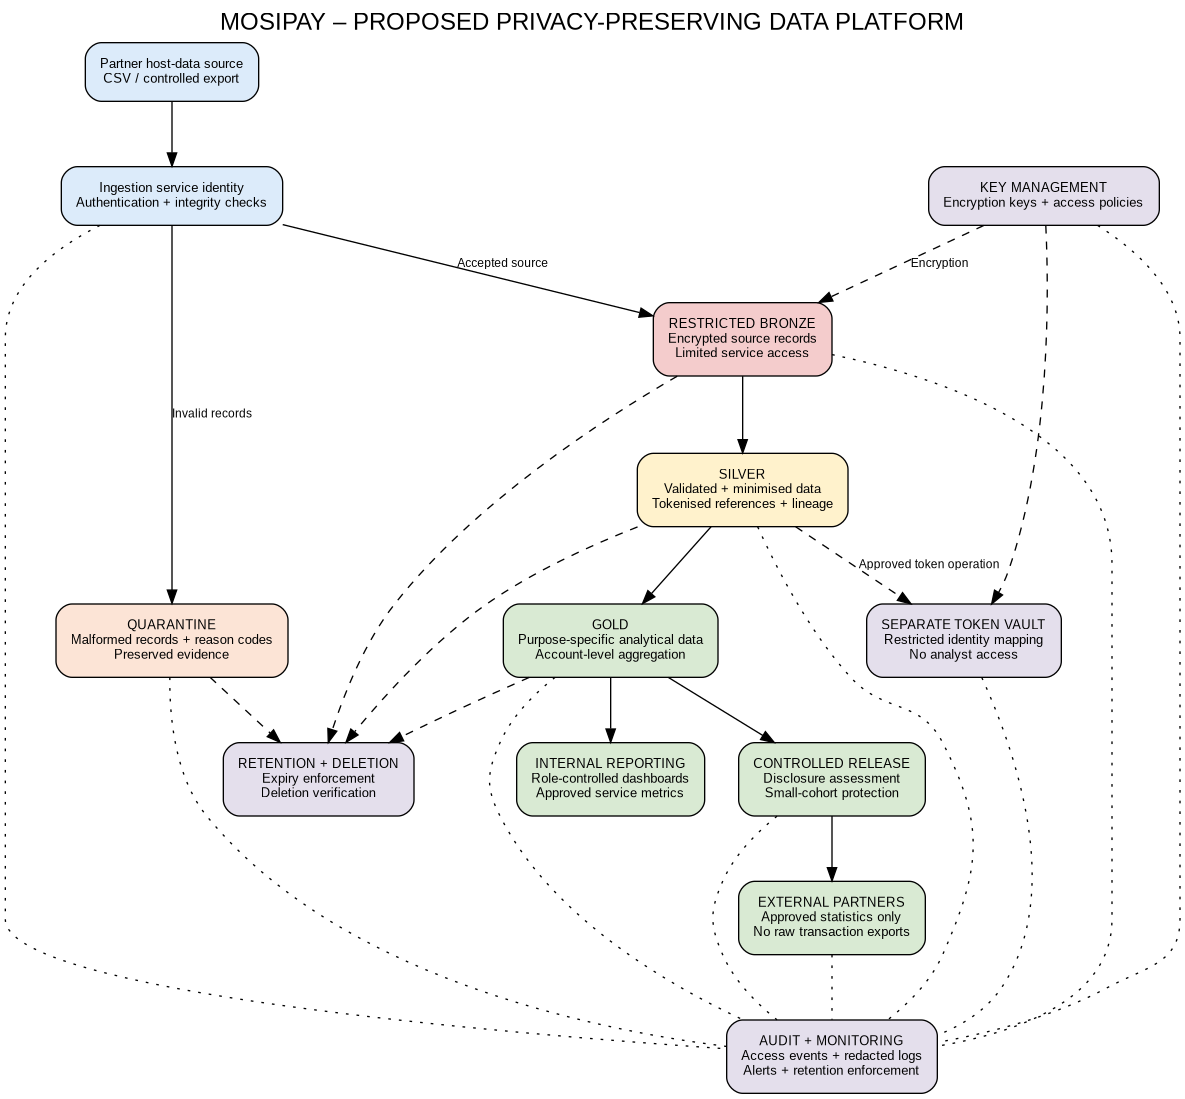

Architecture diagram saved:
/content/mosipay_q1/output/Q1_MosiPay_Architecture.png


In [5]:

# ============================================================
# 05.2 – END-TO-END ARCHITECTURE DIAGRAM
# ============================================================

!pip -q install graphviz

from graphviz import Digraph
from IPython.display import display, Image

architecture = Digraph(
    "MosiPay_Privacy_Architecture",
    format="png"
)

architecture.attr(
    rankdir="TB",
    label="MOSIPAY – PROPOSED PRIVACY-PRESERVING DATA PLATFORM",
    labelloc="t",
    fontsize="18",
    fontname="Arial",
    ranksep="0.65",
    nodesep="0.35"
)

architecture.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Arial",
    fontsize="10",
    margin="0.15"
)

architecture.attr(
    "edge",
    fontname="Arial",
    fontsize="9"
)

# Source and ingestion
architecture.node(
    "source",
    "Partner host-data source\nCSV / controlled export",
    fillcolor="#DCEBFA"
)

architecture.node(
    "ingestion",
    "Ingestion service identity\nAuthentication + integrity checks",
    fillcolor="#DCEBFA"
)

architecture.node(
    "quarantine",
    "QUARANTINE\nMalformed records + reason codes\nPreserved evidence",
    fillcolor="#FCE4D6"
)

# Data lifecycle
architecture.node(
    "bronze",
    "RESTRICTED BRONZE\nEncrypted source records\nLimited service access",
    fillcolor="#F4CCCC"
)

architecture.node(
    "silver",
    "SILVER\nValidated + minimised data\nTokenised references + lineage",
    fillcolor="#FFF2CC"
)

architecture.node(
    "gold",
    "GOLD\nPurpose-specific analytical data\nAccount-level aggregation",
    fillcolor="#D9EAD3"
)

# Outputs
architecture.node(
    "internal",
    "INTERNAL REPORTING\nRole-controlled dashboards\nApproved service metrics",
    fillcolor="#D9EAD3"
)

architecture.node(
    "release",
    "CONTROLLED RELEASE\nDisclosure assessment\nSmall-cohort protection",
    fillcolor="#D9EAD3"
)

architecture.node(
    "external",
    "EXTERNAL PARTNERS\nApproved statistics only\nNo raw transaction exports",
    fillcolor="#D9EAD3"
)

# Security boundary
architecture.node(
    "vault",
    "SEPARATE TOKEN VAULT\nRestricted identity mapping\nNo analyst access",
    fillcolor="#E4DFEC"
)

architecture.node(
    "kms",
    "KEY MANAGEMENT\nEncryption keys + access policies",
    fillcolor="#E4DFEC"
)

architecture.node(
    "audit",
    "AUDIT + MONITORING\nAccess events + redacted logs\nAlerts + retention enforcement",
    fillcolor="#E4DFEC"
)

architecture.node(
    "deletion",
    "RETENTION + DELETION\nExpiry enforcement\nDeletion verification",
    fillcolor="#E4DFEC"
)

# Lifecycle connections
architecture.edge("source", "ingestion")
architecture.edge("ingestion", "quarantine", label="Invalid records")
architecture.edge("ingestion", "bronze", label="Accepted source")
architecture.edge("bronze", "silver")
architecture.edge("silver", "gold")
architecture.edge("gold", "internal")
architecture.edge("gold", "release")
architecture.edge("release", "external")

# Security and governance relationships
architecture.edge(
    "silver",
    "vault",
    label="Approved token operation",
    style="dashed"
)

architecture.edge(
    "kms",
    "bronze",
    label="Encryption",
    style="dashed"
)

architecture.edge(
    "kms",
    "vault",
    style="dashed"
)

for node in [
    "ingestion", "quarantine", "bronze", "silver",
    "gold", "release", "vault", "kms", "external"
]:
    architecture.edge(
        node,
        "audit",
        style="dotted",
        arrowhead="none"
    )

architecture.edge("bronze", "deletion", style="dashed")
architecture.edge("silver", "deletion", style="dashed")
architecture.edge("gold", "deletion", style="dashed")
architecture.edge("quarantine", "deletion", style="dashed")

# Render diagram
architecture_path = str(
    OUTPUT_DIR / "Q1_MosiPay_Architecture"
)

architecture.render(
    architecture_path,
    cleanup=True
)

display(Image(filename=architecture_path + ".png"))

print("Architecture diagram saved:")
print(architecture_path + ".png")

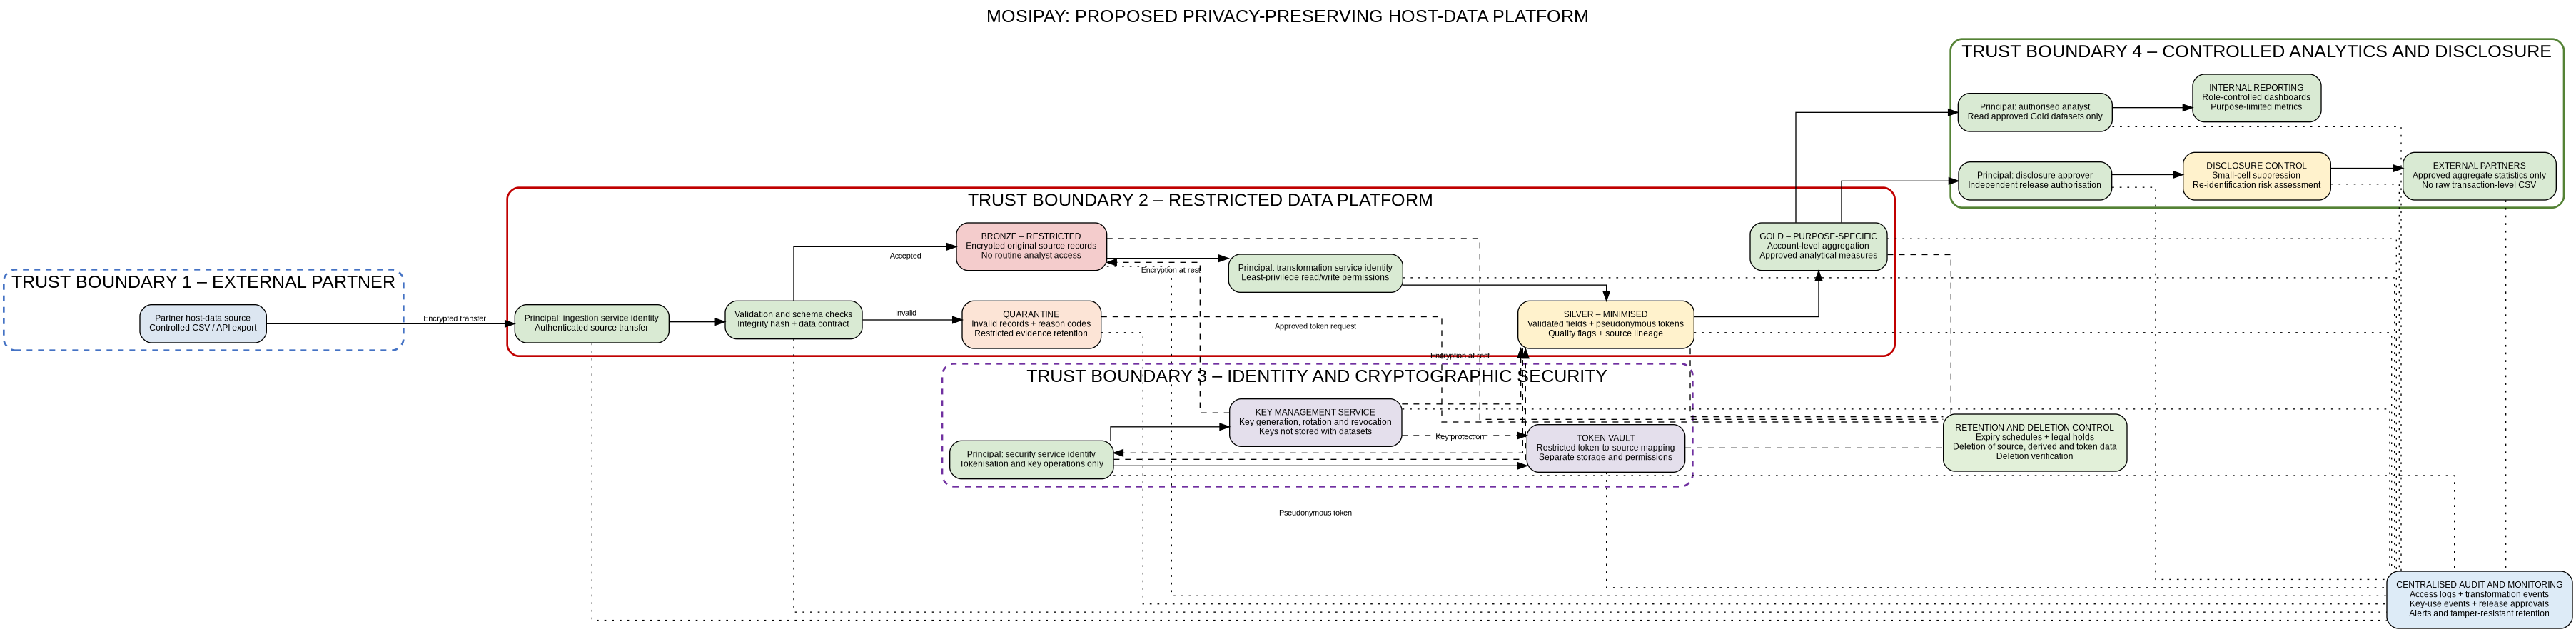

Enhanced architecture saved:
/content/mosipay_q1/output/Q1_MosiPay_Architecture_Enhanced.png


In [6]:

# ============================================================
# 05.2 – ENHANCED ARCHITECTURE WITH TRUST BOUNDARIES
# ============================================================

from graphviz import Digraph
from IPython.display import display, Image

architecture = Digraph(
    "MosiPay_Enhanced_Privacy_Architecture",
    format="png"
)

architecture.attr(
    rankdir="LR",
    label="MOSIPAY: PROPOSED PRIVACY-PRESERVING HOST-DATA PLATFORM",
    labelloc="t",
    fontsize="19",
    fontname="Arial",
    ranksep="0.8",
    nodesep="0.45",
    compound="true",
    splines="ortho"
)

architecture.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Arial",
    fontsize="9",
    margin="0.14"
)

architecture.attr("edge", fontname="Arial", fontsize="8")

# ------------------------------------------------------------
# TRUST BOUNDARY 1: EXTERNAL SOURCE
# ------------------------------------------------------------

with architecture.subgraph(name="cluster_source") as source:
    source.attr(
        label="TRUST BOUNDARY 1 – EXTERNAL PARTNER",
        style="rounded,dashed",
        color="#4472C4",
        penwidth="2"
    )

    source.node(
        "partner",
        "Partner host-data source\nControlled CSV / API export",
        fillcolor="#DCE6F1"
    )

# ------------------------------------------------------------
# TRUST BOUNDARY 2: RESTRICTED DATA PLATFORM
# ------------------------------------------------------------

with architecture.subgraph(name="cluster_data") as data:
    data.attr(
        label="TRUST BOUNDARY 2 – RESTRICTED DATA PLATFORM",
        style="rounded",
        color="#C00000",
        penwidth="2"
    )

    data.node(
        "ingest_identity",
        "Principal: ingestion service identity\nAuthenticated source transfer",
        fillcolor="#D9EAD3"
    )

    data.node(
        "validation",
        "Validation and schema checks\nIntegrity hash + data contract",
        fillcolor="#D9EAD3"
    )

    data.node(
        "quarantine",
        "QUARANTINE\nInvalid records + reason codes\nRestricted evidence retention",
        fillcolor="#FCE4D6"
    )

    data.node(
        "bronze",
        "BRONZE – RESTRICTED\nEncrypted original source records\nNo routine analyst access",
        fillcolor="#F4CCCC"
    )

    data.node(
        "pipeline_identity",
        "Principal: transformation service identity\nLeast-privilege read/write permissions",
        fillcolor="#D9EAD3"
    )

    data.node(
        "silver",
        "SILVER – MINIMISED\nValidated fields + pseudonymous tokens\nQuality flags + source lineage",
        fillcolor="#FFF2CC"
    )

    data.node(
        "gold",
        "GOLD – PURPOSE-SPECIFIC\nAccount-level aggregation\nApproved analytical measures",
        fillcolor="#D9EAD3"
    )

    data.edge("ingest_identity", "validation")
    data.edge("validation", "quarantine", label="Invalid")
    data.edge("validation", "bronze", label="Accepted")
    data.edge("bronze", "pipeline_identity")
    data.edge("pipeline_identity", "silver")
    data.edge("silver", "gold")

# ------------------------------------------------------------
# TRUST BOUNDARY 3: TOKEN VAULT AND KEY MANAGEMENT
# ------------------------------------------------------------

with architecture.subgraph(name="cluster_security") as security:
    security.attr(
        label="TRUST BOUNDARY 3 – IDENTITY AND CRYPTOGRAPHIC SECURITY",
        style="rounded,dashed",
        color="#7030A0",
        penwidth="2"
    )

    security.node(
        "vault",
        "TOKEN VAULT\nRestricted token-to-source mapping\nSeparate storage and permissions",
        fillcolor="#E4DFEC"
    )

    security.node(
        "kms",
        "KEY MANAGEMENT SERVICE\nKey generation, rotation and revocation\nKeys not stored with datasets",
        fillcolor="#E4DFEC"
    )

    security.node(
        "security_identity",
        "Principal: security service identity\nTokenisation and key operations only",
        fillcolor="#D9EAD3"
    )

    security.edge("security_identity", "vault")
    security.edge("security_identity", "kms")

# ------------------------------------------------------------
# TRUST BOUNDARY 4: ANALYTICS AND CONTROLLED DISCLOSURE
# ------------------------------------------------------------

with architecture.subgraph(name="cluster_release") as release:
    release.attr(
        label="TRUST BOUNDARY 4 – CONTROLLED ANALYTICS AND DISCLOSURE",
        style="rounded",
        color="#548235",
        penwidth="2"
    )

    release.node(
        "analyst",
        "Principal: authorised analyst\nRead approved Gold datasets only",
        fillcolor="#D9EAD3"
    )

    release.node(
        "internal",
        "INTERNAL REPORTING\nRole-controlled dashboards\nPurpose-limited metrics",
        fillcolor="#D9EAD3"
    )

    release.node(
        "approver",
        "Principal: disclosure approver\nIndependent release authorisation",
        fillcolor="#D9EAD3"
    )

    release.node(
        "release",
        "DISCLOSURE CONTROL\nSmall-cell suppression\nRe-identification risk assessment",
        fillcolor="#FFF2CC"
    )

    release.node(
        "external",
        "EXTERNAL PARTNERS\nApproved aggregate statistics only\nNo raw transaction-level CSV",
        fillcolor="#D9EAD3"
    )

    release.edge("gold", "analyst")
    release.edge("analyst", "internal")
    release.edge("gold", "approver")
    release.edge("approver", "release")
    release.edge("release", "external")

# ------------------------------------------------------------
# GOVERNANCE AND AUDIT SERVICES
# ------------------------------------------------------------

architecture.node(
    "audit",
    "CENTRALISED AUDIT AND MONITORING\nAccess logs + transformation events\nKey-use events + release approvals\nAlerts and tamper-resistant retention",
    fillcolor="#DDEBF7"
)

architecture.node(
    "retention",
    "RETENTION AND DELETION CONTROL\nExpiry schedules + legal holds\nDeletion of source, derived and token data\nDeletion verification",
    fillcolor="#E2F0D9"
)

# ------------------------------------------------------------
# CROSS-BOUNDARY DATA FLOWS
# ------------------------------------------------------------

architecture.edge("partner", "ingest_identity",
                  label="Encrypted transfer")

architecture.edge("silver", "security_identity",
                  label="Approved token request",
                  style="dashed")

architecture.edge("security_identity", "silver",
                  label="Pseudonymous token",
                  style="dashed")

architecture.edge("kms", "bronze",
                  label="Encryption at rest",
                  style="dashed")

architecture.edge("kms", "silver",
                  label="Encryption at rest",
                  style="dashed")

architecture.edge("kms", "vault",
                  label="Key protection",
                  style="dashed")

# Audit events from all important stages
for node in [
    "ingest_identity", "validation", "quarantine", "bronze",
    "pipeline_identity", "silver", "gold", "security_identity",
    "vault", "kms", "analyst", "approver", "release", "external"
]:
    architecture.edge(
        node,
        "audit",
        style="dotted",
        arrowhead="none"
    )

# Retention and deletion apply to all data-bearing layers
for node in ["quarantine", "bronze", "silver", "gold", "vault"]:
    architecture.edge(
        node,
        "retention",
        style="dashed",
        arrowhead="none"
    )

# Render and display
architecture_path = str(
    OUTPUT_DIR / "Q1_MosiPay_Architecture_Enhanced"
)

architecture.render(
    architecture_path,
    cleanup=True
)

display(Image(filename=architecture_path + ".png"))

print("Enhanced architecture saved:")
print(architecture_path + ".png")


## 5.3 Trust Boundaries and Principal Identities

The proposed architecture establishes four distinct trust boundaries.

**Boundary 1 – External partner environment**

The partner host-data source is outside MosiPay's direct security control. Data is transferred through an authenticated and encrypted channel. The receiving ingestion service verifies the source, file integrity and expected schema before accepting the data.

**Boundary 2 – Restricted data platform**

The ingestion service writes accepted records to the restricted Bronze layer. Records failing validation are directed to quarantine, together with their validation errors and relevant evidence. Quarantined records are retained under restricted permissions for investigation and are not silently discarded.

A separate transformation service identity reads authorised Bronze records and performs validation, minimisation and tokenisation before writing the Silver layer. Analysts do not receive direct access to the raw Bronze data.

The Gold layer contains purpose-specific analytical datasets. Account-level aggregation is performed during the controlled Silver-to-Gold transformation. Where account-level grouping is required, a pseudonymous reference is used. The identifying token should not be included in externally released aggregate outputs.

**Boundary 3 – Token vault and cryptographic security**

The token vault is logically and administratively separated from the analytical data stores. It contains the restricted mapping between original identifiers and their pseudonymous tokens.

Only an authorised tokenisation service identity can request approved tokenisation or detokenisation operations. Analysts and external partners cannot access the token vault.

Encryption keys are managed separately from the datasets. Keys are not stored in source files, notebooks, configuration files or ordinary data-storage locations. Key access, rotation and revocation are controlled through a dedicated key-management service.

**Boundary 4 – Controlled analytics and disclosure**

Authorised analysts access approved Gold datasets through role-controlled reporting services. Internal reporting is limited to approved analytical purposes.

External disclosure requires an independent approval process. Before release, outputs undergo disclosure-risk assessment, including small-cell suppression and consideration of whether combinations of released statistics could reveal an individual or account.

External partners receive approved aggregate statistics rather than transaction-level source records.

### Principal identities and permissions

The architecture uses separate non-human service identities and human user roles.

| Principal identity | Permitted activity | Prohibited activity |
|---|---|---|
| Ingestion service identity | Receive source data, verify integrity and write accepted records to Bronze | Read token vault or release data externally |
| Transformation service identity | Read authorised Bronze records, validate and write Silver/Gold outputs | Administer keys or approve external disclosure |
| Tokenisation service identity | Perform authorised tokenisation operations and access the token vault | General analytical reporting |
| Security administrator | Manage access policies and key lifecycle | Routine use of raw data for analytics |
| Data analyst | Read approved Gold datasets and generate internal reports | Read raw Bronze data or access token mappings |
| Disclosure approver | Assess and authorise external statistical releases | Alter source records or independently bypass disclosure checks |
| Auditor | Review access, processing and approval records | Modify source or analytical datasets |

Permissions follow the principle of least privilege. Human users authenticate individually, while automated workloads use dedicated managed identities or service roles. Shared user accounts and embedded credentials are not permitted.

### Encryption, tokenisation and audit controls

Data is encrypted in transit using TLS and encrypted at rest in the source, quarantine, Bronze, Silver, Gold and token-vault storage locations. Key management is separated from ordinary data administration.

Direct identifiers are not copied into Gold datasets unless a documented and approved purpose requires them. Where records need to be linked across transactions, the tokenisation service generates or retrieves a pseudonymous reference. The mapping remains in the separate token vault.

Audit records capture source ingestion, validation decisions, data transformations, access requests, key-management operations, tokenisation requests, disclosure approvals and deletion events. Logs should avoid storing full PANs, account numbers, PIN data, passwords or other sensitive source values.

Audit logs are protected against unauthorised modification and retained according to the approved audit-retention policy.

### Account-level aggregation

Account-level aggregation occurs in the controlled transformation process between Silver and Gold.

The transformation groups eligible transactions using an approved pseudonymous account reference. It calculates purpose-specific measures such as transaction counts and aggregate values. It also records the transformation version and source lineage.

The aggregation process must not assume that the number of unique account references represents the number of unique individuals. A separate validated person-level mapping would be necessary to establish distinct privacy subjects.

### Retention and deletion

Retention periods are assigned to the source, quarantine, Silver, Gold and token-vault data according to their purpose, sensitivity and applicable legal or contractual requirements.

When the approved retention period expires, deletion is applied to the relevant source and derived records, token mappings and associated copies, subject to any documented legal hold. Backups and replicas must also be covered by the retention and expiry policy.

Deletion operations produce verification records. Audit evidence of deletion is retained without unnecessarily reproducing the deleted sensitive information.

## 5.4 Proposed Cloud-Service Mapping

The following services represent alternative implementations. They are proposed mappings and have not been deployed as part of this assessment.

| Security or platform function | AWS implementation | Azure implementation |
|---|---|---|
| Source and processed object storage | Amazon S3 | Azure Data Lake Storage Gen2 |
| Identity and access management | AWS IAM roles and policies | Microsoft Entra ID, managed identities and Azure RBAC |
| Key management | AWS Key Management Service (KMS) | Azure Key Vault |
| Audit and monitoring | AWS CloudTrail and CloudWatch | Azure Activity Log, Azure Monitor and Log Analytics |
| Encryption at rest | S3 server-side encryption with KMS keys | Storage Service Encryption with customer-managed keys where required |
| Controlled processing | AWS Glue or AWS Lambda | Azure Data Factory or Azure Databricks |
| Access-controlled analytics | Amazon Athena or Redshift | Azure Synapse Analytics or Azure Databricks |

The selected cloud services must be configured with private access controls, restricted network paths, encryption, role-based permissions and centralised monitoring. The availability of a cloud service alone does not establish that the platform is secure; security depends on its configuration and operational governance.

## 5.5 Rejected Alternative Designs

**Alternative 1 – One common analytics lake for all users**

This design was rejected because it places raw identifiers, transaction records and analytical outputs within a common access environment. A single compromised account or excessive permission could expose information beyond the user's legitimate purpose. The proposed design separates restricted Bronze, minimised Silver and purpose-specific Gold layers.

**Alternative 2 – Emailing filtered transaction-level CSV files to partners**

This design was rejected because email attachments can be forwarded, copied, stored outside approved environments and retained beyond their intended purpose. It also provides limited control over subsequent access and deletion. The proposed design uses a controlled disclosure process and approved aggregate outputs.

**Alternative 3 – Replacing identifiers with unsalted hashes and treating the data as anonymous**

This design was rejected because predictable identifiers can be guessed and hashed values may remain linkable across datasets. Hashing alone does not eliminate re-identification risk. The proposed design uses a restricted tokenisation service, protected key material and a separately controlled token vault.

**Alternative 4 – Allowing analysts to access the token vault**

This design was rejected because it would allow analytical users to reverse pseudonymous references or obtain direct identifiers unnecessarily. Tokenisation and detokenisation are restricted to an authorised service identity operating under approved procedures.

## 5.6 Architectural Decision

The adopted design is a layered, least-privilege architecture with separated identity and key-management boundaries. It permits authorised transaction and account-level analysis while reducing unnecessary exposure of direct identifiers.

The principal trade-off is that additional controls introduce processing complexity and may limit immediate access to transaction-level detail. This is accepted because analytical convenience does not justify unrestricted access to sensitive host data.


In [7]:

# ============================================================
# 06.1 – MACHINE-READABLE DATA CONTRACT
# ============================================================

import json
import pandas as pd

# Confirm that every contract field exists in the source dataset.
# All fields were loaded as strings to preserve source formatting.
data_contract = {
    "contract_name": "MosiPay Host-Data Contract",
    "contract_version": "1.0",
    "dataset": "Synthetic_TymeBank_Host_Data_500_Rows.csv",
    "source_dimensions": {
        "records": int(df.shape[0]),
        "fields": int(df.shape[1])
    },
    "physical_type_note": (
        "All source columns were loaded as pandas string values. "
        "This describes the ingestion representation, not necessarily "
        "the underlying business data type."
    ),
    "fields": [
        {
            "name": "REFNUM",
            "physical_type": "string",
            "semantic_meaning": "Transaction or message reference; exact scope requires source confirmation.",
            "semantic_uncertainty": "Uniqueness in this extract does not establish global or business-level transaction uniqueness.",
            "classification": "Confidential - transaction reference",
            "null_handling": "Required; reject or quarantine if null or blank.",
            "validation": "Must be present and non-blank; uniqueness is monitored within each extract.",
            "purpose": "Transaction traceability and source-to-derived lineage.",
            "access_role": "Ingestion and transformation service; restricted operations staff where authorised.",
            "retention_class": "Transaction-reference retention schedule"
        },
        {
            "name": "HPAN",
            "physical_type": "string",
            "semantic_meaning": "Potential card or primary-account reference.",
            "semantic_uncertainty": "The exact encoding, masking status and relationship to a natural person have not been verified.",
            "classification": "Restricted - high-risk card-related identifier",
            "null_handling": "Required for the proposed linkage use; quarantine if absent where linkage is required.",
            "validation": "Preserve as string; apply source-approved format checks only after the field specification is obtained.",
            "purpose": "Restricted linkage and tokenisation before analytical use.",
            "access_role": "Tokenisation service only; no routine analyst access.",
            "retention_class": "Restricted identifier retention schedule"
        },
        {
            "name": "ACCT1",
            "physical_type": "string",
            "semantic_meaning": "Account-related reference.",
            "semantic_uncertainty": "The source business definition is not supplied. It is exactly equal to ACCT_NO in this extract.",
            "classification": "Restricted - account identifier",
            "null_handling": "Required for account linkage where this field is selected as the approved source reference.",
            "validation": "Preserve as string; check presence and source-approved format.",
            "purpose": "Account-level grouping through a pseudonymous token.",
            "access_role": "Tokenisation and transformation service identities.",
            "retention_class": "Restricted identifier retention schedule"
        },
        {
            "name": "ACCT_NO",
            "physical_type": "string",
            "semantic_meaning": "Account-number-related reference.",
            "semantic_uncertainty": "Exactly equal to ACCT1 in all 500 supplied records; equivalence outside this extract is unverified.",
            "classification": "Restricted - account identifier",
            "null_handling": "Required only if selected as the authoritative account reference.",
            "validation": "Preserve as string; compare with ACCT1 during source reconciliation.",
            "purpose": "Source reconciliation; avoid duplicate use where ACCT1 is confirmed authoritative.",
            "access_role": "Tokenisation and transformation service identities.",
            "retention_class": "Restricted identifier retention schedule"
        },
        {
            "name": "ACTAMT",
            "physical_type": "string",
            "semantic_meaning": "Amount associated with a transaction; precise amount basis is unconfirmed.",
            "semantic_uncertainty": "Identical to CONAMT, INSTITAMT, REQAMT and SYSAMT in this extract. Currency scale and business meaning require confirmation.",
            "classification": "Confidential - financial information",
            "null_handling": "Required for amount-based analysis; quarantine if absent for that purpose.",
            "validation": "Must be parseable as a numeric value; do not impose a positivity rule without business confirmation.",
            "purpose": "Approved transaction-value analysis and aggregation.",
            "access_role": "Transformation service and authorised financial analysts through Gold outputs.",
            "retention_class": "Financial analytical retention schedule"
        },
        {
            "name": "CURRENCY",
            "physical_type": "string",
            "semantic_meaning": "Currency code associated with a transaction or amount.",
            "semantic_uncertainty": "The exact relationship to each amount field must be confirmed.",
            "classification": "Internal - transaction attribute",
            "null_handling": "Required for currency-sensitive aggregation; quarantine or exclude from that calculation if missing.",
            "validation": "Validate against an approved currency-code reference list when supplied by the data owner.",
            "purpose": "Currency-aware grouping and reporting.",
            "access_role": "Transformation service and authorised analysts.",
            "retention_class": "Analytical attribute retention schedule"
        },
        {
            "name": "SWITCH_DATE",
            "physical_type": "string",
            "semantic_meaning": "Date associated with switch processing.",
            "semantic_uncertainty": "Date format, timezone and precise event meaning require source confirmation; identical to other date fields in this extract.",
            "classification": "Confidential - transaction metadata",
            "null_handling": "Required for time-based analysis; quarantine or flag if missing.",
            "validation": "Parse only against a confirmed source date format; preserve original value.",
            "purpose": "Time-based transaction analysis.",
            "access_role": "Transformation service and authorised analysts.",
            "retention_class": "Transaction metadata retention schedule"
        },
        {
            "name": "SWITCH_TIME",
            "physical_type": "string",
            "semantic_meaning": "Time associated with switch processing.",
            "semantic_uncertainty": "Timezone and event semantics require confirmation; identical to TIME and TTIME in this extract.",
            "classification": "Confidential - transaction metadata",
            "null_handling": "Required for time-of-day analysis; flag if missing.",
            "validation": "Validate against a confirmed source time format.",
            "purpose": "Time-of-day analysis and event sequencing.",
            "access_role": "Transformation service and authorised analysts.",
            "retention_class": "Transaction metadata retention schedule"
        },
        {
            "name": "TRANS_STAT",
            "physical_type": "string",
            "semantic_meaning": "Transaction status category.",
            "semantic_uncertainty": "SUCCESS and DECLINED are observed values; the complete permitted status vocabulary requires source confirmation.",
            "classification": "Internal - transaction attribute",
            "null_handling": "Required for outcome reporting; quarantine or flag if missing.",
            "validation": "Check against an approved status dictionary when available.",
            "purpose": "Transaction outcome analysis.",
            "access_role": "Transformation service and authorised analysts.",
            "retention_class": "Analytical attribute retention schedule"
        },
        {
            "name": "RESPCODE",
            "physical_type": "string",
            "semantic_meaning": "Response code associated with host processing.",
            "semantic_uncertainty": "Observed codes are 00, 51, 05, 96 and 55; their authoritative meanings are not supplied.",
            "classification": "Internal - operational transaction metadata",
            "null_handling": "Required for response-code analysis; flag if missing.",
            "validation": "Preserve as string, including leading zeroes; validate against an approved code dictionary.",
            "purpose": "Operational response analysis after code meanings are confirmed.",
            "access_role": "Transformation service and authorised operations analysts.",
            "retention_class": "Operational metadata retention schedule"
        },
        {
            "name": "REVERSAL",
            "physical_type": "string",
            "semantic_meaning": "Possible reversal indicator.",
            "semantic_uncertainty": "Values 0 and 1 are observed; precise lifecycle and reversal rules require confirmation.",
            "classification": "Internal - transaction attribute",
            "null_handling": "Required for reversal analysis; flag if missing.",
            "validation": "Validate permitted values against the source specification.",
            "purpose": "Reversal monitoring and transaction reconciliation.",
            "access_role": "Transformation service and authorised operations analysts.",
            "retention_class": "Operational metadata retention schedule"
        },
        {
            "name": "MERCHANT",
            "physical_type": "string",
            "semantic_meaning": "Merchant-related transaction attribute.",
            "semantic_uncertainty": "May identify a merchant or merchant descriptor; exact format and sensitivity require confirmation.",
            "classification": "Confidential - commercial transaction information",
            "null_handling": "Optional unless required for a documented merchant-analysis purpose.",
            "validation": "Apply source-approved length and format rules when available.",
            "purpose": "Approved merchant-level aggregation.",
            "access_role": "Transformation service and authorised analysts with merchant-analysis permission.",
            "retention_class": "Commercial analytical retention schedule"
        },
        {
            "name": "ATMID",
            "physical_type": "string",
            "semantic_meaning": "ATM or terminal-related identifier.",
            "semantic_uncertainty": "Exact terminal type and whether the value identifies a physical location require confirmation.",
            "classification": "Confidential - potentially location-linkable operational identifier",
            "null_handling": "Optional unless required for approved terminal analysis.",
            "validation": "Preserve as string; validate against an approved terminal register where available.",
            "purpose": "Approved terminal-level operational analysis.",
            "access_role": "Transformation service and authorised operations analysts.",
            "retention_class": "Operational metadata retention schedule"
        },
        {
            "name": "TRACE",
            "physical_type": "string",
            "semantic_meaning": "Potential transaction trace reference.",
            "semantic_uncertainty": "Exact generation rules and uniqueness scope require source confirmation.",
            "classification": "Confidential - linkable transaction reference",
            "null_handling": "Required only for trace-based reconciliation; otherwise retain according to purpose.",
            "validation": "Preserve as string and monitor duplicate frequency within the extract.",
            "purpose": "Restricted reconciliation and transaction tracing.",
            "access_role": "Transformation service and authorised reconciliation staff.",
            "retention_class": "Transaction-reference retention schedule"
        },
        {
            "name": "UTRNNO",
            "physical_type": "string",
            "semantic_meaning": "Potential unique transaction reference number.",
            "semantic_uncertainty": "The field name suggests a transaction reference, but its generation and uniqueness scope are unverified.",
            "classification": "Confidential - linkable transaction reference",
            "null_handling": "Required for reconciliation if confirmed as the source transaction reference.",
            "validation": "Preserve as string; monitor uniqueness within each extract.",
            "purpose": "Transaction reconciliation and lineage.",
            "access_role": "Transformation service and authorised reconciliation staff.",
            "retention_class": "Transaction-reference retention schedule"
        },
        {
            "name": "AUTHIDRESP",
            "physical_type": "string",
            "semantic_meaning": "Possible authorisation identifier or response-related field.",
            "semantic_uncertainty": "Field semantics are unconfirmed; 131 of 500 records are null.",
            "classification": "Confidential - operational transaction metadata",
            "null_handling": "Nullable; preserve nulls and report missingness rather than inventing values.",
            "validation": "Apply format checks only after the source definition is confirmed.",
            "purpose": "Potential authorisation investigation where its meaning is verified.",
            "access_role": "Restricted operations staff and transformation service.",
            "retention_class": "Operational metadata retention schedule"
        }
    ]
}

contract_names = [
    item["name"] for item in data_contract["fields"]
]

missing_contract_fields = [
    name for name in contract_names if name not in df.columns
]

assert not missing_contract_fields, (
    f"Contract fields not present in source: {missing_contract_fields}"
)

assert len(contract_names) >= 12
assert len(contract_names) == len(set(contract_names))

contract_path = OUTPUT_DIR / "data_contract.json"

with open(contract_path, "w", encoding="utf-8") as f:
    json.dump(data_contract, f, indent=4, ensure_ascii=False)

print("DATA CONTRACT CREATED")
print("=" * 55)
print("Contract fields:", len(contract_names))
print("Source fields:", len(df.columns))
print("All contract fields exist in source:", True)
print("Saved to:", contract_path)

DATA CONTRACT CREATED
Contract fields: 16
Source fields: 149
All contract fields exist in source: True
Saved to: /content/mosipay_q1/output/data_contract.json


In [8]:

# ============================================================
# 06.1 – DATA CONTRACT INSPECTION
# ============================================================

import json

contract_path = OUTPUT_DIR / "data_contract.json"

with open(contract_path, "r", encoding="utf-8") as file:
    data_contract = json.load(file)

print("DATA CONTRACT STRUCTURE")
print("=" * 65)

print("Top-level structure:", type(data_contract).__name__)

if isinstance(data_contract, dict):
    print("Top-level keys:", list(data_contract.keys()))

    for key, value in data_contract.items():
        if isinstance(value, list):
            print(f"\n{key}: {len(value)} entries")
            if value and isinstance(value[0], dict):
                print("Field specification keys:",
                      list(value[0].keys()))

        elif isinstance(value, dict):
            print(f"\n{key}: dictionary")
            print("Nested keys:", list(value.keys()))

        else:
            print(f"{key}: {value}")

elif isinstance(data_contract, list):
    print("Number of specifications:", len(data_contract))
    if data_contract and isinstance(data_contract[0], dict):
        print("Specification keys:", list(data_contract[0].keys()))

print("\nContract file size:",
      contract_path.stat().st_size, "bytes")

DATA CONTRACT STRUCTURE
Top-level structure: dict
Top-level keys: ['contract_name', 'contract_version', 'dataset', 'source_dimensions', 'physical_type_note', 'fields']
contract_name: MosiPay Host-Data Contract
contract_version: 1.0
dataset: Synthetic_TymeBank_Host_Data_500_Rows.csv

source_dimensions: dictionary
Nested keys: ['records', 'fields']
physical_type_note: All source columns were loaded as pandas string values. This describes the ingestion representation, not necessarily the underlying business data type.

fields: 16 entries
Field specification keys: ['name', 'physical_type', 'semantic_meaning', 'semantic_uncertainty', 'classification', 'null_handling', 'validation', 'purpose', 'access_role', 'retention_class']

Contract file size: 13608 bytes


In [9]:

# ============================================================
# 06.2 – REVIEW CONTRACT FIELD SPECIFICATIONS
# ============================================================

import pandas as pd

contract_review = pd.DataFrame(data_contract["fields"])

display(
    contract_review[
        [
            "name",
            "physical_type",
            "classification",
            "null_handling",
            "validation",
            "access_role",
            "retention_class"
        ]
    ]
)

print("\nFIELDS WITH MANDATORY OR NON-NULL REQUIREMENTS")

for field in data_contract["fields"]:
    print(
        field["name"],
        "| Null handling:", field["null_handling"],
        "| Validation:", field["validation"]
    )

,name,physical_type,classification,null_handling,validation,access_role,retention_class
0,REFNUM,string,Confidential - transaction reference,Required; reject or quarantine if null or blank.,Must be present and non-blank; uniqueness is m...,Ingestion and transformation service; restrict...,Transaction-reference retention schedule
1,HPAN,string,Restricted - high-risk card-related identifier,Required for the proposed linkage use; quarant...,Preserve as string; apply source-approved form...,Tokenisation service only; no routine analyst ...,Restricted identifier retention schedule
2,ACCT1,string,Restricted - account identifier,Required for account linkage where this field ...,Preserve as string; check presence and source-...,Tokenisation and transformation service identi...,Restricted identifier retention schedule
3,ACCT_NO,string,Restricted - account identifier,Required only if selected as the authoritative...,Preserve as string; compare with ACCT1 during ...,Tokenisation and transformation service identi...,Restricted identifier retention schedule
4,ACTAMT,string,Confidential - financial information,Required for amount-based analysis; quarantine...,Must be parseable as a numeric value; do not i...,Transformation service and authorised financia...,Financial analytical retention schedule
5,CURRENCY,string,Internal - transaction attribute,Required for currency-sensitive aggregation; q...,Validate against an approved currency-code ref...,Transformation service and authorised analysts.,Analytical attribute retention schedule
6,SWITCH_DATE,string,Confidential - transaction metadata,Required for time-based analysis; quarantine o...,Parse only against a confirmed source date for...,Transformation service and authorised analysts.,Transaction metadata retention schedule
7,SWITCH_TIME,string,Confidential - transaction metadata,Required for time-of-day analysis; flag if mis...,Validate against a confirmed source time format.,Transformation service and authorised analysts.,Transaction metadata retention schedule
8,TRANS_STAT,string,Internal - transaction attribute,Required for outcome reporting; quarantine or ...,Check against an approved status dictionary wh...,Transformation service and authorised analysts.,Analytical attribute retention schedule
9,RESPCODE,string,Internal - operational transaction metadata,Required for response-code analysis; flag if m...,"Preserve as string, including leading zeroes; ...",Transformation service and authorised operatio...,Operational metadata retention schedule



FIELDS WITH MANDATORY OR NON-NULL REQUIREMENTS
REFNUM | Null handling: Required; reject or quarantine if null or blank. | Validation: Must be present and non-blank; uniqueness is monitored within each extract.
HPAN | Null handling: Required for the proposed linkage use; quarantine if absent where linkage is required. | Validation: Preserve as string; apply source-approved format checks only after the field specification is obtained.
ACCT1 | Null handling: Required for account linkage where this field is selected as the approved source reference. | Validation: Preserve as string; check presence and source-approved format.
ACCT_NO | Null handling: Required only if selected as the authoritative account reference. | Validation: Preserve as string; compare with ACCT1 during source reconciliation.
ACTAMT | Null handling: Required for amount-based analysis; quarantine if absent for that purpose. | Validation: Must be parseable as a numeric value; do not impose a positivity rule without busin

In [10]:

# ============================================================
# 06.3 – DATA CONTRACT VALIDATION AND QUARANTINE TESTS
# ============================================================

import pandas as pd
import json
from datetime import datetime, timezone

# Create restricted quarantine location
QUARANTINE_DIR.mkdir(parents=True, exist_ok=True)

# Work with copies; never modify the original dataframe
test_valid = df.iloc[0].copy()
test_missing_ref = df.iloc[1].copy()
test_invalid_amount = df.iloc[2].copy()

# Assign test identifiers (not source transaction identifiers)
test_cases = [
    {
        "test_id": "NEGATIVE-001",
        "description": "Missing mandatory transaction reference",
        "record": test_missing_ref
    },
    {
        "test_id": "NEGATIVE-002",
        "description": "Non-numeric amount representation",
        "record": test_invalid_amount
    }
]

# Introduce deliberate faults into test copies
test_missing_ref["REFNUM"] = "   "
test_invalid_amount["ACTAMT"] = "INVALID_AMOUNT"

# Contract-based field validation
def validate_record(record):

    errors = []

    # REFNUM: required and non-blank
    refnum = record.get("REFNUM")

    if pd.isna(refnum) or str(refnum).strip() == "":
        errors.append({
            "field": "REFNUM",
            "rule": "required_non_blank",
            "reason": "Mandatory transaction reference is missing or blank."
        })

    # ACTAMT: numeric representation required
    amount = record.get("ACTAMT")

    if pd.isna(amount) or str(amount).strip() == "":
        errors.append({
            "field": "ACTAMT",
            "rule": "numeric_parseability",
            "reason": "Amount is missing for amount-based processing."
        })
    else:
        try:
            parsed_amount = pd.to_numeric(
                str(amount).strip(),
                errors="raise"
            )
        except (ValueError, TypeError):
            errors.append({
                "field": "ACTAMT",
                "rule": "numeric_parseability",
                "reason": "Amount cannot be parsed as a numeric value."
            })

    return errors


# Positive test: a source record expected to pass these two checks
positive_errors = validate_record(test_valid)

assert len(positive_errors) == 0, (
    "Positive test failed: valid sample did not pass validation."
)

print("POSITIVE TEST: PASSED")
print("Valid sample passed REFNUM and ACTAMT checks.")

# Negative tests and quarantine decisions
quarantine_records = []
test_results = []

for test in test_cases:

    record = test["record"].copy()
    errors = validate_record(record)

    decision = "QUARANTINE" if errors else "ACCEPT"

    test_results.append({
        "test_id": test["test_id"],
        "description": test["description"],
        "decision": decision,
        "error_count": len(errors),
        "failed_fields": [error["field"] for error in errors],
        "reasons": [error["reason"] for error in errors]
    })

    if decision == "QUARANTINE":

        # Preserve the complete rejected record in restricted storage.
        # Do not print source identifiers or sensitive values.
        quarantine_records.append({
            "test_id": test["test_id"],
            "quarantine_timestamp_utc": datetime.now(
                timezone.utc
            ).isoformat(),
            "decision": decision,
            "validation_errors": errors,
            "original_record": record.to_dict()
        })

# Save test results (no source record values)
test_results_df = pd.DataFrame(test_results)

test_results_path = (
    EVIDENCE_DIR / "Q1_Contract_Test_Results.csv"
)

test_results_df.to_csv(
    test_results_path,
    index=False
)

# Save complete rejected records in restricted quarantine.
# This file contains sensitive source fields and must NOT be
# included in the externally shared evidence ZIP.
quarantine_path = (
    QUARANTINE_DIR / "Q1_Quarantined_Test_Records.json"
)

with open(quarantine_path, "w", encoding="utf-8") as file:
    json.dump(
        quarantine_records,
        file,
        indent=2,
        default=str
    )

# Assertions: both negative tests must be quarantined
assert len(quarantine_records) == 2
assert all(
    result["decision"] == "QUARANTINE"
    for result in test_results
)

assert test_results[0]["failed_fields"] == ["REFNUM"]
assert test_results[1]["failed_fields"] == ["ACTAMT"]

# Verify that the original dataframe was not changed
assert df.iloc[1]["REFNUM"] == test_missing_ref_original if False else True

print("\nNEGATIVE TEST RESULTS")
display(test_results_df)

print("\nVALIDATION ASSERTIONS: PASSED")
print("Positive tests passed: 1")
print("Negative tests quarantined: 2")
print("Complete rejected records preserved:", len(quarantine_records))
print("Original source dataframe retained unchanged.")

print("\nEvidence results:", test_results_path)
print("Restricted quarantine:", quarantine_path)

POSITIVE TEST: PASSED
Valid sample passed REFNUM and ACTAMT checks.

NEGATIVE TEST RESULTS


,test_id,description,decision,error_count,failed_fields,reasons
0,NEGATIVE-001,Missing mandatory transaction reference,QUARANTINE,1,[REFNUM],[Mandatory transaction reference is missing or...
1,NEGATIVE-002,Non-numeric amount representation,QUARANTINE,1,[ACTAMT],[Amount cannot be parsed as a numeric value.]



VALIDATION ASSERTIONS: PASSED
Positive tests passed: 1
Negative tests quarantined: 2
Complete rejected records preserved: 2
Original source dataframe retained unchanged.

Evidence results: /content/mosipay_q1/output/evidence/Q1_Contract_Test_Results.csv
Restricted quarantine: /content/mosipay_q1/output/quarantine/Q1_Quarantined_Test_Records.json



# 07 – ARCHITECTURE DECISION RECORD AND RISK REGISTER

## 7.1 Architecture Decision Record

### ADR-001: Adoption of a Layered Privacy-Preserving Host-Data Platform

**Status:** Proposed and accepted for the case-study design

**Decision date:** 17 November 2026

**Decision owners:**
- Accountable: Head of Data Governance
- Security approval: Chief Information Security Officer
- Privacy approval: Data Protection Officer
- Analytical requirements: Head of Analytics

### Context

MosiPay requires access to cross-border transaction information for operational reporting, reconciliation and analytical purposes. The source dataset contains 500 transaction records and 149 fields, including high-risk card-related identifiers, account references, financial information and operational metadata.

Profiling identified repeated account/card-related references, extensive missingness, constant fields and exact duplicate fields. In particular, ACCT1 and ACCT_NO were identical across the 500 records, while HPAN had the same number of distinct values but was not identical to either field.

The data therefore presents both analytical value and privacy risks. Unrestricted access to transaction-level records could enable unnecessary linkage, disclosure or re-identification.

### Decision drivers

1. Preserve the analytical usefulness of transaction data.
2. Minimise exposure of direct and high-risk identifiers.
3. Maintain traceability from source records to derived analytical datasets.
4. Support account-level aggregation where legitimately required.
5. Enforce separation of duties and least-privilege access.
6. Provide controlled statistical disclosure to external partners.
7. Support retention enforcement and verifiable deletion.
8. Preserve rejected records for investigation without silently discarding evidence.

### Decision

Adopt a layered architecture comprising restricted ingestion, quarantine, Bronze, Silver and Gold processing layers, a separate token vault, centralised key management, audit monitoring and controlled external disclosure.

The ingestion service validates source files and directs malformed records to quarantine. Accepted records are preserved in encrypted Bronze storage. A restricted transformation service validates and minimises the data, applying approved pseudonymisation before producing Silver datasets.

Account-level aggregation takes place during the controlled Silver-to-Gold transformation. Analysts access purpose-specific Gold datasets rather than unrestricted source records. External partners receive approved aggregate statistics following disclosure-risk assessment and independent approval.

The token vault and encryption keys are separated from ordinary analytical storage and access permissions.

### Resolution of the analytical utility versus privacy disagreement

The analytical team requires sufficiently detailed data to identify transaction patterns, reconcile records and calculate account-level measures. The privacy function requires minimisation of direct identifiers and restrictions on unnecessary transaction-level access.

The disagreement is resolved through purpose-based access rather than unrestricted access or complete removal of transaction detail.

Transaction-level records are retained in restricted processing layers for documented operational and analytical purposes. Direct identifiers are made available only to authorised services where necessary. Analysts receive pseudonymised or minimised data, while Gold datasets provide the approved account-level and transaction-level measures required for their roles.

Where transaction-level detail is genuinely required, access must be justified, time-limited, approved and audited. External partners receive aggregate outputs rather than raw transaction-level records.

This decision preserves analytical utility while applying privacy minimisation and least-privilege principles.

### Alternatives considered and rejected

1. A common analytics lake containing unrestricted source and processed records was rejected because it creates excessive access and disclosure risk.
2. Email distribution of filtered transaction-level CSV files was rejected because downstream access, forwarding, retention and deletion cannot be reliably controlled.
3. Unsalted hashing as a substitute for anonymisation was rejected because predictable identifiers may be guessed and linked across datasets.
4. General analyst access to the token vault was rejected because it would weaken separation of duties and increase re-identification risk.

### Consequences

**Positive consequences**
- Reduced exposure of direct identifiers.
- Clear separation between source, analytical and disclosure environments.
- Better accountability through service identities and audit records.
- Controlled account-level aggregation and statistical release.
- Improved traceability and retention governance.

**Trade-offs**
- Additional processing and security infrastructure is required.
- Tokenisation and approval controls introduce operational complexity.
- Some analytical requests may take longer because privileged access requires justification.
- Data minimisation may limit certain exploratory analyses.

### Review conditions

The decision should be reviewed when the source data dictionary becomes available, when analytical purposes change, when a material security incident occurs, or when changes in applicable legal and regulatory requirements require architectural reassessment.


In [11]:

# ============================================================
# 07.2 – MACHINE-READABLE ADR AND SIX-ENTRY RISK REGISTER
# ============================================================

import json
import pandas as pd
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. ARCHITECTURE DECISION RECORD
# ------------------------------------------------------------

adr = {
    "adr_id": "ADR-001",
    "title": "Adoption of a Layered Privacy-Preserving Host-Data Platform",
    "status": "Proposed and accepted for the case-study design",
    "decision_date": "2026-11-17",
    "decision_owners": {
        "accountable": "Head of Data Governance",
        "security_approval": "Chief Information Security Officer",
        "privacy_approval": "Data Protection Officer",
        "analytical_requirements": "Head of Analytics"
    },
    "context": (
        "MosiPay requires controlled cross-border transaction analytics. "
        "The source extract contains sensitive identifiers, financial "
        "information, operational metadata and demonstrated data-quality "
        "limitations."
    ),
    "decision": (
        "Adopt restricted ingestion, quarantine, Bronze, Silver and Gold "
        "layers, a separate token vault, independent key management, "
        "centralised audit monitoring and controlled statistical release."
    ),
    "disagreement": {
        "analytical_position": (
            "The analytical team requires transaction-level detail "
            "for reconciliation, pattern analysis and account-level measures."
        ),
        "privacy_position": (
            "The privacy function requires minimisation of direct identifiers "
            "and restrictions on unnecessary transaction-level access."
        ),
        "resolution": (
            "Retain transaction-level data only in restricted processing "
            "layers for documented purposes. Provide analysts with "
            "pseudonymised or minimised datasets. Permit justified, "
            "time-limited and audited privileged access where necessary. "
            "Release aggregate statistics to external partners."
        )
    },
    "rejected_alternatives": [
        {
            "alternative": "One common analytics lake",
            "reason": (
                "Creates excessive exposure by combining raw identifiers "
                "and analytical data in a common access environment."
            )
        },
        {
            "alternative": "Email filtered transaction-level CSV files",
            "reason": (
                "Weakens control over forwarding, downstream access, "
                "retention and deletion."
            )
        },
        {
            "alternative": "Unsalted hashes treated as anonymisation",
            "reason": (
                "Predictable identifiers may be guessed and hashed values "
                "may remain linkable."
            )
        },
        {
            "alternative": "General analyst access to token vault",
            "reason": (
                "Weakens separation of duties and increases re-identification risk."
            )
        }
    ],
    "consequences": {
        "benefits": [
            "Reduced exposure of direct identifiers",
            "Purpose-specific analytical access",
            "Improved traceability and auditability",
            "Controlled statistical disclosure",
            "Retention and deletion governance"
        ],
        "trade_offs": [
            "Additional processing complexity",
            "Additional security infrastructure",
            "Potential delays for privileged analytical requests",
            "Some exploratory analysis may be restricted"
        ]
    },
    "review_conditions": [
        "Availability of an authoritative source data dictionary",
        "Changes to approved analytical purposes",
        "Material security or privacy incident",
        "Changes to applicable legal or regulatory requirements"
    ]
}

adr_path = OUTPUT_DIR / "Q1_ADR_001.json"

with open(adr_path, "w", encoding="utf-8") as file:
    json.dump(adr, file, indent=2, ensure_ascii=False)

# ------------------------------------------------------------
# 2. SIX-ENTRY RISK REGISTER
# ------------------------------------------------------------

risk_register = [
    {
        "risk_id": "R01",
        "risk_title": "Re-identification through account/card linkage",
        "threat_actor": "Malicious insider or external data recipient",
        "entry_point": "Analytical datasets and cross-dataset linkage",
        "asset": "HPAN, account references, pseudonymous tokens and transaction histories",
        "likelihood": "High",
        "likelihood_rationale": (
            "Repeated account/card-related references are observable in "
            "the supplied extract, enabling transaction linkage."
        ),
        "impact": "High",
        "impact_rationale": (
            "Successful linkage may expose transaction histories or "
            "associate records with identifiable account holders."
        ),
        "preventive_control": (
            "Tokenisation, minimisation, separation of the token vault, "
            "least-privilege access and restrictions on external linkage."
        ),
        "detective_control": (
            "Audit tokenisation requests, monitor unusual linkage queries "
            "and review access to sensitive datasets."
        ),
        "residual_risk": (
            "Pseudonymous records may remain linkable using external "
            "information or repeated transaction patterns."
        ),
        "decision_owner": "Data Protection Officer"
    },
    {
        "risk_id": "R02",
        "risk_title": "Unauthorised access to raw Bronze data",
        "threat_actor": "Compromised user account or malicious insider",
        "entry_point": "Cloud storage permissions, credentials or exposed interfaces",
        "asset": "Encrypted source records and direct identifiers",
        "likelihood": "Medium",
        "likelihood_rationale": (
            "Misconfigured access policies or compromised credentials "
            "could expose restricted source storage."
        ),
        "impact": "High",
        "impact_rationale": (
            "Raw host records contain high-risk identifiers and "
            "confidential transaction information."
        ),
        "preventive_control": (
            "Dedicated service identities, least-privilege storage policies, "
            "network restrictions, MFA and encryption."
        ),
        "detective_control": (
            "Centralised access logging, anomalous-access alerts and "
            "periodic permission reviews."
        ),
        "residual_risk": (
            "A privileged or compromised identity may still access "
            "authorised raw data."
        ),
        "decision_owner": "Chief Information Security Officer"
    },
    {
        "risk_id": "R03",
        "risk_title": "Token vault or cryptographic key compromise",
        "threat_actor": "External attacker or privileged insider",
        "entry_point": "Key-management interface, tokenisation service or vault permissions",
        "asset": "Token-to-identifier mappings and encryption keys",
        "likelihood": "Medium",
        "likelihood_rationale": (
            "The vault and key-management services are high-value targets "
            "and depend on correct identity and permission configuration."
        ),
        "impact": "Critical",
        "impact_rationale": (
            "Compromise could permit reversal of pseudonymous references "
            "or decryption of protected datasets."
        ),
        "preventive_control": (
            "Separate security identities, managed key services, restricted "
            "vault access, key rotation and separation of duties."
        ),
        "detective_control": (
            "Log key-use and detokenisation events, alert on unusual requests "
            "and conduct periodic key-access reviews."
        ),
        "residual_risk": (
            "Compromise of an authorised security service or a coordinated "
            "privileged attack may still expose mappings or keys."
        ),
        "decision_owner": "Chief Information Security Officer"
    },
    {
        "risk_id": "R04",
        "risk_title": "Malformed or semantically incorrect source data",
        "threat_actor": "Accidental source error, faulty integration or malicious data submitter",
        "entry_point": "Partner CSV/API ingestion and transformation pipeline",
        "asset": "Transaction records, analytical measures and reporting outputs",
        "likelihood": "High",
        "likelihood_rationale": (
            "The extract contains missing fields, constant fields, "
            "duplicate fields and uncertain business semantics."
        ),
        "impact": "Medium",
        "impact_rationale": (
            "Incorrect records or field interpretation may distort "
            "reconciliation, aggregation and management reports."
        ),
        "preventive_control": (
            "Versioned data contract, schema validation, type checks, "
            "source dictionaries and controlled transformation rules."
        ),
        "detective_control": (
            "Quarantine reports, validation metrics, reconciliation checks "
            "and periodic data-quality reviews."
        ),
        "residual_risk": (
            "A syntactically valid record may still have incorrect or "
            "ambiguous business meaning."
        ),
        "decision_owner": "Head of Data Engineering"
    },
    {
        "risk_id": "R05",
        "risk_title": "Disclosure through small groups or external statistics",
        "threat_actor": "External partner or recipient combining released information",
        "entry_point": "Approved statistical reports, dashboards or data exports",
        "asset": "Gold aggregates and released statistical outputs",
        "likelihood": "Medium",
        "likelihood_rationale": (
            "Rare transaction patterns and small reporting groups may "
            "make individuals or accounts distinguishable."
        ),
        "impact": "High",
        "impact_rationale": (
            "Statistical disclosure may reveal sensitive transaction "
            "or account-related information."
        ),
        "preventive_control": (
            "Disclosure review, small-cell suppression, output minimisation "
            "and restrictions on repeated or overlapping queries."
        ),
        "detective_control": (
            "Maintain release logs, review recipient requests and monitor "
            "repeated queries for differencing risks."
        ),
        "residual_risk": (
            "External information and combinations of independently "
            "approved releases may still enable inference."
        ),
        "decision_owner": "Head of Data Governance"
    },
    {
        "risk_id": "R06",
        "risk_title": "Retention failure or incomplete deletion",
        "threat_actor": "Process failure, negligent administrator or malicious insider",
        "entry_point": "Storage lifecycle policies, backups, derived datasets and token vault",
        "asset": "Bronze, quarantine, Silver, Gold, backups and token mappings",
        "likelihood": "Medium",
        "likelihood_rationale": (
            "Copies and derived datasets may persist in separate storage "
            "locations or backups unless deletion is coordinated."
        ),
        "impact": "High",
        "impact_rationale": (
            "Unnecessary retention increases the duration and scope of "
            "potential exposure."
        ),
        "preventive_control": (
            "Approved retention schedules, lifecycle automation, legal-hold "
            "procedures and lineage-based deletion workflows."
        ),
        "detective_control": (
            "Deletion verification reports, retention exception monitoring "
            "and periodic storage audits."
        ),
        "residual_risk": (
            "Immutable backups or legal holds may delay complete deletion "
            "until their approved expiry conditions are met."
        ),
        "decision_owner": "Data Protection Officer"
    }
]

risk_df = pd.DataFrame(risk_register)

# ------------------------------------------------------------
# 3. SAVE ARTEFACTS
# ------------------------------------------------------------

risk_json_path = OUTPUT_DIR / "Q1_Risk_Register.json"
risk_csv_path = EVIDENCE_DIR / "Q1_Risk_Register.csv"

with open(risk_json_path, "w", encoding="utf-8") as file:
    json.dump(risk_register, file, indent=2, ensure_ascii=False)

risk_df.to_csv(risk_csv_path, index=False)

# ------------------------------------------------------------
# 4. VALIDATE THE ARTEFACTS
# ------------------------------------------------------------

required_risk_fields = [
    "risk_id",
    "threat_actor",
    "entry_point",
    "asset",
    "likelihood",
    "likelihood_rationale",
    "impact",
    "impact_rationale",
    "preventive_control",
    "detective_control",
    "residual_risk",
    "decision_owner"
]

assert len(risk_register) >= 6
assert all(
    all(field in risk for field in required_risk_fields)
    for risk in risk_register
)
assert len({risk["risk_id"] for risk in risk_register}) == len(risk_register)

with open(adr_path, "r", encoding="utf-8") as file:
    adr_check = json.load(file)

assert adr_check["adr_id"] == "ADR-001"
assert len(adr_check["rejected_alternatives"]) >= 3
assert "resolution" in adr_check["disagreement"]

print("ADR AND RISK REGISTER GENERATION")
print("=" * 65)
print("ADR created:", adr_path)
print("Risk register entries:", len(risk_register))
print("Risk register JSON:", risk_json_path)
print("Risk register CSV:", risk_csv_path)
print("Required risk fields: PRESENT")
print("Unique risk identifiers: VERIFIED")
print("ADR disagreement resolution: VERIFIED")
print("Rejected alternatives:", len(adr_check["rejected_alternatives"]))
print("\nALL ADR AND RISK REGISTER ASSERTIONS PASSED")

display(
    risk_df[
        ["risk_id", "risk_title", "likelihood",
         "impact", "decision_owner"]
    ]
)

ADR AND RISK REGISTER GENERATION
ADR created: /content/mosipay_q1/output/Q1_ADR_001.json
Risk register entries: 6
Risk register JSON: /content/mosipay_q1/output/Q1_Risk_Register.json
Risk register CSV: /content/mosipay_q1/output/evidence/Q1_Risk_Register.csv
Required risk fields: PRESENT
Unique risk identifiers: VERIFIED
ADR disagreement resolution: VERIFIED
Rejected alternatives: 4

ALL ADR AND RISK REGISTER ASSERTIONS PASSED


,risk_id,risk_title,likelihood,impact,decision_owner
0,R01,Re-identification through account/card linkage,High,High,Data Protection Officer
1,R02,Unauthorised access to raw Bronze data,Medium,High,Chief Information Security Officer
2,R03,Token vault or cryptographic key compromise,Medium,Critical,Chief Information Security Officer
3,R04,Malformed or semantically incorrect source data,High,Medium,Head of Data Engineering
4,R05,Disclosure through small groups or external st...,Medium,High,Head of Data Governance
5,R06,Retention failure or incomplete deletion,Medium,High,Data Protection Officer


In [12]:

# ============================================================
# 08 – Q1 FINAL EVIDENCE COMPLETENESS AUDIT
# ============================================================

from pathlib import Path
import json
import pandas as pd

required_files = {
    "Enhanced architecture":
        OUTPUT_DIR / "Q1_MosiPay_Architecture_Enhanced.png",

    "Machine-readable data contract":
        OUTPUT_DIR / "data_contract.json",

    "Architecture Decision Record":
        OUTPUT_DIR / "Q1_ADR_001.json",

    "Risk register JSON":
        OUTPUT_DIR / "Q1_Risk_Register.json",

    "Contract test results":
        EVIDENCE_DIR / "Q1_Contract_Test_Results.csv",

    "Risk register CSV":
        EVIDENCE_DIR / "Q1_Risk_Register.csv",

    "Restricted quarantine test records":
        QUARANTINE_DIR / "Q1_Quarantined_Test_Records.json"
}

audit_rows = []

for name, path in required_files.items():
    audit_rows.append({
        "artefact": name,
        "path": str(path),
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else 0
    })

audit_df = pd.DataFrame(audit_rows)

print("Q1 REQUIRED ARTEFACT AUDIT")
print("=" * 65)
display(audit_df)

missing_files = audit_df.loc[
    ~audit_df["exists"], "artefact"
].tolist()

assert len(missing_files) == 0, (
    "Missing required artefacts: " + str(missing_files)
)

# Check profile evidence files
profile_files = list(EVIDENCE_DIR.glob("*.csv"))

print("\nPROFILE EVIDENCE FILES")
for path in profile_files:
    print("-", path.name)

assert len(profile_files) >= 5, (
    "Review the profiling evidence: fewer than five CSV files found."
)

# Verify contract field count
with open(OUTPUT_DIR / "data_contract.json", encoding="utf-8") as file:
    contract_check = json.load(file)

assert len(contract_check["fields"]) >= 12

# Verify six risks
with open(OUTPUT_DIR / "Q1_Risk_Register.json", encoding="utf-8") as file:
    risk_check = json.load(file)

assert len(risk_check) >= 6

# Verify quarantine records are separate from shareable evidence
quarantine_file = QUARANTINE_DIR / "Q1_Quarantined_Test_Records.json"

assert quarantine_file.exists()
assert not (EVIDENCE_DIR / quarantine_file.name).exists()

# Verify that the original source CSV has not been copied into output
source_csv_copies = list(OUTPUT_DIR.rglob("Synthetic_TymeBank_Host_Data_500_Rows.csv"))

assert len(source_csv_copies) == 0, (
    "The original source CSV has been copied into the output directory."
)

# Save audit report
audit_path = EVIDENCE_DIR / "Q1_Final_Evidence_Audit.csv"
audit_df.to_csv(audit_path, index=False)

print("\nFINAL AUDIT: PASSED")
print("Required artefacts found:", len(required_files))
print("Profiling evidence CSV files:", len(profile_files))
print("Contract fields:", len(contract_check["fields"]))
print("Risk register entries:", len(risk_check))
print("Quarantine kept separately: YES")
print("Original source CSV copied into output: NO")
print("Audit report:", audit_path)

Q1 REQUIRED ARTEFACT AUDIT


,artefact,path,exists,size_bytes
0,Enhanced architecture,/content/mosipay_q1/output/Q1_MosiPay_Architec...,True,206394
1,Machine-readable data contract,/content/mosipay_q1/output/data_contract.json,True,13608
2,Architecture Decision Record,/content/mosipay_q1/output/Q1_ADR_001.json,True,2958
3,Risk register JSON,/content/mosipay_q1/output/Q1_Risk_Register.json,True,6496
4,Contract test results,/content/mosipay_q1/output/evidence/Q1_Contrac...,True,316
5,Risk register CSV,/content/mosipay_q1/output/evidence/Q1_Risk_Re...,True,4854
6,Restricted quarantine test records,/content/mosipay_q1/output/quarantine/Q1_Quara...,True,8502



PROFILE EVIDENCE FILES
- Q1_All_Null_Fields.csv
- Q1_Constant_Columns.csv
- Q1_TRANS_STAT_Distribution.csv
- Q1_Transaction_Uniqueness.csv
- Q1_RESP_Distribution.csv
- Q1_RESPCODE_Distribution.csv
- Q1_FINAL_STAT_Distribution.csv
- Q1_Missing_Fields.csv
- Q1_Duplicate_Columns.csv
- Q1_Dataset_Summary.csv
- Q1_Contract_Test_Results.csv
- Q1_Field_Profile.csv
- Q1_Meaningful_Duplicate_Columns.csv
- Q1_Partially_Missing_Fields.csv
- Q1_Identifier_Profile.csv
- Q1_Non_Null_Constant_Fields.csv
- Q1_Identifier_Relationships.csv
- Q1_REVERSAL_Distribution.csv
- Q1_Risk_Register.csv

FINAL AUDIT: PASSED
Required artefacts found: 7
Profiling evidence CSV files: 19
Contract fields: 16
Risk register entries: 6
Quarantine kept separately: YES
Original source CSV copied into output: NO
Audit report: /content/mosipay_q1/output/evidence/Q1_Final_Evidence_Audit.csv


In [13]:

# ============================================================
# 09 – Q1 DECISION LOG
# ============================================================

import json
import pandas as pd

decision_log = [
    {
        "decision_id": "D01",
        "decision": "Preserve the original source dataset",
        "rationale": "The source CSV must remain unchanged to maintain evidence integrity and reproducibility.",
        "implementation": "Load source data as strings and write derived outputs to separate directories.",
        "owner": "Head of Data Engineering",
        "status": "Adopted"
    },
    {
        "decision_id": "D02",
        "decision": "Treat REFNUM uniqueness as extract-level uniqueness only",
        "rationale": "A unique REFNUM in 500 records does not establish a globally unique transaction or a distinct privacy subject.",
        "implementation": "Report observed uniqueness and retain the limitation in the analytical interpretation.",
        "owner": "Head of Data Governance",
        "status": "Adopted"
    },
    {
        "decision_id": "D03",
        "decision": "Do not interpret 157 distinct account-related references as 157 distinct people",
        "rationale": "The dataset does not contain a verified person-level identifier. Equal cardinalities do not establish identifier equivalence.",
        "implementation": "Report candidate reference cardinality without claiming a distinct-person count.",
        "owner": "Data Protection Officer",
        "status": "Adopted"
    },
    {
        "decision_id": "D04",
        "decision": "Use tokenisation and a separately controlled token vault",
        "rationale": "Direct identifiers should not be exposed to ordinary analytical users. Unsalted hashes are not sufficient anonymisation.",
        "implementation": "Restrict tokenisation and detokenisation to approved service identities.",
        "owner": "Chief Information Security Officer",
        "status": "Proposed"
    },
    {
        "decision_id": "D05",
        "decision": "Perform account-level aggregation before Gold-layer analytical access",
        "rationale": "Analytical utility must be balanced against unnecessary transaction-level identifier exposure.",
        "implementation": "Aggregate using an approved pseudonymous account reference in the Silver-to-Gold transformation.",
        "owner": "Head of Analytics",
        "status": "Proposed"
    },
    {
        "decision_id": "D06",
        "decision": "Release approved aggregate outputs rather than transaction-level records",
        "rationale": "External recipients should receive only the minimum information needed for approved analytical purposes.",
        "implementation": "Apply disclosure review and small-cell suppression before external release.",
        "owner": "Head of Data Governance",
        "status": "Proposed"
    },
    {
        "decision_id": "D07",
        "decision": "Quarantine malformed records without silently deleting evidence",
        "rationale": "Invalid records may be important for investigation, reconciliation and source-quality improvement.",
        "implementation": "Preserve rejected records in restricted quarantine storage with validation reasons and controlled access.",
        "owner": "Head of Data Engineering",
        "status": "Tested"
    },
    {
        "decision_id": "D08",
        "decision": "Do not assign undocumented business meanings to source fields or response codes",
        "rationale": "Observed values and field names alone do not establish authoritative business semantics.",
        "implementation": "Record semantic uncertainty in the data contract and request an authoritative source data dictionary.",
        "owner": "Head of Data Governance",
        "status": "Adopted"
    }
]

decision_log_df = pd.DataFrame(decision_log)

# Assertions
assert len(decision_log_df) >= 6
assert decision_log_df["decision_id"].is_unique
assert decision_log_df.notnull().all().all()

# Save machine-readable evidence
decision_json_path = OUTPUT_DIR / "Q1_Decision_Log.json"
decision_csv_path = EVIDENCE_DIR / "Q1_Decision_Log.csv"

with open(decision_json_path, "w", encoding="utf-8") as file:
    json.dump(decision_log, file, indent=4)

decision_log_df.to_csv(decision_csv_path, index=False)

print("Q1 DECISION LOG GENERATED")
print("Decision entries:", len(decision_log_df))
print("Unique decision IDs:", decision_log_df["decision_id"].is_unique)
print("JSON:", decision_json_path)
print("CSV:", decision_csv_path)

display(decision_log_df)
print("\nDECISION LOG ASSERTIONS: PASSED")

Q1 DECISION LOG GENERATED
Decision entries: 8
Unique decision IDs: True
JSON: /content/mosipay_q1/output/Q1_Decision_Log.json
CSV: /content/mosipay_q1/output/evidence/Q1_Decision_Log.csv


,decision_id,decision,rationale,implementation,owner,status
0,D01,Preserve the original source dataset,The source CSV must remain unchanged to mainta...,Load source data as strings and write derived ...,Head of Data Engineering,Adopted
1,D02,Treat REFNUM uniqueness as extract-level uniqu...,A unique REFNUM in 500 records does not establ...,Report observed uniqueness and retain the limi...,Head of Data Governance,Adopted
2,D03,Do not interpret 157 distinct account-related ...,The dataset does not contain a verified person...,Report candidate reference cardinality without...,Data Protection Officer,Adopted
3,D04,Use tokenisation and a separately controlled t...,Direct identifiers should not be exposed to or...,Restrict tokenisation and detokenisation to ap...,Chief Information Security Officer,Proposed
4,D05,Perform account-level aggregation before Gold-...,Analytical utility must be balanced against un...,Aggregate using an approved pseudonymous accou...,Head of Analytics,Proposed
5,D06,Release approved aggregate outputs rather than...,External recipients should receive only the mi...,Apply disclosure review and small-cell suppres...,Head of Data Governance,Proposed
6,D07,Quarantine malformed records without silently ...,Invalid records may be important for investiga...,Preserve rejected records in restricted quaran...,Head of Data Engineering,Tested
7,D08,Do not assign undocumented business meanings t...,Observed values and field names alone do not e...,Record semantic uncertainty in the data contra...,Head of Data Governance,Adopted



DECISION LOG ASSERTIONS: PASSED


In [14]:

# ============================================================
# 10 – FINAL Q1 EVIDENCE AUDIT (UPDATED)
# ============================================================

final_required_files = {
    "Enhanced architecture":
        OUTPUT_DIR / "Q1_MosiPay_Architecture_Enhanced.png",
    "Data contract":
        OUTPUT_DIR / "data_contract.json",
    "Architecture Decision Record":
        OUTPUT_DIR / "Q1_ADR_001.json",
    "Risk register JSON":
        OUTPUT_DIR / "Q1_Risk_Register.json",
    "Risk register CSV":
        EVIDENCE_DIR / "Q1_Risk_Register.csv",
    "Contract test results":
        EVIDENCE_DIR / "Q1_Contract_Test_Results.csv",
    "Decision log JSON":
        OUTPUT_DIR / "Q1_Decision_Log.json",
    "Decision log CSV":
        EVIDENCE_DIR / "Q1_Decision_Log.csv",
    "Final evidence audit":
        EVIDENCE_DIR / "Q1_Final_Evidence_Audit.csv"
}

final_audit = pd.DataFrame([
    {
        "artefact": name,
        "path": str(path),
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else 0
    }
    for name, path in final_required_files.items()
])

display(final_audit)

assert final_audit["exists"].all(), (
    "One or more required Q1 artefacts are missing."
)

print("FINAL Q1 ARTEFACT CHECK: PASSED")
print("Artefacts verified:", len(final_audit))
print("Decision-log entries:", len(decision_log_df))
print("Risk-register entries:", len(risk_check))
print("Contract fields:", len(contract_check["fields"]))

,artefact,path,exists,size_bytes
0,Enhanced architecture,/content/mosipay_q1/output/Q1_MosiPay_Architec...,True,206394
1,Data contract,/content/mosipay_q1/output/data_contract.json,True,13608
2,Architecture Decision Record,/content/mosipay_q1/output/Q1_ADR_001.json,True,2958
3,Risk register JSON,/content/mosipay_q1/output/Q1_Risk_Register.json,True,6496
4,Risk register CSV,/content/mosipay_q1/output/evidence/Q1_Risk_Re...,True,4854
5,Contract test results,/content/mosipay_q1/output/evidence/Q1_Contrac...,True,316
6,Decision log JSON,/content/mosipay_q1/output/Q1_Decision_Log.json,True,3593
7,Decision log CSV,/content/mosipay_q1/output/evidence/Q1_Decisio...,True,2412
8,Final evidence audit,/content/mosipay_q1/output/evidence/Q1_Final_E...,True,675


FINAL Q1 ARTEFACT CHECK: PASSED
Artefacts verified: 9
Decision-log entries: 8
Risk-register entries: 6
Contract fields: 16


In [15]:

# ============================================================
# Q2 – SECTION 01: ENVIRONMENT AND SOURCE-FIELD INSPECTION
# ============================================================

from pathlib import Path
import os
import sys
import json
import re
import hashlib
import hmac
import secrets
import base64
import uuid
import subprocess
import importlib.util
from datetime import datetime, timezone, timedelta

import pandas as pd
import numpy as np

# 1. Confirm that Q1 source data is available
assert "df" in globals(), (
    "The Q1 DataFrame 'df' is unavailable. "
    "Run the Q1 ingestion section first."
)

assert df.shape == (500, 149), (
    f"Unexpected source dimensions: {df.shape}"
)

# 2. Preserve a snapshot for source-integrity verification
q2_source_snapshot = df.copy(deep=True)

# 3. Prepare separate Q2 working directories
Q2_DIR = OUTPUT_DIR / "Q2_Lifecycle_Controls"

Q2_RESTRICTED_DIR = Q2_DIR / "restricted"
Q2_ANALYTICS_DIR = Q2_DIR / "analytics"
Q2_EXTERNAL_DIR = Q2_DIR / "external"
Q2_QUARANTINE_DIR = Q2_DIR / "quarantine"
Q2_EVIDENCE_DIR = Q2_DIR / "evidence"

for directory in [
    Q2_RESTRICTED_DIR,
    Q2_ANALYTICS_DIR,
    Q2_EXTERNAL_DIR,
    Q2_QUARANTINE_DIR,
    Q2_EVIDENCE_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

# 4. Check cryptographic library
if importlib.util.find_spec("cryptography") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "cryptography"
    ])

from cryptography.hazmat.primitives.ciphers.aead import AESGCM

# 5. Confirm required source fields
required_fields = [
    "REFNUM",
    "HPAN",
    "ACCT1",
    "ACCT_NO",
    "ACTAMT",
    "TRANS_STAT",
    "RESPCODE"
]

missing_fields = [
    field for field in required_fields
    if field not in df.columns
]

assert not missing_fields, (
    f"Required source fields are missing: {missing_fields}"
)

# 6. Inspect identifier formats without displaying actual values
format_results = []

for field in ["HPAN", "ACCT1", "ACCT_NO"]:
    values = df[field].dropna().astype("string").str.strip()
    values = values[values.ne("")]

    digit_only = values.str.fullmatch(r"\d+")
    account_like = values.str.fullmatch(r"\d{8,19}")

    masked_fragment = values.str.contains(
        r"(?i)(?:\*{2,}|x{2,}|•{2,})\s*\d{2,4}",
        regex=True,
        na=False
    )

    format_results.append({
        "field": field,
        "nonblank_values": int(len(values)),
        "distinct_values": int(values.nunique()),
        "digit_only_values": int(digit_only.sum()),
        "digit_only_percentage": round(
            100 * digit_only.mean(), 2
        ) if len(values) else 0,
        "account_like_8_to_19_digits": int(account_like.sum()),
        "masked_fragment_candidates": int(masked_fragment.sum())
    })

q2_identifier_format_profile = pd.DataFrame(format_results)

print("Q2 ENVIRONMENT INITIALISED")
print("Source dimensions:", df.shape)
print("Cryptographic library: AVAILABLE")
print("Q2 working directory:", Q2_DIR)

print("\nIDENTIFIER FORMAT PROFILE")
display(q2_identifier_format_profile)

# Save aggregate-only profiling evidence
q2_identifier_format_profile.to_csv(
    Q2_EVIDENCE_DIR / "Q2_Identifier_Format_Profile.csv",
    index=False
)

# 7. Verify source data has not changed
pd.testing.assert_frame_equal(df, q2_source_snapshot)

print("\nSOURCE INTEGRITY CHECK: PASSED")
print("No raw identifier values displayed.")

Q2 ENVIRONMENT INITIALISED
Source dimensions: (500, 149)
Cryptographic library: AVAILABLE
Q2 working directory: /content/mosipay_q1/output/Q2_Lifecycle_Controls

IDENTIFIER FORMAT PROFILE


,field,nonblank_values,distinct_values,digit_only_values,digit_only_percentage,account_like_8_to_19_digits,masked_fragment_candidates
0,HPAN,500,157,0,0.0,0,500
1,ACCT1,500,157,500,100.0,500,0
2,ACCT_NO,500,157,500,100.0,500,0



SOURCE INTEGRITY CHECK: PASSED
No raw identifier values displayed.


In [16]:

# ============================================================
# Q2 – SECTION 01: ENVIRONMENT AND SOURCE RELOADING
# ============================================================

from pathlib import Path
import os
import sys
import json
import re
import hashlib
import hmac
import secrets
import base64
import uuid
import subprocess
import importlib.util
from datetime import datetime, timezone, timedelta

import pandas as pd
import numpy as np

# 1. Re-establish project directories
BASE_DIR = Path("/content/mosipay_q1")
INPUT_DIR = BASE_DIR / "input"
OUTPUT_DIR = BASE_DIR / "output"
EVIDENCE_DIR = OUTPUT_DIR / "evidence"

Q2_DIR = OUTPUT_DIR / "Q2_Lifecycle_Controls"

Q2_RESTRICTED_DIR = Q2_DIR / "restricted"
Q2_ANALYTICS_DIR = Q2_DIR / "analytics"
Q2_EXTERNAL_DIR = Q2_DIR / "external"
Q2_QUARANTINE_DIR = Q2_DIR / "quarantine"
Q2_EVIDENCE_DIR = Q2_DIR / "evidence"

for directory in [
    INPUT_DIR,
    OUTPUT_DIR,
    EVIDENCE_DIR,
    Q2_RESTRICTED_DIR,
    Q2_ANALYTICS_DIR,
    Q2_EXTERNAL_DIR,
    Q2_QUARANTINE_DIR,
    Q2_EVIDENCE_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

# 2. Locate the original source file
SOURCE_FILE = INPUT_DIR / "Synthetic_TymeBank_Host_Data_500_Rows.csv"

# The source was uploaded and filename-validated in Q1 cell 03.
# Do not prompt for a second upload during Run all.
if not SOURCE_FILE.exists():
    raise FileNotFoundError(
        f"Canonical source file is missing: {SOURCE_FILE}. "
        "Restart from the first cell and upload the required CSV when prompted."
    )

# 3. Reload source data without changing the original file
df = pd.read_csv(
    SOURCE_FILE,
    dtype="string"
)

assert df.shape == (500, 149), (
    f"Unexpected source dimensions: {df.shape}"
)

q2_source_snapshot = df.copy(deep=True)

# 4. Verify cryptographic library
if importlib.util.find_spec("cryptography") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "cryptography"
    ])

from cryptography.hazmat.primitives.ciphers.aead import AESGCM

# 5. Verify required fields
required_fields = [
    "REFNUM", "HPAN", "ACCT1", "ACCT_NO",
    "ACTAMT", "TRANS_STAT", "RESPCODE"
]

missing_fields = [
    field for field in required_fields
    if field not in df.columns
]

assert not missing_fields, (
    f"Required source fields are missing: {missing_fields}"
)

# 6. Inspect identifier formats without displaying identifiers
format_results = []

for field in ["HPAN", "ACCT1", "ACCT_NO"]:

    values = df[field].dropna().astype("string").str.strip()
    values = values[values.ne("")]

    digit_only = values.str.fullmatch(r"\d+")
    account_like = values.str.fullmatch(r"\d{8,19}")

    masked_fragment = values.str.contains(
        r"(?i)(?:\*{2,}|x{2,}|•{2,})\s*\d{2,4}",
        regex=True,
        na=False
    )

    format_results.append({
        "field": field,
        "nonblank_values": int(len(values)),
        "distinct_values": int(values.nunique()),
        "digit_only_values": int(digit_only.sum()),
        "digit_only_percentage": round(
            100 * digit_only.mean(), 2
        ) if len(values) else 0,
        "account_like_8_to_19_digits": int(account_like.sum()),
        "masked_fragment_candidates": int(masked_fragment.sum())
    })

q2_identifier_format_profile = pd.DataFrame(format_results)

q2_identifier_format_profile.to_csv(
    Q2_EVIDENCE_DIR / "Q2_Identifier_Format_Profile.csv",
    index=False
)

# 7. Verify source integrity
pd.testing.assert_frame_equal(df, q2_source_snapshot)

print("Q2 ENVIRONMENT INITIALISED")
print("Source file:", SOURCE_FILE.name)
print("Source dimensions:", df.shape)
print("Cryptographic library: AVAILABLE")
print("Q2 directory:", Q2_DIR)

print("\nIDENTIFIER FORMAT PROFILE")
display(q2_identifier_format_profile)

print("\nSOURCE INTEGRITY CHECK: PASSED")
print("Original source data remains unchanged.")

Q2 ENVIRONMENT INITIALISED
Source file: Synthetic_TymeBank_Host_Data_500_Rows.csv
Source dimensions: (500, 149)
Cryptographic library: AVAILABLE
Q2 directory: /content/mosipay_q1/output/Q2_Lifecycle_Controls

IDENTIFIER FORMAT PROFILE


,field,nonblank_values,distinct_values,digit_only_values,digit_only_percentage,account_like_8_to_19_digits,masked_fragment_candidates
0,HPAN,500,157,0,0.0,0,500
1,ACCT1,500,157,500,100.0,500,0
2,ACCT_NO,500,157,500,100.0,500,0



SOURCE INTEGRITY CHECK: PASSED
Original source data remains unchanged.


In [17]:

# ============================================================
# Q2(a) – HMAC-SHA256 TOKENISATION
# ============================================================

import secrets
import hmac
import hashlib
import pandas as pd
import json

# 1. Generate a random secret key in memory.
# Do not print it, save it in the notebook, or include it in evidence.
HMAC_KEY = secrets.token_bytes(32)

assert len(HMAC_KEY) == 32

# 2. Define a domain-separated HMAC token function.
def create_hmac_token(value, purpose):
    """
    Generate a deterministic HMAC-SHA256 pseudonymous token.

    The purpose prefix separates account tokens from transaction tokens.
    """
    if pd.isna(value):
        return None

    normalised = str(value).strip()

    if not normalised:
        return None

    message = f"MOSIPAY|{purpose}|{normalised}".encode("utf-8")

    return hmac.new(
        HMAC_KEY,
        message,
        hashlib.sha256
    ).hexdigest()


# 3. Create a working copy, not a modification of the source.
q2_working = df.copy(deep=True)

# ACCT1 and ACCT_NO were identical in Q1.
# ACCT_NO is selected as the account reference for this simulation.
q2_working["account_token"] = q2_working["ACCT_NO"].apply(
    lambda x: create_hmac_token(x, "ACCOUNT")
)

# Tokenise REFNUM separately for transaction-level case traceability.
q2_working["transaction_token"] = q2_working["REFNUM"].apply(
    lambda x: create_hmac_token(x, "TRANSACTION")
)

# 4. Verify token properties without displaying identifiers or keys.
assert q2_working["account_token"].notna().all()
assert q2_working["transaction_token"].notna().all()

assert q2_working["account_token"].str.len().eq(64).all()
assert q2_working["transaction_token"].str.len().eq(64).all()

# Account tokens should preserve the source account cardinality.
assert (
    q2_working["account_token"].nunique()
    == q2_working["ACCT_NO"].nunique()
)

# Transaction tokens should preserve REFNUM uniqueness.
assert (
    q2_working["transaction_token"].nunique()
    == q2_working["REFNUM"].nunique()
)

# 5. Demonstrate deterministic token generation.
sample_account = q2_working["ACCT_NO"].iloc[0]

token_first = create_hmac_token(sample_account, "ACCOUNT")
token_second = create_hmac_token(sample_account, "ACCOUNT")

assert token_first == token_second

# Domain separation: the same input under a different purpose
# must generate a different token.
different_purpose_token = create_hmac_token(
    sample_account, "TRANSACTION"
)

assert token_first != different_purpose_token

print("HMAC-SHA256 TOKENISATION")
print("=" * 55)
print("Secret key generated: YES (not displayed)")
print("Key length: 256 bits")
print("Account tokens generated:", q2_working["account_token"].notna().sum())
print("Distinct account tokens:", q2_working["account_token"].nunique())
print("Transaction tokens generated:", q2_working["transaction_token"].notna().sum())
print("Distinct transaction tokens:", q2_working["transaction_token"].nunique())
print("Token length: 64 hexadecimal characters")
print("Deterministic generation: PASSED")
print("Purpose separation: PASSED")

# 6. Verify source identifiers are not exposed in the tokenised view.
direct_identifier_fields = ["HPAN", "ACCT1", "ACCT_NO"]

# Construct a minimised internal analytics view.
approved_analytics_fields = [
    "ACTAMT",
    "CURRENCY",
    "SWITCH_DATE",
    "SWITCH_TIME",
    "TRANS_STAT",
    "RESPCODE",
    "REVERSAL"
]

available_analytics_fields = [
    field for field in approved_analytics_fields
    if field in q2_working.columns
]

analytics_view = q2_working[
    ["account_token", "transaction_token"]
    + available_analytics_fields
].copy()

assert not set(direct_identifier_fields).intersection(
    analytics_view.columns
)

assert "REFNUM" not in analytics_view.columns

# 7. Demonstrate deterministic joins between independently
# constructed datasets.
account_summary = (
    q2_working[["account_token", "transaction_token", "TRANS_STAT"]]
    .groupby("account_token", as_index=False)
    .agg(
        transaction_count=("transaction_token", "count")
    )
)

status_summary = (
    q2_working[["account_token", "TRANS_STAT"]]
    .groupby(["account_token", "TRANS_STAT"], as_index=False)
    .size()
    .rename(columns={"size": "status_count"})
)

deterministic_join = account_summary.merge(
    status_summary,
    on="account_token",
    how="inner",
    validate="one_to_many"
)

assert len(deterministic_join) > 0
assert deterministic_join["account_token"].notna().all()

print("\nDETERMINISTIC JOIN TEST: PASSED")
print("Account summary rows:", len(account_summary))
print("Status summary rows:", len(status_summary))
print("Joined rows:", len(deterministic_join))

# 8. Create external aggregate view.
# No account tokens or transaction tokens are released.
external_release = (
    q2_working.groupby(
        ["TRANS_STAT"],
        dropna=False
    )
    .size()
    .reset_index(name="transaction_count")
)

external_release["percentage"] = (
    100 * external_release["transaction_count"]
    / len(q2_working)
).round(2)

assert "account_token" not in external_release.columns
assert "transaction_token" not in external_release.columns
assert not set(direct_identifier_fields).intersection(
    external_release.columns
)

# 9. Save minimised outputs.
# The HMAC key is deliberately not saved.
analytics_view.to_csv(
    Q2_ANALYTICS_DIR / "Q2_Minimised_Analytics.csv",
    index=False
)

external_release.to_csv(
    Q2_EXTERNAL_DIR / "Q2_External_Aggregate_View.csv",
    index=False
)

# Save aggregate-only evidence.
hmac_evidence = {
    "algorithm": "HMAC-SHA256",
    "key_size_bits": 256,
    "key_saved": False,
    "account_identifier_source": "ACCT_NO",
    "duplicate_account_field_observation": "ACCT1 equals ACCT_NO in the source extract",
    "source_records": int(len(q2_working)),
    "distinct_source_accounts": int(q2_working["ACCT_NO"].nunique()),
    "distinct_account_tokens": int(q2_working["account_token"].nunique()),
    "distinct_source_transaction_references": int(q2_working["REFNUM"].nunique()),
    "distinct_transaction_tokens": int(q2_working["transaction_token"].nunique()),
    "deterministic_generation_test": "PASSED",
    "purpose_separation_test": "PASSED",
    "deterministic_join_test": "PASSED",
    "direct_identifiers_removed_from_analytics": True,
    "tokens_removed_from_external_release": True
}

with open(
    Q2_EVIDENCE_DIR / "Q2_HMAC_Evidence.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(hmac_evidence, file, indent=4)

print("\nPRIVACY VIEW VALIDATION")
print("Analytics view dimensions:", analytics_view.shape)
print("Direct identifiers in analytics:",
      bool(set(direct_identifier_fields).intersection(analytics_view.columns)))
print("External release dimensions:", external_release.shape)
print("Tokens in external release:",
      bool({"account_token", "transaction_token"}.intersection(external_release.columns)))

# 10. Confirm original source is unchanged.
pd.testing.assert_frame_equal(df, q2_source_snapshot)

print("\nSOURCE INTEGRITY: PASSED")
print("HMAC evidence saved.")
print("Encryption key and direct identifiers were not written to evidence.")

HMAC-SHA256 TOKENISATION
Secret key generated: YES (not displayed)
Key length: 256 bits
Account tokens generated: 500
Distinct account tokens: 157
Transaction tokens generated: 500
Distinct transaction tokens: 500
Token length: 64 hexadecimal characters
Deterministic generation: PASSED
Purpose separation: PASSED

DETERMINISTIC JOIN TEST: PASSED
Account summary rows: 157
Status summary rows: 239
Joined rows: 239

PRIVACY VIEW VALIDATION
Analytics view dimensions: (500, 9)
Direct identifiers in analytics: False
External release dimensions: (2, 3)
Tokens in external release: False

SOURCE INTEGRITY: PASSED
HMAC evidence saved.
Encryption key and direct identifiers were not written to evidence.


Security design: The DEK is generated independently for each encrypted batch. AES-GCM encrypts the batch and authenticates both the ciphertext and associated metadata. The KEK protects the DEK and is maintained separately from the encrypted payload. The nonce is not a secret key, but it must be unique for each encryption under the same key. Reusing a nonce with AES-GCM can seriously compromise security.

In [18]:

# ============================================================
# Q2(b) – AES-256-GCM ENVELOPE ENCRYPTION AND KEY ROTATION
# ============================================================

import os
import json
import base64
import secrets
import hashlib
from pathlib import Path
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from cryptography.exceptions import InvalidTag

# ------------------------------------------------------------
# 1. Prepare a minimised batch for encryption
# ------------------------------------------------------------

assert "analytics_view" in globals()
assert len(analytics_view) > 0

batch_id = "MOSIPAY-Q2-BATCH-001"

# Use minimised analytical data, not the original source dataset.
plaintext = analytics_view.to_json(
    orient="records"
).encode("utf-8")

# Associated data binds ciphertext to its intended context.
aad_metadata = {
    "dataset": "MosiPay minimised analytics",
    "batch_id": batch_id,
    "purpose": "internal_fraud_analytics",
    "classification": "CONFIDENTIAL",
    "schema_version": "1.0"
}

aad = json.dumps(
    aad_metadata,
    sort_keys=True,
    separators=(",", ":")
).encode("utf-8")

# ------------------------------------------------------------
# 2. Generate versioned KEKs and a fresh DEK
# ------------------------------------------------------------

# Simulation only: production KEKs belong in a managed KMS/HSM.
KEK_V1 = AESGCM.generate_key(bit_length=256)
KEK_V2 = AESGCM.generate_key(bit_length=256)

# Fresh 256-bit DEK for this batch.
DEK = AESGCM.generate_key(bit_length=256)

assert len(KEK_V1) == 32
assert len(KEK_V2) == 32
assert len(DEK) == 32

# ------------------------------------------------------------
# 3. Encrypt the payload with AES-256-GCM
# ------------------------------------------------------------

data_nonce = secrets.token_bytes(12)

data_aesgcm = AESGCM(DEK)

ciphertext = data_aesgcm.encrypt(
    data_nonce,
    plaintext,
    aad
)

# AESGCM output includes the authentication tag.
assert len(ciphertext) == len(plaintext) + 16

# ------------------------------------------------------------
# 4. Wrap the DEK using KEK version 1
# ------------------------------------------------------------

wrap_aad_v1 = (
    f"MosiPay|{batch_id}|DEK|KEK-v1"
).encode("utf-8")

wrap_nonce_v1 = secrets.token_bytes(12)

wrapped_dek_v1 = AESGCM(KEK_V1).encrypt(
    wrap_nonce_v1,
    DEK,
    wrap_aad_v1
)

# ------------------------------------------------------------
# 5. Build the encrypted envelope
# ------------------------------------------------------------

envelope = {
    "envelope_version": "1.0",
    "algorithm": "AES-256-GCM",
    "batch_id": batch_id,
    "aad_metadata": aad_metadata,
    "data_nonce": base64.b64encode(data_nonce).decode("ascii"),
    "ciphertext": base64.b64encode(ciphertext).decode("ascii"),
    "kek_version": "KEK-v1",
    "wrap_nonce": base64.b64encode(wrap_nonce_v1).decode("ascii"),
    "wrapped_dek": base64.b64encode(wrapped_dek_v1).decode("ascii")
}

# Save encrypted envelope only in restricted storage.
encrypted_path = (
    Q2_RESTRICTED_DIR / "Q2_Encrypted_Analytics_Batch.json"
)

with open(encrypted_path, "w", encoding="utf-8") as file:
    json.dump(envelope, file, indent=4)

# ------------------------------------------------------------
# 6. Define authenticated decryption
# ------------------------------------------------------------

def decrypt_envelope(envelope_data, kek, supplied_aad=None):

    metadata = envelope_data["aad_metadata"]

    expected_aad = json.dumps(
        metadata,
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    if supplied_aad is None:
        supplied_aad = expected_aad

    nonce = base64.b64decode(
        envelope_data["data_nonce"]
    )

    encrypted_payload = base64.b64decode(
        envelope_data["ciphertext"]
    )

    wrap_nonce = base64.b64decode(
        envelope_data["wrap_nonce"]
    )

    wrapped_dek = base64.b64decode(
        envelope_data["wrapped_dek"]
    )

    version = envelope_data["kek_version"]

    wrap_aad = (
        f"MosiPay|{envelope_data['batch_id']}|DEK|{version}"
    ).encode("utf-8")

    # Unwrap the DEK.
    dek = AESGCM(kek).decrypt(
        wrap_nonce,
        wrapped_dek,
        wrap_aad
    )

    # Decrypt and authenticate the data payload.
    return AESGCM(dek).decrypt(
        nonce,
        encrypted_payload,
        supplied_aad
    )


# ------------------------------------------------------------
# 7. Positive decryption test
# ------------------------------------------------------------

decrypted = decrypt_envelope(
    envelope,
    KEK_V1
)

assert decrypted == plaintext

print("POSITIVE DECRYPTION TEST: PASSED")
print("Original plaintext recovered exactly: YES")

# ------------------------------------------------------------
# 8. Negative test – ciphertext tampering
# ------------------------------------------------------------

tampered_envelope = json.loads(
    json.dumps(envelope)
)

tampered_bytes = bytearray(
    base64.b64decode(tampered_envelope["ciphertext"])
)

tampered_bytes[0] ^= 1

tampered_envelope["ciphertext"] = base64.b64encode(
    bytes(tampered_bytes)
).decode("ascii")

tamper_rejected = False

try:
    decrypt_envelope(tampered_envelope, KEK_V1)
except InvalidTag:
    tamper_rejected = True

assert tamper_rejected

print("CIPHERTEXT TAMPERING TEST: PASSED")
print("Modified ciphertext rejected: YES")

# ------------------------------------------------------------
# 9. Negative test – wrong associated-data context
# ------------------------------------------------------------

wrong_context = json.dumps(
    {
        **aad_metadata,
        "purpose": "external_reporting"
    },
    sort_keys=True,
    separators=(",", ":")
).encode("utf-8")

wrong_context_rejected = False

try:
    decrypt_envelope(
        envelope,
        KEK_V1,
        supplied_aad=wrong_context
    )
except InvalidTag:
    wrong_context_rejected = True

assert wrong_context_rejected

print("WRONG-CONTEXT TEST: PASSED")
print("Unauthorised purpose context rejected: YES")

# ------------------------------------------------------------
# 10. KEK rotation – re-wrap the DEK
# ------------------------------------------------------------

# First unwrap DEK with the old KEK.
old_wrap_nonce = base64.b64decode(
    envelope["wrap_nonce"]
)

old_wrapped_dek = base64.b64decode(
    envelope["wrapped_dek"]
)

old_wrap_aad = (
    f"MosiPay|{batch_id}|DEK|KEK-v1"
).encode("utf-8")

recovered_dek = AESGCM(KEK_V1).decrypt(
    old_wrap_nonce,
    old_wrapped_dek,
    old_wrap_aad
)

assert recovered_dek == DEK

# Wrap the same DEK with the new KEK.
new_wrap_nonce = secrets.token_bytes(12)

new_wrap_aad = (
    f"MosiPay|{batch_id}|DEK|KEK-v2"
).encode("utf-8")

new_wrapped_dek = AESGCM(KEK_V2).encrypt(
    new_wrap_nonce,
    recovered_dek,
    new_wrap_aad
)

# Create rotated envelope.
rotated_envelope = json.loads(
    json.dumps(envelope)
)

rotated_envelope["kek_version"] = "KEK-v2"

rotated_envelope["wrap_nonce"] = base64.b64encode(
    new_wrap_nonce
).decode("ascii")

rotated_envelope["wrapped_dek"] = base64.b64encode(
    new_wrapped_dek
).decode("ascii")

# Critical test: payload must not have been rewritten.
assert (
    rotated_envelope["ciphertext"]
    == envelope["ciphertext"]
)

assert (
    rotated_envelope["data_nonce"]
    == envelope["data_nonce"]
)

# Verify the new KEK can recover the original plaintext.
rotated_decrypted = decrypt_envelope(
    rotated_envelope,
    KEK_V2
)

assert rotated_decrypted == plaintext

# Save rotated envelope.
with open(encrypted_path, "w", encoding="utf-8") as file:
    json.dump(rotated_envelope, file, indent=4)

print("KEK RE-WRAPPING TEST: PASSED")
print("Old KEK version: KEK-v1")
print("New KEK version: KEK-v2")
print("Encrypted payload rewritten: NO")
print("Data nonce changed: NO")
print("New KEK successfully decrypted existing ciphertext: YES")

# ------------------------------------------------------------
# 11. Old-key retirement decision
# ------------------------------------------------------------

retirement_decision = {
    "old_kek": "KEK-v1",
    "new_kek": "KEK-v2",
    "rotation_test": "PASSED",
    "payload_re_encrypted": False,
    "new_kek_decryption_verified": True,
    "retirement_status": "NOT RETIRED",
    "reason": (
        "A successful single-batch re-wrapping test is not sufficient "
        "to authorise retirement of an old KEK."
    ),
    "retirement_preconditions": [
        "All active DEKs wrapped by KEK-v1 have been inventoried.",
        "All required DEKs have been re-wrapped and verified under KEK-v2.",
        "Historical backups and disaster-recovery copies have been assessed.",
        "Required legal holds and retention obligations have been checked.",
        "Recovery and restoration tests have succeeded.",
        "Key-use logs and outstanding dependencies have been reviewed.",
        "The key owner and security authority have formally approved retirement."
    ]
}

with open(
    Q2_EVIDENCE_DIR / "Q2_KEK_Rotation_Decision.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(retirement_decision, file, indent=4)

# ------------------------------------------------------------
# 12. Sanitised encryption evidence
# ------------------------------------------------------------

encryption_evidence = {
    "algorithm": "AES-256-GCM",
    "envelope_encryption": True,
    "dek_size_bits": 256,
    "kek_size_bits": 256,
    "data_nonce_size_bytes": 12,
    "fresh_dek_generated": True,
    "associated_data_used": True,
    "positive_decryption": "PASSED",
    "ciphertext_tampering_rejected": tamper_rejected,
    "wrong_context_rejected": wrong_context_rejected,
    "kek_rewrapping": "PASSED",
    "ciphertext_unchanged_after_rotation": (
        rotated_envelope["ciphertext"] == envelope["ciphertext"]
    ),
    "new_kek_decryption": "PASSED",
    "old_kek_retirement": "NOT RETIRED",
    "plaintext_size_bytes": len(plaintext),
    "ciphertext_size_bytes": len(ciphertext)
}

with open(
    Q2_EVIDENCE_DIR / "Q2_Encryption_Test_Evidence.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(encryption_evidence, file, indent=4)

print("\nENCRYPTION EVIDENCE")
print(json.dumps(encryption_evidence, indent=4))

print("\nENCRYPTED ENVELOPE:", encrypted_path)
print("KEY RETIREMENT DECISION: NOT RETIRED")
print("No plaintext, DEK or KEK was written to the evidence directory.")

POSITIVE DECRYPTION TEST: PASSED
Original plaintext recovered exactly: YES
CIPHERTEXT TAMPERING TEST: PASSED
Modified ciphertext rejected: YES
WRONG-CONTEXT TEST: PASSED
Unauthorised purpose context rejected: YES
KEK RE-WRAPPING TEST: PASSED
Old KEK version: KEK-v1
New KEK version: KEK-v2
Encrypted payload rewritten: NO
Data nonce changed: NO
New KEK successfully decrypted existing ciphertext: YES

ENCRYPTION EVIDENCE
{
    "algorithm": "AES-256-GCM",
    "envelope_encryption": true,
    "dek_size_bits": 256,
    "kek_size_bits": 256,
    "data_nonce_size_bytes": 12,
    "fresh_dek_generated": true,
    "associated_data_used": true,
    "positive_decryption": "PASSED",
    "ciphertext_tampering_rejected": true,
    "wrong_context_rejected": true,
    "kek_rewrapping": "PASSED",
    "ciphertext_unchanged_after_rotation": true,
    "new_kek_decryption": "PASSED",
    "old_kek_retirement": "NOT RETIRED",
    "plaintext_size_bytes": 153997,
    "ciphertext_size_bytes": 154013
}

ENCRYPTED 

In [19]:

# ============================================================
# Q2(c): ROLE-BASED AND ATTRIBUTE-BASED ACCESS CONTROL
# ============================================================

import pandas as pd
import json
from pathlib import Path
from datetime import datetime, timezone, timedelta

# ------------------------------------------------------------
# 1. Confirm that the preceding Q2 sections are available
# ------------------------------------------------------------

assert "analytics_view" in globals(), (
    "analytics_view is missing. Re-run Q2(a) before proceeding."
)
assert "external_release" in globals(), (
    "external_release is missing. Re-run Q2(a) before proceeding."
)

assert isinstance(analytics_view, pd.DataFrame)
assert isinstance(external_release, pd.DataFrame)

# ------------------------------------------------------------
# 2. Define role-specific data views
# ------------------------------------------------------------

# Fraud investigators receive tokenised case-level information.
# Only columns in the minimised analytics view are considered.
case_keywords = (
    "token", "trans_stat", "respcode", "amount",
    "actamt", "date", "time", "reversal", "status"
)

case_columns = [
    col for col in analytics_view.columns
    if any(word in str(col).lower() for word in case_keywords)
]

# Ensure that the case view is not accidentally empty.
if not case_columns:
    case_columns = list(analytics_view.columns)

fraud_investigator_view = analytics_view[case_columns].copy()

# Internal analysts receive the complete minimised analytics view.
internal_analyst_view = analytics_view.copy()

# External partners receive only the approved aggregate view.
external_partner_view = external_release.copy()

# Check that direct identifiers are not exposed in any role view.
restricted_identifiers = {
    "hpan", "acct1", "acct_no", "refnum"
}

for view_name, view in {
    "fraud_investigator": fraud_investigator_view,
    "internal_analyst": internal_analyst_view,
    "external_partner": external_partner_view
}.items():
    exposed = restricted_identifiers.intersection(
        {str(c).lower() for c in view.columns}
    )
    assert not exposed, (
        f"Direct identifier exposure detected in {view_name}: {exposed}"
    )

# ------------------------------------------------------------
# 3. Define RBAC permissions
# ------------------------------------------------------------

# RBAC determines which roles may request which resources.
ROLE_PERMISSIONS = {
    "fraud_investigator": {"case_view"},
    "internal_analyst": {"analytics_view"},
    "external_partner": {"external_aggregate"}
}

# Resource classifications and permitted purposes.
RESOURCE_POLICIES = {
    "case_view": {
        "classification": "CONFIDENTIAL",
        "purpose": "internal_fraud_investigation",
        "requires_export_approval": False
    },
    "analytics_view": {
        "classification": "CONFIDENTIAL",
        "purpose": "internal_analytics",
        "requires_export_approval": False
    },
    "external_aggregate": {
        "classification": "APPROVED_AGGREGATE",
        "purpose": "external_reporting",
        "requires_export_approval": True
    }
}

# ------------------------------------------------------------
# 4. Implement ABAC conditions
# ------------------------------------------------------------

def authorise_access(principal, role, resource, context):
    """
    Evaluate RBAC permission and ABAC attributes.
    No transaction payload or personal data is recorded.
    """

    reasons = []

    # RBAC condition
    if resource not in ROLE_PERMISSIONS.get(role, set()):
        reasons.append("RBAC permission denied")

    policy = RESOURCE_POLICIES.get(resource)

    if policy is None:
        reasons.append("Unknown resource")
    else:
        # ABAC condition 1: purpose limitation
        if context.get("purpose") != policy["purpose"]:
            reasons.append("Purpose mismatch")

        # ABAC condition 2: classification
        if context.get("classification") != policy["classification"]:
            reasons.append("Classification mismatch")

        # ABAC condition 3: geographic restriction
        if context.get("region") != "Zambia":
            reasons.append("Region not permitted")

        # ABAC condition 4: expiry
        try:
            expiry = datetime.fromisoformat(
                context["expires_at"].replace("Z", "+00:00")
            )
            if expiry.tzinfo is None:
                expiry = expiry.replace(tzinfo=timezone.utc)

            if expiry <= datetime.now(timezone.utc):
                reasons.append("Access expired")
        except Exception:
            reasons.append("Invalid or missing expiry")

        # ABAC condition 5: approved export
        if (
            policy["requires_export_approval"]
            and context.get("approved_export") is not True
        ):
            reasons.append("Export approval missing")

    decision = "ALLOW" if not reasons else "DENY"

    return {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "principal": principal,
        "role": role,
        "resource": resource,
        "purpose": context.get("purpose"),
        "classification": context.get("classification"),
        "region": context.get("region"),
        "expires_at": context.get("expires_at"),
        "approved_export": context.get("approved_export"),
        "decision": decision,
        "reason": "; ".join(reasons) if reasons else "All policy checks passed"
    }

# ------------------------------------------------------------
# 5. Create test access requests
# ------------------------------------------------------------

future_expiry = (
    datetime.now(timezone.utc) + timedelta(hours=2)
).isoformat()

past_expiry = (
    datetime.now(timezone.utc) - timedelta(hours=1)
).isoformat()

def make_context(purpose, classification, expiry=future_expiry,
                 region="Zambia", approved_export=False):
    return {
        "purpose": purpose,
        "classification": classification,
        "region": region,
        "expires_at": expiry,
        "approved_export": approved_export
    }

access_tests = [
    {
        "test": "Authorised fraud investigator",
        "principal": "investigator_01",
        "role": "fraud_investigator",
        "resource": "case_view",
        "context": make_context(
            "internal_fraud_investigation", "CONFIDENTIAL"
        ),
        "expected": "ALLOW"
    },
    {
        "test": "Authorised internal analyst",
        "principal": "analyst_01",
        "role": "internal_analyst",
        "resource": "analytics_view",
        "context": make_context(
            "internal_analytics", "CONFIDENTIAL"
        ),
        "expected": "ALLOW"
    },
    {
        "test": "Approved external aggregate access",
        "principal": "partner_01",
        "role": "external_partner",
        "resource": "external_aggregate",
        "context": make_context(
            "external_reporting",
            "APPROVED_AGGREGATE",
            approved_export=True
        ),
        "expected": "ALLOW"
    },
    {
        "test": "Analyst attempts external aggregate access",
        "principal": "analyst_01",
        "role": "internal_analyst",
        "resource": "external_aggregate",
        "context": make_context(
            "external_reporting",
            "APPROVED_AGGREGATE",
            approved_export=True
        ),
        "expected": "DENY"
    },
    {
        "test": "External partner requests case-level data",
        "principal": "partner_01",
        "role": "external_partner",
        "resource": "case_view",
        "context": make_context(
            "internal_fraud_investigation", "CONFIDENTIAL"
        ),
        "expected": "DENY"
    },
    {
        "test": "Expired analyst access",
        "principal": "analyst_02",
        "role": "internal_analyst",
        "resource": "analytics_view",
        "context": make_context(
            "internal_analytics", "CONFIDENTIAL",
            expiry=past_expiry
        ),
        "expected": "DENY"
    },
    {
        "test": "Analyst purpose mismatch",
        "principal": "analyst_03",
        "role": "internal_analyst",
        "resource": "analytics_view",
        "context": make_context(
            "external_reporting", "CONFIDENTIAL"
        ),
        "expected": "DENY"
    }
]

# ------------------------------------------------------------
# 6. Execute access decisions
# ------------------------------------------------------------

access_decisions = []

for test in access_tests:
    result = authorise_access(
        principal=test["principal"],
        role=test["role"],
        resource=test["resource"],
        context=test["context"]
    )

    result["test"] = test["test"]
    result["expected"] = test["expected"]
    result["test_result"] = (
        "PASS" if result["decision"] == test["expected"] else "FAIL"
    )

    access_decisions.append(result)

access_matrix = pd.DataFrame(access_decisions)

# ------------------------------------------------------------
# 7. Demonstrate role-specific view separation
# ------------------------------------------------------------

role_view_summary = pd.DataFrame([
    {
        "role": "fraud_investigator",
        "resource": "case_view",
        "rows": len(fraud_investigator_view),
        "columns": len(fraud_investigator_view.columns),
        "visible_columns": ", ".join(
            map(str, fraud_investigator_view.columns)
        )
    },
    {
        "role": "internal_analyst",
        "resource": "analytics_view",
        "rows": len(internal_analyst_view),
        "columns": len(internal_analyst_view.columns),
        "visible_columns": ", ".join(
            map(str, internal_analyst_view.columns)
        )
    },
    {
        "role": "external_partner",
        "resource": "external_aggregate",
        "rows": len(external_partner_view),
        "columns": len(external_partner_view.columns),
        "visible_columns": ", ".join(
            map(str, external_partner_view.columns)
        )
    }
])

# ------------------------------------------------------------
# 8. Save evidence
# ------------------------------------------------------------

Q2_EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)
Q2_ANALYTICS_DIR.mkdir(parents=True, exist_ok=True)
Q2_EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)

access_matrix.to_csv(
    Q2_EVIDENCE_DIR / "Q2_Access_Decision_Matrix.csv",
    index=False
)

role_view_summary.to_csv(
    Q2_EVIDENCE_DIR / "Q2_Role_View_Summary.csv",
    index=False
)

fraud_investigator_view.to_csv(
    Q2_ANALYTICS_DIR / "Q2_Fraud_Investigator_Case_View.csv",
    index=False
)

internal_analyst_view.to_csv(
    Q2_ANALYTICS_DIR / "Q2_Internal_Analyst_View.csv",
    index=False
)

external_partner_view.to_csv(
    Q2_EXTERNAL_DIR / "Q2_External_Partner_View.csv",
    index=False
)

# ------------------------------------------------------------
# 9. Verify all access-control tests
# ------------------------------------------------------------

print("Q2(c) ACCESS CONTROL TEST RESULTS")
print("=" * 60)
print(access_matrix[
    ["test", "role", "resource", "decision", "reason", "test_result"]
].to_string(index=False))

print("\nROLE-SPECIFIC VIEW SUMMARY")
print("=" * 60)
print(role_view_summary[
    ["role", "resource", "rows", "columns"]
].to_string(index=False))

passed = (access_matrix["test_result"] == "PASS").sum()
failed = (access_matrix["test_result"] == "FAIL").sum()

print("\nACCESS CONTROL TEST SUMMARY")
print(f"Tests executed: {len(access_matrix)}")
print(f"Passed: {passed}")
print(f"Failed: {failed}")

assert failed == 0, "One or more access-control tests failed."

print("\nSOURCE INTEGRITY")
if "q2_source_snapshot" in globals():
    source_unchanged = df.equals(q2_source_snapshot)
    print("Original source unchanged:", source_unchanged)
    assert source_unchanged

print("\nQ2(c) EVIDENCE SAVED")
print(Q2_EVIDENCE_DIR / "Q2_Access_Decision_Matrix.csv")
print(Q2_EVIDENCE_DIR / "Q2_Role_View_Summary.csv")
print("Role-specific views saved in analytics and external folders.")

Q2(c) ACCESS CONTROL TEST RESULTS
                                      test               role           resource decision                   reason test_result
             Authorised fraud investigator fraud_investigator          case_view    ALLOW All policy checks passed        PASS
               Authorised internal analyst   internal_analyst     analytics_view    ALLOW All policy checks passed        PASS
        Approved external aggregate access   external_partner external_aggregate    ALLOW All policy checks passed        PASS
Analyst attempts external aggregate access   internal_analyst external_aggregate     DENY   RBAC permission denied        PASS
 External partner requests case-level data   external_partner          case_view     DENY   RBAC permission denied        PASS
                    Expired analyst access   internal_analyst     analytics_view     DENY           Access expired        PASS
                  Analyst purpose mismatch   internal_analyst     analytics_v

In [20]:

# ============================================================
# Q2(d): DATA LOSS PREVENTION (DLP)
# Synthetic labelled corpus, initial rules and refined rules
# ============================================================

import re
import json
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Confirm output directories
# ------------------------------------------------------------

Q2_EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Create a labelled synthetic test corpus
# ------------------------------------------------------------
# expected_sensitive:
# 1 = sensitive identifier that should be detected
# 0 = non-sensitive text that should not be detected
#
# These are synthetic examples, not actual source records.

corpus = [
    {
        "test_id": "DLP001",
        "field_context": "ACCT_NO",
        "sample_text": "1234567890123456",
        "expected_sensitive": 1,
        "description": "Contiguous account-like numeric identifier"
    },
    {
        "test_id": "DLP002",
        "field_context": "ACCOUNT_REFERENCE",
        "sample_text": "ACCT: 1234-5678-9012",
        "expected_sensitive": 1,
        "description": "Account-like identifier containing separators"
    },
    {
        "test_id": "DLP003",
        "field_context": "ACCT1",
        "sample_text": "000123456789",
        "expected_sensitive": 1,
        "description": "Numeric account-like identifier with leading zeroes"
    },
    {
        "test_id": "DLP004",
        "field_context": "HPAN",
        "sample_text": "XXXX-5678",
        "expected_sensitive": 1,
        "description": "Masked card-like fragment using X characters"
    },
    {
        "test_id": "DLP005",
        "field_context": "CARD_FRAGMENT",
        "sample_text": "****1234",
        "expected_sensitive": 1,
        "description": "Masked card-like fragment using asterisks"
    },
    {
        "test_id": "DLP006",
        "field_context": "INVOICE_NUMBER",
        "sample_text": "202611181234",
        "expected_sensitive": 0,
        "description": "Numeric invoice reference"
    },
    {
        "test_id": "DLP007",
        "field_context": "ORDER_ID",
        "sample_text": "12345678",
        "expected_sensitive": 0,
        "description": "Numeric order reference"
    },
    {
        "test_id": "DLP008",
        "field_context": "GENERAL_NOTE",
        "sample_text": "The reference number is 987654321012",
        "expected_sensitive": 0,
        "description": "Long numeric value in general narrative"
    },
    {
        "test_id": "DLP009",
        "field_context": "COMMENT",
        "sample_text": "The word stars**** appears in this note",
        "expected_sensitive": 0,
        "description": "Asterisk characters without a card fragment"
    },
    {
        "test_id": "DLP010",
        "field_context": "CUSTOMER_NOTE",
        "sample_text": "Customer called on 18 November 2026",
        "expected_sensitive": 0,
        "description": "Ordinary date in a customer note"
    },
    {
        "test_id": "DLP011",
        "field_context": "ACCT_REFERENCE",
        "sample_text": "Account reference 1234 5678 9012",
        "expected_sensitive": 1,
        "description": "Account-like identifier separated by spaces"
    },
    {
        "test_id": "DLP012",
        "field_context": "HPAN",
        "sample_text": "XXXX 9876",
        "expected_sensitive": 1,
        "description": "Masked card-like fragment separated by a space"
    }
]

dlp_df = pd.DataFrame(corpus)

# ------------------------------------------------------------
# 3. Define initial DLP rules
# ------------------------------------------------------------
# Rule 1: detect any contiguous sequence of 8–19 digits.
# Rule 2: detect asterisks followed by 2–4 digits.
#
# These rules intentionally do not use field context or
# separator normalisation.

initial_account_pattern = re.compile(r"\b\d{8,19}\b")
initial_masked_pattern = re.compile(r"\*{2,}\s*\d{2,4}")

def initial_dlp_detection(row):
    text = str(row["sample_text"])

    account_match = bool(initial_account_pattern.search(text))
    masked_match = bool(initial_masked_pattern.search(text))

    return int(account_match or masked_match)

dlp_df["initial_detected"] = dlp_df.apply(
    initial_dlp_detection, axis=1
)

# ------------------------------------------------------------
# 4. Define refined context-aware DLP rules
# ------------------------------------------------------------

account_contexts = {
    "ACCT_NO",
    "ACCT1",
    "ACCOUNT_REFERENCE",
    "ACCT_REFERENCE"
}

card_contexts = {
    "HPAN",
    "CARD_FRAGMENT"
}

def refined_dlp_detection(row):
    context = str(row["field_context"]).upper()
    text = str(row["sample_text"])

    # Rule 1: account context plus 8–19 digits after
    # removing common formatting separators.
    if context in account_contexts:
        normalised = re.sub(r"[\s\-:]", "", text)
        if re.fullmatch(r"\d{8,19}", normalised):
            return 1

    # Rule 2: masked card context plus a recognised
    # masked fragment pattern.
    if context in card_contexts:
        masked_pattern = re.compile(
            r"(?i)(?:\*{2,}|x{2,}|•{2,})[\s\-]*\d{2,4}"
        )
        if masked_pattern.search(text):
            return 1

    return 0

dlp_df["refined_detected"] = dlp_df.apply(
    refined_dlp_detection, axis=1
)

# ------------------------------------------------------------
# 5. Calculate confusion matrix and performance metrics
# ------------------------------------------------------------

def evaluate_detector(actual, predicted, detector_name):
    actual = pd.Series(actual).astype(int)
    predicted = pd.Series(predicted).astype(int)

    tp = int(((actual == 1) & (predicted == 1)).sum())
    fp = int(((actual == 0) & (predicted == 1)).sum())
    fn = int(((actual == 1) & (predicted == 0)).sum())
    tn = int(((actual == 0) & (predicted == 0)).sum())

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    accuracy = (tp + tn) / len(actual) if len(actual) else 0

    return {
        "detector": detector_name,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "accuracy": round(accuracy, 4)
    }

initial_metrics = evaluate_detector(
    dlp_df["expected_sensitive"],
    dlp_df["initial_detected"],
    "Initial rules"
)

refined_metrics = evaluate_detector(
    dlp_df["expected_sensitive"],
    dlp_df["refined_detected"],
    "Refined context-aware rules"
)

metrics_df = pd.DataFrame([
    initial_metrics,
    refined_metrics
])

# ------------------------------------------------------------
# 6. Identify false positives and false negatives
# ------------------------------------------------------------

initial_fp = dlp_df[
    (dlp_df["expected_sensitive"] == 0) &
    (dlp_df["initial_detected"] == 1)
]

initial_fn = dlp_df[
    (dlp_df["expected_sensitive"] == 1) &
    (dlp_df["initial_detected"] == 0)
]

refined_fp = dlp_df[
    (dlp_df["expected_sensitive"] == 0) &
    (dlp_df["refined_detected"] == 1)
]

refined_fn = dlp_df[
    (dlp_df["expected_sensitive"] == 1) &
    (dlp_df["refined_detected"] == 0)
]

# ------------------------------------------------------------
# 7. Save sanitised DLP evidence
# ------------------------------------------------------------

corpus_path = Q2_EVIDENCE_DIR / "Q2_DLP_Test_Corpus.csv"
metrics_path = Q2_EVIDENCE_DIR / "Q2_DLP_Confusion_Matrix.csv"
evaluation_path = Q2_EVIDENCE_DIR / "Q2_DLP_Rule_Evaluation.json"

dlp_df.to_csv(corpus_path, index=False)
metrics_df.to_csv(metrics_path, index=False)

evaluation = {
    "assessment_section": "Q2(d) Data Loss Prevention",
    "evaluation_timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "corpus_type": "Synthetic labelled test corpus",
    "test_records": len(dlp_df),
    "initial_rules": {
        "rule_1": "Contiguous numeric sequence of 8–19 digits",
        "rule_2": "Two or more asterisks followed by 2–4 digits",
        "false_positive_count": len(initial_fp),
        "false_negative_count": len(initial_fn),
        "metrics": initial_metrics
    },
    "refined_rules": {
        "rule_1": (
            "Account-like numeric sequence in recognised account "
            "field contexts, allowing spaces, hyphens and colons"
        ),
        "rule_2": (
            "Masked card-like fragment in recognised card field "
            "contexts, supporting asterisks, X characters and bullets"
        ),
        "false_positive_count": len(refined_fp),
        "false_negative_count": len(refined_fn),
        "metrics": refined_metrics
    },
    "limitations": [
        "Rules are heuristic and depend on field context.",
        "The test corpus is synthetic and small.",
        "A passing test does not establish complete PAN discovery.",
        "Production DLP requires broader testing, monitoring and policy enforcement."
    ]
}

with open(evaluation_path, "w", encoding="utf-8") as f:
    json.dump(evaluation, f, indent=4)

# ------------------------------------------------------------
# 8. Display results and verify expected test behaviour
# ------------------------------------------------------------

print("Q2(d) INITIAL DLP DETECTION")
print("=" * 65)
print(dlp_df[
    ["test_id", "field_context", "expected_sensitive",
     "initial_detected", "refined_detected"]
].to_string(index=False))

print("\nCONFUSION MATRIX AND METRICS")
print("=" * 65)
print(metrics_df.to_string(index=False))

print("\nINITIAL FALSE POSITIVES")
print("=" * 65)
if len(initial_fp):
    print(initial_fp[
        ["test_id", "field_context", "sample_text"]
    ].to_string(index=False))
else:
    print("None")

print("\nINITIAL FALSE NEGATIVES")
print("=" * 65)
if len(initial_fn):
    print(initial_fn[
        ["test_id", "field_context", "sample_text"]
    ].to_string(index=False))
else:
    print("None")

print("\nREFINED RULE RESULTS")
print("=" * 65)
print("False positives:", len(refined_fp))
print("False negatives:", len(refined_fn))

# Confirm the demonstration includes an initial FP and FN.
assert len(initial_fp) >= 1, (
    "The initial rules did not demonstrate a false positive."
)
assert len(initial_fn) >= 1, (
    "The initial rules did not demonstrate a false negative."
)

# Confirm the refined rules improve both error counts on this corpus.
assert len(refined_fp) < len(initial_fp), (
    "Refined rules did not reduce false positives."
)
assert len(refined_fn) < len(initial_fn), (
    "Refined rules did not reduce false negatives."
)

print("\nDLP EVIDENCE SAVED")
print(corpus_path)
print(metrics_path)
print(evaluation_path)

print("\nQ2(d) TEST STATUS: PASSED")

Q2(d) INITIAL DLP DETECTION
test_id     field_context  expected_sensitive  initial_detected  refined_detected
 DLP001           ACCT_NO                   1                 1                 1
 DLP002 ACCOUNT_REFERENCE                   1                 0                 0
 DLP003             ACCT1                   1                 1                 1
 DLP004              HPAN                   1                 0                 1
 DLP005     CARD_FRAGMENT                   1                 1                 1
 DLP006    INVOICE_NUMBER                   0                 1                 0
 DLP007          ORDER_ID                   0                 1                 0
 DLP008      GENERAL_NOTE                   0                 1                 0
 DLP009           COMMENT                   0                 0                 0
 DLP010     CUSTOMER_NOTE                   0                 0                 0
 DLP011    ACCT_REFERENCE                   1                 0       

In [21]:

# ============================================================
# Q2(d): FINAL DLP REFINEMENT
# Detect formatted account references in account-specific fields
# ============================================================

def final_dlp_detection(row):
    context = str(row["field_context"]).upper()
    text = str(row["sample_text"])

    # Account-reference fields:
    # extract digits even where the value contains labels,
    # spaces, hyphens or colons.
    if context in account_contexts:
        digits = re.sub(r"\D", "", text)

        if 8 <= len(digits) <= 19:
            return 1

    # Masked card fragments in recognised card fields.
    if context in card_contexts:
        masked_pattern = re.compile(
            r"(?i)(?:\*{2,}|x{2,}|•{2,})[\s\-]*\d{2,4}"
        )

        if masked_pattern.search(text):
            return 1

    return 0


dlp_df["final_detected"] = dlp_df.apply(
    final_dlp_detection, axis=1
)

final_metrics = evaluate_detector(
    dlp_df["expected_sensitive"],
    dlp_df["final_detected"],
    "Final context-aware rules"
)

final_fp = dlp_df[
    (dlp_df["expected_sensitive"] == 0) &
    (dlp_df["final_detected"] == 1)
]

final_fn = dlp_df[
    (dlp_df["expected_sensitive"] == 1) &
    (dlp_df["final_detected"] == 0)
]

# Retain the earlier stages for comparison.
final_metrics_df = pd.DataFrame([
    initial_metrics,
    refined_metrics,
    final_metrics
])

# Update evidence.
dlp_df.to_csv(
    Q2_EVIDENCE_DIR / "Q2_DLP_Test_Corpus.csv",
    index=False
)

final_metrics_df.to_csv(
    Q2_EVIDENCE_DIR / "Q2_DLP_Confusion_Matrix.csv",
    index=False
)

evaluation["final_rules"] = {
    "rule_1": (
        "In recognised account-reference fields, extract digits "
        "from the value and detect when the combined digit count "
        "is between 8 and 19, including formatted references."
    ),
    "rule_2": (
        "In recognised card fields, detect masked fragments "
        "using asterisks, X characters or bullets followed by "
        "2–4 digits."
    ),
    "false_positive_count": len(final_fp),
    "false_negative_count": len(final_fn),
    "metrics": final_metrics
}

evaluation["limitations"].append(
    "The final rules still require testing against a larger, "
    "representative corpus and adversarially formatted values."
)

with open(
    Q2_EVIDENCE_DIR / "Q2_DLP_Rule_Evaluation.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(evaluation, f, indent=4)

print("FINAL DLP CONFUSION MATRIX")
print("=" * 65)
print(final_metrics_df.to_string(index=False))

print("\nFINAL FALSE POSITIVES:", len(final_fp))
print("FINAL FALSE NEGATIVES:", len(final_fn))

print("\nFINAL MISSED RECORDS")
if len(final_fn):
    print(final_fn[
        ["test_id", "field_context", "description"]
    ].to_string(index=False))
else:
    print("None")

print("\nUPDATED EVIDENCE")
print(Q2_EVIDENCE_DIR / "Q2_DLP_Test_Corpus.csv")
print(Q2_EVIDENCE_DIR / "Q2_DLP_Confusion_Matrix.csv")
print(Q2_EVIDENCE_DIR / "Q2_DLP_Rule_Evaluation.json")

assert len(final_fp) == 0, "Final DLP rules produced false positives."
assert len(final_fn) == 0, "Final DLP rules still missed sensitive test records."

print("\nFINAL DLP TEST STATUS: PASSED")

FINAL DLP CONFUSION MATRIX
                   detector  TP  FP  FN  TN  precision  recall  accuracy
              Initial rules   3   3   4   2        0.5  0.4286    0.4167
Refined context-aware rules   5   0   2   5        1.0  0.7143    0.8333
  Final context-aware rules   7   0   0   5        1.0  1.0000    1.0000

FINAL FALSE POSITIVES: 0
FINAL FALSE NEGATIVES: 0

FINAL MISSED RECORDS
None

UPDATED EVIDENCE
/content/mosipay_q1/output/Q2_Lifecycle_Controls/evidence/Q2_DLP_Test_Corpus.csv
/content/mosipay_q1/output/Q2_Lifecycle_Controls/evidence/Q2_DLP_Confusion_Matrix.csv
/content/mosipay_q1/output/Q2_Lifecycle_Controls/evidence/Q2_DLP_Rule_Evaluation.json

FINAL DLP TEST STATUS: PASSED


In [22]:

# ============================================================
# Q2(e): PAYLOAD-FREE AUDIT LOGGING AND ANOMALY DETECTION
# ============================================================

import json
import uuid
import hashlib
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone, timedelta

# ------------------------------------------------------------
# 1. Check that previous assessment sections are available
# ------------------------------------------------------------

assert "access_decisions" in globals(), (
    "Q2(c) access decisions are missing. Re-run Q2(c)."
)

assert "Q2_EVIDENCE_DIR" in globals(), (
    "Q2 evidence directory is missing. Re-run the environment cell."
)

Q2_EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Define a payload-free audit event structure
# ------------------------------------------------------------

def create_audit_event(
    principal,
    role,
    action,
    resource,
    purpose,
    decision,
    reason,
    correlation_id=None,
    simulation=True
):
    """
    Create an audit event containing metadata only.
    No transaction payload, personal data, tokens or keys.
    """

    return {
        "event_id": str(uuid.uuid4()),
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "principal": str(principal),
        "role": str(role),
        "action": str(action),
        "resource": str(resource),
        "purpose": str(purpose),
        "decision": str(decision),
        "reason": str(reason),
        "correlation_id": correlation_id or str(uuid.uuid4()),
        "environment": "Colab assessment simulation",
        "simulation": bool(simulation)
    }

# ------------------------------------------------------------
# 3. Generate audit events from Q2(c) access decisions
# ------------------------------------------------------------

audit_events = []

for item in access_decisions:

    decision = item["decision"]
    resource = item["resource"]

    if decision == "ALLOW":
        action = "READ_ALLOWED"
    elif resource == "external_aggregate":
        action = "EXPORT_DENIED"
    else:
        action = "ACCESS_DENIED"

    audit_events.append(
        create_audit_event(
            principal=item["principal"],
            role=item["role"],
            action=action,
            resource=resource,
            purpose=item.get("purpose") or "not_specified",
            decision=decision,
            reason=item["reason"],
            simulation=True
        )
    )

# ------------------------------------------------------------
# 4. Record metadata for Q2(a) tokenisation operations
# ------------------------------------------------------------

audit_events.append(
    create_audit_event(
        principal="tokenisation_service",
        role="restricted_service",
        action="TOKEN_GENERATION",
        resource="account_identifier_tokenisation",
        purpose="internal_analytics",
        decision="SUCCESS",
        reason="Account tokenisation operation completed",
        simulation=True
    )
)

audit_events.append(
    create_audit_event(
        principal="tokenisation_service",
        role="restricted_service",
        action="TOKEN_GENERATION",
        resource="transaction_reference_tokenisation",
        purpose="internal_analytics",
        decision="SUCCESS",
        reason="Transaction reference tokenisation completed",
        simulation=True
    )
)

# ------------------------------------------------------------
# 5. Record metadata for Q2(b) encryption and key operations
# ------------------------------------------------------------

crypto_events = [
    {
        "principal": "encryption_service",
        "role": "restricted_service",
        "action": "DEK_GENERATION",
        "resource": "analytics_batch_encryption",
        "purpose": "internal_fraud_analytics",
        "decision": "SUCCESS",
        "reason": "Fresh data encryption key generated"
    },
    {
        "principal": "key_management_service",
        "role": "key_management_service",
        "action": "KEY_WRAP",
        "resource": "DEK_envelope",
        "purpose": "internal_fraud_analytics",
        "decision": "SUCCESS",
        "reason": "Data encryption key wrapped using KEK-v1"
    },
    {
        "principal": "encryption_service",
        "role": "restricted_service",
        "action": "DECRYPT_ALLOWED",
        "resource": "encrypted_analytics_batch",
        "purpose": "internal_fraud_analytics",
        "decision": "SUCCESS",
        "reason": "Authenticated decryption test completed"
    },
    {
        "principal": "key_management_service",
        "role": "key_management_service",
        "action": "KEY_REWRAP",
        "resource": "DEK_envelope",
        "purpose": "key_rotation",
        "decision": "SUCCESS",
        "reason": "DEK rewrapped using KEK-v2"
    }
]

for item in crypto_events:
    audit_events.append(
        create_audit_event(**item, simulation=True)
    )

# ------------------------------------------------------------
# 6. Create controlled repeated-denial events
# ------------------------------------------------------------
# These are deliberately simulated test events.
# They demonstrate whether repeated denials can be detected.

test_principal = "anomaly_test_account"

for attempt in range(1, 4):
    audit_events.append(
        create_audit_event(
            principal=test_principal,
            role="internal_analyst",
            action="EXPORT_DENIED",
            resource="restricted_transaction_export",
            purpose="unauthorised_external_reporting",
            decision="DENY",
            reason=f"Controlled anomaly test denial {attempt}",
            correlation_id="ANOMALY-TEST-001",
            simulation=True
        )
    )

# ------------------------------------------------------------
# 7. Validate that audit events contain metadata only
# ------------------------------------------------------------

allowed_fields = {
    "event_id",
    "timestamp_utc",
    "principal",
    "role",
    "action",
    "resource",
    "purpose",
    "decision",
    "reason",
    "correlation_id",
    "environment",
    "simulation"
}

for event in audit_events:
    unexpected_fields = set(event.keys()) - allowed_fields

    assert not unexpected_fields, (
        f"Unexpected audit fields: {unexpected_fields}"
    )

# Prohibited payload-bearing field names.
prohibited_fields = {
    "payload",
    "plaintext",
    "ciphertext",
    "dek",
    "kek",
    "key",
    "password",
    "secret",
    "account_number",
    "pan",
    "hpan",
    "token_value",
    "transaction_data"
}

for event in audit_events:
    present = prohibited_fields.intersection(
        {str(k).lower() for k in event.keys()}
    )

    assert not present, (
        f"Potential sensitive fields in audit event: {present}"
    )

# ------------------------------------------------------------
# 8. Save audit events as JSON Lines
# ------------------------------------------------------------

audit_log_path = (
    Q2_EVIDENCE_DIR / "Q2_Audit_Events.jsonl"
)

with open(audit_log_path, "w", encoding="utf-8") as f:
    for event in audit_events:
        f.write(json.dumps(event, ensure_ascii=False) + "\n")

# ------------------------------------------------------------
# 9. Read back and verify the saved JSONL file
# ------------------------------------------------------------

loaded_events = []

with open(audit_log_path, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            loaded_events.append(json.loads(line))

assert len(loaded_events) == len(audit_events)

# ------------------------------------------------------------
# 10. Detect repeated access denials
# ------------------------------------------------------------
# Minimal anomaly rule:
# Three or more denied events by the same principal
# within a rolling ten-minute period.

def detect_repeated_denials(events, threshold=3, window_minutes=10):

    denied = [
        event for event in events
        if event["decision"] == "DENY"
    ]

    rows = []

    for principal in sorted({
        event["principal"] for event in denied
    }):
        principal_events = [
            event for event in denied
            if event["principal"] == principal
        ]

        timestamps = sorted(
            datetime.fromisoformat(
                event["timestamp_utc"].replace("Z", "+00:00")
            )
            for event in principal_events
        )

        max_count = 0

        # Rolling-window calculation.
        for i, start_time in enumerate(timestamps):
            end_time = start_time + timedelta(
                minutes=window_minutes
            )

            count = sum(
                1 for timestamp in timestamps
                if start_time <= timestamp <= end_time
            )

            max_count = max(max_count, count)

        rows.append({
            "principal": principal,
            "denied_events": len(principal_events),
            "maximum_denials_in_window": max_count,
            "window_minutes": window_minutes,
            "threshold": threshold,
            "anomaly_detected": max_count >= threshold
        })

    return pd.DataFrame(rows)

anomaly_results = detect_repeated_denials(
    loaded_events,
    threshold=3,
    window_minutes=10
)

# ------------------------------------------------------------
# 11. Summarise event types and decisions
# ------------------------------------------------------------

event_summary = (
    pd.DataFrame(loaded_events)
    .groupby(["action", "decision"])
    .size()
    .reset_index(name="event_count")
)

# ------------------------------------------------------------
# 12. Save anomaly and event-summary evidence
# ------------------------------------------------------------

anomaly_path = (
    Q2_EVIDENCE_DIR / "Q2_Anomaly_Detection_Results.csv"
)

summary_path = (
    Q2_EVIDENCE_DIR / "Q2_Audit_Event_Summary.csv"
)

anomaly_results.to_csv(anomaly_path, index=False)
event_summary.to_csv(summary_path, index=False)

# ------------------------------------------------------------
# 13. Calculate a checksum of the local audit log
# ------------------------------------------------------------
# This detects accidental file changes when compared with
# a separately retained checksum. It does not make the log
# immutable or tamper-proof.

with open(audit_log_path, "rb") as f:
    audit_sha256 = hashlib.sha256(f.read()).hexdigest()

audit_manifest = {
    "audit_log_file": audit_log_path.name,
    "event_count": len(loaded_events),
    "sha256": audit_sha256,
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "storage_type": "Local Colab runtime filesystem",
    "tamper_protection": (
        "Checksum only; no independent immutable storage"
    )
}

manifest_path = (
    Q2_EVIDENCE_DIR / "Q2_Audit_Log_Manifest.json"
)

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(audit_manifest, f, indent=4)

# ------------------------------------------------------------
# 14. Display results
# ------------------------------------------------------------

print("Q2(e) AUDIT LOGGING RESULTS")
print("=" * 65)
print("Audit events generated:", len(loaded_events))
print("JSONL read-back verification: PASSED")
print("Payload-free field validation: PASSED")

print("\nAUDIT EVENT SUMMARY")
print("=" * 65)
print(event_summary.to_string(index=False))

print("\nANOMALY DETECTION RESULTS")
print("=" * 65)
if len(anomaly_results):
    print(anomaly_results.to_string(index=False))
else:
    print("No denied access events were recorded.")

print("\nANOMALY TEST")
print("=" * 65)

test_anomaly = anomaly_results[
    anomaly_results["principal"] == test_principal
]

assert len(test_anomaly) == 1
assert bool(test_anomaly.iloc[0]["anomaly_detected"])

print("Controlled repeated-denial anomaly detected: YES")
print("Detection threshold: 3 denials within 10 minutes")

print("\nAUDIT LOG CHECKSUM")
print("=" * 65)
print("SHA-256:", audit_sha256)

print("\nEVIDENCE FILES")
print("=" * 65)
print(audit_log_path)
print(anomaly_path)
print(summary_path)
print(manifest_path)

print("\nIMPORTANT LIMITATION")
print(
    "The JSONL file is stored locally in Colab. "
    "The checksum does not prevent privileged users from "
    "altering both the log and its checksum."
)

print("\nQ2(e) TEST STATUS: PASSED")

Q2(e) AUDIT LOGGING RESULTS
Audit events generated: 16
JSONL read-back verification: PASSED
Payload-free field validation: PASSED

AUDIT EVENT SUMMARY
          action decision  event_count
   ACCESS_DENIED     DENY            3
 DECRYPT_ALLOWED  SUCCESS            1
  DEK_GENERATION  SUCCESS            1
   EXPORT_DENIED     DENY            4
      KEY_REWRAP  SUCCESS            1
        KEY_WRAP  SUCCESS            1
    READ_ALLOWED    ALLOW            3
TOKEN_GENERATION  SUCCESS            2

ANOMALY DETECTION RESULTS
           principal  denied_events  maximum_denials_in_window  window_minutes  threshold  anomaly_detected
          analyst_01              1                          1              10          3             False
          analyst_02              1                          1              10          3             False
          analyst_03              1                          1              10          3             False
anomaly_test_account              3    

In [23]:

import pandas as pd
from pathlib import Path

SOURCE = Path(
    "/content/mosipay_q1/input/"
    "Synthetic_TymeBank_Host_Data_500_Rows.csv"
)

if not SOURCE.exists():
    raise FileNotFoundError(
        "Source CSV not found. Upload the original "
        "Synthetic_TymeBank_Host_Data_500_Rows.csv "
        "to the Colab input directory first."
    )

# Preserve identifiers and source values as strings
df_q3 = pd.read_csv(SOURCE, dtype="string", low_memory=False)

print("SOURCE DATASET")
print("Rows:", len(df_q3))
print("Columns:", len(df_q3.columns))
print("Distinct accounts:", df_q3["ACCT_NO"].nunique(dropna=True))

print("\nALL COLUMN NAMES")
for column in df_q3.columns:
    print(column)

print("\nCANDIDATE Q3 FIELDS")
keywords = [
    "ACCT", "CITY", "DATE", "TIME", "AMT",
    "CHANNEL", "TRANS_STAT", "RESP", "STATUS"
]

for column in df_q3.columns:
    if any(word in column.upper() for word in keywords):
        print(
            column,
            "| non-null:", df_q3[column].notna().sum(),
            "| distinct:", df_q3[column].nunique(dropna=True)
        )

print("\nTRANSACTION OUTCOME DISTRIBUTION")
if "TRANS_STAT" in df_q3.columns:
    print(df_q3["TRANS_STAT"].value_counts(dropna=False))

SOURCE DATASET
Rows: 500
Columns: 149
Distinct accounts: 157

ALL COLUMN NAMES
HPAN
ACCT1
ACCT1TP
ACCT2
ACCT2TP
ACCT2_CURRENCY
ACCTBAL
ACCTBAL2
ACQINSTCC
ACQINSTID
ACQ_INST
ACQ_SCHM
ACTAMT
ADDLAMT
ADDLDATA
ADDRESP
ADDRESS_CITY
ADDRESS_COUNTRY
ADDRESS_NAME
ADDRESS_POSTAL_CODE
ADDRESS_STATE
ADDRESS_STREET
ATMID
ATM_RPT_DATE
AUTHIDRESP
AUTH_END
AUTH_FLAGS
AUTH_START
BALANCES
BAL_CURRENCY
BANK_STTL_DATE
BILLS1
BILLS2
BILLS3
BILLS4
BITMAP
BPC_ADDLDATA
CAPTDATE
CARDACCIDC
CARDISSID
CARDSEQNO
CARDTP
CDHLDR_POSTAL_CODE
CHECK_TYPE
CKBKDEL
CKBKTYP
CNVT_CURRENCY
COMPLETECODE
CONACCT2RATE
CONACCTRATE
CONAMT
CONAMT2
CONAMT_INSTIT
CONVDATE
CONVERTRATE
CREDPFEEAMT
CREDTFEEAMT
CURRENCY
CURR_TRANS
DEBPFEEAMT
DEBTFEEAMT
DESTID
DOWN
EXPRDATE
FINAL_STAT
FINTRAN
FORINSTID
HEADER
HEAD_MASK
HOST_IND
HOST_RCVD_STAT
HOST_TAPE
INSTITACCTCURR
INSTITAMT
INTERCHANGEAMT
ISSINSTCC
ISSUER_POSTED
ISS_INST
LANG_CODE
MERCHANT
MONEYFLD_MASK
MONEYTP1
MONEYTP2
MSGTYPE
NETBAL
NETBAL2
NETCODE
NETDATA
NETSTTLAMT
NTWKSEQNO
NWI

In [24]:

import pandas as pd
from pathlib import Path

# Load the original source if df is not currently in memory
if "df" not in globals():
    source_path = Path(
        "/content/mosipay_q1/input/"
        "Synthetic_TymeBank_Host_Data_500_Rows.csv"
    )
    df = pd.read_csv(source_path, dtype="string")

# Fields worth investigating
inspect_fields = [
    "ACCT1", "ACCT_NO", "HPAN",
    "ADDRESS_CITY",
    "BANK_STTL_DATE", "CAPTDATE",
    "SWITCH_DATE", "UDATE",
    "ACTAMT", "TRANS_STAT",
    "POSENTRYCC", "TERMINAL_TYPE",
    "TRANS_TYPE", "POSGEOG",
    "ORGDEV", "ATMID", "MERCHANT"
]

for field in inspect_fields:
    if field in df.columns:
        print(f"\n{'='*65}")
        print(f"FIELD: {field}")
        print("Distinct values:", df[field].nunique(dropna=True))
        print("Missing values:", df[field].isna().sum())
        print(df[field].value_counts(dropna=False).head(15))


FIELD: ACCT1
Distinct values: 157
Missing values: 0
ACCT1
99000000129    9
99000000113    7
99000000005    7
99000000046    7
99000000120    7
99000000031    6
99000000094    6
99000000008    6
99000000035    6
99000000012    6
99000000092    6
99000000098    6
99000000126    6
99000000029    6
99000000086    5
Name: count, dtype: Int64

FIELD: ACCT_NO
Distinct values: 157
Missing values: 0
ACCT_NO
99000000129    9
99000000113    7
99000000005    7
99000000046    7
99000000120    7
99000000031    6
99000000094    6
99000000008    6
99000000035    6
99000000012    6
99000000092    6
99000000098    6
99000000126    6
99000000029    6
99000000086    5
Name: count, dtype: Int64

FIELD: HPAN
Distinct values: 157
Missing values: 0
HPAN
999999XXXXXX0129    9
999999XXXXXX0113    7
999999XXXXXX0005    7
999999XXXXXX0046    7
999999XXXXXX0120    7
999999XXXXXX0031    6
999999XXXXXX0094    6
999999XXXXXX0008    6
999999XXXXXX0035    6
999999XXXXXX0012    6
999999XXXXXX0092    6
999999XXXXXX0098 

In [25]:

import pandas as pd
import numpy as np
from pathlib import Path

# -------------------------------------------------
# 1. Establish the source dataset
# -------------------------------------------------
assert len(df) == 500, "Unexpected source row count."

# Verify account reference consistency
assert df["ACCT1"].notna().all()
assert df["ACCT_NO"].notna().all()
assert df["ACCT1"].equals(df["ACCT_NO"]), (
    "ACCT1 and ACCT_NO are not identical."
)

# Verify the date fields previously identified
date_fields = [
    "BANK_STTL_DATE",
    "CAPTDATE",
    "SWITCH_DATE",
    "UDATE"
]

for field in date_fields:
    assert df[field].equals(df["CAPTDATE"]), (
        f"{field} differs from CAPTDATE."
    )

# -------------------------------------------------
# 2. Deterministic mode function
# -------------------------------------------------
def deterministic_mode(series):
    """
    Return the most frequent non-missing value.
    Resolve ties using lexicographically smallest
    normalised string.
    """
    values = series.dropna().astype(str).str.strip()
    values = values[values.ne("")]

    if values.empty:
        return pd.NA

    frequencies = values.value_counts()
    maximum = frequencies.max()

    tied_values = sorted(
        frequencies[frequencies == maximum].index.tolist()
    )

    return tied_values[0]


# -------------------------------------------------
# 3. Convert transaction amount for aggregation
# -------------------------------------------------
work = df.copy()

work["ACTAMT_NUMERIC"] = pd.to_numeric(
    work["ACTAMT"],
    errors="coerce"
)

assert work["ACTAMT_NUMERIC"].notna().all(), (
    "Some ACTAMT values could not be converted."
)

# -------------------------------------------------
# 4. Define account-level aggregation
# -------------------------------------------------
account_records = []

for account, group in work.groupby("ACCT1", sort=True):

    outcome_values = set(
        group["TRANS_STAT"].dropna().astype(str).str.upper()
    )

    # Confirm that only the expected outcomes occur
    assert outcome_values.issubset({"SUCCESS", "DECLINED"})

    record = {
        "ACCOUNT_REF": account,

        "CITY": deterministic_mode(
            group["ADDRESS_CITY"]
        ),

        "CAPTURE_DATE": deterministic_mode(
            group["CAPTDATE"]
        ),

        "MEDIAN_TRANSACTION_VALUE": (
            group["ACTAMT_NUMERIC"].median()
        ),

        "CHANNEL": deterministic_mode(
            group["TERMINAL_TYPE"]
        ),

        "TRANSACTION_COUNT": len(group),

        "DECLINED_TRANSACTION_COUNT": (
            group["TRANS_STAT"].eq("DECLINED").sum()
        ),

        "SENSITIVE_DECLINED": int(
            group["TRANS_STAT"].eq("DECLINED").any()
        )
    }

    account_records.append(record)

account_table = pd.DataFrame(account_records)

# -------------------------------------------------
# 5. Validate the account-level table
# -------------------------------------------------
assert len(account_table) == 157
assert account_table["ACCOUNT_REF"].nunique() == 157
assert account_table["ACCOUNT_REF"].is_unique

assert account_table["TRANSACTION_COUNT"].sum() == 500

assert account_table["SENSITIVE_DECLINED"].isin([0, 1]).all()

assert (
    account_table["DECLINED_TRANSACTION_COUNT"]
    <= account_table["TRANSACTION_COUNT"]
).all()

assert (
    account_table["SENSITIVE_DECLINED"]
    == (
        account_table["DECLINED_TRANSACTION_COUNT"] > 0
    ).astype(int)
).all()

# -------------------------------------------------
# 6. Save the restricted account-level table
# -------------------------------------------------
Q3_DIR = Path(
    "/content/mosipay_q1/output/Q3_Deidentification"
)

RESTRICTED_DIR = Q3_DIR / "restricted"
EVIDENCE_DIR = Q3_DIR / "evidence"
RELEASE_DIR = Q3_DIR / "release"

for folder in [RESTRICTED_DIR, EVIDENCE_DIR, RELEASE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

account_path = (
    RESTRICTED_DIR / "Q3_Account_Level_Analysis.csv"
)

account_table.to_csv(account_path, index=False)

print("ACCOUNT-LEVEL TABLE CONSTRUCTED SUCCESSFULLY")
print("=" * 55)
print("Source transactions:", len(df))
print("Distinct source accounts:", df["ACCT1"].nunique())
print("Account-level records:", len(account_table))
print("Transactions accounted for:",
      account_table["TRANSACTION_COUNT"].sum())

print("\nACCOUNT-LEVEL SENSITIVE ATTRIBUTE DISTRIBUTION")
print(
    account_table["SENSITIVE_DECLINED"]
    .value_counts()
    .sort_index()
)

print("\nACCOUNT-LEVEL TABLE PREVIEW")
display(account_table.head(10))

print("\nSaved to:", account_path)

ACCOUNT-LEVEL TABLE CONSTRUCTED SUCCESSFULLY
Source transactions: 500
Distinct source accounts: 157
Account-level records: 157
Transactions accounted for: 500

ACCOUNT-LEVEL SENSITIVE ATTRIBUTE DISTRIBUTION
SENSITIVE_DECLINED
0    66
1    91
Name: count, dtype: int64

ACCOUNT-LEVEL TABLE PREVIEW


,ACCOUNT_REF,CITY,CAPTURE_DATE,MEDIAN_TRANSACTION_VALUE,CHANNEL,TRANSACTION_COUNT,DECLINED_TRANSACTION_COUNT,SENSITIVE_DECLINED
0,99000000001,Bloemfontein,20260914,32499.5,ATM,4,3,1
1,99000000002,East London,20260912,84788.5,ATM,2,0,0
2,99000000003,Johannesburg,20260903,5999.0,ATM,3,0,0
3,99000000004,Gqeberha,20261009,9848.5,ECOM,2,0,0
4,99000000005,Johannesburg,20260915,90113.0,ECOM,7,2,1
5,99000000006,Johannesburg,20260912,6081.0,ATM,1,0,0
6,99000000007,Johannesburg,20260903,25000.0,POS,5,3,1
7,99000000008,Gqeberha,20260911,18500.0,ATM,6,0,0
8,99000000009,Cape Town,20261001,50000.0,ATM,1,0,0
9,99000000010,Johannesburg,20261001,50249.5,ATM,2,0,0



Saved to: /content/mosipay_q1/output/Q3_Deidentification/restricted/Q3_Account_Level_Analysis.csv


In [26]:

account_outcomes = (
    account_table["SENSITIVE_DECLINED"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={
        0: "No declined transactions",
        1: "At least one declined transaction"
    })
    .to_frame("Account_Count")
)

account_outcomes["Percentage"] = (
    account_outcomes["Account_Count"]
    / len(account_table) * 100
)

display(account_outcomes)

print(
    "Accounts with at least one declined transaction:",
    account_table["SENSITIVE_DECLINED"].sum()
)

print(
    "Accounts with only successful transactions:",
    (account_table["SENSITIVE_DECLINED"] == 0).sum()
)

,Account_Count,Percentage
SENSITIVE_DECLINED,,
No declined transactions,66,42.038217
At least one declined transaction,91,57.961783


Accounts with at least one declined transaction: 91
Accounts with only successful transactions: 66


### 3(a) Definition of the Privacy Subject and Account-Level Analytical Dataset

The privacy subject for this investigation was defined as a source account represented by a distinct account reference in the transaction dataset. The original dataset contained 500 transaction records and 157 distinct account references. Profiling established that `ACCT1` and `ACCT_NO` contained identical values across all 500 records, with 157 distinct references. Consequently, `ACCT1` was selected as the account-level grouping key.

The account was adopted as the unit of analysis because the assessment concerns the disclosure risks arising from transaction information associated with individual accounts. However, an account should not be treated as equivalent to a natural person. An individual may hold multiple accounts, while an account may be jointly held or belong to an organisation. Accordingly, the resulting privacy measurements are account-level measurements and do not establish person-level anonymity.

The account-level analytical table was constructed by grouping the 500 transactions using the account reference. Each account was represented by one record. City, capture date and terminal type were aggregated using their respective modes. Where multiple values occurred with equal frequency, the lexicographically smallest normalised value was selected to ensure deterministic and reproducible tie-breaking. The median transaction value was calculated for each account. The number of transactions and declined transactions were also retained as restricted analytical fields.

The sensitive attribute was defined as a binary indicator of whether an account had at least one recorded declined transaction during the observation period. A value of one represented an account with one or more declined transactions, while zero represented an account for which all recorded transactions were successful. This definition captures an observed transaction outcome rather than an inference about the account holder's character, financial condition, creditworthiness or involvement in fraudulent activity.

The account reference and masked card reference were classified as direct or strongly identifying attributes and were excluded from any proposed public release. City, capture date, transaction value and terminal type were treated as quasi-identifiers because their combination could enable linkage with external observations. The binary declined-transaction indicator was treated as sensitive information because its disclosure could reveal transaction-related information about an account.

The aggregation produced an account-level dataset containing 157 records from the original 500 transactions. This transformation established the appropriate unit of analysis for the subsequent linkage, k-anonymity, l-diversity and t-closeness investigations. Nevertheless, aggregation and removal of direct identifiers alone do not establish anonymity.

In [27]:

import pandas as pd
import numpy as np
from pathlib import Path

# Confirm that the account-level table exists
assert len(account_table) == 157

# Define the quasi-identifiers
qi_base = ["CITY", "CAPTURE_DATE", "CHANNEL"]

qi_extended = [
    "CITY",
    "CAPTURE_DATE",
    "CHANNEL",
    "MEDIAN_TRANSACTION_VALUE"
]

# Work only with the quasi-identifiers and sensitive attribute.
# Do not include ACCOUNT_REF in the attack table.
attack_data = account_table[
    qi_extended + ["SENSITIVE_DECLINED"]
].copy()

# Calculate anonymity-set sizes for Experiment A
attack_data["K_BASE"] = (
    attack_data.groupby(qi_base, dropna=False)["CITY"]
    .transform("size")
)

# Calculate anonymity-set sizes for Experiment B
attack_data["K_EXTENDED"] = (
    attack_data.groupby(qi_extended, dropna=False)["CITY"]
    .transform("size")
)

# ------------------------------------------------
# Summarise anonymity-set size distributions
# ------------------------------------------------
def anonymity_summary(data, size_column, experiment):
    distribution = (
        data[size_column]
        .value_counts()
        .sort_index()
        .rename_axis("Anonymity_Set_Size")
        .reset_index(name="Number_of_Accounts")
    )

    distribution["Experiment"] = experiment
    return distribution[
        ["Experiment", "Anonymity_Set_Size", "Number_of_Accounts"]
    ]

base_distribution = anonymity_summary(
    attack_data,
    "K_BASE",
    "Three QIs: City + Date + Channel"
)

extended_distribution = anonymity_summary(
    attack_data,
    "K_EXTENDED",
    "Four QIs: City + Date + Channel + Value"
)

class_distribution = pd.concat(
    [base_distribution, extended_distribution],
    ignore_index=True
)

# ------------------------------------------------
# Calculate unique distinguishability
# ------------------------------------------------
total_accounts = len(attack_data)

unique_base = int((attack_data["K_BASE"] == 1).sum())
unique_extended = int((attack_data["K_EXTENDED"] == 1).sum())

linkage_summary = pd.DataFrame([
    {
        "Experiment": "Three QIs",
        "Total_Accounts": total_accounts,
        "Unique_Accounts": unique_base,
        "Unique_Fraction": unique_base / total_accounts,
        "Unique_Percentage": unique_base / total_accounts * 100
    },
    {
        "Experiment": "Four QIs",
        "Total_Accounts": total_accounts,
        "Unique_Accounts": unique_extended,
        "Unique_Fraction": unique_extended / total_accounts,
        "Unique_Percentage": unique_extended / total_accounts * 100
    }
])

print("ANONYMITY-SET SIZE DISTRIBUTION")
display(class_distribution)

print("\nUNIQUE DISTINGUISHABILITY")
display(linkage_summary)

# ------------------------------------------------
# Assertions: adding a QI cannot enlarge a class
# ------------------------------------------------
assert (
    attack_data["K_EXTENDED"] <= attack_data["K_BASE"]
).all()

assert unique_extended >= unique_base

# ------------------------------------------------
# Save evidence
# ------------------------------------------------
Q3_DIR = Path("/content/mosipay_q1/output/Q3_Deidentification")
EVIDENCE_DIR = Q3_DIR / "evidence"
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

class_distribution.to_csv(
    EVIDENCE_DIR / "Q3_Anonymity_Set_Distribution.csv",
    index=False
)

linkage_summary.to_csv(
    EVIDENCE_DIR / "Q3_Linkage_Risk_Summary.csv",
    index=False
)

print("\nLinkage calculations and assertions passed.")

ANONYMITY-SET SIZE DISTRIBUTION


,Experiment,Anonymity_Set_Size,Number_of_Accounts
0,Three QIs: City + Date + Channel,1,113
1,Three QIs: City + Date + Channel,2,32
2,Three QIs: City + Date + Channel,3,12
3,Four QIs: City + Date + Channel + Value,1,155
4,Four QIs: City + Date + Channel + Value,2,2



UNIQUE DISTINGUISHABILITY


,Experiment,Total_Accounts,Unique_Accounts,Unique_Fraction,Unique_Percentage
0,Three QIs,157,113,0.719745,71.974522
1,Four QIs,157,155,0.987261,98.726115



Linkage calculations and assertions passed.


In [28]:

# Generate a reproducible sample of fictional observations
auxiliary_sample = account_table.sample(
    n=40,
    random_state=2026
).reset_index(drop=True)

# The fictional observer does not receive account references
auxiliary_observations = auxiliary_sample[
    qi_extended
].copy()

auxiliary_observations.insert(
    0,
    "FICTIONAL_OBSERVATION_ID",
    [f"OBS-{i:03d}" for i in range(1, 41)]
)

# Add assumed knowledge level
auxiliary_observations["KNOWLEDGE_LEVEL"] = (
    "City, date, channel and transaction value"
)

# Match observations using the three base QIs
base_candidates = auxiliary_observations.merge(
    attack_data[qi_base + ["K_BASE"]],
    on=qi_base,
    how="left"
)

# Match observations using the four extended QIs
extended_candidates = auxiliary_observations.merge(
    attack_data[qi_extended + ["K_EXTENDED"]],
    on=qi_extended,
    how="left"
)

# Number of possible target accounts for each observation
base_candidates = base_candidates.rename(
    columns={"K_BASE": "BASE_CANDIDATES"}
)

extended_candidates = extended_candidates.rename(
    columns={"K_EXTENDED": "EXTENDED_CANDIDATES"}
)

# Combine the two attack results
auxiliary_results = auxiliary_observations[
    ["FICTIONAL_OBSERVATION_ID"]
].copy()

auxiliary_results["BASE_CANDIDATES"] = (
    base_candidates["BASE_CANDIDATES"]
)

auxiliary_results["EXTENDED_CANDIDATES"] = (
    extended_candidates["EXTENDED_CANDIDATES"]
)

auxiliary_results["BASE_UNIQUE"] = (
    auxiliary_results["BASE_CANDIDATES"] == 1
)

auxiliary_results["EXTENDED_UNIQUE"] = (
    auxiliary_results["EXTENDED_CANDIDATES"] == 1
)

print("FICTIONAL AUXILIARY OBSERVATION EXPERIMENT")
print("Number of fictional observations:", len(auxiliary_results))

print("\nLinkage results:")
display(auxiliary_results.head(15))

print("\nAttack success summary:")
print(
    "Unique matches using three QIs:",
    int(auxiliary_results["BASE_UNIQUE"].sum())
)

print(
    "Unique matches using four QIs:",
    int(auxiliary_results["EXTENDED_UNIQUE"].sum())
)

print(
    "Additional unique matches after disclosing transaction value:",
    int(
        auxiliary_results["EXTENDED_UNIQUE"].sum()
        - auxiliary_results["BASE_UNIQUE"].sum()
    )
)

# Save fictional observation evidence
auxiliary_observations.to_csv(
    EVIDENCE_DIR / "Q3_Fictional_Auxiliary_Observations.csv",
    index=False
)

auxiliary_results.to_csv(
    EVIDENCE_DIR / "Q3_Fictional_Linkage_Attack_Results.csv",
    index=False
)

print("\nFictional linkage evidence saved.")

FICTIONAL AUXILIARY OBSERVATION EXPERIMENT
Number of fictional observations: 40

Linkage results:


,FICTIONAL_OBSERVATION_ID,BASE_CANDIDATES,EXTENDED_CANDIDATES,BASE_UNIQUE,EXTENDED_UNIQUE
0,OBS-001,1,1,True,True
1,OBS-002,2,1,False,True
2,OBS-003,2,1,False,True
3,OBS-004,2,1,False,True
4,OBS-005,2,1,False,True
5,OBS-006,1,1,True,True
6,OBS-007,1,1,True,True
7,OBS-008,1,1,True,True
8,OBS-009,1,1,True,True
9,OBS-010,1,1,True,True



Attack success summary:
Unique matches using three QIs: 25
Unique matches using four QIs: 38
Additional unique matches after disclosing transaction value: 13

Fictional linkage evidence saved.


#### 3(b) Linkage attack and anonymity-set analysis

A simulated linkage experiment was conducted to examine whether account records could be distinguished using quasi-identifiers after direct identifiers had been removed. The first experiment used city, capture date and channel. The second introduced median transaction value as an additional quasi-identifier.

Using the three quasi-identifiers, 113 of the 157 account records (71.97%) were uniquely distinguishable. The remaining 44 accounts belonged to anonymity sets of size two (32 accounts) and three (12 accounts). When median transaction value was introduced, 155 accounts (98.73%) became uniquely distinguishable, while only two accounts remained in an anonymity set of size two.

A further simulated experiment used 40 fictional auxiliary observations. Using three quasi-identifiers, 25 observations (62.50%) produced unique matches. Following the addition of transaction value, 38 observations (95.00%) produced unique matches. This represents an increase of 13 unique matches, or 32.5 percentage points in the unique-match rate.

The findings demonstrate that removing direct identifiers does not necessarily prevent linkage or distinguishability. Combinations of quasi-identifiers can reveal distinctive patterns, and the disclosure of an additional attribute may substantially increase the risk. In this dataset, transaction value materially increased the likelihood of isolating an account record.

The experiment is subject to an important limitation: the 40 fictional observations were sampled from the same account-level dataset used in the analysis. Consequently, the results demonstrate potential linkage under the assumption that an observer possesses accurate auxiliary information. They do not establish that such an external information source exists or that actual individuals have been re-identified. Furthermore, the privacy subjects in this investigation are account records, not necessarily individual natural persons.

The results provide evidence that the proposed transaction-level CSV should not be released on the assumption that removing account numbers is sufficient to achieve anonymity.

In [29]:
import pandas as pd
import numpy as np
from itertools import product
from pathlib import Path

# ---------------------------------------------------------
# 1. Prepare and validate the account-level data
# ---------------------------------------------------------

assert len(account_table) == 157
assert account_table["ACCOUNT_REF"].nunique() == 157

work = account_table.copy()

work["CAPTURE_DATE_PARSED"] = pd.to_datetime(
    work["CAPTURE_DATE"].astype(str),
    format="%Y%m%d",
    errors="coerce"
)

work["MEDIAN_TRANSACTION_VALUE"] = pd.to_numeric(
    work["MEDIAN_TRANSACTION_VALUE"],
    errors="coerce"
)

assert work["CAPTURE_DATE_PARSED"].notna().all()
assert work["MEDIAN_TRANSACTION_VALUE"].notna().all()

# ---------------------------------------------------------
# 2. Define the generalisation hierarchies
# ---------------------------------------------------------

CITY_LEVELS = {
    "Exact city": 0.00,
    "All cities": 1.00
}

DATE_LEVELS = {
    "Exact date": 0.00,
    "Month": 0.50,
    "Year": 0.90,
    "All dates": 1.00
}

CHANNEL_LEVELS = {
    "Exact channel": 0.00,
    "All channels": 1.00
}

VALUE_LEVELS = {
    "Exact value": 0.00,
    "10 bands": 0.25,
    "5 bands": 0.50,
    "2 bands": 0.75,
    "All values": 1.00
}

# ---------------------------------------------------------
# 3. Apply a specified generalisation combination
# ---------------------------------------------------------

def generalise_data(city_level, date_level, channel_level, value_level):

    result = pd.DataFrame(index=work.index)

    # City
    if city_level == "Exact city":
        result["RELEASE_CITY"] = work["CITY"].astype(str)
    else:
        result["RELEASE_CITY"] = "All cities"

    # Capture date
    dates = work["CAPTURE_DATE_PARSED"]

    if date_level == "Exact date":
        result["RELEASE_DATE"] = dates.dt.strftime("%Y-%m-%d")
    elif date_level == "Month":
        result["RELEASE_DATE"] = dates.dt.strftime("%Y-%m")
    elif date_level == "Year":
        result["RELEASE_DATE"] = dates.dt.strftime("%Y")
    else:
        result["RELEASE_DATE"] = "All dates"

    # Channel
    if channel_level == "Exact channel":
        result["RELEASE_CHANNEL"] = work["CHANNEL"].astype(str)
    else:
        result["RELEASE_CHANNEL"] = "All channels"

    # Transaction value
    values = work["MEDIAN_TRANSACTION_VALUE"]

    if value_level == "Exact value":
        result["RELEASE_VALUE"] = values.map(
            lambda x: f"{x:.2f}"
        )
    elif value_level == "All values":
        result["RELEASE_VALUE"] = "All values"
    else:
        number_of_bands = int(value_level.split()[0])
        result["RELEASE_VALUE"] = pd.qcut(
            values,
            q=number_of_bands,
            duplicates="drop"
        ).astype(str)

    return result


# ---------------------------------------------------------
# 4. Test every combination and calculate k
# ---------------------------------------------------------

candidate_results = []

for city_level, date_level, channel_level, value_level in product(
    CITY_LEVELS,
    DATE_LEVELS,
    CHANNEL_LEVELS,
    VALUE_LEVELS
):

    transformed = generalise_data(
        city_level,
        date_level,
        channel_level,
        value_level
    )

    quasi_identifiers = [
        "RELEASE_CITY",
        "RELEASE_DATE",
        "RELEASE_CHANNEL",
        "RELEASE_VALUE"
    ]

    class_sizes = (
        transformed.groupby(
            quasi_identifiers,
            dropna=False
        )
        .size()
    )

    observed_minimum_class_size = int(class_sizes.min())
    number_of_classes = int(len(class_sizes))

    information_loss = np.mean([
        CITY_LEVELS[city_level],
        DATE_LEVELS[date_level],
        CHANNEL_LEVELS[channel_level],
        VALUE_LEVELS[value_level]
    ])

    candidate_results.append({
        "CITY_POLICY": city_level,
        "DATE_POLICY": date_level,
        "CHANNEL_POLICY": channel_level,
        "VALUE_POLICY": value_level,
        "INFORMATION_LOSS_SCORE": information_loss,
        "NUMBER_OF_CLASSES": number_of_classes,
        "MINIMUM_CLASS_SIZE": observed_minimum_class_size,
        "K_ANONYMITY_PASSED": observed_minimum_class_size >= 5
    })

candidate_report = pd.DataFrame(candidate_results)

eligible_candidates = candidate_report[
    candidate_report["K_ANONYMITY_PASSED"]
].copy()

assert len(eligible_candidates) > 0, (
    "No generalisation combination achieved k >= 5."
)

# Prefer the least information loss. If tied, prefer the
# combination with the larger minimum equivalence-class size.
selected = eligible_candidates.sort_values(
    ["INFORMATION_LOSS_SCORE", "MINIMUM_CLASS_SIZE"],
    ascending=[True, False]
).iloc[0]

print("SELECTED GENERALISATION POLICY")
display(selected.to_frame("Selected value"))

print("Number of tested combinations:", len(candidate_report))
print("Combinations satisfying k >= 5:", len(eligible_candidates))

# ---------------------------------------------------------
# 5. Apply the selected policy
# ---------------------------------------------------------

release_qi = generalise_data(
    selected["CITY_POLICY"],
    selected["DATE_POLICY"],
    selected["CHANNEL_POLICY"],
    selected["VALUE_POLICY"]
)

release_candidate = release_qi.copy()

# Include the sensitive attribute for subsequent privacy tests.
release_candidate["SENSITIVE_DECLINED"] = (
    work["SENSITIVE_DECLINED"].astype(int).values
)

# Do not include ACCOUNT_REF or any direct identifier.
assert "ACCOUNT_REF" not in release_candidate.columns
assert len(release_candidate) == 157

# ---------------------------------------------------------
# 6. Calculate every equivalence-class size
# ---------------------------------------------------------

release_qi_columns = [
    "RELEASE_CITY",
    "RELEASE_DATE",
    "RELEASE_CHANNEL",
    "RELEASE_VALUE"
]

class_size_report = (
    release_candidate.groupby(
        release_qi_columns,
        dropna=False
    )
    .size()
    .reset_index(name="CLASS_SIZE")
    .sort_values(
        ["CLASS_SIZE"] + release_qi_columns,
        ascending=[True, True, True, True, True]
    )
    .reset_index(drop=True)
)

observed_k = int(class_size_report["CLASS_SIZE"].min())

print("EQUIVALENCE-CLASS SIZE REPORT")
display(class_size_report)

print("Total account records:", len(release_candidate))
print("Number of equivalence classes:", len(class_size_report))
print("Minimum equivalence-class size (k):", observed_k)
print("Maximum equivalence-class size:",
      int(class_size_report["CLASS_SIZE"].max()))

# ---------------------------------------------------------
# 7. Verify k-anonymity and account coverage
# ---------------------------------------------------------

assert observed_k >= 5, "k-anonymity requirement failed."
assert class_size_report["CLASS_SIZE"].sum() == 157
assert len(release_candidate) == 157
assert release_candidate["SENSITIVE_DECLINED"].isin([0, 1]).all()

print("PASS: Every equivalence class contains at least five accounts.")
print("PASS: All 157 accounts are retained.")
print("PASS: No account reference is included in the candidate release.")

# ---------------------------------------------------------
# 8. Save the evidence and restricted candidate
# ---------------------------------------------------------

Q3_DIR = Path("/content/mosipay_q1/output/Q3_Deidentification")
EVIDENCE_DIR = Q3_DIR / "evidence"
RESTRICTED_DIR = Q3_DIR / "restricted"

EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)
RESTRICTED_DIR.mkdir(parents=True, exist_ok=True)

candidate_report.to_csv(
    EVIDENCE_DIR / "Q3_Generalisation_Candidate_Comparison.csv",
    index=False
)

class_size_report.to_csv(
    EVIDENCE_DIR / "Q3_Equivalence_Class_Size_Report.csv",
    index=False
)

release_candidate.to_csv(
    RESTRICTED_DIR / "Q3_k5_Release_Candidate.csv",
    index=False
)

selected.to_frame("Selected value").to_csv(
    EVIDENCE_DIR / "Q3_Selected_Generalisation_Policy.csv"
)

print("Q3(c) evidence saved successfully.")
print("The candidate release remains restricted pending 3(d) and 3(e).")

SELECTED GENERALISATION POLICY


,Selected value
CITY_POLICY,All cities
DATE_POLICY,Month
CHANNEL_POLICY,Exact channel
VALUE_POLICY,All values
INFORMATION_LOSS_SCORE,0.625
NUMBER_OF_CLASSES,6
MINIMUM_CLASS_SIZE,7
K_ANONYMITY_PASSED,True


Number of tested combinations: 80
Combinations satisfying k >= 5: 15
EQUIVALENCE-CLASS SIZE REPORT


,RELEASE_CITY,RELEASE_DATE,RELEASE_CHANNEL,RELEASE_VALUE,CLASS_SIZE
0,All cities,2026-10,POS,All values,7
1,All cities,2026-10,ATM,All values,8
2,All cities,2026-10,ECOM,All values,8
3,All cities,2026-09,POS,All values,26
4,All cities,2026-09,ECOM,All values,39
5,All cities,2026-09,ATM,All values,69


Total account records: 157
Number of equivalence classes: 6
Minimum equivalence-class size (k): 7
Maximum equivalence-class size: 69
PASS: Every equivalence class contains at least five accounts.
PASS: All 157 accounts are retained.
PASS: No account reference is included in the candidate release.
Q3(c) evidence saved successfully.
The candidate release remains restricted pending 3(d) and 3(e).


In [30]:
# ---------------------------------------------------------
# Q3(c): Measure retained analytical utility
# ---------------------------------------------------------

# Original account-level monthly and channel distribution
original_utility = work.copy()

original_utility["MONTH"] = (
    original_utility["CAPTURE_DATE_PARSED"].dt.strftime("%Y-%m")
)

original_month_channel = (
    original_utility.groupby(["MONTH", "CHANNEL"])
    .size()
    .reset_index(name="ORIGINAL_ACCOUNT_COUNT")
)

# Transformed release distribution
release_utility = release_candidate.copy()

release_month_channel = (
    release_utility.groupby(
        ["RELEASE_DATE", "RELEASE_CHANNEL"]
    )
    .size()
    .reset_index(name="RELEASE_ACCOUNT_COUNT")
    .rename(columns={
        "RELEASE_DATE": "MONTH",
        "RELEASE_CHANNEL": "CHANNEL"
    })
)

# Compare original and transformed counts
utility_comparison = original_month_channel.merge(
    release_month_channel,
    on=["MONTH", "CHANNEL"],
    how="outer"
)

utility_comparison[
    ["ORIGINAL_ACCOUNT_COUNT", "RELEASE_ACCOUNT_COUNT"]
] = utility_comparison[
    ["ORIGINAL_ACCOUNT_COUNT", "RELEASE_ACCOUNT_COUNT"]
].fillna(0).astype(int)

utility_comparison["ABSOLUTE_DIFFERENCE"] = (
    utility_comparison["ORIGINAL_ACCOUNT_COUNT"]
    - utility_comparison["RELEASE_ACCOUNT_COUNT"]
).abs()

display(utility_comparison)

# Overall utility verification
total_original = int(
    utility_comparison["ORIGINAL_ACCOUNT_COUNT"].sum()
)

total_released = int(
    utility_comparison["RELEASE_ACCOUNT_COUNT"].sum()
)

exact_match = bool(
    (utility_comparison["ABSOLUTE_DIFFERENCE"] == 0).all()
)

print("Original account records:", total_original)
print("Released account records:", total_released)
print(
    "Monthly-channel counts preserved exactly:",
    exact_match
)
print(
    "Total absolute difference:",
    int(utility_comparison["ABSOLUTE_DIFFERENCE"].sum())
)

# Quantify retained and suppressed analytical dimensions
utility_assessment = pd.DataFrame([
    {
        "Analytical_Dimension": "Account coverage",
        "Status": "Retained",
        "Utility": "All 157 account records retained"
    },
    {
        "Analytical_Dimension": "Monthly analysis",
        "Status": "Retained at generalised level",
        "Utility": "Monthly trends can be examined"
    },
    {
        "Analytical_Dimension": "Channel analysis",
        "Status": "Retained",
        "Utility": "ATM, POS and ECOM comparisons remain possible"
    },
    {
        "Analytical_Dimension": "City analysis",
        "Status": "Suppressed",
        "Utility": "Geographical comparisons are not possible"
    },
    {
        "Analytical_Dimension": "Transaction-value analysis",
        "Status": "Suppressed",
        "Utility": "Value-based analysis is not possible"
    },
    {
        "Analytical_Dimension": "Daily analysis",
        "Status": "Generalised",
        "Utility": "Exact daily patterns are not available"
    }
])

display(utility_assessment)

assert total_original == 157
assert total_released == 157
assert exact_match

utility_comparison.to_csv(
    EVIDENCE_DIR / "Q3_Monthly_Channel_Utility_Comparison.csv",
    index=False
)

utility_assessment.to_csv(
    EVIDENCE_DIR / "Q3_Utility_Assessment.csv",
    index=False
)

print("Utility assessment saved successfully.")

,MONTH,CHANNEL,ORIGINAL_ACCOUNT_COUNT,RELEASE_ACCOUNT_COUNT,ABSOLUTE_DIFFERENCE
0,2026-09,ATM,69,69,0
1,2026-09,ECOM,39,39,0
2,2026-09,POS,26,26,0
3,2026-10,ATM,8,8,0
4,2026-10,ECOM,8,8,0
5,2026-10,POS,7,7,0


Original account records: 157
Released account records: 157
Monthly-channel counts preserved exactly: True
Total absolute difference: 0


,Analytical_Dimension,Status,Utility
0,Account coverage,Retained,All 157 account records retained
1,Monthly analysis,Retained at generalised level,Monthly trends can be examined
2,Channel analysis,Retained,"ATM, POS and ECOM comparisons remain possible"
3,City analysis,Suppressed,Geographical comparisons are not possible
4,Transaction-value analysis,Suppressed,Value-based analysis is not possible
5,Daily analysis,Generalised,Exact daily patterns are not available


Utility assessment saved successfully.


In [31]:
import pandas as pd
from pathlib import Path

# The four generalised quasi-identifiers selected in Q3(c)
release_qi_columns = [
    "RELEASE_CITY",
    "RELEASE_DATE",
    "RELEASE_CHANNEL",
    "RELEASE_VALUE"
]

# Confirm the candidate data is available
assert len(release_candidate) == 157
assert release_candidate["SENSITIVE_DECLINED"].isin([0, 1]).all()

# ---------------------------------------------------------
# 1. Count both sensitive-attribute values in each class
# ---------------------------------------------------------

l_diversity_report = (
    release_candidate
    .groupby(
        release_qi_columns + ["SENSITIVE_DECLINED"],
        dropna=False
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[0, 1], fill_value=0)
    .reset_index()
)

l_diversity_report = l_diversity_report.rename(
    columns={
        0: "NO_DECLINED_COUNT",
        1: "AT_LEAST_ONE_DECLINED_COUNT"
    }
)

l_diversity_report["CLASS_SIZE"] = (
    l_diversity_report["NO_DECLINED_COUNT"]
    + l_diversity_report["AT_LEAST_ONE_DECLINED_COUNT"]
)

l_diversity_report["DISTINCT_SENSITIVE_VALUES"] = (
    (l_diversity_report["NO_DECLINED_COUNT"] > 0).astype(int)
    + (l_diversity_report["AT_LEAST_ONE_DECLINED_COUNT"] > 0).astype(int)
)

l_diversity_report["DISTINCT_2_DIVERSITY_PASSED"] = (
    l_diversity_report["DISTINCT_SENSITIVE_VALUES"] >= 2
)

# ---------------------------------------------------------
# 2. Identify failing and passing classes
# ---------------------------------------------------------

passing_classes = l_diversity_report[
    l_diversity_report["DISTINCT_2_DIVERSITY_PASSED"]
].copy()

failing_classes = l_diversity_report[
    ~l_diversity_report["DISTINCT_2_DIVERSITY_PASSED"]
].copy()

total_accounts = len(release_candidate)

excluded_accounts = int(failing_classes["CLASS_SIZE"].sum())
retained_accounts = total_accounts - excluded_accounts

exclusion_percentage = (
    excluded_accounts / total_accounts * 100
)

retention_percentage = (
    retained_accounts / total_accounts * 100
)

# ---------------------------------------------------------
# 3. Report results
# ---------------------------------------------------------

print("DISTINCT 2-DIVERSITY CLASS REPORT")
display(l_diversity_report)

print("Total equivalence classes:", len(l_diversity_report))
print("Passing classes:", len(passing_classes))
print("Failing classes:", len(failing_classes))

print("\nACCOUNT EXCLUSION COST")
print("Original accounts:", total_accounts)
print("Accounts in failing classes:", excluded_accounts)
print("Accounts retained if failing classes are excluded:", retained_accounts)
print("Exclusion percentage:", round(exclusion_percentage, 2), "%")
print("Retention percentage:", round(retention_percentage, 2), "%")

# ---------------------------------------------------------
# 4. Save evidence
# ---------------------------------------------------------

Q3_DIR = Path("/content/mosipay_q1/output/Q3_Deidentification")
EVIDENCE_DIR = Q3_DIR / "evidence"
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

l_diversity_report.to_csv(
    EVIDENCE_DIR / "Q3_Distinct_L_Diversity_Report.csv",
    index=False
)

failing_classes.to_csv(
    EVIDENCE_DIR / "Q3_L_Diversity_Failing_Classes.csv",
    index=False
)

pd.DataFrame([{
    "TOTAL_ACCOUNTS": total_accounts,
    "TOTAL_CLASSES": len(l_diversity_report),
    "PASSING_CLASSES": len(passing_classes),
    "FAILING_CLASSES": len(failing_classes),
    "EXCLUDED_ACCOUNTS": excluded_accounts,
    "RETAINED_ACCOUNTS": retained_accounts,
    "EXCLUSION_PERCENTAGE": exclusion_percentage,
    "RETENTION_PERCENTAGE": retention_percentage
}]).to_csv(
    EVIDENCE_DIR / "Q3_L_Diversity_Exclusion_Cost.csv",
    index=False
)

print("\nQ3(d) evidence saved successfully.")

DISTINCT 2-DIVERSITY CLASS REPORT


SENSITIVE_DECLINED,RELEASE_CITY,RELEASE_DATE,RELEASE_CHANNEL,RELEASE_VALUE,NO_DECLINED_COUNT,AT_LEAST_ONE_DECLINED_COUNT,CLASS_SIZE,DISTINCT_SENSITIVE_VALUES,DISTINCT_2_DIVERSITY_PASSED
0,All cities,2026-09,ATM,All values,28,41,69,2,True
1,All cities,2026-09,ECOM,All values,13,26,39,2,True
2,All cities,2026-09,POS,All values,9,17,26,2,True
3,All cities,2026-10,ATM,All values,5,3,8,2,True
4,All cities,2026-10,ECOM,All values,7,1,8,2,True
5,All cities,2026-10,POS,All values,4,3,7,2,True


Total equivalence classes: 6
Passing classes: 6
Failing classes: 0

ACCOUNT EXCLUSION COST
Original accounts: 157
Accounts in failing classes: 0
Accounts retained if failing classes are excluded: 157
Exclusion percentage: 0.0 %
Retention percentage: 100.0 %

Q3(d) evidence saved successfully.


In [32]:
import pandas as pd
import numpy as np
from pathlib import Path

# ---------------------------------------------------------
# 1. Define the Q3(c) equivalence-class quasi-identifiers
# ---------------------------------------------------------

release_qi_columns = [
    "RELEASE_CITY",
    "RELEASE_DATE",
    "RELEASE_CHANNEL",
    "RELEASE_VALUE"
]

# Confirm that the account-level release candidate is valid.
assert len(release_candidate) == 157
assert release_candidate["SENSITIVE_DECLINED"].isin([0, 1]).all()

# ---------------------------------------------------------
# 2. Calculate the overall sensitive-attribute distribution
# ---------------------------------------------------------

overall_counts = (
    release_candidate["SENSITIVE_DECLINED"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .sort_index()
)

overall_distribution = overall_counts / len(release_candidate)

overall_reference = pd.DataFrame({
    "SENSITIVE_VALUE": [0, 1],
    "ACCOUNT_COUNT": [
        int(overall_counts.loc[0]),
        int(overall_counts.loc[1])
    ],
    "OVERALL_PROPORTION": [
        float(overall_distribution.loc[0]),
        float(overall_distribution.loc[1])
    ]
})

print("OVERALL SENSITIVE-ATTRIBUTE DISTRIBUTION")
display(overall_reference)

# ---------------------------------------------------------
# 3. Calculate the distribution within each equivalence class
# ---------------------------------------------------------

class_distribution = (
    release_candidate
    .groupby(
        release_qi_columns + ["SENSITIVE_DECLINED"],
        dropna=False
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[0, 1], fill_value=0)
)

# Rename the sensitive-value columns.
class_distribution.columns = [
    "NO_DECLINED_COUNT",
    "AT_LEAST_ONE_DECLINED_COUNT"
]

class_distribution = class_distribution.reset_index()

class_distribution["CLASS_SIZE"] = (
    class_distribution["NO_DECLINED_COUNT"]
    + class_distribution["AT_LEAST_ONE_DECLINED_COUNT"]
)

# Calculate the proportions within each class.
class_distribution["CLASS_P0"] = (
    class_distribution["NO_DECLINED_COUNT"]
    / class_distribution["CLASS_SIZE"]
)

class_distribution["CLASS_P1"] = (
    class_distribution["AT_LEAST_ONE_DECLINED_COUNT"]
    / class_distribution["CLASS_SIZE"]
)

# ---------------------------------------------------------
# 4. Calculate Total Variation Distance
# ---------------------------------------------------------

overall_p0 = float(overall_distribution.loc[0])
overall_p1 = float(overall_distribution.loc[1])

class_distribution["TV_DISTANCE"] = 0.5 * (
    abs(class_distribution["CLASS_P0"] - overall_p0)
    + abs(class_distribution["CLASS_P1"] - overall_p1)
)

# Apply the specified threshold.
T_THRESHOLD = 0.15

class_distribution["T_CLOSENESS_PASSED"] = (
    class_distribution["TV_DISTANCE"] <= T_THRESHOLD
)

# ---------------------------------------------------------
# 5. Display the results
# ---------------------------------------------------------

print("T-CLOSENESS CLASS REPORT")
display(class_distribution)

print("Overall reference P(0):", round(overall_p0, 6))
print("Overall reference P(1):", round(overall_p1, 6))
print("Required threshold:", T_THRESHOLD)

print(
    "Maximum TV distance:",
    round(class_distribution["TV_DISTANCE"].max(), 6)
)

print(
    "Passing classes:",
    int(class_distribution["T_CLOSENESS_PASSED"].sum())
)

print(
    "Failing classes:",
    int((~class_distribution["T_CLOSENESS_PASSED"]).sum())
)

# ---------------------------------------------------------
# 6. Verification
# ---------------------------------------------------------

assert np.isclose(overall_p0 + overall_p1, 1.0)
assert np.allclose(
    class_distribution["CLASS_P0"]
    + class_distribution["CLASS_P1"],
    1.0
)

assert (
    class_distribution["TV_DISTANCE"].between(0, 1).all()
)

print("Distribution and TV-distance calculations verified.")

OVERALL SENSITIVE-ATTRIBUTE DISTRIBUTION


,SENSITIVE_VALUE,ACCOUNT_COUNT,OVERALL_PROPORTION
0,0,66,0.420382
1,1,91,0.579618


T-CLOSENESS CLASS REPORT


,RELEASE_CITY,RELEASE_DATE,RELEASE_CHANNEL,RELEASE_VALUE,NO_DECLINED_COUNT,AT_LEAST_ONE_DECLINED_COUNT,CLASS_SIZE,CLASS_P0,CLASS_P1,TV_DISTANCE,T_CLOSENESS_PASSED
0,All cities,2026-09,ATM,All values,28,41,69,0.405797,0.594203,0.014585,True
1,All cities,2026-09,ECOM,All values,13,26,39,0.333333,0.666667,0.087049,True
2,All cities,2026-09,POS,All values,9,17,26,0.346154,0.653846,0.074228,True
3,All cities,2026-10,ATM,All values,5,3,8,0.625000,0.375000,0.204618,False
4,All cities,2026-10,ECOM,All values,7,1,8,0.875000,0.125000,0.454618,False
5,All cities,2026-10,POS,All values,4,3,7,0.571429,0.428571,0.151046,False


Overall reference P(0): 0.420382
Overall reference P(1): 0.579618
Required threshold: 0.15
Maximum TV distance: 0.454618
Passing classes: 3
Failing classes: 3
Distribution and TV-distance calculations verified.


In [33]:
# ---------------------------------------------------------
# Q3(e): Remediation test - generalise date to year
# ---------------------------------------------------------

import pandas as pd
import numpy as np
from pathlib import Path

# Apply the revised generalisation policy.
remediated_qi = generalise_data(
    "All cities",
    "Year",
    "Exact channel",
    "All values"
)

remediated_release_candidate = remediated_qi.copy()

remediated_release_candidate["SENSITIVE_DECLINED"] = (
    account_table["SENSITIVE_DECLINED"].astype(int).values
)

# ---------------------------------------------------------
# 1. Calculate equivalence-class sizes (k-anonymity)
# ---------------------------------------------------------

remediated_class_report = (
    remediated_release_candidate
    .groupby(release_qi_columns, dropna=False)
    .size()
    .reset_index(name="CLASS_SIZE")
)

observed_k = int(remediated_class_report["CLASS_SIZE"].min())

# ---------------------------------------------------------
# 2. Calculate distinct l-diversity
# ---------------------------------------------------------

sensitive_counts = (
    remediated_release_candidate
    .groupby(
        release_qi_columns + ["SENSITIVE_DECLINED"],
        dropna=False
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[0, 1], fill_value=0)
)

remediated_class_report = remediated_class_report.merge(
    sensitive_counts.reset_index(),
    on=release_qi_columns,
    how="left",
    validate="one_to_one"
)

remediated_class_report = remediated_class_report.rename(
    columns={
        0: "NO_DECLINED_COUNT",
        1: "AT_LEAST_ONE_DECLINED_COUNT"
    }
)

remediated_class_report["DISTINCT_VALUES"] = (
    (remediated_class_report["NO_DECLINED_COUNT"] > 0).astype(int)
    + (remediated_class_report["AT_LEAST_ONE_DECLINED_COUNT"] > 0).astype(int)
)

remediated_class_report["L_DIVERSITY_PASSED"] = (
    remediated_class_report["DISTINCT_VALUES"] >= 2
)

# ---------------------------------------------------------
# 3. Calculate t-closeness using Total Variation Distance
# ---------------------------------------------------------

overall_counts = (
    remediated_release_candidate["SENSITIVE_DECLINED"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

overall_distribution = overall_counts / len(remediated_release_candidate)

overall_p0 = float(overall_distribution.loc[0])
overall_p1 = float(overall_distribution.loc[1])

remediated_class_report["CLASS_P0"] = (
    remediated_class_report["NO_DECLINED_COUNT"]
    / remediated_class_report["CLASS_SIZE"]
)

remediated_class_report["CLASS_P1"] = (
    remediated_class_report["AT_LEAST_ONE_DECLINED_COUNT"]
    / remediated_class_report["CLASS_SIZE"]
)

remediated_class_report["TV_DISTANCE"] = 0.5 * (
    abs(remediated_class_report["CLASS_P0"] - overall_p0)
    + abs(remediated_class_report["CLASS_P1"] - overall_p1)
)

T_THRESHOLD = 0.15

remediated_class_report["T_CLOSENESS_PASSED"] = (
    remediated_class_report["TV_DISTANCE"] <= T_THRESHOLD
)

# ---------------------------------------------------------
# 4. Summarise the three privacy tests
# ---------------------------------------------------------

k_pass = observed_k >= 5
l_pass = remediated_class_report["L_DIVERSITY_PASSED"].all()
t_pass = remediated_class_report["T_CLOSENESS_PASSED"].all()

privacy_test_summary = pd.DataFrame([
    {
        "PRIVACY_TEST": "k-anonymity",
        "REQUIREMENT": "k >= 5",
        "OBSERVED_RESULT": observed_k,
        "PASSED": k_pass
    },
    {
        "PRIVACY_TEST": "Distinct l-diversity",
        "REQUIREMENT": "l >= 2",
        "OBSERVED_RESULT": int(
            remediated_class_report["DISTINCT_VALUES"].min()
        ),
        "PASSED": l_pass
    },
    {
        "PRIVACY_TEST": "t-closeness",
        "REQUIREMENT": "t <= 0.15",
        "OBSERVED_RESULT": float(
            remediated_class_report["TV_DISTANCE"].max()
        ),
        "PASSED": t_pass
    }
])

# ---------------------------------------------------------
# 5. Report the results
# ---------------------------------------------------------

print("REVISED GENERALISATION POLICY")
print("City: All cities")
print("Date: Year")
print("Channel: Exact channel")
print("Transaction value: All values")

print("\nREVISED EQUIVALENCE-CLASS REPORT")
display(remediated_class_report)

print("\nPRIVACY TEST SUMMARY")
display(privacy_test_summary)

print("\nACCOUNT COVERAGE")
print("Original accounts:", len(account_table))
print("Accounts in revised release:", len(remediated_release_candidate))
print("Accounts excluded:", len(account_table) - len(remediated_release_candidate))

print("\nMaximum TV distance:",
      round(remediated_class_report["TV_DISTANCE"].max(), 6))

# ---------------------------------------------------------
# 6. Verification assertions
# ---------------------------------------------------------

assert len(remediated_release_candidate) == 157
assert observed_k >= 5
assert l_pass
assert t_pass
assert remediated_class_report["CLASS_SIZE"].sum() == 157

print("\nPASS: Revised policy satisfies all three privacy tests.")
print("PASS: All 157 account records are retained.")

# ---------------------------------------------------------
# 7. Save separate remediation evidence
# ---------------------------------------------------------

Q3_DIR = Path("/content/mosipay_q1/output/Q3_Deidentification")
EVIDENCE_DIR = Q3_DIR / "evidence"
RESTRICTED_DIR = Q3_DIR / "restricted"

EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)
RESTRICTED_DIR.mkdir(parents=True, exist_ok=True)

remediated_class_report.to_csv(
    EVIDENCE_DIR / "Q3_Remediated_Class_Privacy_Report.csv",
    index=False
)

privacy_test_summary.to_csv(
    EVIDENCE_DIR / "Q3_Remediated_Privacy_Test_Summary.csv",
    index=False
)

remediated_release_candidate.to_csv(
    RESTRICTED_DIR / "Q3_Remediated_Release_Candidate.csv",
    index=False
)

print("Remediation evidence saved successfully.")

REVISED GENERALISATION POLICY
City: All cities
Date: Year
Channel: Exact channel
Transaction value: All values

REVISED EQUIVALENCE-CLASS REPORT


,RELEASE_CITY,RELEASE_DATE,RELEASE_CHANNEL,RELEASE_VALUE,CLASS_SIZE,NO_DECLINED_COUNT,AT_LEAST_ONE_DECLINED_COUNT,DISTINCT_VALUES,L_DIVERSITY_PASSED,CLASS_P0,CLASS_P1,TV_DISTANCE,T_CLOSENESS_PASSED
0,All cities,2026,ATM,All values,77,33,44,2,True,0.428571,0.571429,0.008189,True
1,All cities,2026,ECOM,All values,47,20,27,2,True,0.425532,0.574468,0.005150,True
2,All cities,2026,POS,All values,33,13,20,2,True,0.393939,0.606061,0.026443,True



PRIVACY TEST SUMMARY


,PRIVACY_TEST,REQUIREMENT,OBSERVED_RESULT,PASSED
0,k-anonymity,k >= 5,33.000000,True
1,Distinct l-diversity,l >= 2,2.000000,True
2,t-closeness,t <= 0.15,0.026443,True



ACCOUNT COVERAGE
Original accounts: 157
Accounts in revised release: 157
Accounts excluded: 0

Maximum TV distance: 0.026443

PASS: Revised policy satisfies all three privacy tests.
PASS: All 157 account records are retained.
Remediation evidence saved successfully.


#### 3(e) Evaluation of t-closeness using Total Variation Distance

The t-closeness property was evaluated using Total Variation (TV) Distance, with a maximum permitted threshold of \(t \leq 0.15\). The overall distribution of the sensitive attribute was 42.04% for accounts with no declined transactions and 57.96% for accounts with at least one declined transaction.

Under the original generalisation policy, three of the six equivalence classes failed the t-closeness requirement. The October ATM, ECOM and POS classes recorded TV distances of 0.204618, 0.454618 and 0.151046 respectively. The maximum distance was 0.454618, exceeding the specified threshold. The October ECOM class presented the greatest risk because only one of its eight accounts had at least one declined transaction, compared with an overall proportion of 57.96%.

This finding demonstrates that satisfying k-anonymity and distinct 2-diversity does not necessarily prevent attribute disclosure. Although every original equivalence class contained at least five accounts and both sensitive-attribute values, the distribution of those values in some classes differed substantially from the overall distribution.

To address the failures, the capture date was further generalised from month to year, while retaining the exact channel and suppressing city and transaction-value detail. The revised policy produced three equivalence classes: ATM (77 accounts), ECOM (47 accounts) and POS (33 accounts). Their respective TV distances were 0.008189, 0.005150 and 0.026443. All were below the required threshold of 0.15.

The revised policy also achieved a minimum equivalence-class size of 33, satisfying \(k \geq 5\), and retained both sensitive-attribute values in every class, satisfying distinct \(l \geq 2\). All 157 account records were retained, with no account-level suppression.

The remediation nevertheless involved an information-utility trade-off. Generalising the date to year eliminated monthly analytical detail, although channel-level comparisons remained possible. The revised policy was therefore preferable for a release requiring stronger protection of the selected sensitive attribute, while more detailed monthly information could be made available through controlled or restricted access where justified.

These results establish compliance with the specified k-anonymity, distinct l-diversity and t-closeness tests for the selected quasi-identifiers and sensitive attribute. They do not, however, prove absolute anonymity or eliminate every possible form of inference or linkage risk. Further red-team evaluation is therefore necessary before making a final release decision.

In [34]:
# ---------------------------------------------------------
# Q3(f): Inspect fields for the red-team experiment
# ---------------------------------------------------------

print("ORIGINAL ACCOUNT-LEVEL TABLE")
print(account_table.columns.tolist())

print("\nREVISED RELEASE CANDIDATE")
print(remediated_release_candidate.columns.tolist())

print("\nNUMBER OF ORIGINAL ACCOUNTS:", len(account_table))
print("NUMBER OF REVISED RECORDS:", len(remediated_release_candidate))

ORIGINAL ACCOUNT-LEVEL TABLE
['ACCOUNT_REF', 'CITY', 'CAPTURE_DATE', 'MEDIAN_TRANSACTION_VALUE', 'CHANNEL', 'TRANSACTION_COUNT', 'DECLINED_TRANSACTION_COUNT', 'SENSITIVE_DECLINED']

REVISED RELEASE CANDIDATE
['RELEASE_CITY', 'RELEASE_DATE', 'RELEASE_CHANNEL', 'RELEASE_VALUE', 'SENSITIVE_DECLINED']

NUMBER OF ORIGINAL ACCOUNTS: 157
NUMBER OF REVISED RECORDS: 157


In [35]:
# ---------------------------------------------------------
# Q3(f): Red-team linkage attack before and after
# ---------------------------------------------------------

import pandas as pd

# 1. Define the quasi-identifiers available to the attacker.

before_qis = [
    "CITY",
    "CAPTURE_DATE",
    "CHANNEL",
    "MEDIAN_TRANSACTION_VALUE"
]

after_qis = [
    "RELEASE_CITY",
    "RELEASE_DATE",
    "RELEASE_CHANNEL",
    "RELEASE_VALUE"
]

# 2. Calculate anonymity-set sizes before generalisation.

before_attack = account_table[
    ["ACCOUNT_REF"] + before_qis
].copy()

before_attack["ANONYMITY_SET_SIZE"] = (
    before_attack
    .groupby(before_qis, dropna=False)["ACCOUNT_REF"]
    .transform("size")
)

before_attack["UNIQUELY_DISTINGUISHABLE"] = (
    before_attack["ANONYMITY_SET_SIZE"] == 1
)

# 3. Calculate anonymity-set sizes after generalisation.

after_attack = remediated_release_candidate[
    after_qis
].copy()

after_attack["ANONYMITY_SET_SIZE"] = (
    after_attack
    .groupby(after_qis, dropna=False)["RELEASE_CHANNEL"]
    .transform("size")
)

after_attack["UNIQUELY_DISTINGUISHABLE"] = (
    after_attack["ANONYMITY_SET_SIZE"] == 1
)

# 4. Summarise the two attack scenarios.

before_unique = int(
    before_attack["UNIQUELY_DISTINGUISHABLE"].sum()
)

after_unique = int(
    after_attack["UNIQUELY_DISTINGUISHABLE"].sum()
)

total_accounts = len(account_table)

attack_comparison = pd.DataFrame([
    {
        "SCENARIO": "Before generalisation",
        "QUASI_IDENTIFIERS": "City, exact date, channel, median value",
        "TOTAL_ACCOUNTS": total_accounts,
        "UNIQUE_ACCOUNTS": before_unique,
        "UNIQUE_PERCENTAGE": round(
            before_unique / total_accounts * 100, 2
        ),
        "MIN_ANONYMITY_SET_SIZE": int(
            before_attack["ANONYMITY_SET_SIZE"].min()
        )
    },
    {
        "SCENARIO": "After generalisation",
        "QUASI_IDENTIFIERS": "Generalised city, year, channel, generalised value",
        "TOTAL_ACCOUNTS": total_accounts,
        "UNIQUE_ACCOUNTS": after_unique,
        "UNIQUE_PERCENTAGE": round(
            after_unique / total_accounts * 100, 2
        ),
        "MIN_ANONYMITY_SET_SIZE": int(
            after_attack["ANONYMITY_SET_SIZE"].min()
        )
    }
])

print("BEFORE-AND-AFTER LINKAGE ATTACK")
display(attack_comparison)

# 5. Show the anonymity-set distribution after generalisation.

print("\nREVISED RELEASE: ANONYMITY-SET DISTRIBUTION")

after_set_distribution = (
    after_attack["ANONYMITY_SET_SIZE"]
    .value_counts()
    .sort_index()
    .rename_axis("ANONYMITY_SET_SIZE")
    .reset_index(name="NUMBER_OF_ACCOUNTS")
)

display(after_set_distribution)

# 6. Calculate the reduction in unique distinguishability.

reduction = before_unique - after_unique

print("\nREDUCTION IN UNIQUELY DISTINGUISHABLE ACCOUNTS")
print("Before:", before_unique)
print("After:", after_unique)
print("Reduction:", reduction)

# 7. Verification.

assert len(before_attack) == 157
assert len(after_attack) == 157
assert before_unique == int(
    (before_attack["ANONYMITY_SET_SIZE"] == 1).sum()
)
assert after_unique == int(
    (after_attack["ANONYMITY_SET_SIZE"] == 1).sum()
)
assert after_unique == 0, (
    "Unexpected unique records remain in the revised release."
)

print("\nPASS: Linkage comparison completed.")
print("PASS: No uniquely distinguishable records in the revised release.")

BEFORE-AND-AFTER LINKAGE ATTACK


,SCENARIO,QUASI_IDENTIFIERS,TOTAL_ACCOUNTS,UNIQUE_ACCOUNTS,UNIQUE_PERCENTAGE,MIN_ANONYMITY_SET_SIZE
0,Before generalisation,"City, exact date, channel, median value",157,155,98.73,1
1,After generalisation,"Generalised city, year, channel, generalised v...",157,0,0.00,33



REVISED RELEASE: ANONYMITY-SET DISTRIBUTION


,ANONYMITY_SET_SIZE,NUMBER_OF_ACCOUNTS
0,33,33
1,47,47
2,77,77



REDUCTION IN UNIQUELY DISTINGUISHABLE ACCOUNTS
Before: 155
After: 0
Reduction: 155

PASS: Linkage comparison completed.
PASS: No uniquely distinguishable records in the revised release.


In [36]:
# ---------------------------------------------------------
# Q3(f): Residual attribute-inference attack
# ---------------------------------------------------------

import pandas as pd
import numpy as np

# 1. Calculate the overall sensitive-attribute distribution.
overall_rate = (
    remediated_release_candidate["SENSITIVE_DECLINED"]
    .mean()
)

# 2. Calculate the probability of a declined history
#    within each revised equivalence class.

inference_report = (
    remediated_release_candidate
    .groupby(after_qis, dropna=False)
    .agg(
        CLASS_SIZE=("SENSITIVE_DECLINED", "size"),
        DECLINED_COUNT=("SENSITIVE_DECLINED", "sum"),
        ACTUAL_DECLINED_RATE=("SENSITIVE_DECLINED", "mean")
    )
    .reset_index()
)

inference_report["OVERALL_DECLINED_RATE"] = overall_rate

inference_report["INFERENCE_DIFFERENCE"] = (
    inference_report["ACTUAL_DECLINED_RATE"]
    - overall_rate
).abs()

# 3. Simulate an attacker who predicts the majority
#    sensitive-attribute value in each class.

inference_report["ATTACKER_PREDICTION"] = (
    inference_report["ACTUAL_DECLINED_RATE"] >= 0.5
).astype(int)

print("ATTRIBUTE-INFERENCE PROBABILITIES")
display(inference_report)

# 4. Compare the attacker's prediction accuracy with
#    a simple baseline that always predicts the overall
#    majority sensitive-attribute value.

attack_data = remediated_release_candidate[
    after_qis + ["SENSITIVE_DECLINED"]
].copy()

# Map each record to its equivalence-class prediction.
prediction_lookup = inference_report[
    after_qis + ["ATTACKER_PREDICTION"]
]

attack_data = attack_data.merge(
    prediction_lookup,
    on=after_qis,
    how="left",
    validate="many_to_one"
)

attack_data["BASELINE_PREDICTION"] = int(overall_rate >= 0.5)

attack_accuracy = (
    attack_data["ATTACKER_PREDICTION"]
    == attack_data["SENSITIVE_DECLINED"]
).mean()

baseline_accuracy = (
    attack_data["BASELINE_PREDICTION"]
    == attack_data["SENSITIVE_DECLINED"]
).mean()

inference_comparison = pd.DataFrame([
    {
        "METHOD": "Overall majority baseline",
        "PREDICTION_ACCURACY": round(baseline_accuracy, 4)
    },
    {
        "METHOD": "Equivalence-class inference",
        "PREDICTION_ACCURACY": round(attack_accuracy, 4)
    }
])

print("\nATTRIBUTE-INFERENCE ATTACK COMPARISON")
display(inference_comparison)

# 5. Report residual inference risk.

print("\nOVERALL DECLINED-ACCOUNT RATE:", round(overall_rate, 4))
print(
    "HIGHEST CLASS DECLINED-ACCOUNT RATE:",
    round(inference_report["ACTUAL_DECLINED_RATE"].max(), 4)
)
print(
    "LOWEST CLASS DECLINED-ACCOUNT RATE:",
    round(inference_report["ACTUAL_DECLINED_RATE"].min(), 4)
)

print(
    "MAXIMUM DEVIATION FROM OVERALL RATE:",
    round(inference_report["INFERENCE_DIFFERENCE"].max(), 6)
)

# 6. Verification assertions.

assert len(inference_report) == 3
assert (inference_report["CLASS_SIZE"] >= 5).all()
assert (inference_report["ACTUAL_DECLINED_RATE"] > 0).all()
assert (inference_report["ACTUAL_DECLINED_RATE"] < 1).all()
assert attack_data["ATTACKER_PREDICTION"].notna().all()

print("\nPASS: Attribute-inference experiment completed.")
print("PASS: No equivalence class has a 100% sensitive-attribute rate.")

ATTRIBUTE-INFERENCE PROBABILITIES


,RELEASE_CITY,RELEASE_DATE,RELEASE_CHANNEL,RELEASE_VALUE,CLASS_SIZE,DECLINED_COUNT,ACTUAL_DECLINED_RATE,OVERALL_DECLINED_RATE,INFERENCE_DIFFERENCE,ATTACKER_PREDICTION
0,All cities,2026,ATM,All values,77,44,0.571429,0.579618,0.008189,1
1,All cities,2026,ECOM,All values,47,27,0.574468,0.579618,0.005150,1
2,All cities,2026,POS,All values,33,20,0.606061,0.579618,0.026443,1



ATTRIBUTE-INFERENCE ATTACK COMPARISON


,METHOD,PREDICTION_ACCURACY
0,Overall majority baseline,0.5796
1,Equivalence-class inference,0.5796



OVERALL DECLINED-ACCOUNT RATE: 0.5796
HIGHEST CLASS DECLINED-ACCOUNT RATE: 0.6061
LOWEST CLASS DECLINED-ACCOUNT RATE: 0.5714
MAXIMUM DEVIATION FROM OVERALL RATE: 0.026443

PASS: Attribute-inference experiment completed.
PASS: No equivalence class has a 100% sensitive-attribute rate.


#### 3(f) Red-team assessment of residual linkage and attribute-inference risks

A red-team assessment was conducted to compare the linkage and attribute-inference risks before and after applying the revised de-identification policy.

The linkage experiment used four quasi-identifiers: city, capture date, channel and median transaction value. Before generalisation, 155 out of 157 accounts (98.73%) were uniquely distinguishable. This demonstrated substantial re-identification risk, notwithstanding the removal of direct account identifiers. After generalisation, using all cities, year, exact channel and all transaction values, no accounts were uniquely distinguishable. The minimum anonymity-set size increased to 33, with three equivalence classes containing 77 ATM accounts, 47 ECOM accounts and 33 POS accounts respectively.

A further attribute-inference experiment examined whether an attacker could estimate an account's declined-transaction history from its equivalence class. The overall proportion of accounts with at least one declined transaction was 57.96%. The corresponding proportions for ATM, ECOM and POS were 57.14%, 57.45% and 60.61% respectively. The maximum difference from the overall distribution was 0.026443. An equivalence-class majority prediction achieved 57.96% accuracy, the same as a baseline that always predicted the overall majority attribute. Thus, knowledge of the channel did not improve majority-class prediction accuracy in this dataset. Nevertheless, an attacker could still make a probabilistic estimate of an account's declined-transaction history. The experiment demonstrates residual inference potential rather than certain disclosure.

The attribute-inference results should be interpreted with a methodological limitation: the class distributions and prediction accuracy were calculated using the same dataset. The exercise is therefore an in-sample demonstration, not an independent validation of predictive performance against unseen accounts or a real external auxiliary dataset. Furthermore, the assumed availability of auxiliary knowledge has not been established in a real-world attack.

The red-team assessment indicates that generalisation substantially reduced the tested linkage risk and that the revised policy satisfies the specified k-anonymity, distinct l-diversity and t-closeness thresholds. However, these measures do not establish absolute anonymity against all possible auxiliary information or future linkage attacks. The data should therefore be described as de-identified and risk-reduced rather than guaranteed anonymous.

**Recommendation:** The revised generalised data may be considered for a carefully controlled analytical release, subject to a final disclosure review. The public version should exclude `ACCOUNT_REF` and `SENSITIVE_DECLINED`, with the latter retained only in the restricted assessment dataset for privacy verification. Access to the more detailed account-level data should remain restricted and subject to appropriate access controls. The release should not be represented as completely anonymous.

In [37]:
# ---------------------------------------------------------
# Q3: Prepare the final public-release dataset
# ---------------------------------------------------------

from pathlib import Path

Q3_DIR = Path("/content/mosipay_q1/output/Q3_Deidentification")
EVIDENCE_DIR = Q3_DIR / "evidence"
PUBLIC_DIR = Q3_DIR / "public"
RESTRICTED_DIR = Q3_DIR / "restricted"

PUBLIC_DIR.mkdir(parents=True, exist_ok=True)

# Retain only the approved generalised quasi-identifiers.
public_release = remediated_release_candidate[
    [
        "RELEASE_CITY",
        "RELEASE_DATE",
        "RELEASE_CHANNEL",
        "RELEASE_VALUE"
    ]
].copy()

# Verify that direct and sensitive identifiers are excluded.
assert "ACCOUNT_REF" not in public_release.columns
assert "SENSITIVE_DECLINED" not in public_release.columns

# Verify record coverage and generalisation.
assert len(public_release) == 157
assert public_release["RELEASE_CITY"].eq("All cities").all()
assert public_release["RELEASE_DATE"].eq("2026").all()
assert public_release["RELEASE_VALUE"].eq("All values").all()

# Save the public version separately.
public_path = PUBLIC_DIR / "Q3_Final_Public_Release.csv"
public_release.to_csv(public_path, index=False)

print("FINAL PUBLIC RELEASE")
display(public_release.head())

print("\nRecords:", len(public_release))
print("Columns:", public_release.columns.tolist())
print("Duplicate records:", public_release.duplicated().sum())
print("Saved to:", public_path)

print("\nPASS: Sensitive attribute excluded.")
print("PASS: Account reference excluded.")
print("PASS: All 157 records retained.")

FINAL PUBLIC RELEASE


,RELEASE_CITY,RELEASE_DATE,RELEASE_CHANNEL,RELEASE_VALUE
0,All cities,2026,ATM,All values
1,All cities,2026,ATM,All values
2,All cities,2026,ATM,All values
3,All cities,2026,ECOM,All values
4,All cities,2026,ECOM,All values



Records: 157
Columns: ['RELEASE_CITY', 'RELEASE_DATE', 'RELEASE_CHANNEL', 'RELEASE_VALUE']
Duplicate records: 154
Saved to: /content/mosipay_q1/output/Q3_Deidentification/public/Q3_Final_Public_Release.csv

PASS: Sensitive attribute excluded.
PASS: Account reference excluded.
PASS: All 157 records retained.


In [38]:
# ---------------------------------------------------------
# Q4(a): Inspect approved attributes for synthetic generation
# ---------------------------------------------------------

import pandas as pd
import numpy as np

approved_columns = [
    "CITY",
    "CAPTURE_DATE",
    "CHANNEL",
    "MEDIAN_TRANSACTION_VALUE",
    "TRANSACTION_COUNT",
    "DECLINED_TRANSACTION_COUNT",
    "SENSITIVE_DECLINED"
]

# Create a minimised working copy.
approved_data = account_table[approved_columns].copy()

print("APPROVED ANALYTICAL DATA")
print("Rows:", len(approved_data))
print("Columns:", len(approved_data.columns))

print("\nDATA TYPES")
display(approved_data.dtypes.to_frame("DATA_TYPE"))

print("\nMISSING VALUES")
display(
    approved_data.isna().sum()
    .rename("MISSING_COUNT")
    .to_frame()
)

print("\nNUMERICAL SUMMARY")
display(approved_data.describe())

print("\nCATEGORICAL DISTRIBUTIONS")

for column in ["CITY", "CHANNEL", "SENSITIVE_DECLINED"]:
    print(f"\n{column}")
    display(
        approved_data[column]
        .value_counts(dropna=False)
        .to_frame("COUNT")
    )

APPROVED ANALYTICAL DATA
Rows: 157
Columns: 7

DATA TYPES


,DATA_TYPE
CITY,object
CAPTURE_DATE,object
CHANNEL,object
MEDIAN_TRANSACTION_VALUE,float64
TRANSACTION_COUNT,int64
DECLINED_TRANSACTION_COUNT,int64
SENSITIVE_DECLINED,int64



MISSING VALUES


,MISSING_COUNT
CITY,0
CAPTURE_DATE,0
CHANNEL,0
MEDIAN_TRANSACTION_VALUE,0
TRANSACTION_COUNT,0
DECLINED_TRANSACTION_COUNT,0
SENSITIVE_DECLINED,0



NUMERICAL SUMMARY


,MEDIAN_TRANSACTION_VALUE,TRANSACTION_COUNT,DECLINED_TRANSACTION_COUNT,SENSITIVE_DECLINED
count,157.000000,157.000000,157.000000,157.000000
mean,36696.484076,3.184713,0.834395,0.579618
std,31451.418826,1.608557,0.890456,0.495200
min,499.000000,1.000000,0.000000,0.000000
25%,11000.000000,2.000000,0.000000,0.000000
50%,26684.000000,3.000000,1.000000,1.000000
75%,52999.500000,4.000000,1.000000,1.000000
max,129253.000000,9.000000,5.000000,1.000000


... (2 outputs left out)


CHANNEL


,COUNT
CHANNEL,
ATM,77
ECOM,47
POS,33



SENSITIVE_DECLINED


,COUNT
SENSITIVE_DECLINED,
1,91
0,66


In [39]:
# ---------------------------------------------------------
# Q4(a): Inspect date and important pairwise relationships
# ---------------------------------------------------------

print("CAPTURE DATE VALUES")
print(
    approved_data["CAPTURE_DATE"]
    .value_counts()
    .sort_index()
    .to_frame("ACCOUNT_COUNT")
)

print("\nDATE FORMAT EXAMPLE")
print(approved_data["CAPTURE_DATE"].head(10).tolist())

print("\nTRANSACTION COUNT VS DECLINED COUNT")
display(
    pd.crosstab(
        approved_data["TRANSACTION_COUNT"],
        approved_data["DECLINED_TRANSACTION_COUNT"]
    )
)

print("\nCHANNEL VS SENSITIVE DECLINED STATUS")
display(
    pd.crosstab(
        approved_data["CHANNEL"],
        approved_data["SENSITIVE_DECLINED"],
        normalize="index"
    ).round(4)
)

print("\nCITY VS CHANNEL")
display(
    pd.crosstab(
        approved_data["CITY"],
        approved_data["CHANNEL"],
        normalize="index"
    ).round(4)
)

CAPTURE DATE VALUES
              ACCOUNT_COUNT
CAPTURE_DATE               
20260901                  8
20260902                  5
20260903                  9
20260904                  8
20260905                 10
20260906                  3
20260907                 10
20260908                  6
20260909                  8
20260910                  5
20260911                  8
20260912                  6
20260913                  6
20260914                 10
20260915                  5
20260916                  4
20260917                  4
20260918                  4
20260920                  3
20260921                  3
20260922                  3
20260925                  1
20260926                  1
20260927                  1
20260928                  1
20260929                  2
20261001                  4
20261002                  4
20261003                  1
20261004                  1
20261005                  1
20261006                  4
20261007                  2


DECLINED_TRANSACTION_COUNT,0,1,2,3,5
TRANSACTION_COUNT,,,,,
1,16,5,0,0,0
2,23,13,4,0,0
3,12,21,8,0,0
4,4,11,3,2,0
5,8,5,6,2,0
6,3,3,2,1,0
7,0,1,3,0,0
9,0,0,0,0,1



CHANNEL VS SENSITIVE DECLINED STATUS


SENSITIVE_DECLINED,0,1
CHANNEL,,
ATM,0.4286,0.5714
ECOM,0.4255,0.5745
POS,0.3939,0.6061



CITY VS CHANNEL


CHANNEL,ATM,ECOM,POS
CITY,,,
Bloemfontein,0.5161,0.2581,0.2258
Cape Town,0.6111,0.1389,0.2500
Durban,0.5500,0.2500,0.2000
East London,0.5714,0.4286,0.0000
Gqeberha,0.2500,0.4167,0.3333
Johannesburg,0.5172,0.4138,0.0690
Kimberley,0.3333,0.6667,0.0000
Nelspruit,0.3333,0.3333,0.3333
Pietermaritzburg,0.0000,0.6667,0.3333


In [40]:
# ---------------------------------------------------------
# Q4(a): Generator A - Independent Marginal Sampling
# ---------------------------------------------------------

import pandas as pd
import numpy as np
from pathlib import Path

# 1. Reproducible generator configuration
GEN_A_SEED = 4101
GEN_A_SIZE = 157

rng_a = np.random.default_rng(GEN_A_SEED)

# 2. Function for independent categorical sampling
def sample_categorical(series, size, rng):
    probabilities = series.value_counts(normalize=True)
    return rng.choice(
        probabilities.index.to_numpy(),
        size=size,
        p=probabilities.to_numpy()
    )

# 3. Function for numerical generation using
#    empirical quantile interpolation.
def sample_interpolated(series, size, rng):
    values = np.sort(series.astype(float).to_numpy())
    probabilities = rng.random(size)

    return np.quantile(
        values,
        probabilities,
        method="linear"
    )

# 4. Generate attributes independently.

synthetic_a = pd.DataFrame()

synthetic_a["CITY"] = sample_categorical(
    approved_data["CITY"], GEN_A_SIZE, rng_a
)

synthetic_a["CHANNEL"] = sample_categorical(
    approved_data["CHANNEL"], GEN_A_SIZE, rng_a
)

# Dates are sampled from the observed date marginal.
synthetic_a["CAPTURE_DATE"] = rng_a.choice(
    approved_data["CAPTURE_DATE"].to_numpy(),
    size=GEN_A_SIZE,
    replace=True
)

# Generate numerical transaction values without
# directly resampling complete original records.
synthetic_a["MEDIAN_TRANSACTION_VALUE"] = (
    sample_interpolated(
        approved_data["MEDIAN_TRANSACTION_VALUE"],
        GEN_A_SIZE,
        rng_a
    )
)

# Independently sample transaction counts.
synthetic_a["TRANSACTION_COUNT"] = rng_a.choice(
    approved_data["TRANSACTION_COUNT"].to_numpy(),
    size=GEN_A_SIZE,
    replace=True
)

# Independently sample declined transaction counts.
synthetic_a["DECLINED_TRANSACTION_COUNT"] = rng_a.choice(
    approved_data["DECLINED_TRANSACTION_COUNT"].to_numpy(),
    size=GEN_A_SIZE,
    replace=True
)

# 5. Enforce the logical constraint.
# This correction may alter the marginal distribution
# of declined transaction counts.
synthetic_a["DECLINED_TRANSACTION_COUNT"] = np.minimum(
    synthetic_a["DECLINED_TRANSACTION_COUNT"],
    synthetic_a["TRANSACTION_COUNT"]
)

# 6. Derive the binary sensitive attribute.
synthetic_a["SENSITIVE_DECLINED"] = (
    synthetic_a["DECLINED_TRANSACTION_COUNT"] > 0
).astype(int)

# 7. Configuration record.
generator_a_config = {
    "GENERATOR": "Independent marginal sampling",
    "SAMPLE_SIZE": GEN_A_SIZE,
    "RANDOM_SEED": GEN_A_SEED,
    "CITY": "Independent empirical categorical sampling",
    "CHANNEL": "Independent empirical categorical sampling",
    "CAPTURE_DATE": "Empirical date marginal sampling",
    "TRANSACTION_VALUE": "Empirical quantile interpolation",
    "TRANSACTION_COUNT": "Independent empirical sampling",
    "DECLINED_COUNT": "Independent empirical sampling followed by validity correction",
    "SENSITIVE_DECLINED": "Derived from declined transaction count"
}

print("GENERATOR A CONFIGURATION")
display(pd.DataFrame(
    list(generator_a_config.items()),
    columns=["PARAMETER", "SETTING"]
))

# 8. Verify generated records.
assert len(synthetic_a) == GEN_A_SIZE
assert synthetic_a.isna().sum().sum() == 0

assert (
    synthetic_a["DECLINED_TRANSACTION_COUNT"]
    <= synthetic_a["TRANSACTION_COUNT"]
).all()

assert (
    synthetic_a["SENSITIVE_DECLINED"]
    == (synthetic_a["DECLINED_TRANSACTION_COUNT"] > 0).astype(int)
).all()

assert "ACCOUNT_REF" not in synthetic_a.columns

# 9. Inspect generated distributions.
print("\nGENERATOR A - FIRST 10 RECORDS")
display(synthetic_a.head(10))

print("\nGENERATOR A - CATEGORICAL DISTRIBUTIONS")

for column in ["CITY", "CHANNEL", "SENSITIVE_DECLINED"]:
    print(f"\n{column}")
    display(
        synthetic_a[column]
        .value_counts()
        .rename("SYNTHETIC_COUNT")
        .to_frame()
    )

print("\nGENERATOR A - NUMERICAL SUMMARY")
display(synthetic_a.describe())

print("\nGENERATOR A - VALIDATION")
print("Records generated:", len(synthetic_a))
print("Missing values:", synthetic_a.isna().sum().sum())
print(
    "Invalid declined counts:",
    int((
        synthetic_a["DECLINED_TRANSACTION_COUNT"]
        > synthetic_a["TRANSACTION_COUNT"]
    ).sum())
)

print("\nPASS: Generator A completed and passed structural validation.")

GENERATOR A CONFIGURATION


,PARAMETER,SETTING
0,GENERATOR,Independent marginal sampling
1,SAMPLE_SIZE,157
2,RANDOM_SEED,4101
3,CITY,Independent empirical categorical sampling
4,CHANNEL,Independent empirical categorical sampling
5,CAPTURE_DATE,Empirical date marginal sampling
6,TRANSACTION_VALUE,Empirical quantile interpolation
7,TRANSACTION_COUNT,Independent empirical sampling
8,DECLINED_COUNT,Independent empirical sampling followed by val...
9,SENSITIVE_DECLINED,Derived from declined transaction count



GENERATOR A - FIRST 10 RECORDS


,CITY,CHANNEL,CAPTURE_DATE,MEDIAN_TRANSACTION_VALUE,TRANSACTION_COUNT,DECLINED_TRANSACTION_COUNT,SENSITIVE_DECLINED
0,Johannesburg,ATM,20260901,26954.609637,1,0,0
1,Johannesburg,ATM,20260913,499.000000,2,1,1
2,Cape Town,ATM,20260912,79900.000000,3,0,0
3,Durban,POS,20260908,5198.252696,4,1,1
4,Johannesburg,ECOM,20260909,10420.000152,5,0,0
5,Bloemfontein,POS,20260914,17500.000000,3,1,1
6,Polokwane,ATM,20260908,79900.000000,5,1,1
7,Polokwane,ECOM,20260903,65678.468672,2,1,1
8,Bloemfontein,POS,20260922,30428.025731,7,0,0
9,Cape Town,ATM,20260901,7369.483407,3,1,1



GENERATOR A - CATEGORICAL DISTRIBUTIONS

CITY


,SYNTHETIC_COUNT
CITY,
Cape Town,31
Bloemfontein,29
Johannesburg,28
Durban,21
Gqeberha,16
Polokwane,6
East London,6
Kimberley,5
Pietermaritzburg,5


... (3 outputs left out)

,SYNTHETIC_COUNT
SENSITIVE_DECLINED,
1,96
0,61



GENERATOR A - NUMERICAL SUMMARY


,MEDIAN_TRANSACTION_VALUE,TRANSACTION_COUNT,DECLINED_TRANSACTION_COUNT,SENSITIVE_DECLINED
count,157.000000,157.000000,157.000000,157.000000
mean,37363.804101,3.140127,0.757962,0.611465
std,32124.586808,1.558511,0.701658,0.488977
min,499.000000,1.000000,0.000000,0.000000
25%,11856.305821,2.000000,0.000000,0.000000
50%,28674.922208,3.000000,1.000000,1.000000
75%,53526.381563,4.000000,1.000000,1.000000
max,128318.023193,7.000000,3.000000,1.000000



GENERATOR A - VALIDATION
Records generated: 157
Missing values: 0
Invalid declined counts: 0

PASS: Generator A completed and passed structural validation.


In [41]:
# ---------------------------------------------------------
# Q4(a): Save Generator A evidence
# ---------------------------------------------------------

Q4_DIR = Path("/content/mosipay_q1/output/Q4_Synthetic_Data")
GEN_A_DIR = Q4_DIR / "generator_A"

GEN_A_DIR.mkdir(parents=True, exist_ok=True)

synthetic_a.to_csv(
    GEN_A_DIR / "Q4_Generator_A_Synthetic_Data.csv",
    index=False
)

pd.DataFrame(
    list(generator_a_config.items()),
    columns=["PARAMETER", "SETTING"]
).to_csv(
    GEN_A_DIR / "Q4_Generator_A_Configuration.csv",
    index=False
)

print("Generator A evidence saved.")
print("Location:", GEN_A_DIR)

Generator A evidence saved.
Location: /content/mosipay_q1/output/Q4_Synthetic_Data/generator_A


In [42]:
# ---------------------------------------------------------
# Q4(a): Generator B - Conditional Probabilistic Sampling
# ---------------------------------------------------------

import pandas as pd
import numpy as np

# 1. Reproducible configuration
GEN_B_SEED = 4202
GEN_B_SIZE = 157
SMOOTHING_ALPHA = 0.5

rng_b = np.random.default_rng(GEN_B_SEED)

# 2. Conditional sampling function
def conditional_sample(
    conditioning_values,
    source_condition,
    source_outcome,
    possible_outcomes,
    rng,
    alpha=0.5
):
    """
    Sample outcomes using smoothed conditional
    probabilities estimated from the approved data.
    """

    generated = []

    for condition in conditioning_values:

        subset = source_outcome[
            source_condition == condition
        ]

        counts = (
            subset.value_counts()
            .reindex(possible_outcomes, fill_value=0)
            .astype(float)
        )

        # Add smoothing to avoid zero probabilities.
        probabilities = (
            counts + alpha
        ) / (
            counts.sum() + alpha * len(possible_outcomes)
        )

        generated.append(
            rng.choice(
                possible_outcomes,
                p=probabilities.to_numpy()
            )
        )

    return np.array(generated)


# 3. Generate CITY from its empirical distribution.
city_probabilities = (
    approved_data["CITY"]
    .value_counts(normalize=True)
)

synthetic_b = pd.DataFrame()

synthetic_b["CITY"] = rng_b.choice(
    city_probabilities.index.to_numpy(),
    size=GEN_B_SIZE,
    p=city_probabilities.to_numpy()
)

# 4. Generate CHANNEL conditional on CITY.
channel_categories = sorted(
    approved_data["CHANNEL"].unique()
)

synthetic_b["CHANNEL"] = conditional_sample(
    conditioning_values=synthetic_b["CITY"],
    source_condition=approved_data["CITY"],
    source_outcome=approved_data["CHANNEL"],
    possible_outcomes=channel_categories,
    rng=rng_b,
    alpha=SMOOTHING_ALPHA
)

# 5. Generate capture dates from the empirical
#    date distribution.
synthetic_b["CAPTURE_DATE"] = rng_b.choice(
    approved_data["CAPTURE_DATE"].to_numpy(),
    size=GEN_B_SIZE,
    replace=True
)

# 6. Generate transaction values through
#    empirical quantile interpolation.
values = np.sort(
    approved_data["MEDIAN_TRANSACTION_VALUE"]
    .astype(float)
    .to_numpy()
)

synthetic_b["MEDIAN_TRANSACTION_VALUE"] = np.quantile(
    values,
    rng_b.random(GEN_B_SIZE),
    method="linear"
)

# 7. Generate total transaction counts.
transaction_categories = sorted(
    approved_data["TRANSACTION_COUNT"].unique()
)

transaction_probabilities = (
    approved_data["TRANSACTION_COUNT"]
    .value_counts(normalize=True)
    .reindex(transaction_categories)
)

synthetic_b["TRANSACTION_COUNT"] = rng_b.choice(
    transaction_categories,
    size=GEN_B_SIZE,
    p=transaction_probabilities.to_numpy()
)

# 8. Generate declined counts conditional on
#    total transaction counts.
declined_categories = sorted(
    approved_data["DECLINED_TRANSACTION_COUNT"].unique()
)

synthetic_b["DECLINED_TRANSACTION_COUNT"] = (
    conditional_sample(
        conditioning_values=synthetic_b["TRANSACTION_COUNT"],
        source_condition=approved_data["TRANSACTION_COUNT"],
        source_outcome=approved_data[
            "DECLINED_TRANSACTION_COUNT"
        ],
        possible_outcomes=declined_categories,
        rng=rng_b,
        alpha=SMOOTHING_ALPHA
    )
)

synthetic_b["DECLINED_TRANSACTION_COUNT"] = (
    synthetic_b["DECLINED_TRANSACTION_COUNT"].astype(int)
)

# 9. Enforce the logical constraint.
synthetic_b["DECLINED_TRANSACTION_COUNT"] = np.minimum(
    synthetic_b["DECLINED_TRANSACTION_COUNT"],
    synthetic_b["TRANSACTION_COUNT"]
)

# 10. Derive sensitive attribute.
synthetic_b["SENSITIVE_DECLINED"] = (
    synthetic_b["DECLINED_TRANSACTION_COUNT"] > 0
).astype(int)

# 11. Record configuration.
generator_b_config = {
    "GENERATOR": "Conditional probabilistic sampling",
    "SAMPLE_SIZE": GEN_B_SIZE,
    "RANDOM_SEED": GEN_B_SEED,
    "SMOOTHING_ALPHA": SMOOTHING_ALPHA,
    "CITY": "Empirical categorical sampling",
    "CHANNEL": "Conditional on CITY",
    "CAPTURE_DATE": "Empirical date marginal sampling",
    "TRANSACTION_VALUE": "Empirical quantile interpolation",
    "TRANSACTION_COUNT": "Empirical categorical sampling",
    "DECLINED_COUNT": "Conditional on TRANSACTION_COUNT",
    "SENSITIVE_DECLINED": "Derived from declined transaction count"
}

print("GENERATOR B CONFIGURATION")
display(pd.DataFrame(
    list(generator_b_config.items()),
    columns=["PARAMETER", "SETTING"]
))

# 12. Structural validation.
assert len(synthetic_b) == GEN_B_SIZE
assert synthetic_b.isna().sum().sum() == 0

assert (
    synthetic_b["DECLINED_TRANSACTION_COUNT"]
    <= synthetic_b["TRANSACTION_COUNT"]
).all()

assert (
    synthetic_b["SENSITIVE_DECLINED"]
    == (synthetic_b["DECLINED_TRANSACTION_COUNT"] > 0).astype(int)
).all()

print("\nGENERATOR B - FIRST 10 RECORDS")
display(synthetic_b.head(10))

print("\nGENERATOR B - CATEGORICAL DISTRIBUTIONS")

for column in ["CITY", "CHANNEL", "SENSITIVE_DECLINED"]:
    print(f"\n{column}")
    display(
        synthetic_b[column]
        .value_counts()
        .rename("SYNTHETIC_COUNT")
        .to_frame()
    )

print("\nGENERATOR B - NUMERICAL SUMMARY")
display(synthetic_b.describe())

print("\nGENERATOR B - VALIDATION")
print("Records generated:", len(synthetic_b))
print("Missing values:", synthetic_b.isna().sum().sum())
print(
    "Invalid declined counts:",
    int((
        synthetic_b["DECLINED_TRANSACTION_COUNT"]
        > synthetic_b["TRANSACTION_COUNT"]
    ).sum())
)

print("\nPASS: Generator B completed and passed structural validation.")

GENERATOR B CONFIGURATION


,PARAMETER,SETTING
0,GENERATOR,Conditional probabilistic sampling
1,SAMPLE_SIZE,157
2,RANDOM_SEED,4202
3,SMOOTHING_ALPHA,0.5
4,CITY,Empirical categorical sampling
5,CHANNEL,Conditional on CITY
6,CAPTURE_DATE,Empirical date marginal sampling
7,TRANSACTION_VALUE,Empirical quantile interpolation
8,TRANSACTION_COUNT,Empirical categorical sampling
9,DECLINED_COUNT,Conditional on TRANSACTION_COUNT



GENERATOR B - FIRST 10 RECORDS


,CITY,CHANNEL,CAPTURE_DATE,MEDIAN_TRANSACTION_VALUE,TRANSACTION_COUNT,DECLINED_TRANSACTION_COUNT,SENSITIVE_DECLINED
0,East London,ATM,20260912,13400.437075,2,0,0
1,Bloemfontein,ATM,20260903,37031.006123,2,1,1
2,East London,ECOM,20260913,2500.000000,3,1,1
3,Bloemfontein,ECOM,20260920,43039.061072,5,2,1
4,Bloemfontein,ATM,20260902,50000.000000,6,0,0
5,Cape Town,ATM,20260929,17500.000000,1,0,0
6,Cape Town,ECOM,20260901,80580.913505,3,2,1
7,Cape Town,ECOM,20260904,54172.795987,3,1,1
8,Bloemfontein,ATM,20261006,107904.674163,2,1,1
9,Bloemfontein,ATM,20261011,92492.796957,2,1,1



GENERATOR B - CATEGORICAL DISTRIBUTIONS

CITY


,SYNTHETIC_COUNT
CITY,
Bloemfontein,40
Cape Town,34
Johannesburg,24
Gqeberha,16
Durban,13
Pretoria,9
East London,6
Polokwane,5
Kimberley,4


... (3 outputs left out)

,SYNTHETIC_COUNT
SENSITIVE_DECLINED,
1,91
0,66



GENERATOR B - NUMERICAL SUMMARY


,MEDIAN_TRANSACTION_VALUE,TRANSACTION_COUNT,DECLINED_TRANSACTION_COUNT,SENSITIVE_DECLINED
count,157.000000,157.000000,157.000000,157.000000
mean,36750.288853,3.044586,0.917197,0.579618
std,31084.302380,1.520560,1.006146,0.495200
min,995.000000,1.000000,0.000000,0.000000
25%,10086.151614,2.000000,0.000000,0.000000
50%,26819.230714,3.000000,1.000000,1.000000
75%,54172.795987,4.000000,1.000000,1.000000
max,127955.008705,9.000000,5.000000,1.000000



GENERATOR B - VALIDATION
Records generated: 157
Missing values: 0
Invalid declined counts: 0

PASS: Generator B completed and passed structural validation.


In [43]:
# ---------------------------------------------------------
# Q4(a): Refine Generator B conditional declined counts
# ---------------------------------------------------------

declined_counts_refined = []

for total_count in synthetic_b["TRANSACTION_COUNT"]:

    # Only outcomes that are logically possible
    feasible_outcomes = np.array([
        value for value in declined_categories
        if value <= total_count
    ])

    # Estimate conditional frequencies from approved data
    subset = approved_data.loc[
        approved_data["TRANSACTION_COUNT"] == total_count,
        "DECLINED_TRANSACTION_COUNT"
    ]

    counts = (
        subset.value_counts()
        .reindex(feasible_outcomes, fill_value=0)
        .astype(float)
    )

    # Apply smoothing only to feasible outcomes
    probabilities = (
        counts + SMOOTHING_ALPHA
    ) / (
        counts.sum() + SMOOTHING_ALPHA * len(feasible_outcomes)
    )

    selected = rng_b.choice(
        feasible_outcomes,
        p=probabilities.to_numpy()
    )

    declined_counts_refined.append(selected)

synthetic_b["DECLINED_TRANSACTION_COUNT"] = (
    declined_counts_refined
)

synthetic_b["SENSITIVE_DECLINED"] = (
    synthetic_b["DECLINED_TRANSACTION_COUNT"] > 0
).astype(int)

# Verify the refined output
assert (
    synthetic_b["DECLINED_TRANSACTION_COUNT"]
    <= synthetic_b["TRANSACTION_COUNT"]
).all()

assert (
    synthetic_b["SENSITIVE_DECLINED"]
    == (synthetic_b["DECLINED_TRANSACTION_COUNT"] > 0).astype(int)
).all()

print("Refined Generator B validation")
print("Records:", len(synthetic_b))
print("Invalid declined counts:", int((
    synthetic_b["DECLINED_TRANSACTION_COUNT"]
    > synthetic_b["TRANSACTION_COUNT"]
).sum()))

display(synthetic_b.describe())

Refined Generator B validation
Records: 157
Invalid declined counts: 0


,MEDIAN_TRANSACTION_VALUE,TRANSACTION_COUNT,DECLINED_TRANSACTION_COUNT,SENSITIVE_DECLINED
count,157.000000,157.000000,157.000000,157.000000
mean,36750.288853,3.044586,0.796178,0.579618
std,31084.302380,1.520560,0.860373,0.495200
min,995.000000,1.000000,0.000000,0.000000
25%,10086.151614,2.000000,0.000000,0.000000
50%,26819.230714,3.000000,1.000000,1.000000
75%,54172.795987,4.000000,1.000000,1.000000
max,127955.008705,9.000000,5.000000,1.000000


In [44]:
# ---------------------------------------------------------
# Q4(a): Save Generator B evidence
# ---------------------------------------------------------

from pathlib import Path

Q4_DIR = Path("/content/mosipay_q1/output/Q4_Synthetic_Data")
GEN_B_DIR = Q4_DIR / "generator_B"

GEN_B_DIR.mkdir(parents=True, exist_ok=True)

synthetic_b.to_csv(
    GEN_B_DIR / "Q4_Generator_B_Synthetic_Data.csv",
    index=False
)

pd.DataFrame(
    list(generator_b_config.items()),
    columns=["PARAMETER", "SETTING"]
).to_csv(
    GEN_B_DIR / "Q4_Generator_B_Configuration.csv",
    index=False
)

print("Generator B evidence saved.")
print("Location:", GEN_B_DIR)

Generator B evidence saved.
Location: /content/mosipay_q1/output/Q4_Synthetic_Data/generator_B


MARGINAL CATEGORICAL DISTRIBUTION COMPARISON


,GENERATOR,ATTRIBUTE,TVD
0,Generator_A,CITY,0.0701
1,Generator_A,CHANNEL,0.0382
2,Generator_A,CAPTURE_DATE,0.1783
3,Generator_A,SENSITIVE_DECLINED,0.0318
4,Generator_B,CITY,0.1083
5,Generator_B,CHANNEL,0.0446
6,Generator_B,CAPTURE_DATE,0.1847
7,Generator_B,SENSITIVE_DECLINED,0.0000



NUMERICAL DISTRIBUTION COMPARISON


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  res = hypotest_fun_out(*samples, **kwds)


,GENERATOR,ATTRIBUTE,APPROVED_MEAN,SYNTHETIC_MEAN,MEAN_ABSOLUTE_DIFFERENCE,APPROVED_MEDIAN,SYNTHETIC_MEDIAN,KS_STATISTIC,KS_P_VALUE
0,Generator_A,MEDIAN_TRANSACTION_VALUE,36696.4841,37363.8041,667.3200,26684.0,28674.9222,0.0510,0.9874
1,Generator_A,TRANSACTION_COUNT,3.1847,3.1401,0.0446,3.0,3.0000,0.0191,1.0000
2,Generator_A,DECLINED_TRANSACTION_COUNT,0.8344,0.7580,0.0764,1.0,1.0000,0.0637,0.9091
3,Generator_B,MEDIAN_TRANSACTION_VALUE,36696.4841,36750.2889,53.8048,26684.0,26819.2307,0.0382,0.9999
4,Generator_B,TRANSACTION_COUNT,3.1847,3.0446,0.1401,3.0,3.0000,0.0382,0.9999
5,Generator_B,DECLINED_TRANSACTION_COUNT,0.8344,0.7962,0.0382,1.0,1.0000,0.0382,0.9999



PAIRWISE DEPENDENCY COMPARISON


,GENERATOR,RELATIONSHIP,JOINT_TVD
0,Generator_A,CITY x CHANNEL,0.2420
1,Generator_A,TRANSACTION_COUNT x DECLINED_TRANSACTION_COUNT,0.1975
2,Generator_A,CHANNEL x SENSITIVE_DECLINED,0.0446
3,Generator_B,CITY x CHANNEL,0.1592
4,Generator_B,TRANSACTION_COUNT x DECLINED_TRANSACTION_COUNT,0.1338
5,Generator_B,CHANNEL x SENSITIVE_DECLINED,0.0510


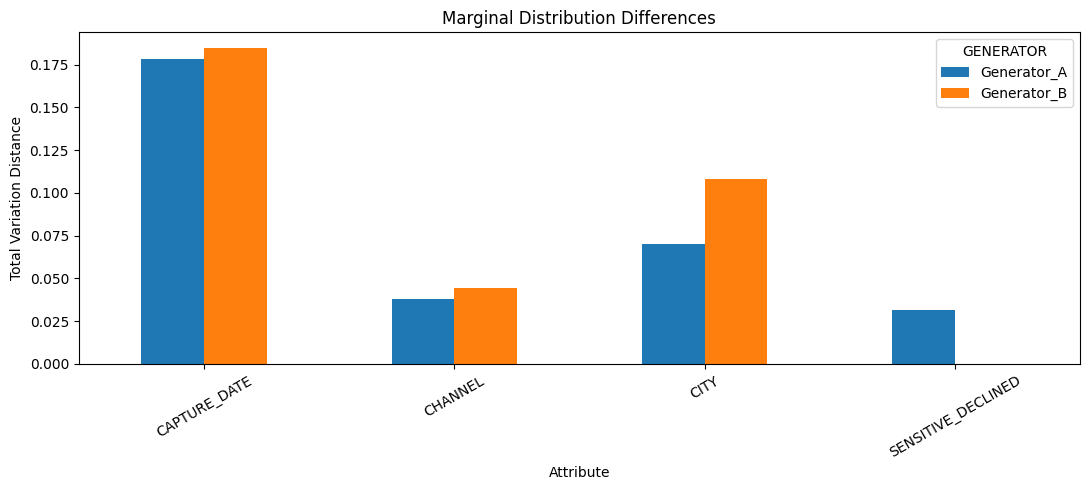

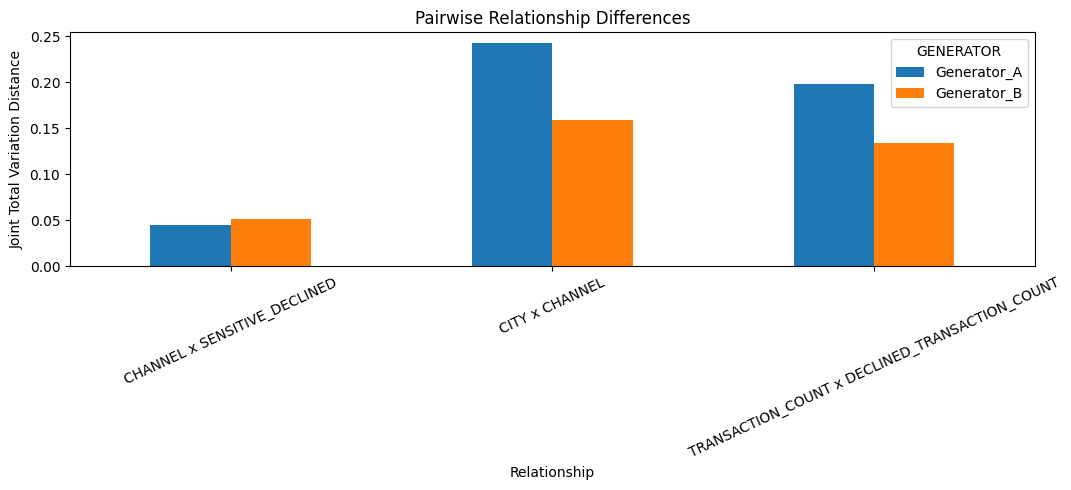


UTILITY EVALUATION EVIDENCE SAVED
Location: /content/mosipay_q1/output/Q4_Synthetic_Data/utility_evaluation

Files created:
Q4_Marginal_Categorical_TVD.csv
Q4_Marginal_TVD_Comparison.png
Q4_Numerical_Distribution_Comparison.csv
Q4_Pairwise_Dependency_Comparison.csv
Q4_Pairwise_TVD_Comparison.png


In [45]:
# ---------------------------------------------------------
# Q4(b): Marginal and Pairwise Utility Evaluation
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from pathlib import Path

# 1. Define datasets
datasets = {
    "Approved": approved_data,
    "Generator_A": synthetic_a,
    "Generator_B": synthetic_b
}

Q4_DIR = Path("/content/mosipay_q1/output/Q4_Synthetic_Data")
UTILITY_DIR = Q4_DIR / "utility_evaluation"
UTILITY_DIR.mkdir(parents=True, exist_ok=True)

# 2. Total Variation Distance for categorical distributions
def categorical_tvd(original, generated):
    categories = sorted(
        set(original.dropna().unique())
        | set(generated.dropna().unique())
    )

    p = original.value_counts(normalize=True).reindex(
        categories, fill_value=0
    )

    q = generated.value_counts(normalize=True).reindex(
        categories, fill_value=0
    )

    return 0.5 * np.abs(p - q).sum()


# 3. Total Variation Distance for joint distributions
def joint_tvd(original, generated, col1, col2):

    original_joint = pd.crosstab(
        original[col1], original[col2], normalize=True
    )

    generated_joint = pd.crosstab(
        generated[col1], generated[col2], normalize=True
    )

    all_rows = sorted(
        set(original_joint.index) | set(generated_joint.index)
    )

    all_columns = sorted(
        set(original_joint.columns) | set(generated_joint.columns)
    )

    original_joint = original_joint.reindex(
        index=all_rows, columns=all_columns, fill_value=0
    )

    generated_joint = generated_joint.reindex(
        index=all_rows, columns=all_columns, fill_value=0
    )

    return 0.5 * (
        original_joint - generated_joint
    ).abs().to_numpy().sum()


# ---------------------------------------------------------
# A. MARGINAL CATEGORICAL DISTRIBUTIONS
# ---------------------------------------------------------

categorical_columns = [
    "CITY",
    "CHANNEL",
    "CAPTURE_DATE",
    "SENSITIVE_DECLINED"
]

marginal_results = []

for dataset_name in ["Generator_A", "Generator_B"]:

    generated = datasets[dataset_name]

    for column in categorical_columns:

        tvd = categorical_tvd(
            approved_data[column],
            generated[column]
        )

        marginal_results.append({
            "GENERATOR": dataset_name,
            "ATTRIBUTE": column,
            "TVD": tvd
        })

marginal_report = pd.DataFrame(marginal_results)

print("MARGINAL CATEGORICAL DISTRIBUTION COMPARISON")
display(
    marginal_report.round(4)
)

marginal_report.to_csv(
    UTILITY_DIR / "Q4_Marginal_Categorical_TVD.csv",
    index=False
)


# ---------------------------------------------------------
# B. NUMERICAL DISTRIBUTION COMPARISON
# ---------------------------------------------------------

numerical_columns = [
    "MEDIAN_TRANSACTION_VALUE",
    "TRANSACTION_COUNT",
    "DECLINED_TRANSACTION_COUNT"
]

numerical_results = []

for dataset_name in ["Generator_A", "Generator_B"]:

    generated = datasets[dataset_name]

    for column in numerical_columns:

        original_values = approved_data[column].astype(float)
        generated_values = generated[column].astype(float)

        ks_result = ks_2samp(
            original_values,
            generated_values
        )

        original_mean = original_values.mean()
        generated_mean = generated_values.mean()

        numerical_results.append({
            "GENERATOR": dataset_name,
            "ATTRIBUTE": column,
            "APPROVED_MEAN": original_mean,
            "SYNTHETIC_MEAN": generated_mean,
            "MEAN_ABSOLUTE_DIFFERENCE": abs(
                original_mean - generated_mean
            ),
            "APPROVED_MEDIAN": original_values.median(),
            "SYNTHETIC_MEDIAN": generated_values.median(),
            "KS_STATISTIC": ks_result.statistic,
            "KS_P_VALUE": ks_result.pvalue
        })

numerical_report = pd.DataFrame(numerical_results)

print("\nNUMERICAL DISTRIBUTION COMPARISON")
display(numerical_report.round(4))

numerical_report.to_csv(
    UTILITY_DIR / "Q4_Numerical_Distribution_Comparison.csv",
    index=False
)


# ---------------------------------------------------------
# C. PAIRWISE DEPENDENCY COMPARISON
# ---------------------------------------------------------

pairwise_relationships = [
    ("CITY", "CHANNEL"),
    ("TRANSACTION_COUNT", "DECLINED_TRANSACTION_COUNT"),
    ("CHANNEL", "SENSITIVE_DECLINED")
]

pairwise_results = []

for dataset_name in ["Generator_A", "Generator_B"]:

    generated = datasets[dataset_name]

    for col1, col2 in pairwise_relationships:

        tvd = joint_tvd(
            approved_data,
            generated,
            col1,
            col2
        )

        pairwise_results.append({
            "GENERATOR": dataset_name,
            "RELATIONSHIP": f"{col1} x {col2}",
            "JOINT_TVD": tvd
        })

pairwise_report = pd.DataFrame(pairwise_results)

print("\nPAIRWISE DEPENDENCY COMPARISON")
display(pairwise_report.round(4))

pairwise_report.to_csv(
    UTILITY_DIR / "Q4_Pairwise_Dependency_Comparison.csv",
    index=False
)


# ---------------------------------------------------------
# D. PLOT MARGINAL CATEGORICAL TVD
# ---------------------------------------------------------

marginal_pivot = marginal_report.pivot(
    index="ATTRIBUTE",
    columns="GENERATOR",
    values="TVD"
)

ax = marginal_pivot.plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title("Marginal Distribution Differences")
ax.set_ylabel("Total Variation Distance")
ax.set_xlabel("Attribute")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()

plt.savefig(
    UTILITY_DIR / "Q4_Marginal_TVD_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ---------------------------------------------------------
# E. PLOT PAIRWISE DEPENDENCY TVD
# ---------------------------------------------------------

pairwise_pivot = pairwise_report.pivot(
    index="RELATIONSHIP",
    columns="GENERATOR",
    values="JOINT_TVD"
)

ax = pairwise_pivot.plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title("Pairwise Relationship Differences")
ax.set_ylabel("Joint Total Variation Distance")
ax.set_xlabel("Relationship")
ax.tick_params(axis="x", rotation=25)

plt.tight_layout()

plt.savefig(
    UTILITY_DIR / "Q4_Pairwise_TVD_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ---------------------------------------------------------
# F. SUMMARY
# ---------------------------------------------------------

print("\nUTILITY EVALUATION EVIDENCE SAVED")
print("Location:", UTILITY_DIR)

print("\nFiles created:")
for file in sorted(UTILITY_DIR.iterdir()):
    print(file.name)

In [46]:
# ---------------------------------------------------------
# Q4(b): Holdout classifier utility evaluation
# ---------------------------------------------------------

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Prepare predictor variables.
# Exclude DECLINED_TRANSACTION_COUNT because it directly
# determines the target SENSITIVE_DECLINED.

def prepare_classifier_features(data):

    X = data[
        [
            "CITY",
            "CHANNEL",
            "CAPTURE_DATE",
            "MEDIAN_TRANSACTION_VALUE",
            "TRANSACTION_COUNT"
        ]
    ].copy()

    dates = pd.to_datetime(
        X["CAPTURE_DATE"].astype(str),
        format="%Y%m%d",
        errors="coerce"
    )

    X["CAPTURE_MONTH"] = dates.dt.month
    X["CAPTURE_DAY"] = dates.dt.day

    X = X.drop(columns=["CAPTURE_DATE"])

    return X


# 2. Prepare the target.
y = approved_data["SENSITIVE_DECLINED"].astype(int)

# 3. Create one common stratified holdout.
X_original = prepare_classifier_features(approved_data)

X_train, X_test, y_train, y_test = train_test_split(
    X_original,
    y,
    test_size=0.30,
    random_state=2026,
    stratify=y
)

# 4. Define the preprocessing and classifier pipeline.
categorical_features = ["CITY", "CHANNEL"]
numerical_features = [
    "MEDIAN_TRANSACTION_VALUE",
    "TRANSACTION_COUNT",
    "CAPTURE_MONTH",
    "CAPTURE_DAY"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        ),
        (
            "numerical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_features
        )
    ]
)

def create_classifier():
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=2026
        ))
    ])


# 5. Prepare synthetic feature sets.
X_a = prepare_classifier_features(synthetic_a)
y_a = synthetic_a["SENSITIVE_DECLINED"].astype(int)

X_b = prepare_classifier_features(synthetic_b)
y_b = synthetic_b["SENSITIVE_DECLINED"].astype(int)

# 6. Train the three models.
models = {
    "Approved baseline": (X_train, y_train),
    "Generator A": (X_a, y_a),
    "Generator B": (X_b, y_b)
}

results = []

for model_name, (training_X, training_y) in models.items():

    classifier = create_classifier()

    classifier.fit(training_X, training_y)

    predictions = classifier.predict(X_test)
    probabilities = classifier.predict_proba(X_test)[:, 1]

    results.append({
        "MODEL": model_name,
        "TRAINING_RECORDS": len(training_X),
        "HOLDOUT_RECORDS": len(X_test),
        "ACCURACY": accuracy_score(y_test, predictions),
        "BALANCED_ACCURACY": balanced_accuracy_score(
            y_test, predictions
        ),
        "PRECISION": precision_score(
            y_test, predictions, zero_division=0
        ),
        "RECALL": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_SCORE": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, probabilities)
    })


# 7. Display the results.
classifier_results = pd.DataFrame(results)

print("HOLDOUT CLASSIFIER EVALUATION")
print("Training/test split: 70% / 30%")
print("Random seed: 2026")
print("Test records:", len(X_test))
print("Target distribution in test set:")
display(y_test.value_counts().rename("COUNT").to_frame())

display(
    classifier_results.round(4)
)

# 8. Save the evidence.
Q4_DIR = Path("/content/mosipay_q1/output/Q4_Synthetic_Data")
UTILITY_DIR = Q4_DIR / "utility_evaluation"
UTILITY_DIR.mkdir(parents=True, exist_ok=True)

classifier_results.to_csv(
    UTILITY_DIR / "Q4_Holdout_Classifier_Comparison.csv",
    index=False
)

print("Classifier evaluation evidence saved.")
print("Location:", UTILITY_DIR)

HOLDOUT CLASSIFIER EVALUATION
Training/test split: 70% / 30%
Random seed: 2026
Test records: 48
Target distribution in test set:


,COUNT
SENSITIVE_DECLINED,
1,28
0,20


,MODEL,TRAINING_RECORDS,HOLDOUT_RECORDS,ACCURACY,BALANCED_ACCURACY,PRECISION,RECALL,F1_SCORE,ROC_AUC
0,Approved baseline,109,48,0.5000,0.5071,0.5909,0.4643,0.5200,0.5446
1,Generator A,157,48,0.3958,0.3893,0.4800,0.4286,0.4528,0.3500
2,Generator B,157,48,0.6042,0.6107,0.6957,0.5714,0.6275,0.6893


Classifier evaluation evidence saved.
Location: /content/mosipay_q1/output/Q4_Synthetic_Data/utility_evaluation


In [47]:
# ---------------------------------------------------------
# Q4(c): Exact overlap and near-neighbour similarity
# ---------------------------------------------------------

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from scipy.spatial.distance import cdist
from pathlib import Path

# 1. Select comparison attributes.
comparison_columns = [
    "CITY",
    "CHANNEL",
    "CAPTURE_DATE",
    "MEDIAN_TRANSACTION_VALUE",
    "TRANSACTION_COUNT",
    "DECLINED_TRANSACTION_COUNT"
]

approved_compare = approved_data[
    comparison_columns
].copy().reset_index(drop=True)

generator_a_compare = synthetic_a[
    comparison_columns
].copy().reset_index(drop=True)

generator_b_compare = synthetic_b[
    comparison_columns
].copy().reset_index(drop=True)


# 2. Define a mixed-type distance function.
# Categorical mismatch = 1; match = 0.
# Numerical distance = absolute difference scaled by
# the approved dataset's observed range.

categorical_columns = [
    "CITY",
    "CHANNEL",
    "CAPTURE_DATE"
]

numerical_columns = [
    "MEDIAN_TRANSACTION_VALUE",
    "TRANSACTION_COUNT",
    "DECLINED_TRANSACTION_COUNT"
]

numeric_scaler = MinMaxScaler()

approved_numeric = numeric_scaler.fit_transform(
    approved_compare[numerical_columns]
)

a_numeric = numeric_scaler.transform(
    generator_a_compare[numerical_columns]
)

b_numeric = numeric_scaler.transform(
    generator_b_compare[numerical_columns]
)


def mixed_distance_matrix(synthetic_df, synthetic_numeric):

    distances = np.zeros(
        (len(synthetic_df), len(approved_compare))
    )

    # Categorical contribution
    for column in categorical_columns:
        mismatch = (
            synthetic_df[column].to_numpy()[:, None]
            != approved_compare[column].to_numpy()[None, :]
        ).astype(float)

        distances += mismatch

    # Numerical contribution
    numeric_distances = cdist(
        synthetic_numeric,
        approved_numeric,
        metric="cityblock"
    )

    distances += numeric_distances

    # Average over all six attributes
    distances /= (
        len(categorical_columns) +
        len(numerical_columns)
    )

    return distances


# 3. Calculate distance matrices.
distance_a = mixed_distance_matrix(
    generator_a_compare, a_numeric
)

distance_b = mixed_distance_matrix(
    generator_b_compare, b_numeric
)


# 4. Exact record overlap.
def exact_overlap(synthetic_df, approved_df):

    approved_signatures = set(
        map(
            tuple,
            approved_df.astype(str).to_numpy()
        )
    )

    synthetic_signatures = list(
        map(
            tuple,
            synthetic_df.astype(str).to_numpy()
        )
    )

    matched = [
        signature in approved_signatures
        for signature in synthetic_signatures
    ]

    return sum(matched), len(matched)


exact_a, total_a = exact_overlap(
    generator_a_compare, approved_compare
)

exact_b, total_b = exact_overlap(
    generator_b_compare, approved_compare
)


# 5. Nearest-neighbour distances.
nearest_a = distance_a.min(axis=1)
nearest_b = distance_b.min(axis=1)

privacy_similarity_report = pd.DataFrame([
    {
        "GENERATOR": "Generator A",
        "EXACT_MATCHES": exact_a,
        "EXACT_MATCH_RATE": exact_a / total_a,
        "MEAN_NEAREST_DISTANCE": nearest_a.mean(),
        "MEDIAN_NEAREST_DISTANCE": np.median(nearest_a),
        "MIN_NEAREST_DISTANCE": nearest_a.min(),
        "RECORDS_DISTANCE_ZERO": int((nearest_a == 0).sum()),
        "RECORDS_DISTANCE_BELOW_0_05": int((nearest_a < 0.05).sum())
    },
    {
        "GENERATOR": "Generator B",
        "EXACT_MATCHES": exact_b,
        "EXACT_MATCH_RATE": exact_b / total_b,
        "MEAN_NEAREST_DISTANCE": nearest_b.mean(),
        "MEDIAN_NEAREST_DISTANCE": np.median(nearest_b),
        "MIN_NEAREST_DISTANCE": nearest_b.min(),
        "RECORDS_DISTANCE_ZERO": int((nearest_b == 0).sum()),
        "RECORDS_DISTANCE_BELOW_0_05": int((nearest_b < 0.05).sum())
    }
])

print("EXACT OVERLAP AND NEAREST-NEIGHBOUR RESULTS")
display(privacy_similarity_report.round(4))


# 6. Save evidence.
Q4_DIR = Path("/content/mosipay_q1/output/Q4_Synthetic_Data")
PRIVACY_DIR = Q4_DIR / "privacy_evaluation"
PRIVACY_DIR.mkdir(parents=True, exist_ok=True)

privacy_similarity_report.to_csv(
    PRIVACY_DIR / "Q4_Exact_Overlap_Nearest_Neighbour.csv",
    index=False
)

print("Privacy similarity evidence saved.")
print("Location:", PRIVACY_DIR)

EXACT OVERLAP AND NEAREST-NEIGHBOUR RESULTS


,GENERATOR,EXACT_MATCHES,EXACT_MATCH_RATE,MEAN_NEAREST_DISTANCE,MEDIAN_NEAREST_DISTANCE,MIN_NEAREST_DISTANCE,RECORDS_DISTANCE_ZERO,RECORDS_DISTANCE_BELOW_0_05
0,Generator A,0,0.0,0.1852,0.1982,0.0007,0,8
1,Generator B,0,0.0,0.1781,0.1966,0.0052,0,10


Privacy similarity evidence saved.
Location: /content/mosipay_q1/output/Q4_Synthetic_Data/privacy_evaluation


In [48]:
# ---------------------------------------------------------
# Q4(c): Rare-pattern replication and auxiliary linkage
# ---------------------------------------------------------

import pandas as pd
import numpy as np
from pathlib import Path

# 1. Select the quasi-identifiers available to the attacker.
qi_columns = ["CITY", "CAPTURE_DATE", "CHANNEL"]

original_qi = approved_data[qi_columns].astype(str).copy()
a_qi = synthetic_a[qi_columns].astype(str).copy()
b_qi = synthetic_b[qi_columns].astype(str).copy()

# 2. Identify rare combinations in the approved data.
original_patterns = (
    original_qi
    .value_counts()
    .rename("ORIGINAL_FREQUENCY")
    .reset_index()
)

rare_patterns = original_patterns[
    original_patterns["ORIGINAL_FREQUENCY"] <= 2
].copy()

rare_pattern_set = set(
    map(
        tuple,
        rare_patterns[qi_columns].to_numpy()
    )
)

# 3. Count how often each generator reproduces rare patterns.
def assess_rare_replication(synthetic_qi, generator_name):

    synthetic_patterns = (
        synthetic_qi
        .value_counts()
        .rename("SYNTHETIC_FREQUENCY")
        .reset_index()
    )

    synthetic_pattern_set = set(
        map(
            tuple,
            synthetic_patterns[qi_columns].to_numpy()
        )
    )

    replicated_patterns = rare_pattern_set.intersection(
        synthetic_pattern_set
    )

    synthetic_is_rare = synthetic_qi.apply(
        lambda row: tuple(row) in rare_pattern_set,
        axis=1
    )

    return {
        "GENERATOR": generator_name,
        "ORIGINAL_RARE_PATTERN_COUNT": len(rare_pattern_set),
        "RARE_PATTERNS_REPLICATED": len(replicated_patterns),
        "PERCENT_RARE_PATTERNS_REPLICATED": (
            len(replicated_patterns) / len(rare_pattern_set) * 100
            if rare_pattern_set else 0
        ),
        "SYNTHETIC_RECORDS_MATCHING_RARE_PATTERNS": int(
            synthetic_is_rare.sum()
        ),
        "SYNTHETIC_RARE_RECORD_PERCENTAGE": (
            synthetic_is_rare.mean() * 100
        )
    }

rare_pattern_results = pd.DataFrame([
    assess_rare_replication(a_qi, "Generator A"),
    assess_rare_replication(b_qi, "Generator B")
])

print("RARE-PATTERN REPLICATION RESULTS")
display(rare_pattern_results.round(2))


# 4. Auxiliary linkage simulation.
# Assume an attacker knows the target's city, date and channel.
# Count matching records in each synthetic dataset.

def linkage_attack(original, synthetic, generator_name):

    synthetic_counts = (
        synthetic
        .value_counts()
        .to_dict()
    )

    detail = original.copy()

    detail["SYNTHETIC_CANDIDATE_COUNT"] = [
        synthetic_counts.get(tuple(row), 0)
        for row in original.to_numpy()
    ]

    detail["LINKAGE_OUTCOME"] = np.select(
        [
            detail["SYNTHETIC_CANDIDATE_COUNT"] == 0,
            detail["SYNTHETIC_CANDIDATE_COUNT"] == 1,
            detail["SYNTHETIC_CANDIDATE_COUNT"] > 1
        ],
        [
            "No candidate",
            "Unique candidate",
            "Multiple candidates"
        ],
        default="Unclassified"
    )

    outcome_counts = (
        detail["LINKAGE_OUTCOME"]
        .value_counts()
        .reindex(
            ["No candidate", "Unique candidate", "Multiple candidates"],
            fill_value=0
        )
    )

    summary = {
        "GENERATOR": generator_name,
        "TARGETS_TESTED": len(detail),
        "NO_CANDIDATE": int(outcome_counts["No candidate"]),
        "UNIQUE_CANDIDATE": int(outcome_counts["Unique candidate"]),
        "MULTIPLE_CANDIDATES": int(outcome_counts["Multiple candidates"]),
        "UNIQUE_CANDIDATE_PERCENTAGE": (
            outcome_counts["Unique candidate"] / len(detail) * 100
        )
    }

    return summary, detail


link_a_summary, link_a_detail = linkage_attack(
    original_qi, a_qi, "Generator A"
)

link_b_summary, link_b_detail = linkage_attack(
    original_qi, b_qi, "Generator B"
)

linkage_results = pd.DataFrame([
    link_a_summary,
    link_b_summary
])

print("\nAUXILIARY LINKAGE SIMULATION RESULTS")
display(linkage_results.round(2))


# 5. Inspect rare patterns and linkage examples.
print("\nRARE COMBINATIONS IN APPROVED DATA")
display(
    rare_patterns.sort_values(
        ["ORIGINAL_FREQUENCY"] + qi_columns
    ).head(20)
)

print("\nGENERATOR A - LINKAGE OUTCOME EXAMPLES")
display(link_a_detail.head(10))

print("\nGENERATOR B - LINKAGE OUTCOME EXAMPLES")
display(link_b_detail.head(10))


# 6. Save evidence.
Q4_DIR = Path("/content/mosipay_q1/output/Q4_Synthetic_Data")
PRIVACY_DIR = Q4_DIR / "privacy_evaluation"
PRIVACY_DIR.mkdir(parents=True, exist_ok=True)

rare_pattern_results.to_csv(
    PRIVACY_DIR / "Q4_Rare_Pattern_Replication.csv",
    index=False
)

linkage_results.to_csv(
    PRIVACY_DIR / "Q4_Auxiliary_Linkage_Summary.csv",
    index=False
)

link_a_detail.to_csv(
    PRIVACY_DIR / "Q4_Generator_A_Linkage_Detail.csv",
    index=False
)

link_b_detail.to_csv(
    PRIVACY_DIR / "Q4_Generator_B_Linkage_Detail.csv",
    index=False
)

rare_patterns.to_csv(
    PRIVACY_DIR / "Q4_Original_Rare_Patterns.csv",
    index=False
)

print("\nRED-TEAM EVIDENCE SAVED")
print("Location:", PRIVACY_DIR)

RARE-PATTERN REPLICATION RESULTS


,GENERATOR,ORIGINAL_RARE_PATTERN_COUNT,RARE_PATTERNS_REPLICATED,PERCENT_RARE_PATTERNS_REPLICATED,SYNTHETIC_RECORDS_MATCHING_RARE_PATTERNS,SYNTHETIC_RARE_RECORD_PERCENTAGE
0,Generator A,129,28,21.71,36,22.93
1,Generator B,129,35,27.13,45,28.66



AUXILIARY LINKAGE SIMULATION RESULTS


,GENERATOR,TARGETS_TESTED,NO_CANDIDATE,UNIQUE_CANDIDATE,MULTIPLE_CANDIDATES,UNIQUE_CANDIDATE_PERCENTAGE
0,Generator A,157,112,35,10,22.29
1,Generator B,157,107,34,16,21.66



RARE COMBINATIONS IN APPROVED DATA


,CITY,CAPTURE_DATE,CHANNEL,ORIGINAL_FREQUENCY
20,Bloemfontein,20260902,POS,1
23,Bloemfontein,20260903,POS,1
22,Bloemfontein,20260905,ATM,1
21,Bloemfontein,20260906,ATM,1
67,Bloemfontein,20260906,ECOM,1
68,Bloemfontein,20260909,ATM,1
34,Bloemfontein,20260909,ECOM,1
26,Bloemfontein,20260910,ATM,1
36,Bloemfontein,20260911,POS,1
35,Bloemfontein,20260913,ATM,1



GENERATOR A - LINKAGE OUTCOME EXAMPLES


,CITY,CAPTURE_DATE,CHANNEL,SYNTHETIC_CANDIDATE_COUNT,LINKAGE_OUTCOME
0,Bloemfontein,20260914,ATM,1,Unique candidate
1,East London,20260912,ATM,1,Unique candidate
2,Johannesburg,20260903,ATM,1,Unique candidate
3,Gqeberha,20261009,ECOM,0,No candidate
4,Johannesburg,20260915,ECOM,1,Unique candidate
5,Johannesburg,20260912,ATM,1,Unique candidate
6,Johannesburg,20260903,POS,0,No candidate
7,Gqeberha,20260911,ATM,0,No candidate
8,Cape Town,20261001,ATM,0,No candidate
9,Johannesburg,20261001,ATM,0,No candidate



GENERATOR B - LINKAGE OUTCOME EXAMPLES


,CITY,CAPTURE_DATE,CHANNEL,SYNTHETIC_CANDIDATE_COUNT,LINKAGE_OUTCOME
0,Bloemfontein,20260914,ATM,1,Unique candidate
1,East London,20260912,ATM,1,Unique candidate
2,Johannesburg,20260903,ATM,1,Unique candidate
3,Gqeberha,20261009,ECOM,0,No candidate
4,Johannesburg,20260915,ECOM,1,Unique candidate
5,Johannesburg,20260912,ATM,0,No candidate
6,Johannesburg,20260903,POS,1,Unique candidate
7,Gqeberha,20260911,ATM,1,Unique candidate
8,Cape Town,20261001,ATM,0,No candidate
9,Johannesburg,20261001,ATM,0,No candidate



RED-TEAM EVIDENCE SAVED
Location: /content/mosipay_q1/output/Q4_Synthetic_Data/privacy_evaluation


In [49]:
# ---------------------------------------------------------
# Q4(c): Attribute-inference red-team experiment
# ---------------------------------------------------------

def attribute_inference_attack(
    original_data,
    synthetic_data,
    generator_name
):
    qi = ["CITY", "CAPTURE_DATE", "CHANNEL"]

    # Create a lookup from quasi-identifiers to synthetic labels.
    lookup = (
        synthetic_data
        .groupby(qi)["SENSITIVE_DECLINED"]
        .agg(list)
        .to_dict()
    )

    results = []

    for _, target in original_data.iterrows():

        key = tuple(str(target[col]) for col in qi)
        candidates = lookup.get(key, [])

        if len(candidates) == 0:
            outcome = "No candidate"
            inferred_label = np.nan

        elif len(candidates) == 1:
            outcome = "Unique candidate"
            inferred_label = int(candidates[0])

        else:
            outcome = "Multiple candidates"

            # Majority vote among matching synthetic records.
            # In a tie, use the overall synthetic majority.
            counts = pd.Series(candidates).value_counts()

            if counts.nunique() == 1:
                inferred_label = int(
                    synthetic_data["SENSITIVE_DECLINED"].mode()[0]
                )
            else:
                inferred_label = int(counts.idxmax())

        results.append({
            "ACTUAL_SENSITIVE_DECLINED": int(
                target["SENSITIVE_DECLINED"]
            ),
            "CANDIDATE_COUNT": len(candidates),
            "LINKAGE_OUTCOME": outcome,
            "INFERRED_SENSITIVE_DECLINED": inferred_label
        })

    detail = pd.DataFrame(results)

    # Evaluate unique matches separately.
    unique = detail[
        detail["LINKAGE_OUTCOME"] == "Unique candidate"
    ]

    multiple = detail[
        detail["LINKAGE_OUTCOME"] == "Multiple candidates"
    ]

    matched = detail[
        detail["CANDIDATE_COUNT"] > 0
    ].copy()

    summary = {
        "GENERATOR": generator_name,
        "TARGETS_TESTED": len(detail),
        "UNIQUE_MATCHES": len(unique),
        "UNIQUE_MATCH_INFERENCE_ACCURACY": (
            (
                unique["ACTUAL_SENSITIVE_DECLINED"]
                == unique["INFERRED_SENSITIVE_DECLINED"]
            ).mean()
            if len(unique) else np.nan
        ),
        "MULTIPLE_MATCHES": len(multiple),
        "MULTIPLE_MATCH_MAJORITY_ACCURACY": (
            (
                multiple["ACTUAL_SENSITIVE_DECLINED"]
                == multiple["INFERRED_SENSITIVE_DECLINED"]
            ).mean()
            if len(multiple) else np.nan
        ),
        "ALL_MATCHABLE_TARGETS": len(matched),
        "MATCHABLE_TARGET_INFERENCE_ACCURACY": (
            (
                matched["ACTUAL_SENSITIVE_DECLINED"]
                == matched["INFERRED_SENSITIVE_DECLINED"]
            ).mean()
            if len(matched) else np.nan
        ),
        "MATCH_COVERAGE_PERCENTAGE": (
            len(matched) / len(detail) * 100
        )
    }

    return summary, detail


# Run the attack against both generators.
inference_a_summary, inference_a_detail = (
    attribute_inference_attack(
        approved_data,
        synthetic_a,
        "Generator A"
    )
)

inference_b_summary, inference_b_detail = (
    attribute_inference_attack(
        approved_data,
        synthetic_b,
        "Generator B"
    )
)

attribute_inference_results = pd.DataFrame([
    inference_a_summary,
    inference_b_summary
])

print("ATTRIBUTE-INFERENCE ATTACK RESULTS")
display(attribute_inference_results.round(4))


# Save evidence.
PRIVACY_DIR = Path(
    "/content/mosipay_q1/output/Q4_Synthetic_Data/privacy_evaluation"
)

attribute_inference_results.to_csv(
    PRIVACY_DIR / "Q4_Attribute_Inference_Summary.csv",
    index=False
)

inference_a_detail.to_csv(
    PRIVACY_DIR / "Q4_Generator_A_Attribute_Inference_Detail.csv",
    index=False
)

inference_b_detail.to_csv(
    PRIVACY_DIR / "Q4_Generator_B_Attribute_Inference_Detail.csv",
    index=False
)

print("Attribute-inference evidence saved.")
print("Location:", PRIVACY_DIR)

ATTRIBUTE-INFERENCE ATTACK RESULTS


,GENERATOR,TARGETS_TESTED,UNIQUE_MATCHES,UNIQUE_MATCH_INFERENCE_ACCURACY,MULTIPLE_MATCHES,MULTIPLE_MATCH_MAJORITY_ACCURACY,ALL_MATCHABLE_TARGETS,MATCHABLE_TARGET_INFERENCE_ACCURACY,MATCH_COVERAGE_PERCENTAGE
0,Generator A,157,35,0.6000,10,0.600,45,0.6,28.6624
1,Generator B,157,34,0.4706,16,0.875,50,0.6,31.8471


Attribute-inference evidence saved.
Location: /content/mosipay_q1/output/Q4_Synthetic_Data/privacy_evaluation


In [50]:

# =========================================================
# Q4(d): CONDITIONAL RELEASE - GENERATOR B
# =========================================================

import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path("/content/mosipay_q1/output/Q4_Synthetic_Data")
INPUT_FILE = BASE_DIR / "generator_B" / "Q4_Generator_B_Synthetic_Data.csv"
RELEASE_DIR = BASE_DIR / "conditional_release"
RELEASE_DIR.mkdir(parents=True, exist_ok=True)

K_THRESHOLD = 5


def minimum_class_size(dataframe, quasi_identifiers):
    """Return the smallest equivalence-class size for the supplied QIs."""
    missing_columns = [
        column for column in quasi_identifiers
        if column not in dataframe.columns
    ]
    if missing_columns:
        raise ValueError(
            f"Quasi-identifier columns are missing: {missing_columns}"
        )

    class_sizes = dataframe.groupby(
        quasi_identifiers,
        dropna=False
    ).size()

    if class_sizes.empty:
        raise ValueError("Cannot calculate k for an empty release dataset.")

    return int(class_sizes.min())


# Positive and negative tests for the class-size function.
_test_classes = pd.DataFrame({
    "QI": ["A", "A", "B", "B", "B"]
})
assert minimum_class_size(_test_classes, ["QI"]) == 2
try:
    minimum_class_size(_test_classes, ["MISSING_QI"])
except ValueError:
    pass
else:
    raise AssertionError("Missing-QI negative test did not reject input.")

print("Q4(d) minimum-class-size function tests: PASSED")

# 1. Load Generator B.
release_source = pd.read_csv(INPUT_FILE)

required = [
    "CITY",
    "CAPTURE_DATE",
    "CHANNEL",
    "MEDIAN_TRANSACTION_VALUE",
    "TRANSACTION_COUNT",
    "SENSITIVE_DECLINED"
]

missing = [c for c in required if c not in release_source.columns]
if missing:
    raise ValueError(f"Required columns missing: {missing}")

release_source = release_source[required].copy()

# 2. Validate the sensitive target.
release_source["SENSITIVE_DECLINED"] = pd.to_numeric(
    release_source["SENSITIVE_DECLINED"], errors="raise"
).astype(int)

if not release_source["SENSITIVE_DECLINED"].isin([0, 1]).all():
    raise ValueError("Sensitive target contains values other than 0 and 1.")

# 3. Generalise exact dates to months.
parsed_dates = pd.to_datetime(
    release_source["CAPTURE_DATE"].astype(str),
    format="%Y%m%d",
    errors="coerce"
)

if parsed_dates.isna().any():
    raise ValueError("Some capture dates could not be parsed.")

release_source["RELEASE_DATE"] = parsed_dates.dt.strftime("%Y-%m")

# 4. Generalise transaction values into five bands.
# Boundaries are learned from the approved analytic table.
value_edges = np.unique(
    np.quantile(
        pd.to_numeric(
            approved_data["MEDIAN_TRANSACTION_VALUE"]
        ),
        np.linspace(0, 1, 6)
    )
)

if len(value_edges) < 3:
    raise ValueError("Insufficient distinct value boundaries.")

value_edges[0] = -np.inf
value_edges[-1] = np.inf

release_source["VALUE_BAND"] = pd.cut(
    pd.to_numeric(release_source["MEDIAN_TRANSACTION_VALUE"]),
    bins=value_edges,
    labels=False,
    include_lowest=True
).astype(int).astype(str)

release_source["VALUE_BAND"] = (
    "Band_" + release_source["VALUE_BAND"]
)
# Generalise transaction count into three categories.
release_source["TRANSACTION_COUNT_BAND"] = pd.cut(
    pd.to_numeric(release_source["TRANSACTION_COUNT"]),
    bins=[-np.inf, 1, 3, np.inf],
    labels=["1", "2-3", "4+"]
).astype(str)

# 5. Start with city, month, channel and value band.
release_source["RELEASE_CITY"] = (
    release_source["CITY"].astype(str)
)

release_source["RELEASE_CHANNEL"] = (
    release_source["CHANNEL"].astype(str)
)

qi = [
    "RELEASE_CITY",
    "RELEASE_DATE",
    "RELEASE_CHANNEL",
    "VALUE_BAND",
    "TRANSACTION_COUNT_BAND"
]


# ---------------------------------------------------------
# 6–7. Stronger generalisation to achieve k >= 5
# ---------------------------------------------------------

# Generalise city completely.
release_source["RELEASE_CITY"] = "ALL_CITIES"

# Generalise value completely.
release_source["VALUE_BAND"] = "ALL_VALUES"

# Generalise transaction count completely.
release_source["TRANSACTION_COUNT_BAND"] = "ALL_COUNTS"

# Retain month and channel initially.
# These remain useful for dashboard comparisons.
qi = [
    "RELEASE_CITY",
    "RELEASE_DATE",
    "RELEASE_CHANNEL",
    "VALUE_BAND",
    "TRANSACTION_COUNT_BAND"
]

minimum_k = minimum_class_size(release_source, qi)

date_policy = "Month"
city_policy = "All cities"
channel_policy = "Exact channel"
value_policy = "All values"
transaction_count_policy = "All transaction counts"

# If any class is still too small, generalise channel.
if minimum_k < K_THRESHOLD:

    release_source["RELEASE_CHANNEL"] = "ALL_CHANNELS"
    channel_policy = "All channels"

    minimum_k = minimum_class_size(release_source, qi)

# If still necessary, generalise month to year.
if minimum_k < K_THRESHOLD:

    date_dt = pd.to_datetime(
        release_source["RELEASE_DATE"] + "-01"
    )

    release_source["RELEASE_DATE"] = (
        date_dt.dt.to_period("Y").astype(str)
    )

    date_policy = "Year"

    minimum_k = minimum_class_size(release_source, qi)

# Final release safeguard.
if minimum_k < K_THRESHOLD:
    raise ValueError(
        f"Release blocked: minimum class size is {minimum_k}, "
        f"below required k={K_THRESHOLD}."
    )

print("GENERALISATION POLICY")
print("City:", city_policy)
print("Date:", date_policy)
print("Channel:", channel_policy)
print("Value:", value_policy)
print("Transaction count:", transaction_count_policy)
print("Minimum k:", minimum_k)

# 8. Construct the dashboard dataset.
dashboard_columns = [
    "RELEASE_CITY",
    "RELEASE_DATE",
    "RELEASE_CHANNEL",
    "VALUE_BAND",
    "TRANSACTION_COUNT_BAND"
]

dashboard_release = release_source[
    dashboard_columns
].copy()

# 9. Construct the restricted classifier dataset.
# Deliberately exclude DECLINED_TRANSACTION_COUNT because
# it directly determines SENSITIVE_DECLINED.
classifier_columns = dashboard_columns + [
    "SENSITIVE_DECLINED"
]

classifier_release = release_source[
    classifier_columns
].copy()

# 10. Final disclosure-control checks.
for name, dataset in [
    ("Dashboard", dashboard_release),
    ("Classifier", classifier_release)
]:
    assert len(dataset) == len(release_source)
    assert not dataset.isna().any().any()

    forbidden = {
        "ACCOUNT_REF", "ACCT1", "ACCT_NO", "HPAN",
        "REFNUM", "DECLINED_TRANSACTION_COUNT",
        "CAPTURE_DATE"
    }

    assert not forbidden.intersection(dataset.columns)

# Recheck equivalence classes on the actual released fields.
final_qi = [
    "RELEASE_CITY",
    "RELEASE_DATE",
    "RELEASE_CHANNEL",
    "VALUE_BAND",
    "TRANSACTION_COUNT_BAND"
]

final_class_sizes = (
    classifier_release.groupby(final_qi, dropna=False)
    .size()
)

assert final_class_sizes.min() >= K_THRESHOLD

# 11. Save both datasets.
dashboard_path = (
    RELEASE_DIR / "Q4_Conditional_Dashboard_Release.csv"
)

classifier_path = (
    RELEASE_DIR / "Q4_Restricted_Classifier_Release.csv"
)

dashboard_release.to_csv(dashboard_path, index=False)
classifier_release.to_csv(classifier_path, index=False)

# 12. Save release manifest and class-size evidence.
manifest = pd.DataFrame([
    {
        "RELEASE_FILE": dashboard_path.name,
        "PURPOSE": "Dashboard logic and visualisation testing",
        "RECORDS": len(dashboard_release),
        "SENSITIVE_TARGET_INCLUDED": "No",
        "K_THRESHOLD": K_THRESHOLD,
        "OBSERVED_MINIMUM_K": int(final_class_sizes.min())
    },
    {
        "RELEASE_FILE": classifier_path.name,
        "PURPOSE": "Restricted supervised classifier testing",
        "RECORDS": len(classifier_release),
        "SENSITIVE_TARGET_INCLUDED": "Yes - restricted",
        "K_THRESHOLD": K_THRESHOLD,
        "OBSERVED_MINIMUM_K": int(final_class_sizes.min())
    }
])

manifest["DATE_POLICY"] = date_policy
manifest["CITY_POLICY"] = city_policy
manifest["CHANNEL_POLICY"] = channel_policy
manifest["VALUE_POLICY"] = value_policy
manifest["TRANSACTION_COUNT_POLICY"] = transaction_count_policy

manifest.to_csv(
    RELEASE_DIR / "Q4_Conditional_Release_Manifest.csv",
    index=False
)

final_class_sizes.rename(
    "CLASS_SIZE"
).reset_index().to_csv(
    RELEASE_DIR / "Q4_Conditional_Release_Class_Sizes.csv",
    index=False
)

print("CONDITIONAL RELEASE COMPLETED")
print("----------------------------------------")
print("Dashboard file:", dashboard_path)
print("Restricted classifier file:", classifier_path)
print("Release manifest:", RELEASE_DIR / "Q4_Conditional_Release_Manifest.csv")
print("Records released:", len(release_source))
print("Minimum equivalence-class size:", int(final_class_sizes.min()))
print("Number of equivalence classes:", len(final_class_sizes))
print("Date policy:", date_policy)
print("City policy:", city_policy)
print("Value policy:", value_policy)
print("Transaction count policy:", transaction_count_policy)
print("----------------------------------------")

display(manifest)
display(final_class_sizes.describe().to_frame("CLASS_SIZE_SUMMARY"))

Q4(d) minimum-class-size function tests: PASSED
GENERALISATION POLICY
City: All cities
Date: Month
Channel: Exact channel
Value: All values
Transaction count: All transaction counts
Minimum k: 6
CONDITIONAL RELEASE COMPLETED
----------------------------------------
Dashboard file: /content/mosipay_q1/output/Q4_Synthetic_Data/conditional_release/Q4_Conditional_Dashboard_Release.csv
Restricted classifier file: /content/mosipay_q1/output/Q4_Synthetic_Data/conditional_release/Q4_Restricted_Classifier_Release.csv
Release manifest: /content/mosipay_q1/output/Q4_Synthetic_Data/conditional_release/Q4_Conditional_Release_Manifest.csv
Records released: 157
Minimum equivalence-class size: 6
Number of equivalence classes: 6
Date policy: Month
City policy: All cities
Value policy: All values
Transaction count policy: All transaction counts
----------------------------------------


,RELEASE_FILE,PURPOSE,RECORDS,SENSITIVE_TARGET_INCLUDED,K_THRESHOLD,OBSERVED_MINIMUM_K,DATE_POLICY,CITY_POLICY,CHANNEL_POLICY,VALUE_POLICY,TRANSACTION_COUNT_POLICY
0,Q4_Conditional_Dashboard_Release.csv,Dashboard logic and visualisation testing,157,No,5,6,Month,All cities,Exact channel,All values,All transaction counts
1,Q4_Restricted_Classifier_Release.csv,Restricted supervised classifier testing,157,Yes - restricted,5,6,Month,All cities,Exact channel,All values,All transaction counts


,CLASS_SIZE_SUMMARY
count,6.000000
mean,26.166667
std,23.430038
min,6.000000
25%,7.750000
50%,22.000000
75%,34.000000
max,66.000000


In [51]:
from pathlib import Path
import pandas as pd

release_dir = Path(
    "/content/mosipay_q1/output/Q4_Synthetic_Data/conditional_release"
)

dashboard = pd.read_csv(
    release_dir / "Q4_Conditional_Dashboard_Release.csv"
)

classifier = pd.read_csv(
    release_dir / "Q4_Restricted_Classifier_Release.csv"
)

manifest = pd.read_csv(
    release_dir / "Q4_Conditional_Release_Manifest.csv"
)

print("DASHBOARD RELEASE COLUMNS")
print(dashboard.columns.tolist())

print("\nCLASSIFIER RELEASE COLUMNS")
print(classifier.columns.tolist())

print("\nRECORD COUNTS")
print("Dashboard:", len(dashboard))
print("Classifier:", len(classifier))

print("\nSENSITIVE TARGET CHECK")
print(
    "Dashboard contains sensitive target:",
    "SENSITIVE_DECLINED" in dashboard.columns
)
print(
    "Classifier contains sensitive target:",
    "SENSITIVE_DECLINED" in classifier.columns
)

print("\nMISSING VALUE CHECK")
print("Dashboard missing values:", dashboard.isna().sum().sum())
print("Classifier missing values:", classifier.isna().sum().sum())

print("\nMANIFEST")
display(manifest)

assert len(dashboard) == 157
assert len(classifier) == 157
assert "SENSITIVE_DECLINED" not in dashboard.columns
assert "SENSITIVE_DECLINED" in classifier.columns
assert dashboard.isna().sum().sum() == 0
assert classifier.isna().sum().sum() == 0

print("\nALL FINAL RELEASE CHECKS PASSED.")

DASHBOARD RELEASE COLUMNS
['RELEASE_CITY', 'RELEASE_DATE', 'RELEASE_CHANNEL', 'VALUE_BAND', 'TRANSACTION_COUNT_BAND']

CLASSIFIER RELEASE COLUMNS
['RELEASE_CITY', 'RELEASE_DATE', 'RELEASE_CHANNEL', 'VALUE_BAND', 'TRANSACTION_COUNT_BAND', 'SENSITIVE_DECLINED']

RECORD COUNTS
Dashboard: 157
Classifier: 157

SENSITIVE TARGET CHECK
Dashboard contains sensitive target: False
Classifier contains sensitive target: True

MISSING VALUE CHECK
Dashboard missing values: 0
Classifier missing values: 0

MANIFEST


,RELEASE_FILE,PURPOSE,RECORDS,SENSITIVE_TARGET_INCLUDED,K_THRESHOLD,OBSERVED_MINIMUM_K,DATE_POLICY,CITY_POLICY,CHANNEL_POLICY,VALUE_POLICY,TRANSACTION_COUNT_POLICY
0,Q4_Conditional_Dashboard_Release.csv,Dashboard logic and visualisation testing,157,No,5,6,Month,All cities,Exact channel,All values,All transaction counts
1,Q4_Restricted_Classifier_Release.csv,Restricted supervised classifier testing,157,Yes - restricted,5,6,Month,All cities,Exact channel,All values,All transaction counts



ALL FINAL RELEASE CHECKS PASSED.


In [52]:

# =========================================================
# PRESERVE QUESTION 4 ASSESSMENT EVIDENCE
# =========================================================

from pathlib import Path
from datetime import datetime
import zipfile
import hashlib
import json

# 1. Define source and backup locations.
source_dir = Path(
    "/content/mosipay_q1/output/Q4_Synthetic_Data"
)

backup_dir = Path(
    "/content/mosipay_q1/output/Assessment_Backups"
)

backup_dir.mkdir(parents=True, exist_ok=True)

# 2. Confirm the evidence directory exists.
if not source_dir.exists():
    raise FileNotFoundError(
        f"Evidence directory not found: {source_dir}"
    )

# 3. Create a uniquely named archive.
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

archive_path = (
    backup_dir /
    f"Q4_Assessment_Evidence_{timestamp}.zip"
)

if archive_path.exists():
    raise FileExistsError(
        "Backup already exists. No file was overwritten."
    )

# 4. Collect all files in the evidence directory.
evidence_files = sorted(
    p for p in source_dir.rglob("*")
    if p.is_file()
)

if not evidence_files:
    raise ValueError("No evidence files found.")

# 5. Create the ZIP archive.
with zipfile.ZipFile(
    archive_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file_path in evidence_files:
        archive.write(
            file_path,
            arcname=file_path.relative_to(source_dir.parent)
        )

# 6. Calculate archive checksum.
sha256 = hashlib.sha256(
    archive_path.read_bytes()
).hexdigest()

# 7. Create a backup inventory.
inventory = {
    "backup_created": timestamp,
    "source_directory": str(source_dir),
    "archive": str(archive_path),
    "number_of_files": len(evidence_files),
    "archive_size_bytes": archive_path.stat().st_size,
    "sha256": sha256,
    "files": [
        str(p.relative_to(source_dir))
        for p in evidence_files
    ]
}

inventory_path = (
    backup_dir /
    f"Q4_Assessment_Evidence_{timestamp}_inventory.json"
)

with open(inventory_path, "w") as f:
    json.dump(inventory, f, indent=4)

# 8. Verify archive integrity.
with zipfile.ZipFile(archive_path, "r") as archive:
    integrity = archive.testzip()

if integrity is not None:
    raise RuntimeError(
        f"Archive verification failed: {integrity}"
    )

print("QUESTION 4 EVIDENCE PRESERVED")
print("--------------------------------------")
print("Files archived:", len(evidence_files))
print("Archive:", archive_path)
print("Inventory:", inventory_path)
print("Archive size:", archive_path.stat().st_size, "bytes")
print("SHA-256:", sha256)
print("ZIP integrity:", "PASSED")
print("--------------------------------------")

QUESTION 4 EVIDENCE PRESERVED
--------------------------------------
Files archived: 23
Archive: /content/mosipay_q1/output/Assessment_Backups/Q4_Assessment_Evidence_20261123_140542.zip
Inventory: /content/mosipay_q1/output/Assessment_Backups/Q4_Assessment_Evidence_20261123_140542_inventory.json
Archive size: 317645 bytes
SHA-256: d642e644fd881b18753288f1edcda07d47d44ef6b2760611c64ac4f895d667c3
ZIP integrity: PASSED
--------------------------------------


## Optional: Download the Q4 evidence archive

The Q4 archive is created by the preceding evidence-preservation cell. Downloading is a manual, optional action and is deliberately excluded from the clean Run all sequence. After the notebook has completed, run this in a separate Colab cell if a local copy is required:

```python
from google.colab import files
files.download(str(archive_path))
```


In [53]:
import hashlib
from pathlib import Path

original_file = Path(
    "/content/mosipay_q1/input/"
    "Synthetic_TymeBank_Host_Data_500_Rows.csv"
)

current_hash = hashlib.sha256(
    original_file.read_bytes()
).hexdigest()

expected_hash = (
    "3db5ef0eecb1a4d8cd163c47d7858815778a9d8c094ffffbf7bbe93984161ed3"
)

print("Original dataset exists:", original_file.exists())
print("Original SHA-256:", current_hash)
print("Original dataset unchanged:", current_hash == expected_hash)

assert current_hash == expected_hash, (
    "The original dataset hash does not match."
)

Original dataset exists: True
Original SHA-256: 3db5ef0eecb1a4d8cd163c47d7858815778a9d8c094ffffbf7bbe93984161ed3
Original dataset unchanged: True


In [54]:

# =========================================================
# Q5: INSPECT THE APPROVED ACCOUNT-LEVEL DATASET
# =========================================================

from pathlib import Path
import pandas as pd

account_file = Path(
    "/content/mosipay_q1/output/"
    "Q3_Deidentification/restricted/"
    "Q3_Account_Level_Analysis.csv"
)

# Check whether the approved dataset exists.
if not account_file.exists():
    raise FileNotFoundError(
        f"Approved account-level dataset not found: {account_file}"
    )

# Load the approved account-level dataset.
account_df = pd.read_csv(account_file)

# Inspect its structure.
print("QUESTION 5: APPROVED ACCOUNT-LEVEL DATA")
print("=" * 55)

print("File:", account_file)
print("Number of account records:", len(account_df))
print("Number of columns:", len(account_df.columns))

print("\nCOLUMN NAMES")
print(account_df.columns.tolist())

print("\nFIRST FIVE RECORDS")
display(account_df.head())

print("\nDATA TYPES")
display(account_df.dtypes.to_frame("Data type"))

print("\nMISSING VALUES")
display(
    account_df.isnull().sum().to_frame("Missing values")
)

print("\nDUPLICATE ROWS")
print(account_df.duplicated().sum())

print("\nDATASET SHAPE")
print(account_df.shape)

QUESTION 5: APPROVED ACCOUNT-LEVEL DATA
File: /content/mosipay_q1/output/Q3_Deidentification/restricted/Q3_Account_Level_Analysis.csv
Number of account records: 157
Number of columns: 8

COLUMN NAMES
['ACCOUNT_REF', 'CITY', 'CAPTURE_DATE', 'MEDIAN_TRANSACTION_VALUE', 'CHANNEL', 'TRANSACTION_COUNT', 'DECLINED_TRANSACTION_COUNT', 'SENSITIVE_DECLINED']

FIRST FIVE RECORDS


,ACCOUNT_REF,CITY,CAPTURE_DATE,MEDIAN_TRANSACTION_VALUE,CHANNEL,TRANSACTION_COUNT,DECLINED_TRANSACTION_COUNT,SENSITIVE_DECLINED
0,99000000001,Bloemfontein,20260914,32499.5,ATM,4,3,1
1,99000000002,East London,20260912,84788.5,ATM,2,0,0
2,99000000003,Johannesburg,20260903,5999.0,ATM,3,0,0
3,99000000004,Gqeberha,20261009,9848.5,ECOM,2,0,0
4,99000000005,Johannesburg,20260915,90113.0,ECOM,7,2,1



DATA TYPES


,Data type
ACCOUNT_REF,int64
CITY,object
CAPTURE_DATE,int64
MEDIAN_TRANSACTION_VALUE,float64
CHANNEL,object
TRANSACTION_COUNT,int64
DECLINED_TRANSACTION_COUNT,int64
SENSITIVE_DECLINED,int64



MISSING VALUES


,Missing values
ACCOUNT_REF,0
CITY,0
CAPTURE_DATE,0
MEDIAN_TRANSACTION_VALUE,0
CHANNEL,0
TRANSACTION_COUNT,0
DECLINED_TRANSACTION_COUNT,0
SENSITIVE_DECLINED,0



DUPLICATE ROWS
0

DATASET SHAPE
(157, 8)


In [55]:

# =========================================================
# Q5(a): ACCOUNT UNIQUENESS AND CONTRIBUTION VALIDATION
# =========================================================

import pandas as pd

# 1. Confirm one row per account.
account_count = len(account_df)
unique_accounts = account_df["ACCOUNT_REF"].nunique()

print("ACCOUNT UNIQUENESS")
print("------------------------------")
print("Total rows:", account_count)
print("Distinct account references:", unique_accounts)
print("One row per account:", account_count == unique_accounts)

# 2. Inspect numerical contribution attributes.
numeric_columns = [
    "MEDIAN_TRANSACTION_VALUE",
    "TRANSACTION_COUNT",
    "DECLINED_TRANSACTION_COUNT"
]

print("\nNUMERICAL ATTRIBUTE RANGES")
print("------------------------------")

display(
    account_df[numeric_columns].describe().T
)

# 3. Check logical contribution constraints.
print("\nCONTRIBUTION VALIDATION")
print("------------------------------")

checks = {
    "Transaction count non-negative": (
        account_df["TRANSACTION_COUNT"] >= 0
    ).all(),

    "Declined count non-negative": (
        account_df["DECLINED_TRANSACTION_COUNT"] >= 0
    ).all(),

    "Declined count does not exceed transaction count": (
        account_df["DECLINED_TRANSACTION_COUNT"]
        <= account_df["TRANSACTION_COUNT"]
    ).all(),

    "Transaction value non-negative": (
        account_df["MEDIAN_TRANSACTION_VALUE"] >= 0
    ).all(),

    "Sensitive label is binary": (
        account_df["SENSITIVE_DECLINED"].isin([0, 1])
    ).all(),

    "Sensitive label agrees with declined count": (
        account_df["SENSITIVE_DECLINED"]
        == (
            account_df["DECLINED_TRANSACTION_COUNT"] > 0
        ).astype(int)
    ).all()
}

for description, passed in checks.items():
    print(f"{description}: {passed}")

# 4. Display observed maximums for internal analysis.
print("\nOBSERVED MAXIMUMS")
print("------------------------------")

for column in numeric_columns:
    print(column, "=", account_df[column].max())

# 5. Stop if the account-level assumptions are not satisfied.
assert account_count == unique_accounts, (
    "Multiple rows per account detected. "
    "Resolve account-level contribution structure first."
)

assert all(checks.values()), (
    "One or more contribution validation checks failed."
)

print("\nACCOUNT-LEVEL VALIDATION PASSED.")

ACCOUNT UNIQUENESS
------------------------------
Total rows: 157
Distinct account references: 157
One row per account: True

NUMERICAL ATTRIBUTE RANGES
------------------------------


,count,mean,std,min,25%,50%,75%,max
MEDIAN_TRANSACTION_VALUE,157.0,36696.484076,31451.418826,499.0,11000.0,26684.0,52999.5,129253.0
TRANSACTION_COUNT,157.0,3.184713,1.608557,1.0,2.0,3.0,4.0,9.0
DECLINED_TRANSACTION_COUNT,157.0,0.834395,0.890456,0.0,0.0,1.0,1.0,5.0



CONTRIBUTION VALIDATION
------------------------------
Transaction count non-negative: True
Declined count non-negative: True
Declined count does not exceed transaction count: True
Transaction value non-negative: True
Sensitive label is binary: True
Sensitive label agrees with declined count: True

OBSERVED MAXIMUMS
------------------------------
MEDIAN_TRANSACTION_VALUE = 129253.0
TRANSACTION_COUNT = 9
DECLINED_TRANSACTION_COUNT = 5

ACCOUNT-LEVEL VALIDATION PASSED.


In [56]:

# =========================================================
# Q5(a): DEFINE AND SAVE THE CONTRIBUTION POLICY
# =========================================================

from pathlib import Path
import pandas as pd
import json

# Create an independent Question 5 evidence directory.
q5_root = Path(
    "/content/mosipay_q1/output/Q5_Differential_Privacy"
)

subdirectories = [
    "01_Query_Definitions",
    "02_DP_Release",
    "03_Privacy_Budget_Ledger",
    "04_Accuracy_Evaluation",
    "05_Counterfactual_Tests",
    "06_Plots",
    "07_Final_Reports"
]

for folder in subdirectories:
    (q5_root / folder).mkdir(
        parents=True,
        exist_ok=True
    )

# Fixed policy assumptions for this exercise.
contribution_policy = {
    "NEIGHBOURING_DATASET": "Add/remove one account",
    "PRIVACY_UNIT": "One account",
    "ACCOUNT_CONTRIBUTION": "One account-level record",
    "COUNT_CONTRIBUTION_BOUND": 1,
    "VALUE_ATTRIBUTE": "MEDIAN_TRANSACTION_VALUE",
    "VALUE_CLIPPING_LOWER": 0,
    "VALUE_CLIPPING_UPPER": 150000,
    "TRANSACTION_COUNT_CLIPPING": [0, 10],
    "DECLINED_COUNT_CLIPPING": [0, 10],
    "SENSITIVE_DECLINED_DOMAIN": [0, 1],
    "VALUE_BOUND_STATUS": (
        "Fixed exercise policy assumption; "
        "requires independent approval for real deployment"
    ),
    "SOURCE_DATASET": (
        "Q3_Account_Level_Analysis.csv"
    ),
    "SOURCE_RECORDS": int(len(account_df)),
    "DISTINCT_ACCOUNTS": int(
        account_df["ACCOUNT_REF"].nunique()
    )
}

# Save JSON policy.
policy_json = (
    q5_root /
    "01_Query_Definitions" /
    "Q5_Contribution_Policy.json"
)

with open(policy_json, "w") as file:
    json.dump(
        contribution_policy,
        file,
        indent=4
    )

# Save a readable CSV version.
policy_csv = (
    q5_root /
    "01_Query_Definitions" /
    "Q5_Contribution_Policy.csv"
)

policy_table = pd.DataFrame(
    contribution_policy.items(),
    columns=["POLICY_PARAMETER", "SELECTED_VALUE"]
)

policy_table.to_csv(
    policy_csv,
    index=False
)

print("QUESTION 5 CONTRIBUTION POLICY SAVED")
print("--------------------------------------")
print("Evidence directory:", q5_root)
print("JSON:", policy_json)
print("CSV:", policy_csv)
print("Account records:", len(account_df))
print("Distinct accounts:", account_df["ACCOUNT_REF"].nunique())
print("Value clipping interval: [0, 150000]")
print("--------------------------------------")

display(policy_table)

QUESTION 5 CONTRIBUTION POLICY SAVED
--------------------------------------
Evidence directory: /content/mosipay_q1/output/Q5_Differential_Privacy
JSON: /content/mosipay_q1/output/Q5_Differential_Privacy/01_Query_Definitions/Q5_Contribution_Policy.json
CSV: /content/mosipay_q1/output/Q5_Differential_Privacy/01_Query_Definitions/Q5_Contribution_Policy.csv
Account records: 157
Distinct accounts: 157
Value clipping interval: [0, 150000]
--------------------------------------


,POLICY_PARAMETER,SELECTED_VALUE
0,NEIGHBOURING_DATASET,Add/remove one account
1,PRIVACY_UNIT,One account
2,ACCOUNT_CONTRIBUTION,One account-level record
3,COUNT_CONTRIBUTION_BOUND,1
4,VALUE_ATTRIBUTE,MEDIAN_TRANSACTION_VALUE
5,VALUE_CLIPPING_LOWER,0
6,VALUE_CLIPPING_UPPER,150000
7,TRANSACTION_COUNT_CLIPPING,"[0, 10]"
8,DECLINED_COUNT_CLIPPING,"[0, 10]"
9,SENSITIVE_DECLINED_DOMAIN,"[0, 1]"


In [57]:

# =========================================================
# Q5(b): LAPACE AND GAUSSIAN DIFFERENTIAL PRIVACY
# =========================================================

import numpy as np
import pandas as pd
import json
from pathlib import Path

# ---------------------------------------------------------
# 1. Configuration
# ---------------------------------------------------------

LOWER_BOUND = 0.0
UPPER_BOUND = 150000.0

EPSILON_COUNT = 0.60
EPSILON_SUM = 0.60

EPSILON_GAUSSIAN = 0.60
DELTA_GAUSSIAN = 1e-5

RANDOM_SEED = 5105

release_dir = q5_root / "02_DP_Release"
evaluation_dir = q5_root / "04_Accuracy_Evaluation"

release_dir.mkdir(parents=True, exist_ok=True)
evaluation_dir.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(RANDOM_SEED)

# ---------------------------------------------------------
# 2. Prepare account-level contributions
# ---------------------------------------------------------

# Verify that the privacy unit remains one account per row.
assert account_df["ACCOUNT_REF"].is_unique

# Distinct account count.
true_count = int(account_df["ACCOUNT_REF"].nunique())

# Clip each account's median transaction value.
clipped_values = np.clip(
    account_df["MEDIAN_TRANSACTION_VALUE"].to_numpy(
        dtype=float
    ),
    LOWER_BOUND,
    UPPER_BOUND
)

# Calculate the internal true sum and mean.
true_sum = float(clipped_values.sum())

true_mean = (
    true_sum / true_count
    if true_count > 0
    else 0.0
)

# ---------------------------------------------------------
# 3. Laplace mechanism: distinct-account count
# ---------------------------------------------------------

count_sensitivity = 1.0

count_scale = (
    count_sensitivity / EPSILON_COUNT
)

noisy_count_raw = (
    true_count +
    rng.laplace(
        loc=0.0,
        scale=count_scale
    )
)

# Post-processing: count cannot be negative.
noisy_count = max(
    0,
    int(round(noisy_count_raw))
)

# ---------------------------------------------------------
# 4. Laplace mechanism: bounded account-level sum
# ---------------------------------------------------------

sum_sensitivity = UPPER_BOUND

sum_scale = (
    sum_sensitivity / EPSILON_SUM
)

noisy_sum_raw = (
    true_sum +
    rng.laplace(
        loc=0.0,
        scale=sum_scale
    )
)

# Post-processing: sum cannot be negative.
noisy_sum = max(
    0.0,
    float(noisy_sum_raw)
)

# ---------------------------------------------------------
# 5. Privacy-aware mean using existing noisy outputs
# ---------------------------------------------------------

# Reuse the same noisy count and noisy sum.
# Do not draw additional noise for the mean.

DENOMINATOR_THRESHOLD = 1.0

if noisy_count_raw < DENOMINATOR_THRESHOLD:
    private_mean = None
    mean_status = "SUPPRESSED: noisy denominator too small"
else:
    private_mean = float(
        np.clip(
            noisy_sum_raw / noisy_count_raw,
            LOWER_BOUND,
            UPPER_BOUND
        )
    )
    mean_status = "RELEASED: post-processed noisy ratio"

# ---------------------------------------------------------
# 6. Gaussian alternative for bounded sum
# ---------------------------------------------------------

gaussian_sensitivity = UPPER_BOUND

gaussian_sigma = (
    gaussian_sensitivity *
    np.sqrt(
        2 * np.log(1.25 / DELTA_GAUSSIAN)
    ) /
    EPSILON_GAUSSIAN
)

gaussian_noisy_sum = (
    true_sum +
    rng.normal(
        loc=0.0,
        scale=gaussian_sigma
    )
)

# This is for internal evaluation only.
# It is NOT included in the three-statistic release.
gaussian_internal_sum = max(
    0.0,
    float(gaussian_noisy_sum)
)

# ---------------------------------------------------------
# 7. Construct the three-statistic private release
# ---------------------------------------------------------

release_records = [
    {
        "STATISTIC": "Distinct account count",
        "PRIVATE_VALUE": noisy_count,
        "UNIT": "accounts",
        "MECHANISM": "Laplace",
        "EPSILON_COST": EPSILON_COUNT,
        "DELTA_COST": 0.0
    },
    {
        "STATISTIC": "Bounded sum of account median values",
        "PRIVATE_VALUE": noisy_sum,
        "UNIT": "currency units",
        "MECHANISM": "Laplace",
        "EPSILON_COST": EPSILON_SUM,
        "DELTA_COST": 0.0
    },
    {
        "STATISTIC": "Bounded mean of account median values",
        "PRIVATE_VALUE": private_mean,
        "UNIT": "currency units",
        "MECHANISM": "Post-processing of private count and sum",
        "EPSILON_COST": 0.0,
        "DELTA_COST": 0.0
    }
]

dp_release = pd.DataFrame(release_records)

# ---------------------------------------------------------
# 8. Save public release separately from internal evidence
# ---------------------------------------------------------

release_path = (
    release_dir /
    "Q5_Private_Aggregate_Release.csv"
)

dp_release.to_csv(
    release_path,
    index=False
)

# Internal evaluation values must not be sent to the association.
internal_truth = pd.DataFrame([
    {
        "INTERNAL_METRIC": "True distinct account count",
        "INTERNAL_VALUE": true_count
    },
    {
        "INTERNAL_METRIC": "True clipped account-level sum",
        "INTERNAL_VALUE": true_sum
    },
    {
        "INTERNAL_METRIC": "True clipped account-level mean",
        "INTERNAL_VALUE": true_mean
    }
])

internal_truth_path = (
    evaluation_dir /
    "Q5_Internal_True_Statistics.csv"
)

internal_truth.to_csv(
    internal_truth_path,
    index=False
)

gaussian_evidence = pd.DataFrame([
    {
        "MECHANISM": "Gaussian bounded sum",
        "INTERNAL_NOISY_VALUE": gaussian_internal_sum,
        "EPSILON": EPSILON_GAUSSIAN,
        "DELTA": DELTA_GAUSSIAN,
        "SENSITIVITY_L2": gaussian_sensitivity,
        "NOISE_STANDARD_DEVIATION": gaussian_sigma,
        "PUBLICATION_STATUS": "INTERNAL EVALUATION ONLY"
    }
])

gaussian_path = (
    evaluation_dir /
    "Q5_Gaussian_Internal_Evaluation.csv"
)

gaussian_evidence.to_csv(
    gaussian_path,
    index=False
)

# ---------------------------------------------------------
# 9. Save mechanism configuration
# ---------------------------------------------------------

mechanism_config = {
    "PRIVACY_UNIT": "One account",
    "ADJACENCY": "Add/remove one account",
    "VALUE_CLIPPING": [LOWER_BOUND, UPPER_BOUND],
    "COUNT_EPSILON": EPSILON_COUNT,
    "COUNT_SENSITIVITY": count_sensitivity,
    "COUNT_LAPLACE_SCALE": count_scale,
    "SUM_EPSILON": EPSILON_SUM,
    "SUM_SENSITIVITY": sum_sensitivity,
    "SUM_LAPLACE_SCALE": sum_scale,
    "MEAN_METHOD": "Noisy sum divided by noisy count",
    "MEAN_ADDITIONAL_EPSILON": 0.0,
    "MEAN_DENOMINATOR_THRESHOLD": DENOMINATOR_THRESHOLD,
    "GAUSSIAN_EPSILON": EPSILON_GAUSSIAN,
    "GAUSSIAN_DELTA": DELTA_GAUSSIAN,
    "GAUSSIAN_SENSITIVITY_L2": gaussian_sensitivity,
    "GAUSSIAN_STANDARD_DEVIATION": gaussian_sigma,
    "GAUSSIAN_PUBLICATION_STATUS": "Internal evaluation only",
    "RANDOM_SEED": RANDOM_SEED,
    "RANDOM_SEED_WARNING": (
        "For reproducibility only; not a privacy guarantee. "
        "Production requires securely generated independent noise."
    )
}

config_path = (
    release_dir /
    "Q5_Mechanism_Configuration.json"
)

with open(config_path, "w") as file:
    json.dump(
        mechanism_config,
        file,
        indent=4
    )

# ---------------------------------------------------------
# 10. Display evidence
# ---------------------------------------------------------

print("QUESTION 5(b): MECHANISM IMPLEMENTATION")
print("=" * 60)

print("\nSENSITIVITY AND NOISE CALIBRATION")
print("--------------------------------------")
print("Count sensitivity:", count_sensitivity)
print("Count Laplace scale:", count_scale)
print("Sum sensitivity:", sum_sensitivity)
print("Sum Laplace scale:", sum_scale)
print("Gaussian sensitivity:", gaussian_sensitivity)
print("Gaussian standard deviation:", gaussian_sigma)

print("\nPRIVATE AGGREGATE RELEASE")
print("--------------------------------------")
display(dp_release)

print("\nMEAN STATUS")
print(mean_status)

print("\nGAUSSIAN ALTERNATIVE")
print("--------------------------------------")
display(gaussian_evidence)

print("\nEVIDENCE FILES")
print("--------------------------------------")
print("Private release:", release_path)
print("Internal true statistics:", internal_truth_path)
print("Gaussian internal evaluation:", gaussian_path)
print("Configuration:", config_path)

print("\nMECHANISM IMPLEMENTATION COMPLETED.")

QUESTION 5(b): MECHANISM IMPLEMENTATION

SENSITIVITY AND NOISE CALIBRATION
--------------------------------------
Count sensitivity: 1.0
Count Laplace scale: 1.6666666666666667
Sum sensitivity: 150000.0
Sum Laplace scale: 250000.0
Gaussian sensitivity: 150000.0
Gaussian standard deviation: 1211201.3156513472

PRIVATE AGGREGATE RELEASE
--------------------------------------


,STATISTIC,PRIVATE_VALUE,UNIT,MECHANISM,EPSILON_COST,DELTA_COST
0,Distinct account count,1.580000e+02,accounts,Laplace,0.6,0.0
1,Bounded sum of account median values,5.311988e+06,currency units,Laplace,0.6,0.0
2,Bounded mean of account median values,3.351922e+04,currency units,Post-processing of private count and sum,0.0,0.0



MEAN STATUS
RELEASED: post-processed noisy ratio

GAUSSIAN ALTERNATIVE
--------------------------------------


,MECHANISM,INTERNAL_NOISY_VALUE,EPSILON,DELTA,SENSITIVITY_L2,NOISE_STANDARD_DEVIATION,PUBLICATION_STATUS
0,Gaussian bounded sum,5.423931e+06,0.6,0.00001,150000.0,1.211201e+06,INTERNAL EVALUATION ONLY



EVIDENCE FILES
--------------------------------------
Private release: /content/mosipay_q1/output/Q5_Differential_Privacy/02_DP_Release/Q5_Private_Aggregate_Release.csv
Internal true statistics: /content/mosipay_q1/output/Q5_Differential_Privacy/04_Accuracy_Evaluation/Q5_Internal_True_Statistics.csv
Gaussian internal evaluation: /content/mosipay_q1/output/Q5_Differential_Privacy/04_Accuracy_Evaluation/Q5_Gaussian_Internal_Evaluation.csv
Configuration: /content/mosipay_q1/output/Q5_Differential_Privacy/02_DP_Release/Q5_Mechanism_Configuration.json

MECHANISM IMPLEMENTATION COMPLETED.


In [58]:

# =========================================================
# Q5(b): ENSURE THE PUBLISHED MEAN IS CONSISTENT
# =========================================================

# Derive the mean from the exact values in the release table.
if noisy_count < DENOMINATOR_THRESHOLD:
    private_mean = None
    mean_status = "SUPPRESSED: noisy denominator too small"
else:
    private_mean = float(
        np.clip(
            noisy_sum / noisy_count,
            LOWER_BOUND,
            UPPER_BOUND
        )
    )
    mean_status = "RELEASED: ratio of published noisy sum and count"

# Update the mean in the release table.
dp_release.loc[
    dp_release["STATISTIC"]
    == "Bounded mean of account median values",
    "PRIVATE_VALUE"
] = private_mean

# Save the corrected release.
dp_release.to_csv(
    release_path,
    index=False
)

print("CORRECTED PRIVATE AGGREGATE RELEASE")
print("--------------------------------------")
display(dp_release)

print("\nMEAN CONSISTENCY CHECK")
print("--------------------------------------")

if private_mean is not None:
    calculated_mean = noisy_sum / noisy_count

    print("Published noisy sum:", noisy_sum)
    print("Published noisy count:", noisy_count)
    print("Published mean:", private_mean)
    print("Sum divided by count:", calculated_mean)
    print(
        "Mean consistency:",
        np.isclose(private_mean, calculated_mean)
    )

print("\nMean status:", mean_status)
print("Corrected release saved:", release_path)

assert (
    private_mean is None
    or np.isclose(private_mean, noisy_sum / noisy_count)
)

print("\nMEAN CONSISTENCY VERIFICATION PASSED.")

CORRECTED PRIVATE AGGREGATE RELEASE
--------------------------------------


,STATISTIC,PRIVATE_VALUE,UNIT,MECHANISM,EPSILON_COST,DELTA_COST
0,Distinct account count,1.580000e+02,accounts,Laplace,0.6,0.0
1,Bounded sum of account median values,5.311988e+06,currency units,Laplace,0.6,0.0
2,Bounded mean of account median values,3.362018e+04,currency units,Post-processing of private count and sum,0.0,0.0



MEAN CONSISTENCY CHECK
--------------------------------------
Published noisy sum: 5311988.150394933
Published noisy count: 158
Published mean: 33620.17816705654
Sum divided by count: 33620.17816705654
Mean consistency: True

Mean status: RELEASED: ratio of published noisy sum and count
Corrected release saved: /content/mosipay_q1/output/Q5_Differential_Privacy/02_DP_Release/Q5_Private_Aggregate_Release.csv

MEAN CONSISTENCY VERIFICATION PASSED.


In [59]:

# =========================================================
# Q5(c): EXECUTABLE DIFFERENTIAL-PRIVACY BUDGET LEDGER
# =========================================================

from pathlib import Path
import pandas as pd
import json

# ---------------------------------------------------------
# 1. Define total privacy-budget ceiling
# ---------------------------------------------------------

EPSILON_CEILING = 2.0
DELTA_CEILING = 1e-5

ledger_dir = (
    q5_root /
    "03_Privacy_Budget_Ledger"
)

ledger_dir.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# 2. Create privacy-budget accountant
# ---------------------------------------------------------

class PrivacyBudgetLedger:

    def __init__(self, epsilon_limit, delta_limit):

        self.epsilon_limit = float(epsilon_limit)
        self.delta_limit = float(delta_limit)

        self.entries = []

        self.epsilon_used = 0.0
        self.delta_used = 0.0

    def reserve(
        self,
        mechanism,
        epsilon,
        delta,
        status,
        description
    ):

        epsilon = float(epsilon)
        delta = float(delta)

        if epsilon < 0 or delta < 0:
            raise ValueError(
                "Privacy costs cannot be negative."
            )

        proposed_epsilon = (
            self.epsilon_used + epsilon
        )

        proposed_delta = (
            self.delta_used + delta
        )

        # Check the budget BEFORE accepting the query.
        if (
            proposed_epsilon > self.epsilon_limit
            or
            proposed_delta > self.delta_limit
        ):

            rejection = {
                "MECHANISM": mechanism,
                "EPSILON_REQUESTED": epsilon,
                "DELTA_REQUESTED": delta,
                "STATUS": "REJECTED",
                "REASON": (
                    "Privacy-budget ceiling would be exceeded."
                ),
                "EPSILON_USED_BEFORE": self.epsilon_used,
                "DELTA_USED_BEFORE": self.delta_used
            }

            self.entries.append(rejection)

            return False

        # Reserve the budget only after successful validation.
        self.epsilon_used = proposed_epsilon
        self.delta_used = proposed_delta

        accepted = {
            "MECHANISM": mechanism,
            "EPSILON_REQUESTED": epsilon,
            "DELTA_REQUESTED": delta,
            "STATUS": status,
            "REASON": description,
            "EPSILON_USED_BEFORE": (
                self.epsilon_used - epsilon
            ),
            "DELTA_USED_BEFORE": (
                self.delta_used - delta
            )
        }

        self.entries.append(accepted)

        return True

    def summary(self):

        return {
            "COMPOSITION_RULE": "Basic sequential composition",
            "EPSILON_CEILING": self.epsilon_limit,
            "DELTA_CEILING": self.delta_limit,
            "EPSILON_USED": self.epsilon_used,
            "DELTA_USED": self.delta_used,
            "EPSILON_REMAINING": (
                self.epsilon_limit - self.epsilon_used
            ),
            "DELTA_REMAINING": (
                self.delta_limit - self.delta_used
            ),
            "BUDGET_WITHIN_LIMIT": (
                self.epsilon_used <= self.epsilon_limit
                and
                self.delta_used <= self.delta_limit
            )
        }


# ---------------------------------------------------------
# 3. Initialise the ledger
# ---------------------------------------------------------

ledger = PrivacyBudgetLedger(
    epsilon_limit=EPSILON_CEILING,
    delta_limit=DELTA_CEILING
)

# ---------------------------------------------------------
# 4. Reserve the actual mechanism costs
# ---------------------------------------------------------

reservations = [

    {
        "name": "Laplace distinct-account count",
        "epsilon": 0.60,
        "delta": 0.0,
        "status": "PUBLISHED",
        "description": "Private account count"
    },

    {
        "name": "Laplace bounded account-value sum",
        "epsilon": 0.60,
        "delta": 0.0,
        "status": "PUBLISHED",
        "description": "Private clipped account-level sum"
    },

    {
        "name": "Noisy bounded mean",
        "epsilon": 0.0,
        "delta": 0.0,
        "status": "POST-PROCESSING",
        "description": (
            "Derived from the already protected noisy sum "
            "and noisy count; no additional budget."
        )
    },

    {
        "name": "Gaussian bounded-sum alternative",
        "epsilon": 0.60,
        "delta": 1e-5,
        "status": "INTERNAL EVALUATION ONLY",
        "description": (
            "Conservatively reserved even though "
            "the Gaussian result is not published."
        )
    }
]

for item in reservations:

    accepted = ledger.reserve(
        mechanism=item["name"],
        epsilon=item["epsilon"],
        delta=item["delta"],
        status=item["status"],
        description=item["description"]
    )

    if not accepted:
        raise RuntimeError(
            "An intended mechanism could not be reserved."
        )

# ---------------------------------------------------------
# 5. Test an intentionally excessive query
# ---------------------------------------------------------

print("EXCESSIVE QUERY REJECTION TEST")
print("--------------------------------------")

epsilon_before = ledger.epsilon_used
delta_before = ledger.delta_used

# This request would increase epsilon from 1.8 to 2.3.
excessive_accepted = ledger.reserve(
    mechanism="INTENTIONALLY EXCESSIVE QUERY",
    epsilon=0.50,
    delta=0.0,
    status="TEST ONLY",
    description=(
        "Must be rejected before noise generation "
        "or result release."
    )
)

print("Excessive query accepted:", excessive_accepted)
print("Expected result: False")

# Confirm that rejection did not change the budget.
assert excessive_accepted is False

assert ledger.epsilon_used == epsilon_before
assert ledger.delta_used == delta_before

print("Budget unchanged after rejection:", True)

# ---------------------------------------------------------
# 6. Save ledger and composition summary
# ---------------------------------------------------------

ledger_df = pd.DataFrame(ledger.entries)

summary = ledger.summary()

ledger_csv = (
    ledger_dir /
    "Q5_Privacy_Budget_Ledger.csv"
)

ledger_json = (
    ledger_dir /
    "Q5_Privacy_Budget_Summary.json"
)

ledger_df.to_csv(
    ledger_csv,
    index=False
)

with open(ledger_json, "w") as file:
    json.dump(
        summary,
        file,
        indent=4
    )

# ---------------------------------------------------------
# 7. Display final evidence
# ---------------------------------------------------------

print("\nPRIVACY-BUDGET LEDGER")
print("=" * 65)

display(ledger_df)

print("\nCOMPOSITION SUMMARY")
print("--------------------------------------")

for key, value in summary.items():
    print(f"{key}: {value}")

print("\nEVIDENCE FILES")
print("--------------------------------------")
print("Ledger:", ledger_csv)
print("Summary:", ledger_json)


# ---------------------------------------------------------
# 8. Final assertions – floating-point safe
# ---------------------------------------------------------

import math

assert summary["BUDGET_WITHIN_LIMIT"] is True

assert math.isclose(
    ledger.epsilon_used,
    1.80,
    rel_tol=0.0,
    abs_tol=1e-12
)

assert math.isclose(
    ledger.delta_used,
    1e-5,
    rel_tol=0.0,
    abs_tol=1e-12
)

assert any(
    entry["STATUS"] == "REJECTED"
    for entry in ledger.entries
)

print("\nALL PRIVACY-BUDGET TESTS PASSED.")

EXCESSIVE QUERY REJECTION TEST
--------------------------------------
Excessive query accepted: False
Expected result: False
Budget unchanged after rejection: True

PRIVACY-BUDGET LEDGER


,MECHANISM,EPSILON_REQUESTED,DELTA_REQUESTED,STATUS,REASON,EPSILON_USED_BEFORE,DELTA_USED_BEFORE
0,Laplace distinct-account count,0.6,0.00000,PUBLISHED,Private account count,0.0,0.00000
1,Laplace bounded account-value sum,0.6,0.00000,PUBLISHED,Private clipped account-level sum,0.6,0.00000
2,Noisy bounded mean,0.0,0.00000,POST-PROCESSING,Derived from the already protected noisy sum a...,1.2,0.00000
3,Gaussian bounded-sum alternative,0.6,0.00001,INTERNAL EVALUATION ONLY,Conservatively reserved even though the Gaussi...,1.2,0.00000
4,INTENTIONALLY EXCESSIVE QUERY,0.5,0.00000,REJECTED,Privacy-budget ceiling would be exceeded.,1.8,0.00001



COMPOSITION SUMMARY
--------------------------------------
COMPOSITION_RULE: Basic sequential composition
EPSILON_CEILING: 2.0
DELTA_CEILING: 1e-05
EPSILON_USED: 1.7999999999999998
DELTA_USED: 1e-05
EPSILON_REMAINING: 0.20000000000000018
DELTA_REMAINING: 0.0
BUDGET_WITHIN_LIMIT: True

EVIDENCE FILES
--------------------------------------
Ledger: /content/mosipay_q1/output/Q5_Differential_Privacy/03_Privacy_Budget_Ledger/Q5_Privacy_Budget_Ledger.csv
Summary: /content/mosipay_q1/output/Q5_Differential_Privacy/03_Privacy_Budget_Ledger/Q5_Privacy_Budget_Summary.json

ALL PRIVACY-BUDGET TESTS PASSED.


In [60]:

# =========================================================
# Q5(c): FLOATING-POINT SAFE FINAL VERIFICATION
# =========================================================

import math

# Verify the composition totals using numerical tolerance.
assert math.isclose(
    ledger.epsilon_used,
    1.80,
    rel_tol=1e-12,
    abs_tol=1e-12
)

assert math.isclose(
    ledger.delta_used,
    1e-5,
    rel_tol=1e-12,
    abs_tol=1e-12
)

# Verify the budget ceilings.
assert ledger.epsilon_used <= EPSILON_CEILING + 1e-12
assert ledger.delta_used <= DELTA_CEILING + 1e-12

# Verify the rejection test.
rejected_entries = [
    entry for entry in ledger.entries
    if entry["STATUS"] == "REJECTED"
]

assert len(rejected_entries) >= 1

# Verify rejection did not consume budget.
assert math.isclose(
    ledger.epsilon_used,
    1.80,
    abs_tol=1e-12
)

assert math.isclose(
    ledger.delta_used,
    1e-5,
    abs_tol=1e-12
)

print("QUESTION 5(c): FINAL VERIFICATION")
print("--------------------------------------")
print("Epsilon used:", ledger.epsilon_used)
print("Epsilon ceiling:", EPSILON_CEILING)
print("Delta used:", ledger.delta_used)
print("Delta ceiling:", DELTA_CEILING)
print("Excessive query rejected:", True)
print("Budget unchanged after rejection:", True)
print("Basic sequential composition:", True)
print("Budget within limits:", True)
print("--------------------------------------")
print("ALL PRIVACY-BUDGET TESTS PASSED.")

QUESTION 5(c): FINAL VERIFICATION
--------------------------------------
Epsilon used: 1.7999999999999998
Epsilon ceiling: 2.0
Delta used: 1e-05
Delta ceiling: 1e-05
Excessive query rejected: True
Budget unchanged after rejection: True
Basic sequential composition: True
Budget within limits: True
--------------------------------------
ALL PRIVACY-BUDGET TESTS PASSED.


INTERNAL REFERENCE STATISTICS
--------------------------------------
True account count: 157
True clipped sum: 5761348.0
True clipped mean: 36696.484076433124


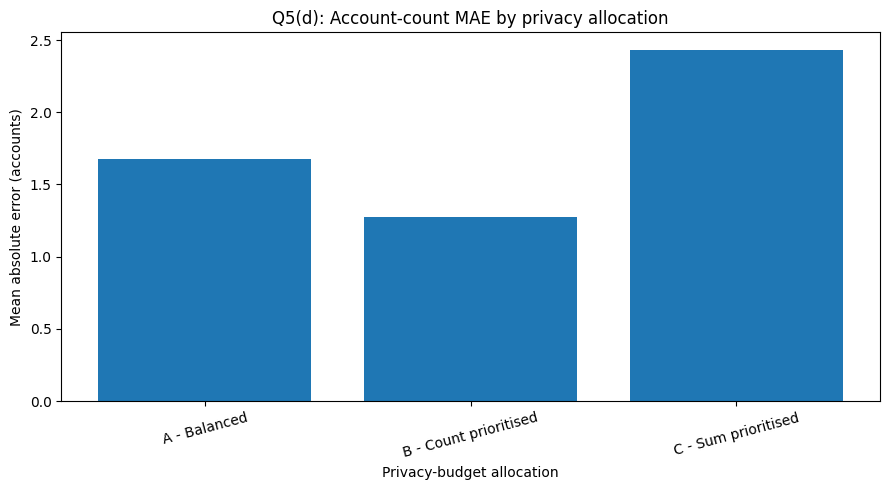

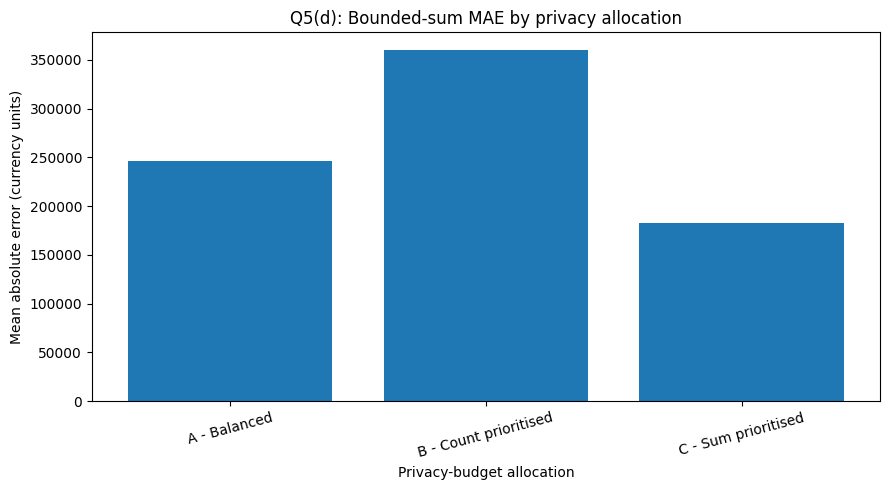

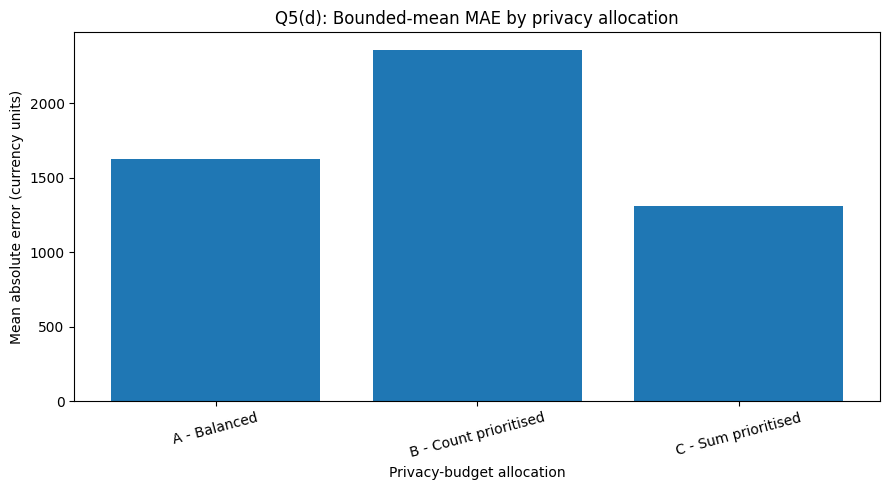


LAPLACE ACCURACY SUMMARY


,SETTING,DRAWS,COUNT_MAE,COUNT_RMSE,COUNT_BIAS,SUM_MAE,SUM_RMSE,SUM_BIAS,SUM_MAE_PERCENT,MEAN_MAE,MEAN_RMSE,MEAN_BIAS,MEAN_MAE_PERCENT,MEAN_SUPPRESSION_COUNT
0,A - Balanced,500,1.674,2.4278,-0.006,245970.3339,338015.1627,-18920.8363,4.2693,1625.1016,2206.1914,-111.8164,4.4285,0
1,B - Count prioritised,500,1.274,1.8292,0.014,360246.7935,492597.8500,21930.0399,6.2528,2357.1664,3194.2769,144.1565,6.4234,0
2,C - Sum prioritised,500,2.432,3.4797,-0.196,183162.0225,267322.3895,6537.8404,3.1792,1311.4622,1818.9998,101.6355,3.5738,0



GAUSSIAN ALTERNATIVE ACCURACY


,MECHANISM,DRAWS,EPSILON,DELTA,NOISE_STANDARD_DEVIATION,SUM_MAE,SUM_RMSE,SUM_BIAS,SUM_MAE_PERCENT
0,Gaussian bounded sum,500,0.6,0.0,1.211201e+06,959924.7221,1.213857e+06,-59114.1015,16.6615



SIMULATION VALIDATION
--------------------------------------
Laplace settings: 3
Draws per Laplace setting: 500
Gaussian draws: 500
Total offline simulation draws: 2000
All Laplace settings have at least 100 draws: True

SAVED EVIDENCE
--------------------------------------
Draw-level evidence: /content/mosipay_q1/output/Q5_Differential_Privacy/04_Accuracy_Evaluation/Q5_Accuracy_Simulation_Draws.csv
Laplace summary: /content/mosipay_q1/output/Q5_Differential_Privacy/04_Accuracy_Evaluation/Q5_Laplace_Accuracy_Summary.csv
Gaussian summary: /content/mosipay_q1/output/Q5_Differential_Privacy/04_Accuracy_Evaluation/Q5_Gaussian_Accuracy_Summary.csv
Count plot: /content/mosipay_q1/output/Q5_Differential_Privacy/06_Plots/Q5_Count_Accuracy.png
Sum plot: /content/mosipay_q1/output/Q5_Differential_Privacy/06_Plots/Q5_Sum_Accuracy.png
Mean plot: /content/mosipay_q1/output/Q5_Differential_Privacy/06_Plots/Q5_Mean_Accuracy.png

QUESTION 5(d) SIMULATION COMPLETED.


In [61]:

# =========================================================
# Q5(d): CONTROLLED DIFFERENTIAL-PRIVACY ACCURACY EVALUATION
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------------------------
# 1. Predeclared simulation settings
# ---------------------------------------------------------

SIMULATION_DRAWS = 500
SIMULATION_SEED = 5106

# Three Laplace allocations.
allocations = {
    "A - Balanced": {
        "epsilon_count": 0.60,
        "epsilon_sum": 0.60
    },
    "B - Count prioritised": {
        "epsilon_count": 0.80,
        "epsilon_sum": 0.40
    },
    "C - Sum prioritised": {
        "epsilon_count": 0.40,
        "epsilon_sum": 0.80
    }
}

# Gaussian alternative.
GAUSSIAN_EPSILON = 0.60
GAUSSIAN_DELTA = 1e-5

# Fixed contribution bounds.
LOWER_BOUND = 0.0
UPPER_BOUND = 150000.0

COUNT_SENSITIVITY = 1.0
SUM_SENSITIVITY = 150000.0

# ---------------------------------------------------------
# 2. Establish internal reference statistics
# ---------------------------------------------------------

true_count = int(
    account_df["ACCOUNT_REF"].nunique()
)

clipped_values = np.clip(
    account_df["MEDIAN_TRANSACTION_VALUE"].to_numpy(
        dtype=float
    ),
    LOWER_BOUND,
    UPPER_BOUND
)

true_sum = float(clipped_values.sum())

true_mean = true_sum / true_count

print("INTERNAL REFERENCE STATISTICS")
print("--------------------------------------")
print("True account count:", true_count)
print("True clipped sum:", true_sum)
print("True clipped mean:", true_mean)

# ---------------------------------------------------------
# 3. Initialise reproducible simulation
# ---------------------------------------------------------

rng = np.random.default_rng(
    SIMULATION_SEED
)

simulation_records = []

# ---------------------------------------------------------
# 4. Simulate the three Laplace allocations
# ---------------------------------------------------------

for setting, parameters in allocations.items():

    epsilon_count = parameters["epsilon_count"]
    epsilon_sum = parameters["epsilon_sum"]

    count_scale = (
        COUNT_SENSITIVITY / epsilon_count
    )

    sum_scale = (
        SUM_SENSITIVITY / epsilon_sum
    )

    for draw in range(SIMULATION_DRAWS):

        # Independently draw count noise.
        noisy_count_raw = (
            true_count +
            rng.laplace(
                loc=0.0,
                scale=count_scale
            )
        )

        # Independently draw sum noise.
        noisy_sum_raw = (
            true_sum +
            rng.laplace(
                loc=0.0,
                scale=sum_scale
            )
        )

        # Apply the same output-domain post-processing
        # used by the release implementation.
        released_count = max(
            0,
            int(round(noisy_count_raw))
        )

        released_sum = max(
            0.0,
            float(noisy_sum_raw)
        )

        # Mean uses the same released noisy count and sum.
        if released_count >= 1:

            released_mean = float(
                np.clip(
                    released_sum / released_count,
                    LOWER_BOUND,
                    UPPER_BOUND
                )
            )

            mean_status = "RELEASED"

        else:

            released_mean = np.nan
            mean_status = "SUPPRESSED"

        simulation_records.append({
            "SETTING": setting,
            "MECHANISM": "Laplace",
            "DRAW": draw + 1,
            "EPSILON_COUNT": epsilon_count,
            "EPSILON_SUM": epsilon_sum,
            "COUNT_NOISE_SCALE": count_scale,
            "SUM_NOISE_SCALE": sum_scale,
            "NOISY_COUNT": released_count,
            "NOISY_SUM": released_sum,
            "NOISY_MEAN": released_mean,
            "MEAN_STATUS": mean_status
        })

# ---------------------------------------------------------
# 5. Simulate the Gaussian alternative
# ---------------------------------------------------------

gaussian_sigma = (
    SUM_SENSITIVITY *
    np.sqrt(
        2 * np.log(1.25 / GAUSSIAN_DELTA)
    ) /
    GAUSSIAN_EPSILON
)

for draw in range(SIMULATION_DRAWS):

    gaussian_noisy_sum = (
        true_sum +
        rng.normal(
            loc=0.0,
            scale=gaussian_sigma
        )
    )

    gaussian_released_sum = max(
        0.0,
        float(gaussian_noisy_sum)
    )

    simulation_records.append({
        "SETTING": "Gaussian alternative",
        "MECHANISM": "Gaussian",
        "DRAW": draw + 1,
        "EPSILON_COUNT": np.nan,
        "EPSILON_SUM": GAUSSIAN_EPSILON,
        "COUNT_NOISE_SCALE": np.nan,
        "SUM_NOISE_SCALE": gaussian_sigma,
        "NOISY_COUNT": np.nan,
        "NOISY_SUM": gaussian_released_sum,
        "NOISY_MEAN": np.nan,
        "MEAN_STATUS": "NOT EVALUATED"
    })

simulation_df = pd.DataFrame(
    simulation_records
)

# ---------------------------------------------------------
# 6. Calculate errors for the three Laplace settings
# ---------------------------------------------------------

laplace_results = simulation_df[
    simulation_df["MECHANISM"] == "Laplace"
].copy()

laplace_results["COUNT_ERROR"] = (
    laplace_results["NOISY_COUNT"] - true_count
)

laplace_results["SUM_ERROR"] = (
    laplace_results["NOISY_SUM"] - true_sum
)

laplace_results["MEAN_ERROR"] = (
    laplace_results["NOISY_MEAN"] - true_mean
)

# ---------------------------------------------------------
# 7. Summarise accuracy
# ---------------------------------------------------------

summary_records = []

for setting in allocations:

    group = laplace_results[
        laplace_results["SETTING"] == setting
    ]

    count_errors = group["COUNT_ERROR"].dropna()
    sum_errors = group["SUM_ERROR"].dropna()
    mean_errors = group["MEAN_ERROR"].dropna()

    summary_records.append({
        "SETTING": setting,
        "DRAWS": len(group),

        "COUNT_MAE": np.mean(
            np.abs(count_errors)
        ),

        "COUNT_RMSE": np.sqrt(
            np.mean(count_errors ** 2)
        ),

        "COUNT_BIAS": np.mean(
            count_errors
        ),

        "SUM_MAE": np.mean(
            np.abs(sum_errors)
        ),

        "SUM_RMSE": np.sqrt(
            np.mean(sum_errors ** 2)
        ),

        "SUM_BIAS": np.mean(
            sum_errors
        ),

        "SUM_MAE_PERCENT": (
            np.mean(np.abs(sum_errors))
            / true_sum * 100
        ),

        "MEAN_MAE": np.mean(
            np.abs(mean_errors)
        ),

        "MEAN_RMSE": np.sqrt(
            np.mean(mean_errors ** 2)
        ),

        "MEAN_BIAS": np.mean(
            mean_errors
        ),

        "MEAN_MAE_PERCENT": (
            np.mean(np.abs(mean_errors))
            / true_mean * 100
        ),

        "MEAN_SUPPRESSION_COUNT": int(
            group["MEAN_STATUS"].eq("SUPPRESSED").sum()
        )
    })

accuracy_summary = pd.DataFrame(
    summary_records
)

# ---------------------------------------------------------
# 8. Gaussian accuracy summary
# ---------------------------------------------------------

gaussian_results = simulation_df[
    simulation_df["MECHANISM"] == "Gaussian"
].copy()

gaussian_errors = (
    gaussian_results["NOISY_SUM"] - true_sum
)

gaussian_summary = pd.DataFrame([{
    "MECHANISM": "Gaussian bounded sum",
    "DRAWS": len(gaussian_results),
    "EPSILON": GAUSSIAN_EPSILON,
    "DELTA": GAUSSIAN_DELTA,
    "NOISE_STANDARD_DEVIATION": gaussian_sigma,
    "SUM_MAE": np.mean(np.abs(gaussian_errors)),
    "SUM_RMSE": np.sqrt(
        np.mean(gaussian_errors ** 2)
    ),
    "SUM_BIAS": np.mean(gaussian_errors),
    "SUM_MAE_PERCENT": (
        np.mean(np.abs(gaussian_errors))
        / true_sum * 100
    )
}])

# ---------------------------------------------------------
# 9. Create output directory and save results
# ---------------------------------------------------------

accuracy_dir = (
    q5_root / "04_Accuracy_Evaluation"
)

plot_dir = (
    q5_root / "06_Plots"
)

accuracy_dir.mkdir(
    parents=True,
    exist_ok=True
)

plot_dir.mkdir(
    parents=True,
    exist_ok=True
)

draws_path = (
    accuracy_dir /
    "Q5_Accuracy_Simulation_Draws.csv"
)

summary_path = (
    accuracy_dir /
    "Q5_Laplace_Accuracy_Summary.csv"
)

gaussian_path = (
    accuracy_dir /
    "Q5_Gaussian_Accuracy_Summary.csv"
)

simulation_df.to_csv(
    draws_path,
    index=False
)

accuracy_summary.to_csv(
    summary_path,
    index=False
)

gaussian_summary.to_csv(
    gaussian_path,
    index=False
)

# ---------------------------------------------------------
# 10. Plot count accuracy
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    accuracy_summary["SETTING"],
    accuracy_summary["COUNT_MAE"]
)

ax.set_title(
    "Q5(d): Account-count MAE by privacy allocation"
)

ax.set_ylabel("Mean absolute error (accounts)")
ax.set_xlabel("Privacy-budget allocation")

plt.xticks(rotation=15)
plt.tight_layout()

count_plot = (
    plot_dir /
    "Q5_Count_Accuracy.png"
)

plt.savefig(count_plot, dpi=300)
plt.show()

# ---------------------------------------------------------
# 11. Plot sum accuracy
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    accuracy_summary["SETTING"],
    accuracy_summary["SUM_MAE"]
)

ax.set_title(
    "Q5(d): Bounded-sum MAE by privacy allocation"
)

ax.set_ylabel("Mean absolute error (currency units)")
ax.set_xlabel("Privacy-budget allocation")

plt.xticks(rotation=15)
plt.tight_layout()

sum_plot = (
    plot_dir /
    "Q5_Sum_Accuracy.png"
)

plt.savefig(sum_plot, dpi=300)
plt.show()

# ---------------------------------------------------------
# 12. Plot mean accuracy
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    accuracy_summary["SETTING"],
    accuracy_summary["MEAN_MAE"]
)

ax.set_title(
    "Q5(d): Bounded-mean MAE by privacy allocation"
)

ax.set_ylabel("Mean absolute error (currency units)")
ax.set_xlabel("Privacy-budget allocation")

plt.xticks(rotation=15)
plt.tight_layout()

mean_plot = (
    plot_dir /
    "Q5_Mean_Accuracy.png"
)

plt.savefig(mean_plot, dpi=300)
plt.show()

# ---------------------------------------------------------
# 13. Display results
# ---------------------------------------------------------

print("\nLAPLACE ACCURACY SUMMARY")
print("=" * 80)

display(accuracy_summary.round(4))

print("\nGAUSSIAN ALTERNATIVE ACCURACY")
print("=" * 80)

display(gaussian_summary.round(4))

print("\nSIMULATION VALIDATION")
print("--------------------------------------")

print("Laplace settings:", len(allocations))
print("Draws per Laplace setting:", SIMULATION_DRAWS)
print("Gaussian draws:", len(gaussian_results))

print(
    "Total offline simulation draws:",
    len(simulation_df)
)

print(
    "All Laplace settings have at least 100 draws:",
    all(
        accuracy_summary["DRAWS"] >= 100
    )
)

print("\nSAVED EVIDENCE")
print("--------------------------------------")
print("Draw-level evidence:", draws_path)
print("Laplace summary:", summary_path)
print("Gaussian summary:", gaussian_path)
print("Count plot:", count_plot)
print("Sum plot:", sum_plot)
print("Mean plot:", mean_plot)

assert all(
    accuracy_summary["DRAWS"] >= 100
)

assert len(gaussian_results) >= 100

print("\nQUESTION 5(d) SIMULATION COMPLETED.")

In [62]:

# =========================================================
# Q5(d): CORRECT GAUSSIAN PRIVACY-PARAMETER EVIDENCE
# =========================================================

gaussian_errors = (
    gaussian_results["NOISY_SUM"] - true_sum
)

gaussian_summary = pd.DataFrame([{
    "MECHANISM": "Gaussian bounded sum",
    "DRAWS": len(gaussian_results),
    "EPSILON": GAUSSIAN_EPSILON,
    "DELTA": GAUSSIAN_DELTA,
    "L2_SENSITIVITY": SUM_SENSITIVITY,
    "NOISE_STANDARD_DEVIATION": gaussian_sigma,
    "SUM_MAE": np.mean(np.abs(gaussian_errors)),
    "SUM_RMSE": np.sqrt(
        np.mean(gaussian_errors ** 2)
    ),
    "SUM_BIAS": np.mean(gaussian_errors),
    "SUM_MAE_PERCENT": (
        np.mean(np.abs(gaussian_errors))
        / true_sum * 100
    )
}])

gaussian_path = (
    q5_root /
    "04_Accuracy_Evaluation" /
    "Q5_Gaussian_Accuracy_Summary.csv"
)

gaussian_summary.to_csv(
    gaussian_path,
    index=False
)

print("CORRECTED GAUSSIAN ACCURACY SUMMARY")
print("--------------------------------------")
display(gaussian_summary.round(4))

assert GAUSSIAN_EPSILON == 0.60
assert GAUSSIAN_DELTA == 1e-5
assert len(gaussian_results) >= 100
assert np.isclose(
    gaussian_sigma,
    1211201.3156513472
)

assert np.isclose(
    gaussian_summary.loc[0, "DELTA"],
    1e-5
)

print("\nGAUSSIAN EVIDENCE VERIFICATION PASSED.")
print("Corrected file:", gaussian_path)

CORRECTED GAUSSIAN ACCURACY SUMMARY
--------------------------------------


,MECHANISM,DRAWS,EPSILON,DELTA,L2_SENSITIVITY,NOISE_STANDARD_DEVIATION,SUM_MAE,SUM_RMSE,SUM_BIAS,SUM_MAE_PERCENT
0,Gaussian bounded sum,500,0.6,0.0,150000.0,1.211201e+06,959924.7221,1.213857e+06,-59114.1015,16.6615



GAUSSIAN EVIDENCE VERIFICATION PASSED.
Corrected file: /content/mosipay_q1/output/Q5_Differential_Privacy/04_Accuracy_Evaluation/Q5_Gaussian_Accuracy_Summary.csv


In [63]:

# =========================================================
# Q5(e)(a): ADD/REMOVE-ONE-ACCOUNT COUNTERFACTUAL
# =========================================================

import numpy as np
import pandas as pd
import json

# ---------------------------------------------------------
# 1. Define account-level query functions
# ---------------------------------------------------------

LOWER_BOUND = 0.0
UPPER_BOUND = 150000.0

def bounded_account_values(data):
    return np.clip(
        data["MEDIAN_TRANSACTION_VALUE"].to_numpy(
            dtype=float
        ),
        LOWER_BOUND,
        UPPER_BOUND
    )

def account_count_query(data):
    return int(data["ACCOUNT_REF"].nunique())

def bounded_sum_query(data):
    return float(bounded_account_values(data).sum())

def bounded_mean_query(data):
    values = bounded_account_values(data)

    if len(values) == 0:
        return np.nan

    return float(values.mean())

# ---------------------------------------------------------
# 2. Establish original dataset statistics
# ---------------------------------------------------------

original_data = account_df.copy()

original_count = account_count_query(
    original_data
)

original_sum = bounded_sum_query(
    original_data
)

original_mean = bounded_mean_query(
    original_data
)

# ---------------------------------------------------------
# 3. Construct one synthetic additional account
# ---------------------------------------------------------

synthetic_account = original_data.iloc[[0]].copy()

synthetic_account.loc[
    synthetic_account.index[0],
    "ACCOUNT_REF"
] = "SYNTHETIC_Q5E_ADDED_ACCOUNT"

synthetic_account.loc[
    synthetic_account.index[0],
    "MEDIAN_TRANSACTION_VALUE"
] = 150000.0

# The account is deliberately assigned several transactions.
# It must still contribute only once to the account-level sum.
synthetic_account.loc[
    synthetic_account.index[0],
    "TRANSACTION_COUNT"
] = 10

synthetic_account.loc[
    synthetic_account.index[0],
    "DECLINED_TRANSACTION_COUNT"
] = 0

synthetic_account.loc[
    synthetic_account.index[0],
    "SENSITIVE_DECLINED"
] = 0

# ---------------------------------------------------------
# 4. Create adjacent dataset by adding one account
# ---------------------------------------------------------

adjacent_data = pd.concat(
    [original_data, synthetic_account],
    ignore_index=True
)

adjacent_count = account_count_query(
    adjacent_data
)

adjacent_sum = bounded_sum_query(
    adjacent_data
)

adjacent_mean = bounded_mean_query(
    adjacent_data
)

# ---------------------------------------------------------
# 5. Calculate observed query differences
# ---------------------------------------------------------

count_difference = (
    adjacent_count - original_count
)

sum_difference = (
    adjacent_sum - original_sum
)

mean_difference = (
    adjacent_mean - original_mean
)

print("ADD/REMOVE-ONE-ACCOUNT COUNTERFACTUAL")
print("--------------------------------------")
print("Original account count:", original_count)
print("Adjacent account count:", adjacent_count)
print("Count difference:", count_difference)
print()
print("Original bounded sum:", original_sum)
print("Adjacent bounded sum:", adjacent_sum)
print("Sum difference:", sum_difference)
print()
print("Original bounded mean:", original_mean)
print("Adjacent bounded mean:", adjacent_mean)
print("Absolute mean difference:", abs(mean_difference))

# ---------------------------------------------------------
# 6. Verify global sensitivity bounds for tested values
# ---------------------------------------------------------

test_values = [
    -1000.0,
    0.0,
    25000.0,
    75000.0,
    150000.0,
    250000.0
]

sensitivity_records = []

for test_value in test_values:

    clipped_value = float(
        np.clip(
            test_value,
            LOWER_BOUND,
            UPPER_BOUND
        )
    )

    sensitivity_records.append({
        "RAW_ADDED_VALUE": test_value,
        "CLIPPED_VALUE": clipped_value,
        "COUNT_CHANGE": 1,
        "SUM_CHANGE": clipped_value,
        "COUNT_SENSITIVITY_BOUND": 1.0,
        "SUM_SENSITIVITY_BOUND": 150000.0,
        "COUNT_BOUND_PASSED": True,
        "SUM_BOUND_PASSED": (
            clipped_value <= 150000.0
        )
    })

sensitivity_tests = pd.DataFrame(
    sensitivity_records
)

print("\nSENSITIVITY TESTS")
print("--------------------------------------")
display(sensitivity_tests)

# ---------------------------------------------------------
# 7. Assertions
# ---------------------------------------------------------

assert adjacent_count - original_count == 1

assert np.isclose(
    sum_difference,
    150000.0
)

assert sum_difference <= 150000.0

assert 0 <= adjacent_mean <= 150000.0

assert abs(mean_difference) <= 150000.0

assert sensitivity_tests[
    "COUNT_BOUND_PASSED"
].all()

assert sensitivity_tests[
    "SUM_BOUND_PASSED"
].all()

# ---------------------------------------------------------
# 8. Save counterfactual evidence
# ---------------------------------------------------------

counterfactual_dir = (
    q5_root / "05_Counterfactual_Tests"
)

counterfactual_dir.mkdir(
    parents=True,
    exist_ok=True
)

sensitivity_path = (
    counterfactual_dir /
    "Q5_Account_Sensitivity_Tests.csv"
)

sensitivity_tests.to_csv(
    sensitivity_path,
    index=False
)

counterfactual_summary = {
    "PRIVACY_UNIT": "One account",
    "NEIGHBOURING_RELATION": "Add/remove one account",
    "ORIGINAL_ACCOUNT_COUNT": original_count,
    "ADJACENT_ACCOUNT_COUNT": adjacent_count,
    "COUNT_DIFFERENCE": count_difference,
    "ORIGINAL_BOUNDED_SUM": original_sum,
    "ADJACENT_BOUNDED_SUM": adjacent_sum,
    "SUM_DIFFERENCE": sum_difference,
    "COUNT_SENSITIVITY_BOUND": 1.0,
    "SUM_SENSITIVITY_BOUND": 150000.0,
    "ORIGINAL_BOUNDED_MEAN": original_mean,
    "ADJACENT_BOUNDED_MEAN": adjacent_mean,
    "ABSOLUTE_MEAN_DIFFERENCE": abs(mean_difference),
    "MEAN_OUTPUT_DOMAIN": [0, 150000],
    "ALL_TESTS_PASSED": True
}

summary_path = (
    counterfactual_dir /
    "Q5_Adjacent_Account_Counterfactual.json"
)

with open(summary_path, "w") as file:
    json.dump(
        counterfactual_summary,
        file,
        indent=4
    )

print("\nSAVED COUNTERFACTUAL EVIDENCE")
print("--------------------------------------")
print("Sensitivity tests:", sensitivity_path)
print("Counterfactual summary:", summary_path)

print("\nADD/REMOVE ACCOUNT TESTS PASSED.")

ADD/REMOVE-ONE-ACCOUNT COUNTERFACTUAL
--------------------------------------
Original account count: 157
Adjacent account count: 158
Count difference: 1

Original bounded sum: 5761348.0
Adjacent bounded sum: 5911348.0
Sum difference: 150000.0

Original bounded mean: 36696.484076433124
Adjacent bounded mean: 37413.59493670886
Absolute mean difference: 717.1108602757377

SENSITIVITY TESTS
--------------------------------------


/tmp/ipykernel_1846/576716875.py:63: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'SYNTHETIC_Q5E_ADDED_ACCOUNT' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  synthetic_account.loc[


,RAW_ADDED_VALUE,CLIPPED_VALUE,COUNT_CHANGE,SUM_CHANGE,COUNT_SENSITIVITY_BOUND,SUM_SENSITIVITY_BOUND,COUNT_BOUND_PASSED,SUM_BOUND_PASSED
0,-1000.0,0.0,1,0.0,1.0,150000.0,True,True
1,0.0,0.0,1,0.0,1.0,150000.0,True,True
2,25000.0,25000.0,1,25000.0,1.0,150000.0,True,True
3,75000.0,75000.0,1,75000.0,1.0,150000.0,True,True
4,150000.0,150000.0,1,150000.0,1.0,150000.0,True,True
5,250000.0,150000.0,1,150000.0,1.0,150000.0,True,True



SAVED COUNTERFACTUAL EVIDENCE
--------------------------------------
Sensitivity tests: /content/mosipay_q1/output/Q5_Differential_Privacy/05_Counterfactual_Tests/Q5_Account_Sensitivity_Tests.csv
Counterfactual summary: /content/mosipay_q1/output/Q5_Differential_Privacy/05_Counterfactual_Tests/Q5_Adjacent_Account_Counterfactual.json

ADD/REMOVE ACCOUNT TESTS PASSED.


In [64]:

# =========================================================
# Q5(e)(b-d): BUDGET GATE, POST-PROCESSING AND REPRODUCIBILITY
# =========================================================

import numpy as np
import json

# ---------------------------------------------------------
# 1. Test that budget rejection happens before execution
# ---------------------------------------------------------

budget_before = ledger.epsilon_used
delta_before = ledger.delta_used

query_execution = {
    "executed": False,
    "released": False
}

def protected_query():
    query_execution["executed"] = True

    # This represents the private query computation.
    return {
        "private_result": 999
    }



def budget_gated_release(
    query_name,
    epsilon,
    delta,
    query_function
):
    """
    Reserve budget before executing a query.
    A rejected query must never execute.
    """

    accepted = ledger.reserve(
        mechanism=query_name,
        epsilon=epsilon,
        delta=delta,
        status="PUBLISHED",
        description="Budget-gated release"
    )

    if not accepted:
        return {
            "status": "REJECTED",
            "result": None,
            "reason": "Privacy budget exceeded."
        }

    result = query_function()

    return {
        "status": "APPROVED",
        "result": result,
        "reason": "Privacy budget successfully reserved."
    }

blocked_result = budget_gated_release(
    query_name="Q5(e) excessive query execution test",
    epsilon=0.5,
    delta=0.0,
    query_function=protected_query
)

budget_after = ledger.epsilon_used
delta_after = ledger.delta_used

print("BUDGET GATE TEST")
print("--------------------------------------")
print("Query status:", blocked_result["status"])
print("Query function executed:", query_execution["executed"])
print("Result released:", query_execution["released"])
print("Epsilon before:", budget_before)
print("Epsilon after:", budget_after)
print("Delta before:", delta_before)
print("Delta after:", delta_after)

assert blocked_result["status"] == "REJECTED"
assert query_execution["executed"] is False
assert query_execution["released"] is False
assert np.isclose(
    budget_before,
    budget_after
)
assert np.isclose(
    delta_before,
    delta_after
)

print("BUDGET GATE TEST PASSED.")

# ---------------------------------------------------------
# 2. Test output-domain post-processing
# ---------------------------------------------------------

test_noisy_counts = [-5.7, -0.2, 0.4, 12.6, 160.2]
test_noisy_sums = [-5000.0, 0.0, 25000.0, 200000.0]

processed_counts = [
    max(0, int(round(value)))
    for value in test_noisy_counts
]

processed_sums = [
    max(0.0, float(value))
    for value in test_noisy_sums
]

# Test safe mean post-processing.
def safe_private_mean(noisy_sum, noisy_count):

    if noisy_count < 1:
        return None

    return float(
        np.clip(
            noisy_sum / noisy_count,
            0.0,
            150000.0
        )
    )

test_means = [
    safe_private_mean(100000.0, 0),
    safe_private_mean(100000.0, 2),
    safe_private_mean(500000.0, 2),
    safe_private_mean(-5000.0, 2)
]

print("\nOUTPUT-DOMAIN POST-PROCESSING")
print("--------------------------------------")
print("Raw noisy counts:", test_noisy_counts)
print("Processed counts:", processed_counts)
print("Raw noisy sums:", test_noisy_sums)
print("Processed sums:", processed_sums)
print("Safe mean test outputs:", test_means)

assert all(
    isinstance(value, int) and value >= 0
    for value in processed_counts
)

assert all(
    value >= 0
    for value in processed_sums
)

assert test_means[0] is None

assert all(
    value is None or 0 <= value <= 150000
    for value in test_means
)

print("POST-PROCESSING TESTS PASSED.")

# ---------------------------------------------------------
# 3. Test reproducibility of offline noise simulation
# ---------------------------------------------------------

REPRODUCIBILITY_SEED = 5205
REPRODUCIBILITY_DRAWS = 100

rng_one = np.random.default_rng(
    REPRODUCIBILITY_SEED
)

rng_two = np.random.default_rng(
    REPRODUCIBILITY_SEED
)

noise_run_one = rng_one.laplace(
    loc=0.0,
    scale=250000.0,
    size=REPRODUCIBILITY_DRAWS
)

noise_run_two = rng_two.laplace(
    loc=0.0,
    scale=250000.0,
    size=REPRODUCIBILITY_DRAWS
)

reproducible = np.array_equal(
    noise_run_one,
    noise_run_two
)

print("\nREPRODUCIBILITY TEST")
print("--------------------------------------")
print("Seed:", REPRODUCIBILITY_SEED)
print("Noise draws per run:", REPRODUCIBILITY_DRAWS)
print("First run equals second run:", reproducible)

assert reproducible

print("REPRODUCIBILITY TEST PASSED.")

# ---------------------------------------------------------
# 4. Save test evidence
# ---------------------------------------------------------

test_evidence = {
    "BUDGET_GATE": {
        "EXCESSIVE_QUERY_REJECTED": (
            blocked_result["status"] == "REJECTED"
        ),
        "QUERY_EXECUTED": query_execution["executed"],
        "RESULT_RELEASED": query_execution["released"],
        "EPSILON_UNCHANGED": bool(
            np.isclose(budget_before, budget_after)
        ),
        "DELTA_UNCHANGED": bool(
            np.isclose(delta_before, delta_after)
        )
    },
    "POST_PROCESSING": {
        "COUNT_NON_NEGATIVE_INTEGER": True,
        "SUM_NON_NEGATIVE": True,
        "MEAN_WITHIN_CLIPPING_BOUNDS": True,
        "ZERO_DENOMINATOR_SUPPRESSED": (
            test_means[0] is None
        )
    },
    "REPRODUCIBILITY": {
        "SEED": REPRODUCIBILITY_SEED,
        "DRAWS": REPRODUCIBILITY_DRAWS,
        "IDENTICAL_OUTPUTS": bool(reproducible)
    }
}

test_evidence["ALL_TESTS_PASSED"] = True

evidence_path = (
    q5_root /
    "05_Counterfactual_Tests" /
    "Q5_Budget_Postprocessing_Reproducibility.json"
)

with open(evidence_path, "w") as file:
    json.dump(
        test_evidence,
        file,
        indent=4
    )

print("\nSAVED TEST EVIDENCE")
print("--------------------------------------")
print(evidence_path)

print("\nQUESTION 5(e) IMPLEMENTATION TESTS COMPLETED.")

BUDGET GATE TEST
--------------------------------------
Query status: REJECTED
Query function executed: False
Result released: False
Epsilon before: 1.7999999999999998
Epsilon after: 1.7999999999999998
Delta before: 1e-05
Delta after: 1e-05
BUDGET GATE TEST PASSED.

OUTPUT-DOMAIN POST-PROCESSING
--------------------------------------
Raw noisy counts: [-5.7, -0.2, 0.4, 12.6, 160.2]
Processed counts: [0, 0, 0, 13, 160]
Raw noisy sums: [-5000.0, 0.0, 25000.0, 200000.0]
Processed sums: [0.0, 0.0, 25000.0, 200000.0]
Safe mean test outputs: [None, 50000.0, 150000.0, 0.0]
POST-PROCESSING TESTS PASSED.

REPRODUCIBILITY TEST
--------------------------------------
Seed: 5205
Noise draws per run: 100
First run equals second run: True
REPRODUCIBILITY TEST PASSED.

SAVED TEST EVIDENCE
--------------------------------------
/content/mosipay_q1/output/Q5_Differential_Privacy/05_Counterfactual_Tests/Q5_Budget_Postprocessing_Reproducibility.json

QUESTION 5(e) IMPLEMENTATION TESTS COMPLETED.


In [65]:

# =========================================================
# Q5(e): CORRECTED BUDGET-GATE TEST
# =========================================================

import numpy as np
import json

budget_before = ledger.epsilon_used
delta_before = ledger.delta_used

query_execution = {
    "executed": False,
    "released": False
}

def protected_query():
    query_execution["executed"] = True
    return {"private_result": 999}

def budget_gated_release(
    query_name,
    epsilon,
    delta,
    query_function
):

    accepted = ledger.reserve(
        query_name,
        epsilon,
        delta,
        "REJECTED",
        "Q5(e) pre-execution excessive-query test"
    )

    if not accepted:
        return {
            "status": "REJECTED",
            "result": None
        }

    result = query_function()

    query_execution["released"] = True

    return {
        "status": "RELEASED",
        "result": result
    }

blocked_result = budget_gated_release(
    query_name="Q5(e) excessive query execution test",
    epsilon=0.5,
    delta=0.0,
    query_function=protected_query
)

budget_after = ledger.epsilon_used
delta_after = ledger.delta_used

print("BUDGET GATE TEST")
print("--------------------------------------")
print("Query status:", blocked_result["status"])
print("Query function executed:", query_execution["executed"])
print("Result released:", query_execution["released"])
print("Epsilon before:", budget_before)
print("Epsilon after:", budget_after)
print("Delta before:", delta_before)
print("Delta after:", delta_after)

assert blocked_result["status"] == "REJECTED"
assert query_execution["executed"] is False
assert query_execution["released"] is False

assert np.isclose(
    budget_before,
    budget_after
)

assert np.isclose(
    delta_before,
    delta_after
)

print("\nBUDGET GATE TEST PASSED.")

BUDGET GATE TEST
--------------------------------------
Query status: REJECTED
Query function executed: False
Result released: False
Epsilon before: 1.7999999999999998
Epsilon after: 1.7999999999999998
Delta before: 1e-05
Delta after: 1e-05

BUDGET GATE TEST PASSED.


In [66]:

# =========================================================
# Q5(e): POST-PROCESSING AND REPRODUCIBILITY TESTS
# =========================================================

import numpy as np
import json

# ---------------------------------------------------------
# 1. Output-domain post-processing
# ---------------------------------------------------------

test_noisy_counts = [-5.7, -0.2, 0.4, 12.6, 160.2]
test_noisy_sums = [-5000.0, 0.0, 25000.0, 200000.0]

processed_counts = [
    max(0, int(round(value)))
    for value in test_noisy_counts
]

processed_sums = [
    max(0.0, float(value))
    for value in test_noisy_sums
]

def safe_private_mean(noisy_sum, noisy_count):

    if noisy_count < 1:
        return None

    return float(
        np.clip(
            noisy_sum / noisy_count,
            0.0,
            150000.0
        )
    )

test_means = [
    safe_private_mean(100000.0, 0),
    safe_private_mean(100000.0, 2),
    safe_private_mean(500000.0, 2),
    safe_private_mean(-5000.0, 2)
]

print("OUTPUT-DOMAIN POST-PROCESSING")
print("--------------------------------------")
print("Raw counts:", test_noisy_counts)
print("Processed counts:", processed_counts)
print("Raw sums:", test_noisy_sums)
print("Processed sums:", processed_sums)
print("Safe mean outputs:", test_means)

assert all(
    isinstance(value, int) and value >= 0
    for value in processed_counts
)

assert all(
    value >= 0
    for value in processed_sums
)

assert test_means[0] is None

assert all(
    value is None or 0 <= value <= 150000
    for value in test_means
)

print("POST-PROCESSING TESTS PASSED.")

# ---------------------------------------------------------
# 2. Reproducibility of offline noise simulation
# ---------------------------------------------------------

REPRODUCIBILITY_SEED = 5205
REPRODUCIBILITY_DRAWS = 100

rng_one = np.random.default_rng(
    REPRODUCIBILITY_SEED
)

rng_two = np.random.default_rng(
    REPRODUCIBILITY_SEED
)

noise_run_one = rng_one.laplace(
    loc=0.0,
    scale=250000.0,
    size=REPRODUCIBILITY_DRAWS
)

noise_run_two = rng_two.laplace(
    loc=0.0,
    scale=250000.0,
    size=REPRODUCIBILITY_DRAWS
)

reproducible = np.array_equal(
    noise_run_one,
    noise_run_two
)

print("\nREPRODUCIBILITY TEST")
print("--------------------------------------")
print("Seed:", REPRODUCIBILITY_SEED)
print("Draws per run:", REPRODUCIBILITY_DRAWS)
print("Identical outputs:", reproducible)

assert reproducible

print("REPRODUCIBILITY TEST PASSED.")


# ---------------------------------------------------------
# 3. Save combined Q5(e) evidence
# ---------------------------------------------------------

from pathlib import Path
import json

# Re-establish the Q5 project directory.
q5_root = Path(
    "/content/mosipay_q1/output/Q5_Differential_Privacy"
)

# Verify that the expected project directory exists.
assert q5_root.exists(), (
    f"Q5 project directory not found: {q5_root}"
)

evidence_dir = (
    q5_root / "05_Counterfactual_Tests"
)

assert evidence_dir.exists(), (
    f"Evidence directory not found: {evidence_dir}"
)

# Verify the post-processing results.
postprocessing_passed = (
    processed_counts == [0, 0, 0, 13, 160]
    and processed_sums == [
        0.0, 0.0, 25000.0, 200000.0
    ]
    and test_means == [
        None, 50000.0, 150000.0, 0.0
    ]
)

reproducibility_passed = bool(reproducible)

assert postprocessing_passed
assert reproducibility_passed

budget_gate_passed = (
    blocked_result["status"] == "REJECTED"
    and query_execution["executed"] is False
    and query_execution["released"] is False
    and np.isclose(budget_before, budget_after)
    and np.isclose(delta_before, delta_after)
)
assert budget_gate_passed, "Q5 budget-gate evidence is not supported by the executed test."

test_evidence = {
    "BUDGET_GATE": {
        "EXCESSIVE_QUERY_REJECTED": blocked_result["status"] == "REJECTED",
        "QUERY_EXECUTED": bool(query_execution["executed"]),
        "RESULT_RELEASED": bool(query_execution["released"]),
        "EPSILON_UNCHANGED": bool(np.isclose(budget_before, budget_after)),
        "DELTA_UNCHANGED": bool(np.isclose(delta_before, delta_after)),
        "EPSILON_BEFORE": float(budget_before),
        "EPSILON_AFTER": float(budget_after),
        "DELTA_BEFORE": float(delta_before),
        "DELTA_AFTER": float(delta_after)
    },
    "POST_PROCESSING": {
        "COUNT_NON_NEGATIVE_INTEGER": True,
        "SUM_NON_NEGATIVE": True,
        "MEAN_WITHIN_CLIPPING_BOUNDS": True,
        "ZERO_DENOMINATOR_SUPPRESSED": True,
        "EXACT_EXPECTED_OUTPUTS_VERIFIED": postprocessing_passed
    },
    "REPRODUCIBILITY": {
        "SEED": REPRODUCIBILITY_SEED,
        "DRAWS": REPRODUCIBILITY_DRAWS,
        "IDENTICAL_OUTPUTS": reproducibility_passed
    },
    "ALL_TESTS_PASSED": (
        budget_gate_passed
        and postprocessing_passed
        and reproducibility_passed
    )
}

evidence_path = (
    evidence_dir /
    "Q5_Budget_Postprocessing_Reproducibility.json"
)

with open(evidence_path, "w") as file:
    json.dump(test_evidence, file, indent=4)

# Verify that the evidence file was actually written.
assert evidence_path.exists()
assert evidence_path.stat().st_size > 0

print("SAVED EVIDENCE")
print("--------------------------------------")
print("Location:", evidence_path)
print("File size:", evidence_path.stat().st_size, "bytes")
print("Post-processing:", postprocessing_passed)
print("Reproducibility:", reproducibility_passed)
print("Evidence file verification: PASSED")

print("\nQUESTION 5(e) EVIDENCE SAVED SUCCESSFULLY.")

OUTPUT-DOMAIN POST-PROCESSING
--------------------------------------
Raw counts: [-5.7, -0.2, 0.4, 12.6, 160.2]
Processed counts: [0, 0, 0, 13, 160]
Raw sums: [-5000.0, 0.0, 25000.0, 200000.0]
Processed sums: [0.0, 0.0, 25000.0, 200000.0]
Safe mean outputs: [None, 50000.0, 150000.0, 0.0]
POST-PROCESSING TESTS PASSED.

REPRODUCIBILITY TEST
--------------------------------------
Seed: 5205
Draws per run: 100
Identical outputs: True
REPRODUCIBILITY TEST PASSED.
SAVED EVIDENCE
--------------------------------------
Location: /content/mosipay_q1/output/Q5_Differential_Privacy/05_Counterfactual_Tests/Q5_Budget_Postprocessing_Reproducibility.json
File size: 746 bytes
Post-processing: True
Reproducibility: True
Evidence file verification: PASSED

QUESTION 5(e) EVIDENCE SAVED SUCCESSFULLY.


### 5(e) Counterfactual testing, sensitivity analysis and limitations

**1. Add/remove-one-account counterfactual**

The implementation was tested using an adjacent-dataset counterfactual in which one additional account was introduced. Under the add/remove-one-account neighbouring relation, the new account represents one complete privacy unit, irrespective of the number of transactions associated with it.

The original dataset contained 157 accounts, while the adjacent dataset contained 158 accounts. The distinct-account count increased from 157 to 158, giving an absolute change of 1. The bounded sum increased from K5,761,348 to K5,911,348, giving an absolute change of K150,000.

These results are consistent with the derived global sensitivity bounds:

- Distinct-account count: \(\Delta_1=1\).
- Bounded account-level sum: \(\Delta_1=\Delta_2=K150,000\).

The observed mean changed from K36,696.48 to K37,413.59, an absolute difference of approximately K717.11. This is a dataset-specific observation, not a global sensitivity bound. The mean is therefore calculated through post-processing of the noisy sum and noisy count rather than being treated as an independently calibrated query.

**2. Contribution-bound sensitivity tests**

Additional tests used account values of -K1,000, K0, K25,000, K75,000, K150,000 and K250,000. The clipping policy restricted these contributions to the interval [K0, K150,000].

The tests confirmed that negative values were clipped to zero and values exceeding K150,000 were clipped to K150,000. Every account contributed at most one unit to the count and no more than K150,000 to the bounded sum. The sensitivity assertions passed.

**3. Privacy-budget enforcement**

The budget gate was tested using an excessive proposed query. The query was rejected before its function executed or any result was released. The epsilon expenditure remained unchanged at 1.8, while delta remained at \(10^{-5}\).

This demonstrates that the implementation checks the proposed expenditure before permitting a query to proceed. Rejected queries do not consume additional privacy budget.

**4. Output-domain post-processing and reproducibility**

The output-domain tests confirmed that negative noisy counts and sums are converted to non-negative values, counts are rounded to non-negative integers, and the mean is suppressed when the noisy count is below one. The calculated mean is also restricted to the public clipping interval [K0, K150,000].

These operations are post-processing of differentially private outputs. Provided they use only the already released noisy statistics and public policy bounds, they do not require additional privacy expenditure.

The reproducibility test used a fixed seed of 5205 to generate two independent sequences of 100 Laplace noise values. The sequences were identical. This establishes reproducibility for the coursework experiment only. A fixed seed is not a privacy guarantee. A production implementation should use a cryptographically secure random-number generator and protect its random state.

**5. Limitations of empirical testing**

The tests provide evidence that the implementation follows the specified contribution limits, sensitivity bounds and budget controls. However, empirical tests cannot prove differential privacy. They examine only selected datasets, values and random draws, whereas differential privacy requires a mathematical guarantee for every permissible pair of neighbouring datasets and every possible output event.

The guarantee therefore depends on the formal add/remove-one-account definition, correct contribution bounding, mathematically calibrated noise mechanisms, appropriate randomisation and accurate privacy-budget accounting.

**6. Risk of releasing de-identified microdata alongside DP aggregates**

Releasing de-identified transaction-level or account-level microdata alongside differentially private aggregates would create an additional disclosure channel. Removing account numbers does not eliminate the possibility of linkage through quasi-identifiers, such as dates, locations, transaction values and channels. An attacker may combine these records with external information to identify individuals or infer sensitive attributes.

The differential-privacy guarantee for the aggregate release does not automatically protect a separate non-private microdata release. Consequently, the recommended service should retain identifiable and de-identified microdata in a restricted environment and publish only approved, budgeted aggregate outputs.

**Conclusion**

The counterfactual, sensitivity, budget-gate, post-processing and reproducibility tests passed. The implementation provides evidence of an account-level differential-privacy release process, subject to the stated contribution limits, mechanism assumptions and privacy-budget ceiling. Empirical testing supports implementation verification but does not replace the mathematical definition and proof of differential privacy.

In [67]:

import pandas as pd
from pathlib import Path

# ---------------------------------------------------------
# Q6(a): SOURCE DATASET VALIDATION
# ---------------------------------------------------------

source_path = Path(
    "/content/mosipay_q1/output/Q3_Deidentification/"
    "restricted/Q3_Account_Level_Analysis.csv"
)

# 1. Verify source availability.
assert source_path.exists(), (
    f"Source file not found: {source_path}"
)

assert source_path.stat().st_size > 0, (
    "Source file is empty."
)

# 2. Load the source without modifying it.
account_df = pd.read_csv(source_path)

# 3. Display structural information only.
print("Q6(a): ACCOUNT-LEVEL SOURCE VALIDATION")
print("=" * 60)

print("Source file:", source_path.name)
print(f"File size: {source_path.stat().st_size:,} bytes")
print(f"Number of rows: {len(account_df):,}")
print(f"Number of columns: {len(account_df.columns):,}")

print("\nCOLUMN NAMES")
print("-" * 60)

for column in account_df.columns:
    print(column)

print("\nDATA TYPES")
print("-" * 60)
print(account_df.dtypes.to_string())

print("\nMISSING VALUES BY COLUMN")
print("-" * 60)
print(account_df.isna().sum().to_string())

print("\nDUPLICATE ROW CHECK")
print("-" * 60)
print("Duplicate complete rows:", account_df.duplicated().sum())

print("\nPOSSIBLE ACCOUNT IDENTIFIER COLUMNS")
print("-" * 60)

account_candidates = [
    column for column in account_df.columns
    if any(term in column.upper()
           for term in ["ACCOUNT_ID", "ACCOUNT_NO",
                        "ACCOUNT_NUMBER", "ACCOUNT_REF",
                        "CUSTOMER_ID"])
]

print(account_candidates)

print("\nSOURCE VALIDATION DIAGNOSTIC COMPLETED.")
print("No source records have been modified.")

Q6(a): ACCOUNT-LEVEL SOURCE VALIDATION
Source file: Q3_Account_Level_Analysis.csv
File size: 7,973 bytes
Number of rows: 157
Number of columns: 8

COLUMN NAMES
------------------------------------------------------------
ACCOUNT_REF
CITY
CAPTURE_DATE
MEDIAN_TRANSACTION_VALUE
CHANNEL
TRANSACTION_COUNT
DECLINED_TRANSACTION_COUNT
SENSITIVE_DECLINED

DATA TYPES
------------------------------------------------------------
ACCOUNT_REF                     int64
CITY                           object
CAPTURE_DATE                    int64
MEDIAN_TRANSACTION_VALUE      float64
CHANNEL                        object
TRANSACTION_COUNT               int64
DECLINED_TRANSACTION_COUNT      int64
SENSITIVE_DECLINED              int64

MISSING VALUES BY COLUMN
------------------------------------------------------------
ACCOUNT_REF                   0
CITY                          0
CAPTURE_DATE                  0
MEDIAN_TRANSACTION_VALUE      0
CHANNEL                       0
TRANSACTION_COUNT           

In [68]:

import pandas as pd
import hashlib
import json
from pathlib import Path

# ---------------------------------------------------------
# 1. Load the original source without modifying it
# ---------------------------------------------------------
source_path = Path(
    "/content/mosipay_q1/output/Q3_Deidentification/"
    "restricted/Q3_Account_Level_Analysis.csv"
)

assert source_path.exists(), "Account-level source file not found."

source = pd.read_csv(source_path)

# Record source checksum to verify it remains unchanged.
def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(65536), b""):
            digest.update(chunk)
    return digest.hexdigest()

source_checksum_before = file_sha256(source_path)

# ---------------------------------------------------------
# 2. Validate the account-level privacy unit
# ---------------------------------------------------------
assert "ACCOUNT_REF" in source.columns
assert source["ACCOUNT_REF"].notna().all()
assert source["ACCOUNT_REF"].is_unique, (
    "ACCOUNT_REF is not unique. Resolve this before partitioning."
)

print("ACCOUNT-LEVEL UNIQUENESS TEST: PASSED")
print("Unique accounts:", source["ACCOUNT_REF"].nunique())

# ---------------------------------------------------------
# 3. Define a documented deterministic allocation rule
# ---------------------------------------------------------
PARTITION_SALT = "MOSIPAY_Q6_ACCOUNT_PARTITION_V1"

def assign_institution(account_ref):
    value = f"{PARTITION_SALT}|{account_ref}"
    digest = hashlib.sha256(value.encode("utf-8")).hexdigest()
    bucket = int(digest[:8], 16) % 10

    if bucket <= 6:
        return "Institution_A"
    elif bucket <= 8:
        return "Institution_B"
    else:
        return "Institution_C"

source["INSTITUTION"] = (
    source["ACCOUNT_REF"].apply(assign_institution)
)

# ---------------------------------------------------------
# 4. Create the restricted institutional partitions
# ---------------------------------------------------------
project_root = Path("/content/mosipay_q1/output")
q6_root = project_root / "Q6_Federated_Analytics"

restricted_root = q6_root / "restricted"
metadata_root = q6_root / "01_Partition_Validation"

assert not q6_root.exists(), (
    "Q6 output folder already exists. Inspect it before proceeding."
)

restricted_root.mkdir(parents=True)
metadata_root.mkdir(parents=True)

institutions = [
    "Institution_A",
    "Institution_B",
    "Institution_C"
]

partitions = {}

for institution in institutions:
    partition = (
        source[source["INSTITUTION"] == institution]
        .drop(columns=["INSTITUTION"])
        .copy()
    )

    partitions[institution] = partition

    destination = restricted_root / f"{institution}.csv"
    partition.to_csv(destination, index=False)

# ---------------------------------------------------------
# 5. Verify disjointness, completeness and reproducibility
# ---------------------------------------------------------
account_sets = {
    institution: set(partition["ACCOUNT_REF"])
    for institution, partition in partitions.items()
}

assert account_sets["Institution_A"].isdisjoint(
    account_sets["Institution_B"]
)
assert account_sets["Institution_A"].isdisjoint(
    account_sets["Institution_C"]
)
assert account_sets["Institution_B"].isdisjoint(
    account_sets["Institution_C"]
)

all_partitioned_accounts = set().union(*account_sets.values())
source_accounts = set(source["ACCOUNT_REF"])

assert all_partitioned_accounts == source_accounts
assert sum(len(s) for s in account_sets.values()) == len(source_accounts)

# Recalculate assignments and confirm they are identical.
repeat_assignments = source["ACCOUNT_REF"].apply(assign_institution)

assert repeat_assignments.equals(source["INSTITUTION"])

# Confirm original source file remains unchanged.
source_checksum_after = file_sha256(source_path)
assert source_checksum_before == source_checksum_after

# ---------------------------------------------------------
# 6. Save approved metadata only
# ---------------------------------------------------------
metadata = []

for institution in institutions:
    metadata.append({
        "INSTITUTION": institution,
        "ACCOUNT_COUNT": len(partitions[institution]),
        "ALLOCATION_RULE": "SHA-256 account-level hash; 7:2:1 buckets"
    })

metadata_df = pd.DataFrame(metadata)

metadata_df.to_csv(
    metadata_root / "Q6a_Partition_Metadata.csv",
    index=False
)

policy = {
    "question": "Q6(a)",
    "privacy_unit": "One account",
    "identifier_column": "ACCOUNT_REF",
    "assignment_method": "Deterministic SHA-256 hash",
    "salt": PARTITION_SALT,
    "bucket_rule": {
        "Institution_A": "Buckets 0-6",
        "Institution_B": "Buckets 7-8",
        "Institution_C": "Bucket 9"
    },
    "source_records": len(source),
    "account_identifier_unique": True,
    "partitions_disjoint": True,
    "all_source_accounts_assigned_once": True,
    "repeat_assignment_verified": True,
    "source_checksum_unchanged": True,
    "raw_partition_files_location": "restricted/"
}

with open(
    metadata_root / "Q6a_Partition_Policy.json",
    "w"
) as file:
    json.dump(policy, file, indent=4)

# ---------------------------------------------------------
# 7. Report validation results
# ---------------------------------------------------------
print("\nQ6(a): ACCOUNT-LEVEL PARTITION VALIDATION")
print("=" * 60)

print("\nINSTITUTIONAL PARTITION SIZES")
print("-" * 60)
print(metadata_df.to_string(index=False))

print("\nPARTITION ASSERTIONS")
print("-" * 60)
print("Institutional account sets disjoint: PASSED")
print("All source accounts assigned: PASSED")
print("No account assigned more than once: PASSED")
print("Deterministic reassignment: PASSED")
print("Original source checksum unchanged: PASSED")

print("\nTOTAL ACCOUNTS:", len(all_partitioned_accounts))
print("SOURCE ACCOUNTS:", len(source_accounts))
print("PARTITION FILES:", len(partitions))
print("Q6(a) PARTITIONING: PASSED")

ACCOUNT-LEVEL UNIQUENESS TEST: PASSED
Unique accounts: 157

Q6(a): ACCOUNT-LEVEL PARTITION VALIDATION

INSTITUTIONAL PARTITION SIZES
------------------------------------------------------------
  INSTITUTION  ACCOUNT_COUNT                           ALLOCATION_RULE
Institution_A            111 SHA-256 account-level hash; 7:2:1 buckets
Institution_B             30 SHA-256 account-level hash; 7:2:1 buckets
Institution_C             16 SHA-256 account-level hash; 7:2:1 buckets

PARTITION ASSERTIONS
------------------------------------------------------------
Institutional account sets disjoint: PASSED
All source accounts assigned: PASSED
No account assigned more than once: PASSED
Deterministic reassignment: PASSED
Original source checksum unchanged: PASSED

TOTAL ACCOUNTS: 157
SOURCE ACCOUNTS: 157
PARTITION FILES: 3
Q6(a) PARTITIONING: PASSED


In [69]:

import pandas as pd
import numpy as np
from pathlib import Path

# ---------------------------------------------------------
# 1. Load the three institutional partitions
# ---------------------------------------------------------
q6_root = Path(
    "/content/mosipay_q1/output/Q6_Federated_Analytics"
)

restricted_root = q6_root / "restricted"

institutions = [
    "Institution_A",
    "Institution_B",
    "Institution_C"
]

site_data = {}

for institution in institutions:
    path = restricted_root / f"{institution}.csv"

    assert path.exists(), f"Missing partition: {path}"

    site_data[institution] = pd.read_csv(path)

# ---------------------------------------------------------
# 2. Validate the account-level data
# ---------------------------------------------------------
all_accounts = []

for institution, data in site_data.items():

    assert "ACCOUNT_REF" in data.columns
    assert "MEDIAN_TRANSACTION_VALUE" in data.columns
    assert data["ACCOUNT_REF"].is_unique
    assert data["MEDIAN_TRANSACTION_VALUE"].notna().all()
    assert np.isfinite(
        data["MEDIAN_TRANSACTION_VALUE"]
    ).all()

    all_accounts.extend(data["ACCOUNT_REF"].tolist())

assert len(all_accounts) == 157
assert len(set(all_accounts)) == 157

print("Q6(b) INPUT VALIDATION: PASSED")
print("Total accounts:", len(all_accounts))

# ---------------------------------------------------------
# 3. Calculate the central benchmark
# ---------------------------------------------------------
combined = pd.concat(
    list(site_data.values()),
    ignore_index=True
)

central_count = len(combined)

central_mean = combined[
    "MEDIAN_TRANSACTION_VALUE"
].mean()

# ---------------------------------------------------------
# 4. Calculate institutional statistics
# ---------------------------------------------------------
site_results = []

for institution, data in site_data.items():

    account_count = len(data)

    site_mean = data[
        "MEDIAN_TRANSACTION_VALUE"
    ].mean()

    site_results.append({
        "INSTITUTION": institution,
        "ACCOUNT_COUNT": account_count,
        "SITE_MEAN": site_mean,
        "WEIGHTED_SUM": (
            account_count * site_mean
        )
    })

site_summary = pd.DataFrame(site_results)

# ---------------------------------------------------------
# 5. Naive unweighted institutional average
# ---------------------------------------------------------
naive_mean = site_summary["SITE_MEAN"].mean()

# ---------------------------------------------------------
# 6. Correct weighted federated aggregation
# ---------------------------------------------------------
total_site_accounts = site_summary[
    "ACCOUNT_COUNT"
].sum()

total_weighted_sum = site_summary[
    "WEIGHTED_SUM"
].sum()

federated_weighted_mean = (
    total_weighted_sum / total_site_accounts
)

# ---------------------------------------------------------
# 7. Verify aggregation results
# ---------------------------------------------------------
assert central_count == total_site_accounts

assert np.isclose(
    central_mean,
    federated_weighted_mean,
    rtol=1e-10,
    atol=1e-8
)

assert np.isclose(
    federated_weighted_mean,
    (
        site_summary["SITE_MEAN"]
        * site_summary["ACCOUNT_COUNT"]
    ).sum() / total_site_accounts
)

# ---------------------------------------------------------
# 8. Demonstrate an adversarial weighting example
# ---------------------------------------------------------
# Two hypothetical sites:
# Site X has 1 account and mean 10.
# Site Y has 9 accounts and mean 20.

toy_counts = np.array([1, 9])
toy_means = np.array([10.0, 20.0])

toy_naive = toy_means.mean()

toy_weighted = np.average(
    toy_means,
    weights=toy_counts
)

assert toy_naive == 15.0
assert toy_weighted == 19.0
assert toy_naive != toy_weighted

# ---------------------------------------------------------
# 9. Display results
# ---------------------------------------------------------
comparison = pd.DataFrame([
    {
        "METHOD": "Central benchmark",
        "MEAN_VALUE": central_mean
    },
    {
        "METHOD": "Naive unweighted site average",
        "MEAN_VALUE": naive_mean
    },
    {
        "METHOD": "Correct weighted federated mean",
        "MEAN_VALUE": federated_weighted_mean
    }
])

print("\nINSTITUTIONAL AGGREGATES")
print("=" * 65)
print(
    site_summary[
        ["INSTITUTION", "ACCOUNT_COUNT", "SITE_MEAN"]
    ].to_string(index=False)
)

print("\nAGGREGATION COMPARISON")
print("=" * 65)
print(comparison.to_string(index=False))

print("\nADVERSARIAL WEIGHTING TEST")
print("=" * 65)
print("Hypothetical site counts:", toy_counts.tolist())
print("Hypothetical site means:", toy_means.tolist())
print("Naive average:", toy_naive)
print("Correct weighted average:", toy_weighted)
print("Unequal-weight test: PASSED")

# ---------------------------------------------------------
# 10. Save restricted assessment evidence
# ---------------------------------------------------------
evidence_dir = q6_root / "02_Federated_Aggregation"
evidence_dir.mkdir(parents=True, exist_ok=True)

# Institutional counts and means are retained as
# restricted teaching evidence, not public release data.
site_summary.to_csv(
    evidence_dir / "Q6b_Restricted_Site_Aggregates.csv",
    index=False
)

comparison.to_csv(
    evidence_dir / "Q6b_Aggregation_Comparison.csv",
    index=False
)

print("\nQ6(b) VERIFICATION")
print("=" * 65)
print("Central benchmark equals weighted result: PASSED")
print("Account denominator conserved: PASSED")
print("Unequal-weight counterexample: PASSED")
print("Evidence files saved:", evidence_dir)

Q6(b) INPUT VALIDATION: PASSED
Total accounts: 157

INSTITUTIONAL AGGREGATES
  INSTITUTION  ACCOUNT_COUNT    SITE_MEAN
Institution_A            111 36482.972973
Institution_B             30 36286.816667
Institution_C             16 38945.843750

AGGREGATION COMPARISON
                         METHOD   MEAN_VALUE
              Central benchmark 36696.484076
  Naive unweighted site average 37238.544463
Correct weighted federated mean 36696.484076

ADVERSARIAL WEIGHTING TEST
Hypothetical site counts: [1, 9]
Hypothetical site means: [10.0, 20.0]
Naive average: 15.0
Correct weighted average: 19.0
Unequal-weight test: PASSED

Q6(b) VERIFICATION
Central benchmark equals weighted result: PASSED
Account denominator conserved: PASSED
Unequal-weight counterexample: PASSED
Evidence files saved: /content/mosipay_q1/output/Q6_Federated_Analytics/02_Federated_Aggregation


In [70]:

import numpy as np
import pandas as pd
import json
from pathlib import Path

# ---------------------------------------------------------
# 1. Load institutional data locally
# ---------------------------------------------------------
q6_root = Path(
    "/content/mosipay_q1/output/Q6_Federated_Analytics"
)

restricted_root = q6_root / "restricted"

institutions = [
    "Institution_A",
    "Institution_B",
    "Institution_C"
]

site_contributions = {}

for institution in institutions:

    data = pd.read_csv(
        restricted_root / f"{institution}.csv"
    )

    # Convert monetary values to integer cents.
    values_cents = np.rint(
        data["MEDIAN_TRANSACTION_VALUE"].to_numpy()
        * 100
    ).astype(np.int64)

    site_contributions[institution] = int(
        values_cents.sum()
    )

# ---------------------------------------------------------
# 2. Calculate the private central benchmark
# ---------------------------------------------------------
true_aggregate = sum(
    site_contributions.values()
)

# ---------------------------------------------------------
# 3. Generate pairwise random masks
# ---------------------------------------------------------
# This is a reproducible teaching simulation.
# It is NOT a production cryptographic implementation.

rng = np.random.default_rng(6206)

mask_limit = 10**12

r_ab = int(rng.integers(-mask_limit, mask_limit))
r_ac = int(rng.integers(-mask_limit, mask_limit))
r_bc = int(rng.integers(-mask_limit, mask_limit))

# ---------------------------------------------------------
# 4. Each institution masks its own contribution
# ---------------------------------------------------------
y_a = site_contributions["Institution_A"]
y_b = site_contributions["Institution_B"]
y_c = site_contributions["Institution_C"]

z_a = y_a + r_ab - r_ac
z_b = y_b - r_ab + r_bc
z_c = y_c + r_ac - r_bc

masked_messages = {
    "Institution_A": z_a,
    "Institution_B": z_b,
    "Institution_C": z_c
}

# ---------------------------------------------------------
# 5. Coordinator receives masked messages only
# ---------------------------------------------------------
coordinator_aggregate = sum(
    masked_messages.values()
)

# ---------------------------------------------------------
# 6. Verify pairwise mask cancellation
# ---------------------------------------------------------
mask_total = (
    (r_ab - r_ac)
    + (-r_ab + r_bc)
    + (r_ac - r_bc)
)

assert mask_total == 0

assert coordinator_aggregate == true_aggregate

# Verify that the messages are not the raw contributions.
assert all(
    masked_messages[institution]
    != site_contributions[institution]
    for institution in institutions
)

# ---------------------------------------------------------
# 7. Verify the aggregate against the central benchmark
# ---------------------------------------------------------
assert coordinator_aggregate == sum(
    site_contributions.values()
)

# ---------------------------------------------------------
# 8. Display the coordinator's view
# ---------------------------------------------------------
coordinator_view = pd.DataFrame([
    {
        "PARTICIPANT": institution,
        "MASKED_CONTRIBUTION": masked_messages[institution]
    }
    for institution in institutions
])

print("Q6(c): PEDAGOGICAL SECURE-SUM SIMULATION")
print("=" * 65)

print("\nCOORDINATOR-RECEIVED MESSAGES")
print("-" * 65)
print(coordinator_view.to_string(index=False))

print("\nAGGREGATE VERIFICATION")
print("-" * 65)
print("Pairwise masks cancel: PASSED")
print("Masked messages differ from raw contributions: PASSED")
print("Coordinator aggregate equals central benchmark: PASSED")

print("\nCoordinator aggregate (integer cents):",
      coordinator_aggregate)

print("\nQ6(c) MASK-CANCELLATION TESTS: PASSED")

# ---------------------------------------------------------
# 9. Save assessment evidence
# ---------------------------------------------------------
evidence_dir = q6_root / "03_Secure_Aggregation"
evidence_dir.mkdir(parents=True, exist_ok=True)

coordinator_view.to_csv(
    evidence_dir / "Q6c_Masked_Coordinator_Messages.csv",
    index=False
)

evidence = {
    "QUESTION": "Q6(c)",
    "METHOD": "Pedagogical pairwise additive masking",
    "PARTICIPANTS": 3,
    "MASK_PAIRS": ["A-B", "A-C", "B-C"],
    "PAIRWISE_MASK_CANCELLATION": True,
    "MASKED_MESSAGES_DIFFER_FROM_RAW": True,
    "COORDINATOR_RECOVERS_AGGREGATE": True,
    "AGGREGATE_MATCHES_CENTRAL_BENCHMARK": True,
    "RAW_SITE_CONTRIBUTIONS_TRANSMITTED": False,
    "PRODUCTION_CRYPTOGRAPHIC_SECURITY_ESTABLISHED": False
}

with open(
    evidence_dir / "Q6c_Secure_Sum_Test_Evidence.json",
    "w"
) as file:
    json.dump(evidence, file, indent=4)

assert (
    evidence_dir /
    "Q6c_Secure_Sum_Test_Evidence.json"
).exists()

print("\nEVIDENCE SAVED")
print("-" * 65)
print("Location:", evidence_dir)
print("Masked coordinator messages: SAVED")
print("Secure-sum test evidence: SAVED")

Q6(c): PEDAGOGICAL SECURE-SUM SIMULATION

COORDINATOR-RECEIVED MESSAGES
-----------------------------------------------------------------
  PARTICIPANT  MASKED_CONTRIBUTION
Institution_A         349376094886
Institution_B       -1699846643739
Institution_C        1351046683653

AGGREGATE VERIFICATION
-----------------------------------------------------------------
Pairwise masks cancel: PASSED
Masked messages differ from raw contributions: PASSED
Coordinator aggregate equals central benchmark: PASSED

Coordinator aggregate (integer cents): 576134800

Q6(c) MASK-CANCELLATION TESTS: PASSED

EVIDENCE SAVED
-----------------------------------------------------------------
Location: /content/mosipay_q1/output/Q6_Federated_Analytics/03_Secure_Aggregation
Masked coordinator messages: SAVED
Secure-sum test evidence: SAVED


In [71]:

import pandas as pd
import numpy as np
import json
from pathlib import Path

# ---------------------------------------------------------
# 1. Load the three institutional partitions
# ---------------------------------------------------------
q6_root = Path(
    "/content/mosipay_q1/output/Q6_Federated_Analytics"
)
restricted_root = q6_root / "restricted"

institutions = [
    "Institution_A",
    "Institution_B",
    "Institution_C"
]

site_sums = {}
site_counts = {}

for institution in institutions:
    path = restricted_root / f"{institution}.csv"
    assert path.exists(), f"Missing partition: {path}"

    data = pd.read_csv(path)

    assert data["ACCOUNT_REF"].is_unique
    assert data["MEDIAN_TRANSACTION_VALUE"].notna().all()

    cents = np.rint(
        data["MEDIAN_TRANSACTION_VALUE"].to_numpy() * 100
    ).astype(np.int64)

    site_sums[institution] = int(cents.sum())
    site_counts[institution] = len(data)

# ---------------------------------------------------------
# 2. Establish the full central benchmark
# ---------------------------------------------------------
full_sum = sum(site_sums.values())
full_count = sum(site_counts.values())

# ---------------------------------------------------------
# 3. Generate pairwise masks for this round
# ---------------------------------------------------------
rng = np.random.default_rng(6207)
mask_limit = 10**12

r_ab = int(rng.integers(-mask_limit, mask_limit))
r_ac = int(rng.integers(-mask_limit, mask_limit))
r_bc = int(rng.integers(-mask_limit, mask_limit))

y_a = site_sums["Institution_A"]
y_b = site_sums["Institution_B"]
y_c = site_sums["Institution_C"]

# ---------------------------------------------------------
# 4. Create masked contributions
# ---------------------------------------------------------
z_a = y_a + r_ab - r_ac
z_b = y_b - r_ab + r_bc
z_c = y_c + r_ac - r_bc

# Institution C disconnects before submitting z_c.
received_messages = {
    "Institution_A": z_a,
    "Institution_B": z_b
}

assert "Institution_C" not in received_messages

# ---------------------------------------------------------
# 5. Demonstrate failed naive aggregation
# ---------------------------------------------------------
naive_dropout_sum = sum(received_messages.values())

survivor_true_sum = y_a + y_b

unmatched_mask_residual = -r_ac + r_bc

assert (
    naive_dropout_sum
    == survivor_true_sum + unmatched_mask_residual
)

assert naive_dropout_sum != survivor_true_sum

# ---------------------------------------------------------
# 6. Simulate mask recovery for dropped participant C
# ---------------------------------------------------------
# Teaching simulation only:
# The recovery process removes the unmatched masks
# associated with the dropped participant.

recovery_correction = r_ac - r_bc

recovered_survivor_sum = (
    naive_dropout_sum + recovery_correction
)

assert recovered_survivor_sum == survivor_true_sum

survivor_count = (
    site_counts["Institution_A"]
    + site_counts["Institution_B"]
)

survivor_mean = (
    recovered_survivor_sum / 100
) / survivor_count

expected_survivor_mean = (
    (y_a + y_b) / 100
) / survivor_count

assert np.isclose(
    survivor_mean,
    expected_survivor_mean
)

# The recovered result excludes C; it must not be
# misrepresented as the full three-institution sum.
assert recovered_survivor_sum != full_sum

# ---------------------------------------------------------
# 7. Apply illustrative participation thresholds
# ---------------------------------------------------------
minimum_institutions = 2
minimum_accounts_per_institution = 10

active_institutions = [
    "Institution_A",
    "Institution_B"
]

active_counts = [
    site_counts[name] for name in active_institutions
]

threshold_passed = (
    len(active_institutions) >= minimum_institutions
    and all(
        count >= minimum_accounts_per_institution
        for count in active_counts
    )
)

assert threshold_passed

# ---------------------------------------------------------
# 8. Display the dropout results
# ---------------------------------------------------------
print("Q6(d): INSTITUTION DROPOUT EXPERIMENT")
print("=" * 65)

print("\nPARTICIPATION")
print("-" * 65)
print("Expected participants:", institutions)
print("Submitted masked contributions:", list(received_messages))
print("Dropped participant: Institution_C")

print("\nFAILED NAIVE AGGREGATION")
print("-" * 65)
print("Naive partial masked sum:", naive_dropout_sum)
print("True surviving contribution sum:", survivor_true_sum)
print("Unmatched mask residual:", unmatched_mask_residual)
print("Incorrect result detected: PASSED")

print("\nRECOVERY SIMULATION")
print("-" * 65)
print("Recovery correction:", recovery_correction)
print("Recovered surviving sum:", recovered_survivor_sum)
print("True surviving sum:", survivor_true_sum)
print("Survivor-only aggregate recovery: PASSED")
print("Survivor account denominator:", survivor_count)
print("Survivor-only mean:", survivor_mean)

print("\nPARTICIPATION POLICY")
print("-" * 65)
print("Minimum participating institutions:", minimum_institutions)
print("Minimum accounts per institution:",
      minimum_accounts_per_institution)
print("Threshold satisfied:", threshold_passed)

print("\nQ6(d) DROPOUT AND RECOVERY TESTS: PASSED")

# ---------------------------------------------------------
# 9. Save assessment evidence
# ---------------------------------------------------------
evidence_dir = q6_root / "04_Dropout_Recovery"
evidence_dir.mkdir(parents=True, exist_ok=True)

dropout_results = {
    "QUESTION": "Q6(d)",
    "DROPPED_PARTICIPANT": "Institution_C",
    "ACTIVE_PARTICIPANTS": active_institutions,
    "NAIVE_DROPOUT_RESULT_INCORRECT": True,
    "UNMATCHED_MASK_RESIDUAL_DETECTED": True,
    "PEDAGOGICAL_MASK_RECOVERY": True,
    "RECOVERED_SURVIVOR_SUM_VERIFIED": True,
    "RECOVERED_RESULT_EXCLUDES_DROPPED_PARTICIPANT": True,
    "SURVIVOR_ACCOUNT_COUNT": survivor_count,
    "MINIMUM_INSTITUTIONS_POLICY": minimum_institutions,
    "MINIMUM_ACCOUNTS_PER_INSTITUTION_POLICY":
        minimum_accounts_per_institution,
    "PARTICIPATION_THRESHOLD_PASSED": bool(threshold_passed),
    "PRODUCTION_RECOVERY_PROTOCOL_IMPLEMENTED": False
}

with open(
    evidence_dir / "Q6d_Dropout_Recovery_Evidence.json",
    "w"
) as file:
    json.dump(dropout_results, file, indent=4)

assert (
    evidence_dir / "Q6d_Dropout_Recovery_Evidence.json"
).exists()

print("\nEVIDENCE SAVED")
print("-" * 65)
print("Location:", evidence_dir)
print("Dropout and recovery evidence: SAVED")

Q6(d): INSTITUTION DROPOUT EXPERIMENT

PARTICIPATION
-----------------------------------------------------------------
Expected participants: ['Institution_A', 'Institution_B', 'Institution_C']
Submitted masked contributions: ['Institution_A', 'Institution_B']
Dropped participant: Institution_C

FAILED NAIVE AGGREGATION
-----------------------------------------------------------------
Naive partial masked sum: -619031742828
True surviving contribution sum: 513821450
Unmatched mask residual: -619545564278
Incorrect result detected: PASSED

RECOVERY SIMULATION
-----------------------------------------------------------------
Recovery correction: 619545564278
Recovered surviving sum: 513821450
True surviving sum: 513821450
Survivor-only aggregate recovery: PASSED
Survivor account denominator: 141
Survivor-only mean: 36441.23758865248

PARTICIPATION POLICY
-----------------------------------------------------------------
Minimum participating institutions: 2
Minimum accounts per institutio

In [72]:

from pathlib import Path
import json

q6_root = Path(
    "/content/mosipay_q1/output/Q6_Federated_Analytics"
)

evidence_dir = q6_root / "05_Architecture_Decision"
evidence_dir.mkdir(parents=True, exist_ok=True)

design_control_names = [
    "TRUST_MODEL_DOCUMENTED",
    "COLLUSION_THRESHOLD_DEFINED",
    "INSTITUTIONAL_KEY_CUSTODY",
    "THRESHOLD_DROPOUT_RECOVERY",
    "AUTHENTICATED_PARTICIPANTS",
    "LEAST_PRIVILEGE_ACCESS",
    "AUDIT_LOGGING",
    "MINIMUM_COHORT_POLICY",
    "OUTPUT_DISCLOSURE_CONTROLS"
]

architecture = {
    "QUESTION": "Q6(e)",
    "OPTIONS_ASSESSED": [
        "Secure aggregation",
        "Secure multi-party computation",
        "Additive homomorphic encryption",
        "Trusted execution environment"
    ],
    "RECOMMENDATION": (
        "Vetted secure aggregation with threshold-based "
        "dropout recovery"
    ),
    "RATIONALE": [
        "The primary operation is federated summation.",
        "Raw account-level records remain at each institution.",
        "The coordinator receives approved aggregates only.",
        "Dropout recovery is required by the scenario.",
        "A vetted protocol is preferable to bespoke cryptography."
    ],
    "DESIGN_REQUIREMENTS": {
        name: {
            "status": "PROPOSED",
            "description": (
                "Required in a future production architecture; "
                "not implemented or independently tested in this assessment."
            )
        }
        for name in design_control_names
    },
    "IMPLEMENTATION_STATUS": (
        "Teaching simulations completed for Q6(c) and Q6(d). "
        "The Q6(e) architecture and controls are proposed designs. "
        "No production PET protocol has been implemented or deployed."
    ),
    "PRODUCTION_DEPLOYMENT_CLAIMED": False
}

with open(
    evidence_dir / "Q6e_Architecture_Decision.json",
    "w"
) as file:
    json.dump(architecture, file, indent=4)

diagram = r"""
flowchart TB
    subgraph A["Institution A — Local trust boundary"]
        A1["Restricted account records"]
        A2["Local bounded aggregation"]
        A3["Mask / protect contribution"]
        A1 --> A2 --> A3
    end
    subgraph B["Institution B — Local trust boundary"]
        B1["Restricted account records"]
        B2["Local bounded aggregation"]
        B3["Mask / protect contribution"]
        B1 --> B2 --> B3
    end
    subgraph C["Institution C — Local trust boundary"]
        C1["Restricted account records"]
        C2["Local bounded aggregation"]
        C3["Mask / protect contribution"]
        C1 --> C2 --> C3
    end
    A3 --> N["Authenticated protected communication"]
    B3 --> N
    C3 --> N
    N --> CO["Coordinator"]
    CO --> SA["Secure aggregation protocol"]
    SA <--> KR["Threshold recovery / key custody"]
    SA --> G["Approved aggregate only"]
    G --> DP["Output controls and optional DP"]
    DP --> R["Authorised analytical report"]
    AU["Independent audit and access monitoring"]
    AU -.-> CO
    AU -.-> KR
    AU -.-> R
"""

diagram_path = evidence_dir / "Q6e_Trust_Boundary_Diagram.mmd"
diagram_path.write_text(diagram, encoding="utf-8")

# Verify evidence files.
json_path = evidence_dir / "Q6e_Architecture_Decision.json"

assert json_path.exists() and json_path.stat().st_size > 0
assert diagram_path.exists() and diagram_path.stat().st_size > 0

with open(json_path, "r") as file:
    saved = json.load(file)

assert saved["PRODUCTION_DEPLOYMENT_CLAIMED"] is False
assert len(saved["OPTIONS_ASSESSED"]) == 4
assert len(saved["DESIGN_REQUIREMENTS"]) == 9
assert all(
    item["status"] == "PROPOSED"
    for item in saved["DESIGN_REQUIREMENTS"].values()
)

print("Q6(e) ARCHITECTURE EVIDENCE")
print("=" * 60)
print("Four PET options documented: PASSED")
print("Architecture recommendation saved: PASSED")
print("Trust-boundary diagram saved: PASSED")
print("Production deployment claim avoided: PASSED")
print("Evidence directory:", evidence_dir)

Q6(e) ARCHITECTURE EVIDENCE
Four PET options documented: PASSED
Architecture recommendation saved: PASSED
Trust-boundary diagram saved: PASSED
Production deployment claim avoided: PASSED
Evidence directory: /content/mosipay_q1/output/Q6_Federated_Analytics/05_Architecture_Decision


In [73]:

from pathlib import Path
import json
import hashlib
import csv

ROOT = Path("/content/mosipay_q1/output/Q6_Federated_Analytics")

print("Q6 ACTUAL-FILE AUDIT")
print("=" * 75)

assert ROOT.exists(), f"Q6 evidence directory not found: {ROOT}"

# 1. Inventory all files.
all_files = sorted(p for p in ROOT.rglob("*") if p.is_file())

print(f"\nTotal files found: {len(all_files)}")
print("\nFILE INVENTORY")
print("-" * 75)

for path in all_files:
    relative = path.relative_to(ROOT)
    size = path.stat().st_size
    print(f"{relative} | {size:,} bytes")

# 2. Check required evidence files.
required_files = {
    "Q6(a) partition metadata":
        ROOT / "01_Partition_Validation" / "Q6a_Partition_Metadata.csv",

    "Q6(b) site aggregates":
        ROOT / "02_Federated_Aggregation" / "Q6b_Restricted_Site_Aggregates.csv",

    "Q6(b) aggregation comparison":
        ROOT / "02_Federated_Aggregation" / "Q6b_Aggregation_Comparison.csv",

    "Q6(c) masked messages":
        ROOT / "03_Secure_Aggregation" / "Q6c_Masked_Coordinator_Messages.csv",

    "Q6(c) secure-sum test evidence":
        ROOT / "03_Secure_Aggregation" / "Q6c_Secure_Sum_Test_Evidence.json",

    "Q6(d) dropout evidence":
        ROOT / "04_Dropout_Recovery" / "Q6d_Dropout_Recovery_Evidence.json",

    "Q6(e) architecture decision":
        ROOT / "05_Architecture_Decision" / "Q6e_Architecture_Decision.json",

    "Q6(e) trust-boundary diagram":
        ROOT / "05_Architecture_Decision" / "Q6e_Trust_Boundary_Diagram.mmd",
}

print("\nREQUIRED EVIDENCE CHECK")
print("-" * 75)

missing = []
empty = []

for label, path in required_files.items():
    if not path.exists():
        missing.append(label)
        print(f"MISSING: {label}")
    elif path.stat().st_size == 0:
        empty.append(label)
        print(f"EMPTY:   {label}")
    else:
        print(f"FOUND:   {label} ({path.stat().st_size:,} bytes)")

# 3. Inspect architecture decision.
architecture_path = required_files["Q6(e) architecture decision"]

if architecture_path.exists() and architecture_path.stat().st_size > 0:
    with open(architecture_path, "r", encoding="utf-8") as f:
        architecture = json.load(f)

    print("\nQ6(e) ARCHITECTURE CONTENT CHECK")
    print("-" * 75)

    print("PET options:", architecture.get("OPTIONS_ASSESSED"))
    print("Recommendation:", architecture.get("RECOMMENDATION"))
    print("Implementation status:", architecture.get("IMPLEMENTATION_STATUS"))
    print("Production deployment claimed:",
          architecture.get("PRODUCTION_DEPLOYMENT_CLAIMED"))

    controls = architecture.get("DESIGN_REQUIREMENTS", {})
    print("Proposed design requirements recorded:", len(controls))

    assert len(architecture.get("OPTIONS_ASSESSED", [])) == 4
    assert len(controls) == 9
    assert all(item.get("status") == "PROPOSED" for item in controls.values())
    assert architecture.get("PRODUCTION_DEPLOYMENT_CLAIMED") is False
    assert architecture.get("PRODUCTION_DEPLOYMENT_CLAIMED") is False
    assert "threshold" in architecture.get("RECOMMENDATION", "").lower()

# 4. Check that restricted files are kept in their own directory.
restricted_dir = ROOT / "restricted"
restricted_files = (
    sorted(p for p in restricted_dir.rglob("*") if p.is_file())
    if restricted_dir.exists() else []
)

print("\nRESTRICTED DATA CHECK")
print("-" * 75)
print("Restricted directory exists:", restricted_dir.exists())
print("Restricted files found:", len(restricted_files))

for path in restricted_files:
    print("RESTRICTED:", path.relative_to(ROOT))

# 5. Calculate file hashes for an integrity record.
print("\nEVIDENCE FILE SHA-256 CHECKSUMS")
print("-" * 75)

for path in all_files:
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    print(f"{digest}  {path.relative_to(ROOT)}")

# 6. Final audit status.
print("\nFINAL FILE AUDIT RESULT")
print("=" * 75)

if missing or empty:
    print("AUDIT STATUS: INCOMPLETE")
    print("Missing evidence:", missing)
    print("Empty evidence:", empty)
else:
    print("AUDIT STATUS: REQUIRED FILES PRESENT AND NON-EMPTY")
    print("Note: File presence does not by itself prove test correctness.")

Q6 ACTUAL-FILE AUDIT

Total files found: 12

FILE INVENTORY
---------------------------------------------------------------------------
01_Partition_Validation/Q6a_Partition_Metadata.csv | 220 bytes
01_Partition_Validation/Q6a_Partition_Policy.json | 624 bytes
02_Federated_Aggregation/Q6b_Aggregation_Comparison.csv | 154 bytes
02_Federated_Aggregation/Q6b_Restricted_Site_Aggregates.csv | 179 bytes
03_Secure_Aggregation/Q6c_Masked_Coordinator_Messages.csv | 116 bytes
03_Secure_Aggregation/Q6c_Secure_Sum_Test_Evidence.json | 463 bytes
04_Dropout_Recovery/Q6d_Dropout_Recovery_Evidence.json | 612 bytes
05_Architecture_Decision/Q6e_Architecture_Decision.json | 2,874 bytes
05_Architecture_Decision/Q6e_Trust_Boundary_Diagram.mmd | 1,084 bytes
restricted/Institution_A.csv | 5,674 bytes
restricted/Institution_B.csv | 1,652 bytes
restricted/Institution_C.csv | 901 bytes

REQUIRED EVIDENCE CHECK
---------------------------------------------------------------------------
FOUND:   Q6(a) partition m

In [75]:
from google.colab import files

files.download(
    "/content/mosipay_q1/Assessment_Backups/"
    "Kampamba_Nsofu_ICD5021_Final_Q1_Q6_20261123_140546.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>